# DSBA 6010
## DNABERT2_DP_Comparison
### Jason Ackerman


In [ ]:
# Project Setup

import os
import sys
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DNABERT-2 Differential Privacy Project")
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Random seed:", SEED)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DNABERT-2 Differential Privacy Project
Python version: 3.13.16
PyTorch version: 2.14.1+cu130
Random seed: 42
Device: cuda
GPU: Tesla T4


In [ ]:
# Verify DNABERT-2 environment

import torch
import transformers
import datasets
import opacus
import pandas

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Opacus:", opacus.__version__)
print("Pandas:", pandas.__version__)

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
Transformers: 4.49.0
Datasets: 3.6.0
Opacus: 1.6.0
Pandas: 2.2.3


In [ ]:
# Install Compatible Dependencies

%pip install -q \
    "transformers==4.49.0" \
    "tokenizers==0.21.4" \
    "huggingface-hub==0.36.2" \
    "pandas==2.2.3" \
    "datasets==3.6.0" \
    "accelerate" \
    "opacus==1.6.0" \
    "scikit-learn" \
    "matplotlib" \
    "tqdm" \
    "jedi>=0.16"

# Verify versions
import importlib.metadata as metadata

packages = [
    "transformers",
    "tokenizers",
    "huggingface-hub",
    "pandas",
    "datasets",
    "accelerate",
    "opacus"
]

for package in packages:
    print(f"{package}: {metadata.version(package)}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
transformers: 4.49.0
tokenizers: 0.21.4
huggingface-hub: 0.36.2
pandas: 2.2.3
datasets: 3.6.0
accelerate: 1.15.0
opacus: 1.6.0


In [ ]:
# Load GUE Dataset prom_core_all

from datasets import load_dataset, get_dataset_config_names

DATASET_ID = "leannmlindsey/GUE"

configs = get_dataset_config_names(DATASET_ID)
print("Available tasks:", configs)

# First task: core promoter detection
promoter = load_dataset(
    DATASET_ID,
    name="prom_core_all"
)

print("\nPromoter dataset:")
print(promoter)

print("\nFirst training example:")
print(promoter["train"][0])

# Find splice-site configurations
splice_configs = [
    name for name in configs
    if "splice" in name.lower()
]

print("\nSplice-site options:", splice_configs)

Available tasks: ['emp_H3', 'emp_H3K14ac', 'emp_H3K36me3', 'emp_H3K4me1', 'emp_H3K4me2', 'emp_H3K4me3', 'emp_H3K79me3', 'emp_H3K9ac', 'emp_H4', 'emp_H4ac', 'human_tf_0', 'human_tf_1', 'human_tf_2', 'human_tf_3', 'human_tf_4', 'mouse_0', 'mouse_1', 'mouse_2', 'mouse_3', 'mouse_4', 'prom_300_all', 'prom_300_notata', 'prom_300_tata', 'prom_core_all', 'prom_core_notata', 'prom_core_tata', 'splice_reconstructed', 'virus_covid', 'virus_species_40', 'fungi_species_20', 'EPI_K562', 'EPI_HeLa-S3', 'EPI_NHEK', 'EPI_IMR90', 'EPI_HUVEC', 'EPI_GM12878', 'phage_fragments']

Promoter dataset:
DatasetDict({
    train: Dataset({
        features: ['sequence', 'label'],
        num_rows: 47356
    })
    test: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
    dev: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
})

First training example:
{'sequence': 'GCTAGCTCATCTTGCGGCTGGGCGGGGCCCAGGACTGCTGCTGCTGACCGCCTTGATAGGCTACACCGTG', 'label': 1}


In [ ]:
# Load DNABERT-2 with Standard PyTorch Attention Creates the DNABERT-2 tokenizer

import torch
from transformers import AutoTokenizer, AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

model = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Force the built-in PyTorch attention implementation
attention_layers = 0

for module in model.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1
        attention_layers += 1

assert attention_layers > 0, "No DNABERT-2 attention layers found"

model = model.to(device)

print("DNABERT-2 loaded successfully")
print("Model:", MODEL_ID)
print("Attention layers updated:", attention_layers)
print("Attention implementation: Standard PyTorch")
print("Device:", device)

AttributeError: 'BertConfig' object has no attribute 'pad_token_id'

In [ ]:
# Test DNABERT-2 Forward Pass

sequence = "ATCGATCGATCGATCG"

inputs = tokenizer(
    sequence,
    return_tensors="pt",
    truncation=True,
    max_length=128
).to(device)

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

# DNABERT-2 returns a tuple
hidden_states = outputs[0]

print("DNABERT-2 forward pass successful!")
print("Output shape:", hidden_states.shape)
print("Device:", device)
print("Hidden size:", hidden_states.shape[-1])
print("Sequence length:", hidden_states.shape[1])

DNABERT-2 forward pass successful!
Output shape: torch.Size([1, 8, 768])
Device: cuda
Hidden size: 768
Sequence length: 8


In [ ]:
# Examine Parameters for DP-BiTFiT

# Count all model parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

# Identify bias parameters
bias_params = [
    (name, p)
    for name, p in model.named_parameters()
    if name.endswith(".bias")
]

total_bias_params = sum(
    p.numel() for name, p in bias_params
)

# Calculate percentage of parameters
bias_percentage = (
    total_bias_params / total_params
) * 100

print("DNABERT-2 Parameter Analysis")
print("-" * 45)

print(f"Total parameters: {total_params:,}")
print(f"Bias parameters: {total_bias_params:,}")
print(f"Bias percentage: {bias_percentage:.4f}%")

print("\nBias Parameters by Layer:")
print("-" * 45)

for name, p in bias_params:
    print(f"{name}: {p.numel():,}")

print("\nDP-BiTFiT Summary:")
print(f"Parameters requiring updates: {total_bias_params:,}")
print(f"Frozen parameters (planned): {total_params - total_bias_params:,}")

DNABERT-2 Parameter Analysis
---------------------------------------------
Total parameters: 116,477,952
Bias parameters: 65,280
Bias percentage: 0.0560%

Bias Parameters by Layer:
---------------------------------------------
embeddings.LayerNorm.bias: 768
encoder.layer.0.attention.self.Wqkv.bias: 2,304
encoder.layer.0.attention.output.dense.bias: 768
encoder.layer.0.attention.output.LayerNorm.bias: 768
encoder.layer.0.mlp.wo.bias: 768
encoder.layer.0.mlp.layernorm.bias: 768
encoder.layer.1.attention.self.Wqkv.bias: 2,304
encoder.layer.1.attention.output.dense.bias: 768
encoder.layer.1.attention.output.LayerNorm.bias: 768
encoder.layer.1.mlp.wo.bias: 768
encoder.layer.1.mlp.layernorm.bias: 768
encoder.layer.2.attention.self.Wqkv.bias: 2,304
encoder.layer.2.attention.output.dense.bias: 768
encoder.layer.2.attention.output.LayerNorm.bias: 768
encoder.layer.2.mlp.wo.bias: 768
encoder.layer.2.mlp.layernorm.bias: 768
encoder.layer.3.attention.self.Wqkv.bias: 2,304
encoder.layer.3.attention

In [ ]:
# Diagnose DNABERT-2 model loading

import transformers
import inspect
from transformers import AutoModel, AutoConfig

MODEL_ID = "zhihan1996/DNABERT-2-117M"

print("Transformers version:", transformers.__version__)
print("Transformers location:", inspect.getfile(transformers))

config = AutoConfig.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

print("Config class:", type(config))
print("pad_token_id exists:", hasattr(config, "pad_token_id"))
print("pad_token_id value:", getattr(config, "pad_token_id", None))

Transformers version: 5.22.0
Transformers location: /usr/local/lib/python3.13/dist-packages/transformers/__init__.py
Config class: <class 'transformers_modules.zhihan1996.DNABERT_hyphen_2_hyphen_117M.7bce263b15377fc15361f52cfab88f8b586abda0.configuration_bert.BertConfig'>
pad_token_id exists: False
pad_token_id value: None


In [ ]:
# Restore the DNABERT-2 compatible versions

%pip install -q --force-reinstall --no-deps \
    "transformers==4.49.0" \
    "tokenizers==0.21.4" \
    "huggingface-hub==0.36.2"

In [ ]:
import transformers
import tokenizers
import huggingface_hub
import torch

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Not available")

Transformers: 4.49.0
Tokenizers: 0.21.4
Hugging Face Hub: 0.36.2
GPU: Tesla T4


In [ ]:
# Restore pretrained DNABERT-2 encoder

import torch
from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

print("Pretrained DNABERT-2 encoder restored.")
print("Device:", device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


Pretrained DNABERT-2 encoder restored.
Device: cuda


In [ ]:
# Cell 7 fix Colab for restart splice site classification - Define DNABERT-2 BiTFiT Classifier

import torch
import torch.nn as nn

class DNABERTBiTFiTClassifier(nn.Module):

    def __init__(self, encoder, num_labels=2):
        super().__init__()

        self.encoder = encoder
        self.num_labels = num_labels

        # Freeze pretrained encoder parameters
        for param in self.encoder.parameters():
            param.requires_grad = False

        # Unfreeze bias parameters (BiTFiT)
        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        # Create classification head
        hidden_size = self.encoder.config.hidden_size

        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = outputs[0]

        # Attention-mask-aware mean pooling
        mask = attention_mask.unsqueeze(-1).float()

        pooled = (
            (hidden_states * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )

        return self.classifier(pooled)


print("DNABERTBiTFiTClassifier defined successfully.")

DNABERTBiTFiTClassifier defined successfully.


In [ ]:
# Configure BiTFiT and Classification Head

import torch
import torch.nn as nn

class DNABERTBiTFiTClassifier(nn.Module):
    def __init__(self, encoder, num_labels=2):
        super().__init__()

        self.encoder = encoder

        # Freeze all pretrained parameters
        for param in self.encoder.parameters():
            param.requires_grad = False

        # Enable training for bias parameters only
        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        hidden_size = self.encoder.config.hidden_size

        # Classification head
        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask=None):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # DNABERT-2 returns a tuple
        hidden_states = outputs[0]

        # Mean pooling with attention mask
        if attention_mask is not None:
            mask = attention_mask.unsqueeze(-1).to(
                hidden_states.dtype
            )
            pooled = (
                (hidden_states * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )
        else:
            pooled = hidden_states.mean(dim=1)

        logits = self.classifier(pooled)

        return logits


# Create classification model
#classifier_model = DNABERTBiTFiTClassifier(
#    encoder=model,
#   num_labels=2
#).to(device)

# Parameter counts
total_params = sum(
    p.numel() for p in classifier_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in classifier_model.parameters()
    if p.requires_grad
)

print("DNABERT-2 BiTFiT Classifier")
print("-" * 45)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.4f}%")

print("\nTrainable parameter names:")
for name, param in classifier_model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))

NameError: name 'classifier_model' is not defined

In [ ]:
# Restore GUE promoter dataset

from datasets import load_dataset

promoter = load_dataset(
    "leannmlindsey/GUE",
    "prom_core_all"
)

print("Dataset loaded successfully.")
print("Available splits:", list(promoter.keys()))

for split in promoter:
    print(f"{split}: {len(promoter[split]):,} sequences")

Dataset loaded successfully.
Available splits: ['train', 'test', 'dev']
train: 47,356 sequences
test: 5,920 sequences
dev: 5,920 sequences


In [ ]:
# Restore DNABERT-2 tokenizer

from transformers import AutoTokenizer
import transformers

MODEL_ID = "zhihan1996/DNABERT-2-117M"

print("Transformers version:", transformers.__version__)
assert transformers.__version__ == "4.49.0", (
    "Expected Transformers 4.49.0. Check your environment."
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    use_fast=True
)

MAX_LENGTH = 128

print("Tokenizer loaded successfully.")
print("Tokenizer:", type(tokenizer).__name__)
print("Maximum sequence length:", MAX_LENGTH)

Transformers version: 5.22.1


AssertionError: Expected Transformers 4.49.0. Check your environment.

In [ ]:
# cell 12 Prepare and Tokenize GUE Promoter Dataset

from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding
import numpy as np

# Inspect dataset structure
print("Dataset splits:", list(promoter.keys()))
print("Training columns:", promoter["train"].column_names)
print("First example:", promoter["train"][0])

# Identify sequence and label columns
columns = promoter["train"].column_names

sequence_col = next(
    (c for c in ["sequence", "seq", "text", "dna"]
     if c in columns),
    None
)

label_col = next(
    (c for c in ["label", "labels", "target"]
     if c in columns),
    None
)

if sequence_col is None or label_col is None:
    raise ValueError(
        f"Could not identify sequence/label columns: {columns}"
    )

print("\nSequence column:", sequence_col)
print("Label column:", label_col)

# Determine labels
unique_labels = sorted(set(promoter["train"][label_col]))
print("Training labels:", unique_labels)

assert len(unique_labels) == 2, (
    "Expected binary promoter classification."
)

# Tokenization settings
MAX_LENGTH = 128
BATCH_SIZE = 8

def tokenize_batch(examples):
    encoded = tokenizer(
        examples[sequence_col],
        truncation=True,
        max_length=MAX_LENGTH
    )
    encoded["labels"] = examples[label_col]
    return encoded

# Tokenize all available splits
tokenized_promoter = promoter.map(
    tokenize_batch,
    batched=True,
    remove_columns=promoter["train"].column_names,
    desc="Tokenizing promoter sequences"
)

print("\nTokenized dataset:")
print(tokenized_promoter)

# Dynamic padding
collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

# Create training DataLoader
train_loader = DataLoader(
    tokenized_promoter["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collator
)

# Use validation split if available, otherwise test
eval_split = (
    "validation"
    if "validation" in tokenized_promoter
    else "test"
)

eval_loader = DataLoader(
    tokenized_promoter[eval_split],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator
)

print("\nTraining batches:", len(train_loader))
print("Evaluation batches:", len(eval_loader))
print("Evaluation split:", eval_split)

# Inspect a batch
batch = next(iter(train_loader))

for key, value in batch.items():
    print(key, value.shape)

Dataset splits: ['train', 'test', 'dev']
Training columns: ['sequence', 'label']
First example: {'sequence': 'GCTAGCTCATCTTGCGGCTGGGCGGGGCCCAGGACTGCTGCTGCTGACCGCCTTGATAGGCTACACCGTG', 'label': 1}

Sequence column: sequence
Label column: label
Training labels: [0, 1]


Tokenizing promoter sequences:   0%|          | 0/47356 [00:00<?, ? examples/s]

Tokenizing promoter sequences:   0%|          | 0/5920 [00:00<?, ? examples/s]

Tokenizing promoter sequences:   0%|          | 0/5920 [00:00<?, ? examples/s]


Tokenized dataset:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 47356
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5920
    })
    dev: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5920
    })
})

Training batches: 5920
Evaluation batches: 740
Evaluation split: test
input_ids torch.Size([8, 19])
attention_mask torch.Size([8, 19])
labels torch.Size([8])


In [ ]:
# Test BiTFiT Forward and Backward Pass

import torch.nn.functional as F

classifier_model.train()

batch = next(iter(train_loader))

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

optimizer = torch.optim.AdamW(
    [p for p in classifier_model.parameters() if p.requires_grad],
    lr=2e-4
)

optimizer.zero_grad()

logits = classifier_model(
    input_ids=batch["input_ids"],
    attention_mask=batch["attention_mask"]
)

loss = F.cross_entropy(
    logits,
    batch["labels"].long()
)

loss.backward()

optimizer.step()

print("BiTFiT training step successful!")
print("Batch size:", batch["input_ids"].shape[0])
print("Logits shape:", logits.shape)
print("Training loss:", round(loss.item(), 4))

# Verify gradients reached trainable parameters
gradient_count = sum(
    1 for p in classifier_model.parameters()
    if p.requires_grad and p.grad is not None
)

print("Trainable tensors with gradients:", gradient_count)

BiTFiT training step successful!
Batch size: 8
Logits shape: torch.Size([8, 2])
Training loss: 0.7058
Trainable tensors with gradients: 63


In [ ]:
# Train Non-Private BiTFiT Baseline

import time
import copy
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score

# Recreate model to reset classifier head and restore
# encoder parameters changed during the Cell 9 test.
# Assumes 'model' is the original encoder from Cell 4.
classifier_model = DNABERTBiTFiTClassifier(
    encoder=model,
    num_labels=2
).to(device)

# Reset any trainable bias parameters modified in Cell 9
# by reloading the pretrained encoder
from transformers import AutoModel

fresh_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in fresh_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

classifier_model = DNABERTBiTFiTClassifier(
    encoder=fresh_encoder,
    num_labels=2
).to(device)

del fresh_encoder

# Training settings
EPOCHS = 3
LEARNING_RATE = 2e-4

optimizer = torch.optim.AdamW(
    [p for p in classifier_model.parameters() if p.requires_grad],
    lr=LEARNING_RATE
)

history = {
    "epoch": [],
    "train_loss": [],
    "eval_loss": [],
    "eval_accuracy": [],
    "runtime_seconds": []
}

best_accuracy = -1.0
best_state = None

print("Starting Non-Private BiTFiT Training")
print("-" * 50)

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    classifier_model.train()
    total_loss = 0.0
    total_samples = 0

    for batch in train_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        logits = classifier_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        loss = F.cross_entropy(
            logits,
            batch["labels"].long()
        )

        loss.backward()
        optimizer.step()

        batch_size = batch["labels"].size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    avg_train_loss = total_loss / total_samples

    # Evaluation
    classifier_model.eval()

    eval_losses = []
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in eval_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            logits = classifier_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            loss = F.cross_entropy(
                logits,
                batch["labels"].long()
            )

            eval_losses.append(loss.item())

            predictions = torch.argmax(logits, dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch["labels"].cpu().numpy()
            )

    avg_eval_loss = sum(eval_losses) / len(eval_losses)
    eval_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    runtime = time.time() - start_time

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(avg_train_loss)
    history["eval_loss"].append(avg_eval_loss)
    history["eval_accuracy"].append(eval_accuracy)
    history["runtime_seconds"].append(runtime)

    if eval_accuracy > best_accuracy:
        best_accuracy = eval_accuracy
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in classifier_model.state_dict().items()
        }

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Eval Loss: {avg_eval_loss:.4f} | "
        f"Accuracy: {eval_accuracy:.4f} | "
        f"Time: {runtime:.1f}s"
    )

# Restore best model
classifier_model.load_state_dict(best_state)

print("\nNon-Private Baseline Complete")
print(f"Best Evaluation Accuracy: {best_accuracy:.4f}")
print(f"Total Training Time: {sum(history['runtime_seconds']):.1f}s")

Starting Non-Private BiTFiT Training
--------------------------------------------------
Epoch 1/3 | Train Loss: 0.4920 | Eval Loss: 0.4385 | Accuracy: 0.7939 | Time: 227.7s
Epoch 2/3 | Train Loss: 0.4525 | Eval Loss: 0.4304 | Accuracy: 0.7939 | Time: 222.8s
Epoch 3/3 | Train Loss: 0.4434 | Eval Loss: 0.4281 | Accuracy: 0.8003 | Time: 221.1s

Non-Private Baseline Complete
Best Evaluation Accuracy: 0.8003
Total Training Time: 671.6s


In [ ]:
# Validate Non-Private Baseline

import numpy as np
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

classifier_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in eval_loader:
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        logits = classifier_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        predictions = torch.argmax(logits, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

print("Evaluation split:", eval_split)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

print("\nBalanced Accuracy:",
      round(balanced_accuracy_score(all_labels, all_preds), 4))

values, counts = np.unique(all_labels, return_counts=True)
majority_accuracy = counts.max() / counts.sum()

print("Majority-Class Baseline:",
      round(majority_accuracy, 4))

Evaluation split: test

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.74      0.79      2952
           1       0.77      0.86      0.81      2968

    accuracy                           0.80      5920
   macro avg       0.81      0.80      0.80      5920
weighted avg       0.81      0.80      0.80      5920


Confusion Matrix:
[[2186  766]
 [ 405 2563]]

Balanced Accuracy: 0.802
Majority-Class Baseline: 0.5014


In [ ]:
# Create Train and Validation Splits
# Work around torchvision VideoReader incompatibility
import datasets.config as datasets_config

datasets_config.TORCHVISION_AVAILABLE = False
from datasets import ClassLabel
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# Convert labels to ClassLabel for stratification
train_data = tokenized_promoter["train"].cast_column(
    "labels",
    ClassLabel(num_classes=2, names=["0", "1"])
)

# Stratified 90/10 split
split_data = train_data.train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column="labels"
)

train_dataset = split_data["train"]
val_dataset = split_data["test"]

# Keep original test set untouched
test_dataset = tokenized_promoter["test"]

# Dynamic padding
collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=collator
)

eval_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collator
)

eval_split = "validation"

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("Evaluation split:", eval_split)

Casting the dataset:   0%|          | 0/47356 [00:00<?, ? examples/s]

Training examples: 42620
Validation examples: 4736
Test examples: 5920
Evaluation split: validation


In [ ]:
# Check Opacus Compatibility

%pip install -q opacus

import opacus
from opacus.validators import ModuleValidator

print("Opacus version:", opacus.__version__)

# Check DNABERT-2 BiTFiT classifier
errors = ModuleValidator.validate(
    classifier_model,
    strict=False
)

print("\nOpacus compatibility check")
print("-" * 45)

if len(errors) == 0:
    print("No unsupported modules detected.")
else:
    print(f"Found {len(errors)} compatibility issues:")
    for i, error in enumerate(errors, 1):
        print(f"{i}. {error}")

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in classifier_model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {trainable_params:,}")

Opacus version: 1.6.0

Opacus compatibility check
---------------------------------------------
Found 1 compatibility issues:
1. Model needs to be in training mode

Trainable parameters: 66,818


In [ ]:
# Validate Opacus in Training Mode

from opacus.validators import ModuleValidator

classifier_model.train()

errors = ModuleValidator.validate(
    classifier_model,
    strict=False
)

print("Opacus Training Mode Compatibility")
print("-" * 45)

if len(errors) == 0:
    print("Module validation passed")
else:
    print(f"Found {len(errors)} compatibility issues:")
    for i, error in enumerate(errors, 1):
        print(f"{i}. {error}")

trainable_params = sum(
    p.numel()
    for p in classifier_model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {trainable_params:,}")
print("Model training mode:", classifier_model.training)

Opacus Training Mode Compatibility
---------------------------------------------
Module validation passed

Trainable parameters: 66,818
Model training mode: True


In [ ]:
# Test Opacus Per-Sample Gradients

import torch
import torch.nn.functional as F
from opacus import GradSampleModule

# Use a small batch to reduce GPU memory requirements
batch = next(iter(train_loader))

batch = {
    key: value[:2].to(device)
    for key, value in batch.items()
}

# Use a separate wrapper for testing
dp_test_model = GradSampleModule(
    classifier_model,
    batch_first=True,
    loss_reduction="mean",
    strict=True
)

dp_test_model.train()
dp_test_model.zero_grad(set_to_none=True)

try:
    # Forward pass
    logits = dp_test_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"]
    )

    # Calculate loss
    loss = F.cross_entropy(
        logits,
        batch["labels"].long()
    )

    # Backward pass
    loss.backward()

    # Check per-sample gradients
    found = 0
    missing = []

    for name, param in dp_test_model.named_parameters():
        if param.requires_grad:
            grad_sample = getattr(param, "grad_sample", None)

            if grad_sample is not None:
                found += 1
                print(name, tuple(grad_sample.shape))
            else:
                missing.append(name)

    print("\nOpacus Per-Sample Gradient Test")
    print("-" * 45)
    print("Loss:", round(loss.item(), 4))
    print("Parameters with per-sample gradients:", found)
    print("Parameters missing gradients:", len(missing))

    if not missing:
        print("SUCCESS: Per-sample gradients available!")
    else:
        print("Missing parameters:", missing)

except Exception as e:
    print("\nPer-sample gradient test failed.")
    print("Error type:", type(e).__name__)
    print("Error:", str(e))

_module.encoder.embeddings.LayerNorm.bias (2, 768)
_module.encoder.encoder.layer.0.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.0.attention.output.dense.bias (35, 768)
_module.encoder.encoder.layer.0.attention.output.LayerNorm.bias (35, 768)
_module.encoder.encoder.layer.0.mlp.wo.bias (35, 768)
_module.encoder.encoder.layer.0.mlp.layernorm.bias (35, 768)
_module.encoder.encoder.layer.1.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.1.attention.output.dense.bias (35, 768)
_module.encoder.encoder.layer.1.attention.output.LayerNorm.bias (35, 768)
_module.encoder.encoder.layer.1.mlp.wo.bias (35, 768)
_module.encoder.encoder.layer.1.mlp.layernorm.bias (35, 768)
_module.encoder.encoder.layer.2.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.2.attention.output.dense.bias (35, 768)
_module.encoder.encoder.layer.2.attention.output.LayerNorm.bias (35, 768)
_module.encoder.encoder.layer.2.mlp.wo.bias (35, 768)
_module.encoder.encoder.layer

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


In [ ]:
# Diagnose Per-Sample Gradient Shapes

expected_batch_size = batch["input_ids"].shape[0]

correct = []
incorrect = []

for name, param in dp_test_model.named_parameters():

    if not param.requires_grad:
        continue

    grad_sample = getattr(param, "grad_sample", None)

    if grad_sample is None:
        incorrect.append((name, "Missing gradient"))
        continue

    actual_batch_size = grad_sample.shape[0]

    if actual_batch_size == expected_batch_size:
        correct.append(name)
    else:
        incorrect.append(
            (name, tuple(grad_sample.shape))
        )

print("DP-SGD Gradient Validation")
print("-" * 50)
print("Expected batch size:", expected_batch_size)
print("Correct gradient tensors:", len(correct))
print("Incorrect gradient tensors:", len(incorrect))

print("\nIncorrect gradient shapes:")
for name, shape in incorrect:
    print(name, shape)

if len(incorrect) == 0:
    print("\nPASS: All gradients are per-example.")
else:
    print("\nFAIL: Per-example gradients are not valid.")
    print("Do not start DP-SGD training yet.")

DP-SGD Gradient Validation
--------------------------------------------------
Expected batch size: 2
Correct gradient tensors: 3
Incorrect gradient tensors: 60

Incorrect gradient shapes:
_module.encoder.encoder.layer.0.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.0.attention.output.dense.bias (35, 768)
_module.encoder.encoder.layer.0.attention.output.LayerNorm.bias (35, 768)
_module.encoder.encoder.layer.0.mlp.wo.bias (35, 768)
_module.encoder.encoder.layer.0.mlp.layernorm.bias (35, 768)
_module.encoder.encoder.layer.1.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.1.attention.output.dense.bias (35, 768)
_module.encoder.encoder.layer.1.attention.output.LayerNorm.bias (35, 768)
_module.encoder.encoder.layer.1.mlp.wo.bias (35, 768)
_module.encoder.encoder.layer.1.mlp.layernorm.bias (35, 768)
_module.encoder.encoder.layer.2.attention.self.Wqkv.bias (35, 2304)
_module.encoder.encoder.layer.2.attention.output.dense.bias (35, 768)
_module.encoder.enco

In [ ]:
# Test Expanded-Weights Per-Sample Gradients

import gc
import torch
import torch.nn.functional as F
from transformers import AutoModel
from opacus.grad_sample import GradSampleModuleExpandedWeights


# Clean up previous diagnostic models only if they exist
if "dp_test_model" in globals():
    dp_test_model.zero_grad(set_to_none=True)
    del dp_test_model

if "ew_model" in globals():
    ew_model.zero_grad(set_to_none=True)
    del ew_model

if "ew_classifier" in globals():
    del ew_classifier

if "ew_encoder" in globals():
    del ew_encoder
gc.collect()
torch.cuda.empty_cache()

# Reload a fresh pretrained DNABERT-2 encoder
ew_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Use the same standard PyTorch attention fallback
attention_layers = 0

for module in ew_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1
        attention_layers += 1

# Build fresh BiTFiT classifier
ew_classifier = DNABERTBiTFiTClassifier(
    ew_encoder,
    num_labels=2
).to(device)

# Expanded-weights gradient wrapper
ew_model = GradSampleModuleExpandedWeights(
    ew_classifier,
    batch_first=True,
    loss_reduction="mean"
)

ew_model.train()
ew_model.zero_grad(set_to_none=True)

# Small test batch
ew_batch = next(iter(train_loader))

ew_batch = {
    key: value[:2].to(device)
    for key, value in ew_batch.items()
}

print("Testing expanded-weights per-sample gradients")
print("-" * 50)
print("Attention layers configured:", attention_layers)

try:
    logits = ew_model(
    ew_batch["input_ids"],
    ew_batch["attention_mask"]
    )

    loss = F.cross_entropy(
        logits,
        ew_batch["labels"].long()
    )

    loss.backward()

    expected = ew_batch["input_ids"].shape[0]
    correct = []
    incorrect = []

    for name, param in ew_model.named_parameters():
        if not param.requires_grad:
            continue

        grad_sample = getattr(param, "grad_sample", None)

        if grad_sample is None:
            incorrect.append((name, "Missing"))
        elif grad_sample.shape[0] == expected:
            correct.append(name)
        else:
            incorrect.append((name, tuple(grad_sample.shape)))

    print("\nResults")
    print("Expected batch size:", expected)
    print("Correct gradients:", len(correct))
    print("Incorrect gradients:", len(incorrect))

    if not incorrect:
        print("\nPASS: All gradient shapes are correct.")
    else:
        print("\nFAIL: Some gradient shapes are incorrect.")
        for name, shape in incorrect[:10]:
            print(name, shape)

except Exception as e:
    print("\nExpanded-weights test failed.")
    print("Error type:", type(e).__name__)
    print("Error:", str(e)[:1500])

Testing expanded-weights per-sample gradients
--------------------------------------------------
Attention layers configured: 12

Expanded-weights test failed.
Error type: RuntimeError
Error: Expected ExpandedWeights to have batch size matching input but got input batch size of 33 with ExpandedWeight of batch size 2


In [ ]:
# Test Explicit Per-Example Gradients

import gc
import torch
import torch.nn.functional as F
from transformers import AutoModel

# Clean up expanded-weights test models
for name in ["ew_model", "ew_classifier", "ew_encoder"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Fresh pretrained DNABERT-2 encoder
manual_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Configure standard PyTorch attention
for module in manual_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

# Build BiTFiT classifier
manual_model = DNABERTBiTFiTClassifier(
    manual_encoder,
    num_labels=2
).to(device)

manual_model.train()

# Get two examples
manual_batch = next(iter(train_loader))
manual_batch = {
    key: value[:2].to(device)
    for key, value in manual_batch.items()
}

trainable = [
    (name, param)
    for name, param in manual_model.named_parameters()
    if param.requires_grad
]

per_example_grads = {
    name: [] for name, _ in trainable
}

print("Testing explicit per-example gradients")
print("-" * 50)

try:
    for i in range(2):

        manual_model.zero_grad(set_to_none=True)

        logits = manual_model(
            input_ids=manual_batch["input_ids"][i:i+1],
            attention_mask=manual_batch["attention_mask"][i:i+1]
        )

        loss = F.cross_entropy(
            logits,
            manual_batch["labels"][i:i+1].long()
        )

        loss.backward()

        for name, param in trainable:
            if param.grad is None:
                raise RuntimeError(
                    f"Missing gradient for {name}"
                )

            per_example_grads[name].append(
                param.grad.detach().clone()
            )

        print(
            f"Example {i+1}: "
            f"Loss = {loss.item():.4f}, "
            f"Gradients calculated"
        )

    # Stack gradients along example dimension
    for name in per_example_grads:
        per_example_grads[name] = torch.stack(
            per_example_grads[name],
            dim=0
        )

    # Validate shapes
    correct = 0
    incorrect = []

    for name, param in trainable:
        shape = per_example_grads[name].shape

        if shape[0] == 2 and shape[1:] == param.shape:
            correct += 1
        else:
            incorrect.append((name, shape))

    print("\nExplicit Gradient Validation")
    print("-" * 50)
    print("Trainable tensors:", len(trainable))
    print("Correct gradient tensors:", correct)
    print("Incorrect gradient tensors:", len(incorrect))

    if not incorrect:
        print("\nPASS: Explicit per-example gradients calculated.")
    else:
        print("\nFAIL: Some gradient shapes are incorrect.")
        for name, shape in incorrect:
            print(name, shape)

except Exception as e:
    print("\nExplicit gradient test failed.")
    print("Error type:", type(e).__name__)
    print("Error:", str(e)[:1500])

Testing explicit per-example gradients
--------------------------------------------------
Example 1: Loss = 0.7141, Gradients calculated
Example 2: Loss = 0.7417, Gradients calculated

Explicit Gradient Validation
--------------------------------------------------
Trainable tensors: 63
Correct gradient tensors: 63
Incorrect gradient tensors: 0

PASS: Explicit per-example gradients calculated.


In [ ]:
# Verify Explicit Gradient Correctness

import torch
import torch.nn.functional as F

# Disable dropout so both methods are comparable
manual_model.eval()

trainable = [
    (name, param)
    for name, param in manual_model.named_parameters()
    if param.requires_grad
]

# Calculate ordinary batch gradients
manual_model.zero_grad(set_to_none=True)

logits = manual_model(
    input_ids=manual_batch["input_ids"],
    attention_mask=manual_batch["attention_mask"]
)

loss = F.cross_entropy(
    logits,
    manual_batch["labels"].long()
)

loss.backward()

batch_grads = {
    name: param.grad.detach().clone()
    for name, param in trainable
}

# Calculate individual gradients and average them
individual_grads = {
    name: [] for name, _ in trainable
}

for i in range(2):

    manual_model.zero_grad(set_to_none=True)

    logits = manual_model(
        input_ids=manual_batch["input_ids"][i:i+1],
        attention_mask=manual_batch["attention_mask"][i:i+1]
    )

    loss = F.cross_entropy(
        logits,
        manual_batch["labels"][i:i+1].long()
    )

    loss.backward()

    for name, param in trainable:
        individual_grads[name].append(
            param.grad.detach().clone()
        )

# Compare the gradients
max_difference = 0.0
failures = []

for name, param in trainable:

    average_gradient = torch.stack(
        individual_grads[name]
    ).mean(dim=0)

    batch_gradient = batch_grads[name]

    difference = (
        average_gradient - batch_gradient
    ).abs().max().item()

    max_difference = max(max_difference, difference)

    if not torch.allclose(
        average_gradient,
        batch_gradient,
        rtol=1e-3,
        atol=1e-4
    ):
        failures.append((name, difference))

print("Gradient Correctness Validation")
print("-" * 50)
print("Parameters tested:", len(trainable))
print("Maximum absolute difference:", max_difference)
print("Parameters failing comparison:", len(failures))

if len(failures) == 0:
    print("\nPASS: Explicit gradients match batch gradients.")
else:
    print("\nFAIL: Gradient differences detected.")
    for name, difference in failures[:10]:
        print(name, difference)

manual_model.zero_grad(set_to_none=True)

Gradient Correctness Validation
--------------------------------------------------
Parameters tested: 63
Maximum absolute difference: 2.3096799850463867e-07
Parameters failing comparison: 0

PASS: Explicit gradients match batch gradients.


In [ ]:
# Configure DP-SGD Privacy Accounting

import math
from opacus.accountants.utils import get_noise_multiplier
from opacus.accountants import RDPAccountant

# Privacy settings
DELTA = 1e-5
TARGET_EPSILONS = [2.0, 4.0, 8.0]

DP_EPOCHS = 3
DP_BATCH_SIZE = 8
MAX_GRAD_NORM = 1.0

# Dataset size
N_TRAIN = len(train_dataset)

# Poisson sampling probability
SAMPLE_RATE = DP_BATCH_SIZE / N_TRAIN

# Number of privacy-accounted steps
STEPS_PER_EPOCH = math.ceil(N_TRAIN / DP_BATCH_SIZE)
TOTAL_STEPS = DP_EPOCHS * STEPS_PER_EPOCH

print("DP-SGD Privacy Configuration")
print("-" * 50)
print("Training examples:", N_TRAIN)
print("Target batch size:", DP_BATCH_SIZE)
print("Sample rate:", round(SAMPLE_RATE, 6))
print("Training epochs:", DP_EPOCHS)
print("Total steps:", TOTAL_STEPS)
print("Delta:", DELTA)
print("Maximum gradient norm:", MAX_GRAD_NORM)

noise_multipliers = {}

for epsilon in TARGET_EPSILONS:

    sigma = get_noise_multiplier(
        target_epsilon=epsilon,
        target_delta=DELTA,
        sample_rate=SAMPLE_RATE,
        steps=TOTAL_STEPS,
        accountant="rdp"
    )

    noise_multipliers[epsilon] = sigma

    accountant = RDPAccountant()

    for _ in range(TOTAL_STEPS):
        accountant.step(
            noise_multiplier=sigma,
            sample_rate=SAMPLE_RATE
        )

    calculated_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    print(
        f"\nTarget epsilon: {epsilon:.1f}"
        f"\nNoise multiplier: {sigma:.4f}"
        f"\nCalculated epsilon: {calculated_epsilon:.4f}"
    )

DP-SGD Privacy Configuration
--------------------------------------------------
Training examples: 42620
Target batch size: 8
Sample rate: 0.000188
Training epochs: 3
Total steps: 15984
Delta: 1e-05
Maximum gradient norm: 1.0

Target epsilon: 2.0
Noise multiplier: 0.5920
Calculated epsilon: 1.9959


/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(



Target epsilon: 4.0
Noise multiplier: 0.4736
Calculated epsilon: 3.9965

Target epsilon: 8.0
Noise multiplier: 0.3894
Calculated epsilon: 7.9944


In [ ]:
# DP-SGD Diagnostic Run

import gc
import math
import torch
import torch.nn.functional as F

from transformers import AutoModel
from opacus.accountants import RDPAccountant

# Clean up earlier diagnostic models
for name in ["manual_model", "manual_encoder"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Start from a fresh pretrained encoder
torch.manual_seed(42)

dp_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Use standard PyTorch attention
for module in dp_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

dp_model = DNABERTBiTFiTClassifier(
    dp_encoder,
    num_labels=2
).to(device)

# Disable dropout for the diagnostic
# This does NOT disable gradient computation
dp_model.eval()

trainable = [
    (name, param)
    for name, param in dp_model.named_parameters()
    if param.requires_grad
]

optimizer = torch.optim.AdamW(
    [param for _, param in trainable],
    lr=2e-4
)

# Privacy settings from Cell 20
sigma = noise_multipliers[9.0]
clip_norm = MAX_GRAD_NORM
expected_batch_size = DP_BATCH_SIZE
sample_rate = SAMPLE_RATE

accountant = RDPAccountant()

# Independent Poisson sampling
# CPU generator keeps sampling separate from GPU operations
sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

# Diagnostic only
DIAGNOSTIC_STEPS = 3

print("DP-SGD Diagnostic Training")
print("-" * 55)
print("Target epsilon:", 9.0)
print("Noise multiplier:", round(sigma, 4))
print("Expected batch size:", expected_batch_size)
print("Clipping norm:", clip_norm)

for step in range(DIAGNOSTIC_STEPS):

    # Each training record is selected independently
    selected = torch.nonzero(
        torch.rand(
            N_TRAIN,
            generator=sampling_generator
        ) < sample_rate,
        as_tuple=True
    )[0].tolist()

    batch_size = len(selected)

    # Accumulate clipped gradients
    clipped_sums = [
        torch.zeros_like(param)
        for _, param in trainable
    ]

    losses = []
    clipped_count = 0

    for idx in selected:

        example = train_dataset[idx]

        # Tokenizer padding is unnecessary for one example
        input_ids = torch.tensor(
            [example["input_ids"]],
            dtype=torch.long,
            device=device
        )

        attention_mask = torch.tensor(
            [example["attention_mask"]],
            dtype=torch.long,
            device=device
        )

        label = torch.tensor(
            [example["labels"]],
            dtype=torch.long,
            device=device
        )

        dp_model.zero_grad(set_to_none=True)

        logits = dp_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = F.cross_entropy(logits, label)
        loss.backward()

        # Global L2 norm across all trainable parameters
        grad_norm = torch.linalg.vector_norm(
            torch.stack([
                torch.linalg.vector_norm(param.grad.detach())
                for _, param in trainable
            ])
        )

        clipping_factor = min(
            1.0,
            clip_norm / (grad_norm.item() + 1e-12)
        )

        if clipping_factor < 1.0:
            clipped_count += 1

        for j, (_, param) in enumerate(trainable):
            clipped_sums[j].add_(
                param.grad.detach(),
                alpha=clipping_factor
            )

        losses.append(loss.item())

    # Add Gaussian noise even if the sampled batch is empty
    optimizer.zero_grad(set_to_none=True)

    with torch.no_grad():
        for j, (_, param) in enumerate(trainable):

            noise = torch.randn_like(param) * (
                sigma * clip_norm
            )

            # Divide by expected batch size, not actual size
            param.grad = (
                clipped_sums[j] + noise
            ) / expected_batch_size

    optimizer.step()

    # Account for every Poisson sampling step
    accountant.step(
        noise_multiplier=sigma,
        sample_rate=sample_rate
    )

    current_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    avg_loss = (
        sum(losses) / len(losses)
        if losses else float("nan")
    )

    print(
        f"Step {step+1}/{DIAGNOSTIC_STEPS} | "
        f"Batch: {batch_size} | "
        f"Loss: {avg_loss:.4f} | "
        f"Clipped: {clipped_count} | "
        f"Epsilon: {current_epsilon:.4f}"
    )

print("\nDP-SGD diagnostic complete.")

DP-SGD Diagnostic Training
-------------------------------------------------------
Target epsilon: 9.0
Noise multiplier: 0.3777
Expected batch size: 8
Clipping norm: 1.0
Step 1/3 | Batch: 4 | Loss: 0.6964 | Clipped: 4 | Epsilon: 4.1244
Step 2/3 | Batch: 8 | Loss: 0.6847 | Clipped: 8 | Epsilon: 4.2692
Step 3/3 | Batch: 14 | Loss: 0.6915 | Clipped: 14 | Epsilon: 4.3411

DP-SGD diagnostic complete.


In [ ]:
# Full DP-SGD Training (Target epsilon = 8)

import gc
import time
import math
import copy
import torch
import torch.nn.functional as F

from transformers import AutoModel
from opacus.accountants import RDPAccountant
from torch.utils.data import DataLoader

TARGET_EPSILON = 8.0
sigma = noise_multipliers[TARGET_EPSILON]

# Remove the diagnostic model
for name in ["dp_model", "dp_encoder", "optimizer"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Fresh initialization
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

dp_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dp_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

dp_model = DNABERTBiTFiTClassifier(
    dp_encoder,
    num_labels=2
).to(device)

# Match the diagnostic's dropout policy
dp_model.eval()

trainable = [
    (name, p)
    for name, p in dp_model.named_parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=2e-4
)

accountant = RDPAccountant()

sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

# Use the same number of steps as Cell 20
steps_per_epoch = STEPS_PER_EPOCH

dp_history = []
best_accuracy = -1.0
best_state = None
best_step = None

start_time = time.time()

print("Full DP-SGD Training")
print("-" * 55)
print("Target epsilon:", TARGET_EPSILON)
print("Noise multiplier:", round(sigma, 4))
print("Total steps:", TOTAL_STEPS)
print("Trainable parameters:", sum(p.numel() for _, p in trainable))

for epoch in range(DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0

    for step in range(steps_per_epoch):

        # Independent Poisson selection
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dp_model.zero_grad(set_to_none=True)

            logits = dp_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(p.grad.detach())
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (grad_norm.item() + 1e-12)
            )

            if factor < 1.0:
                epoch_clipped += 1

            for j, (_, p) in enumerate(trainable):
                clipped_sums[j].add_(
                    p.grad.detach(),
                    alpha=factor
                )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        optimizer.zero_grad(set_to_none=True)

        # Gaussian mechanism; also runs for empty batches
        with torch.no_grad():
            for j, (_, p) in enumerate(trainable):
                noise = torch.randn_like(p) * (
                    sigma * MAX_GRAD_NORM
                )

                p.grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

        optimizer.step()

        accountant.step(
            noise_multiplier=sigma,
            sample_rate=SAMPLE_RATE
        )

    # Validation after each epoch
    dp_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_val in eval_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dp_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += (
                F.cross_entropy(
                    logits, labels, reduction="sum"
                ).item()
            )

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(delta=DELTA)
    elapsed = time.time() - start_time

    dp_history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "elapsed_seconds": elapsed
    })

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_step = (epoch + 1) * steps_per_epoch

        # Save checkpoint to CPU
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in dp_model.state_dict().items()
        }

    print(
        f"Epoch {epoch+1}/{DP_EPOCHS} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min",
        flush=True
    )

print("\nDP-SGD Training Complete")
print("Best validation accuracy:", round(best_accuracy, 4))
print("Best checkpoint step:", best_step)
print("Final training epsilon:", accountant.get_epsilon(DELTA))
print("Total runtime (minutes):", round((time.time()-start_time)/60, 1))

Full DP-SGD Training
-------------------------------------------------------
Target epsilon: 8.0
Noise multiplier: 0.3894
Total steps: 15984
Trainable parameters: 66818
Epoch 1/3 | Val Loss: 0.8119 | Val Accuracy: 0.6571 | Epsilon: 6.8256 | Time: 25.5 min
Epoch 2/3 | Val Loss: 1.0271 | Val Accuracy: 0.7403 | Epsilon: 7.5141 | Time: 50.7 min
Epoch 3/3 | Val Loss: 1.0742 | Val Accuracy: 0.7561 | Epsilon: 7.9944 | Time: 75.7 min

DP-SGD Training Complete
Best validation accuracy: 0.7561
Best checkpoint step: 15984
Final training epsilon: 7.994407210518382
Total runtime (minutes): 75.7


In [ ]:
# Save epsilon = 8 Results and Checkpoints

import os
import json
import torch
import pandas as pd

RESULTS_DIR = "/content/dp_dnabert_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Preserve epsilon = 8 results
results_dp8 = {
    "target_epsilon": 8.0,
    "noise_multiplier": float(sigma),
    "final_epsilon": float(accountant.get_epsilon(delta=DELTA)),
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": dp_history.copy()
}

# Save results summary
with open(
    os.path.join(RESULTS_DIR, "results_dp8.json"), "w"
) as f:
    json.dump(results_dp8, f, indent=2)

# Save epoch-by-epoch history
pd.DataFrame(dp_history).to_csv(
    os.path.join(RESULTS_DIR, "history_dp8.csv"),
    index=False
)

# Save best model from Cell 22
if best_state is not None:
    torch.save(
        best_state,
        os.path.join(RESULTS_DIR, "dnabert_dp8_best.pt")
    )
    print("Best model checkpoint saved.")
else:
    print("WARNING: Best model weights not available.")

# Save final model
torch.save(
    dp_model.state_dict(),
    os.path.join(RESULTS_DIR, "dnabert_dp8_final.pt")
)

print("\nEpsilon = 8 Results Saved")
print("-" * 45)
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{results_dp8['final_epsilon']:.4f}")
print("Best checkpoint step:", best_step)
print("Results directory:", RESULTS_DIR)

print("\nSaved files:")
for filename in os.listdir(RESULTS_DIR):
    print("-", filename)

Best model checkpoint saved.

Epsilon = 8 Results Saved
---------------------------------------------
Best validation accuracy: 75.61%
Final epsilon: 7.9944
Best checkpoint step: 15984
Results directory: /content/dp_dnabert_results

Saved files:
- history_dp8.csv
- dnabert_dp8_final.pt
- results_dp8.json
- dnabert_dp8_best.pt


In [ ]:
# Restore project paths after Colab restart

import os
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/DNABERT_DP_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(
        f"Saved results folder not found: {RESULTS_DIR}"
    )

print("Google Drive connected successfully.")
print("Results directory:", RESULTS_DIR)

print("\nSaved checkpoints:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    if filename.endswith(".pt"):
        print(" -", filename)

Mounted at /content/drive
Google Drive connected successfully.
Results directory: /content/drive/MyDrive/DNABERT_DP_Project/results

Saved checkpoints:
 - dnabert_dp2_best.pt
 - dnabert_dp2_final.pt
 - dnabert_dp4_best.pt
 - dnabert_dp4_final.pt
 - dnabert_dp8_best.pt
 - dnabert_dp8_final.pt
 - dnabert_dpsat2_best.pt
 - dnabert_dpsat2_final.pt
 - dnabert_dpsat2_resume.pt
 - dnabert_dpsat4_best.pt
 - dnabert_dpsat4_final.pt
 - dnabert_dpsat4_resume.pt
 - dnabert_dpsat8_best.pt
 - dnabert_dpsat8_final.pt
 - dnabert_dpsat8_resume.pt
 - dnabert_nonprivate_best.pt
 - dnabert_nonprivate_final.pt
 - dnabert_splice_nonprivate_best.pt
 - dnabert_splice_nonprivate_best_previous.pt
 - dnabert_splice_nonprivate_final.pt


In [ ]:
# Full DP-SGD Training (epsilon = 4)

import os
import gc
import json
import time
import torch
import torch.nn.functional as F
import pandas as pd

from transformers import AutoModel
from opacus.accountants import RDPAccountant

TARGET_EPSILON = 4.0
sigma = noise_multipliers[TARGET_EPSILON]

RESULTS_DIR = "/content/dp_dnabert_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Free previous experiment's GPU memory
for name in ["dp_model", "dp_encoder", "optimizer"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Initialize from the same pretrained checkpoint
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

dp_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dp_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

dp_model = DNABERTBiTFiTClassifier(
    dp_encoder,
    num_labels=2
).to(device)

# Match epsilon = 8 training configuration
dp_model.eval()

trainable = [
    (name, p)
    for name, p in dp_model.named_parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=2e-4
)

accountant = RDPAccountant()

sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

dp_history = []
best_accuracy = -1.0
best_step = None

start_time = time.time()

print("Full DP-SGD Training: epsilon = 4")
print("-" * 55)
print("Noise multiplier:", round(sigma, 4))
print("Total steps:", TOTAL_STEPS)

for epoch in range(DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0

    for step in range(STEPS_PER_EPOCH):

        # Independent Poisson sampling
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dp_model.zero_grad(set_to_none=True)

            logits = dp_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(p.grad.detach())
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (grad_norm.item() + 1e-12)
            )

            if factor < 1.0:
                epoch_clipped += 1

            for j, (_, p) in enumerate(trainable):
                clipped_sums[j].add_(
                    p.grad.detach(),
                    alpha=factor
                )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        optimizer.zero_grad(set_to_none=True)

        # Add Gaussian noise
        with torch.no_grad():
            for j, (_, p) in enumerate(trainable):
                noise = torch.randn_like(p) * (
                    sigma * MAX_GRAD_NORM
                )

                p.grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

        optimizer.step()

        accountant.step(
            noise_multiplier=sigma,
            sample_rate=SAMPLE_RATE
        )

    # Validation
    dp_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_val in eval_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dp_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += F.cross_entropy(
                logits, labels, reduction="sum"
            ).item()

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(delta=DELTA)
    elapsed = time.time() - start_time

    dp_history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "elapsed_seconds": elapsed
    })

    # Save best checkpoint directly to disk
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_step = (epoch + 1) * STEPS_PER_EPOCH

        torch.save(
            dp_model.state_dict(),
            os.path.join(
                RESULTS_DIR,
                "dnabert_dp4_best.pt"
            )
        )

    print(
        f"Epoch {epoch+1}/{DP_EPOCHS} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min",
        flush=True
    )

# Save final checkpoint
torch.save(
    dp_model.state_dict(),
    os.path.join(RESULTS_DIR, "dnabert_dp4_final.pt")
)

# Preserve results
results_dp4 = {
    "target_epsilon": TARGET_EPSILON,
    "noise_multiplier": float(sigma),
    "final_epsilon": float(accountant.get_epsilon(delta=DELTA)),
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": dp_history
}

with open(
    os.path.join(RESULTS_DIR, "results_dp4.json"), "w"
) as f:
    json.dump(results_dp4, f, indent=2)

pd.DataFrame(dp_history).to_csv(
    os.path.join(RESULTS_DIR, "history_dp4.csv"),
    index=False
)

print("\nDP-SGD epsilon = 4 Complete")
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{results_dp4['final_epsilon']:.4f}")
print("Total runtime:", f"{(time.time()-start_time)/60:.1f} minutes")
print("Files saved to:", RESULTS_DIR)

Full DP-SGD Training: epsilon = 4
-------------------------------------------------------
Noise multiplier: 0.4736
Total steps: 15984
Epoch 1/3 | Val Loss: 0.7231 | Val Accuracy: 0.6788 | Epsilon: 3.6386 | Time: 25.6 min
Epoch 2/3 | Val Loss: 0.9535 | Val Accuracy: 0.7363 | Epsilon: 3.8498 | Time: 51.6 min
Epoch 3/3 | Val Loss: 0.9614 | Val Accuracy: 0.7601 | Epsilon: 3.9965 | Time: 77.6 min

DP-SGD epsilon = 4 Complete
Best validation accuracy: 76.01%
Final epsilon: 3.9965
Total runtime: 77.8 minutes
Files saved to: /content/dp_dnabert_results


In [ ]:
# Full DP-SGD Training (epsilon = 2)

import os
import gc
import json
import time
import torch
import torch.nn.functional as F
import pandas as pd

from transformers import AutoModel
from opacus.accountants import RDPAccountant

TARGET_EPSILON = 2.0
sigma = noise_multipliers[TARGET_EPSILON]

RESULTS_DIR = "/content/dp_dnabert_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Free previous experiment's GPU memory
for name in ["dp_model", "dp_encoder", "optimizer"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Initialize from the same pretrained checkpoint
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

dp_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dp_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        module.dropout.p = 0.1

dp_model = DNABERTBiTFiTClassifier(
    dp_encoder,
    num_labels=2
).to(device)

# Match epsilon = 8 training configuration
dp_model.eval()

trainable = [
    (name, p)
    for name, p in dp_model.named_parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=2e-4
)

accountant = RDPAccountant()

sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

dp_history = []
best_accuracy = -1.0
best_step = None

start_time = time.time()

print("Full DP-SGD Training: epsilon = 2")
print("-" * 55)
print("Noise multiplier:", round(sigma, 4))
print("Total steps:", TOTAL_STEPS)

for epoch in range(DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0

    for step in range(STEPS_PER_EPOCH):

        # Independent Poisson sampling
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dp_model.zero_grad(set_to_none=True)

            logits = dp_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(p.grad.detach())
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (grad_norm.item() + 1e-12)
            )

            if factor < 1.0:
                epoch_clipped += 1

            for j, (_, p) in enumerate(trainable):
                clipped_sums[j].add_(
                    p.grad.detach(),
                    alpha=factor
                )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        optimizer.zero_grad(set_to_none=True)

        # Add Gaussian noise
        with torch.no_grad():
            for j, (_, p) in enumerate(trainable):
                noise = torch.randn_like(p) * (
                    sigma * MAX_GRAD_NORM
                )

                p.grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

        optimizer.step()

        accountant.step(
            noise_multiplier=sigma,
            sample_rate=SAMPLE_RATE
        )

    # Validation
    dp_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_val in eval_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dp_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += F.cross_entropy(
                logits, labels, reduction="sum"
            ).item()

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(delta=DELTA)
    elapsed = time.time() - start_time

    dp_history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "elapsed_seconds": elapsed
    })

    # Save best checkpoint directly to disk
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_step = (epoch + 1) * STEPS_PER_EPOCH

        torch.save(
            dp_model.state_dict(),
            os.path.join(
                RESULTS_DIR,
                "dnabert_dp2_best.pt"
            )
        )

    print(
        f"Epoch {epoch+1}/{DP_EPOCHS} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min",
        flush=True
    )

# Save final checkpoint
torch.save(
    dp_model.state_dict(),
    os.path.join(RESULTS_DIR, "dnabert_dp2_final.pt")
)

# Preserve results
results_dp4 = {
    "target_epsilon": TARGET_EPSILON,
    "noise_multiplier": float(sigma),
    "final_epsilon": float(accountant.get_epsilon(delta=DELTA)),
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": dp_history
}

with open(
    os.path.join(RESULTS_DIR, "results_dp2.json"), "w"
) as f:
    json.dump(results_dp4, f, indent=2)

pd.DataFrame(dp_history).to_csv(
    os.path.join(RESULTS_DIR, "history_dp2.csv"),
    index=False
)

print("\nDP-SGD epsilon = 2 Complete")
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{results_dp4['final_epsilon']:.4f}")
print("Total runtime:", f"{(time.time()-start_time)/60:.1f} minutes")
print("Files saved to:", RESULTS_DIR)

Full DP-SGD Training: epsilon = 2
-------------------------------------------------------
Noise multiplier: 0.592
Total steps: 15984
Epoch 1/3 | Val Loss: 0.6625 | Val Accuracy: 0.6541 | Epsilon: 1.9023 | Time: 24.7 min
Epoch 2/3 | Val Loss: 0.8330 | Val Accuracy: 0.7462 | Epsilon: 1.9594 | Time: 49.6 min
Epoch 3/3 | Val Loss: 0.9667 | Val Accuracy: 0.7519 | Epsilon: 1.9959 | Time: 74.8 min

DP-SGD epsilon = 2 Complete
Best validation accuracy: 75.19%
Final epsilon: 1.9959
Total runtime: 75.0 minutes
Files saved to: /content/dp_dnabert_results


In [ ]:
# Add DNABERT-2 result files back after timeout

from google.colab import drive
import os

drive.mount("/content/drive")

search_roots = [
    "/content/dp_dnabert_results",
    "/content/drive/MyDrive"
]

for root in search_roots:
    print(f"\nSearching: {root}")

    if not os.path.exists(root):
        print("Directory not found")
        continue

    for folder, dirs, files in os.walk(root):
        for filename in files:
            if (
                filename.startswith("results_dp")
                or filename.startswith("history_dp")
                or filename.startswith("dnabert_dp")
            ):
                print(os.path.join(folder, filename))

Mounted at /content/drive

Searching: /content/dp_dnabert_results
Directory not found

Searching: /content/drive/MyDrive
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp8_best.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp8_final.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp4_best.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/history_dp4.csv
/content/drive/MyDrive/DNABERT_DP_Project/results/results_dp4.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp4_final.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/history_dp8.csv
/content/drive/MyDrive/DNABERT_DP_Project/results/results_dp8.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp2_best.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/results_dp2.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp2_final.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/history_dp2.csv


In [ ]:
# Compare DP-SGD Results

import os
import json
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

baseline_accuracy = 0.8003

results = [{
    "Method": "Non-private BiTFiT",
    "Target Epsilon": None,
    "Final Epsilon": None,
    "Validation Accuracy": baseline_accuracy,
    "Accuracy Drop (pp)": 0.0
}]

for eps in [8, 4, 2]:

    filepath = os.path.join(
        RESULTS_DIR,
        f"results_dp{eps}.json"
    )

    with open(filepath, "r") as f:
        result = json.load(f)

    accuracy = result["best_validation_accuracy"]

    results.append({
        "Method": "DP-SGD BiTFiT",
        "Target Epsilon": eps,
        "Final Epsilon": result["final_epsilon"],
        "Validation Accuracy": accuracy,
        "Accuracy Drop (pp)": round(
            (baseline_accuracy - accuracy) * 100, 2
        )
    })

comparison_df = pd.DataFrame(results)

print("DNABERT-2 Privacy-Utility Comparison")
print("-" * 60)
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    os.path.join(RESULTS_DIR, "dp_comparison.csv"),
    index=False
)



DNABERT-2 Privacy-Utility Comparison
------------------------------------------------------------
            Method  Target Epsilon  Final Epsilon  Validation Accuracy  Accuracy Drop (pp)
Non-private BiTFiT             NaN            NaN             0.800300                0.00
     DP-SGD BiTFiT             8.0       7.994407             0.756123                4.42
     DP-SGD BiTFiT             4.0       3.996508             0.760135                4.02
     DP-SGD BiTFiT             2.0       1.995911             0.751900                4.84


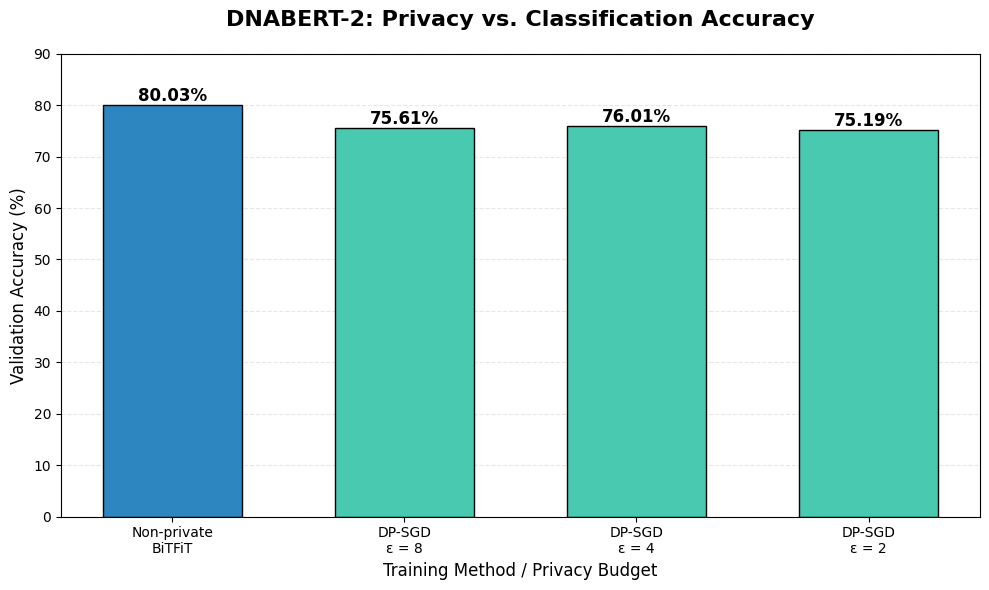

In [ ]:
# DNABERT-2 Privacy-Utility Comparison Chart

import matplotlib.pyplot as plt
import os

# Final RQ1 validation results
methods = [
    "Non-private\nBiTFiT",
    "DP-SGD\nε = 8",
    "DP-SGD\nε = 4",
    "DP-SGD\nε = 2"
]

accuracies = [80.03, 75.61, 76.01, 75.19]

colors = ["#2E86C1", "#48C9B0", "#48C9B0", "#48C9B0"]

# Create chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    methods,
    accuracies,
    color=colors,
    edgecolor="black",
    width=0.6
)

# Display accuracy above each bar
for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{accuracy:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Chart formatting
ax.set_title(
    "DNABERT-2: Privacy vs. Classification Accuracy",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Validation Accuracy (%)", fontsize=12)
ax.set_xlabel("Training Method / Privacy Budget", fontsize=12)

ax.set_ylim(0, 90)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save to Google Drive
save_dir = "/content/drive/MyDrive/DNABERT_DP_Project/results"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(
    save_dir,
    "dnabert_privacy_utility_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
# Cell 28 - Locate and Inspect Saved Checkpoints

import os
import torch
from google.colab import drive

drive.mount("/content/drive")

search_dirs = [
    "/content/dp_dnabert_results",
    "/content/drive/MyDrive/DNABERT_DP_Project"
]

checkpoint_files = []

for root in search_dirs:
    if not os.path.isdir(root):
        continue

    for folder, _, files in os.walk(root):
        for filename in files:
            if filename.endswith((".pt", ".pth", ".ckpt")):
                path = os.path.join(folder, filename)
                checkpoint_files.append(path)

print("SAVED MODEL CHECKPOINTS")
print("-" * 65)

for i, path in enumerate(sorted(set(checkpoint_files)), 1):
    print(f"{i}. {path}")

print("\nCHECKPOINT STRUCTURE")
print("-" * 65)

for path in sorted(set(checkpoint_files)):
    print(f"\n{os.path.basename(path)}")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True,
            mmap=True
        )

        if isinstance(checkpoint, dict):
            keys = list(checkpoint.keys())
            print("First keys:", keys[:8])

            if "model_state_dict" in checkpoint:
                print("Format: training checkpoint")
            elif "state_dict" in checkpoint:
                print("Format: wrapped model state")
            else:
                print("Format: possibly direct model state")

        del checkpoint

    except Exception as e:
        print("Inspection error:", str(e)[:250])

print("\nTotal checkpoint files:", len(set(checkpoint_files)))

Mounted at /content/drive
SAVED MODEL CHECKPOINTS
-----------------------------------------------------------------
1. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp2_best.pt
2. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp2_final.pt
3. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp4_best.pt
4. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp4_final.pt
5. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp8_best.pt
6. /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp8_final.pt

CHECKPOINT STRUCTURE
-----------------------------------------------------------------

dnabert_dp2_best.pt
First keys: ['encoder.embeddings.word_embeddings.weight', 'encoder.embeddings.token_type_embeddings.weight', 'encoder.embeddings.LayerNorm.weight', 'encoder.embeddings.LayerNorm.bias', 'encoder.encoder.layer.0.attention.self.Wqkv.weight', 'encoder.encoder.layer.0.attention.self.Wqkv.bias', 'encoder.encoder.layer.0.attention.output.d

In [ ]:
# Restore test_loader for Cell 29

from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

assert "tokenized_promoter" in globals(), (
    "Run the promoter tokenization cell first."
)

assert "tokenizer" in globals(), (
    "Load the DNABERT-2 tokenizer first."
)

# Use the original held-out test dataset
test_dataset = tokenized_promoter["test"]

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collator
)

print("Test DataLoader restored.")
print("Test sequences:", len(test_loader.dataset))
print("Test batches:", len(test_loader))
print("Classifier ready:", "DNABERTBiTFiTClassifier" in globals())

Test DataLoader restored.
Test sequences: 5920
Test batches: 740
Classifier ready: True


In [ ]:
# Cell 29 - Evaluate Best DP-SGD Checkpoints on Test Dataset

import os
import gc
import json
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)
from transformers import AutoModel

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"
MODEL_ID = "zhihan1996/DNABERT-2-117M"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Confirm required notebook objects exist
assert "DNABERTBiTFiTClassifier" in globals(), (
    "Run the cell defining DNABERTBiTFiTClassifier first."
)
assert "test_loader" in globals(), (
    "Run Cell 12 to recreate the test DataLoader first."
)

def evaluate_checkpoint(epsilon):

    print(f"\n{'=' * 60}")
    print(f"Evaluating DP-SGD ε = {epsilon}")
    print(f"{'=' * 60}")

    checkpoint_path = os.path.join(
        RESULTS_DIR,
        f"dnabert_dp{epsilon}_best.pt"
    )

    # Load pretrained encoder
    encoder = AutoModel.from_pretrained(
        MODEL_ID,
        trust_remote_code=True,
        add_pooling_layer=False
    )

    # Apply existing attention compatibility patch
    for module in encoder.modules():
        if module.__class__.__name__ == "BertUnpadSelfAttention":
            module.p_dropout = 0.1
            if hasattr(module, "dropout"):
                module.dropout.p = 0.1

    # Build classifier
    model = DNABERTBiTFiTClassifier(encoder)

    # Load saved model parameters
    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state_dict, strict=True)
    model = model.to(device)
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.inference_mode():

        for batch in tqdm(
            test_loader,
            desc=f"Testing ε={epsilon}"
        ):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"]

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits if hasattr(outputs, "logits") else outputs
            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            predictions = torch.argmax(logits, dim=-1)

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )
            all_labels.extend(
                labels.cpu().numpy().tolist()
            )

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            all_labels,
            all_predictions,
            average="weighted",
            zero_division=0
        )
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels, all_predictions
    )

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    )

    print("\nClassification Report:")
    print(
        classification_report(
            all_labels,
            all_predictions,
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(cm)

    result = {
        "Method": "DP-SGD BiTFiT",
        "Target Epsilon": epsilon,
        "Test Accuracy": float(accuracy),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1 Score": float(f1),
        "Balanced Accuracy": float(balanced_accuracy)
    }

    # Save confusion matrix
    np.savetxt(
        os.path.join(
            RESULTS_DIR,
            f"confusion_matrix_dp{epsilon}.csv"
        ),
        cm,
        delimiter=",",
        fmt="%d"
    )

    # Free GPU memory
    del model, encoder, state_dict
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# Evaluate all three privacy budgets
test_results = []

for eps in [8, 4, 2]:
    result = evaluate_checkpoint(eps)
    test_results.append(result)

# Create comparison table
test_results_df = pd.DataFrame(test_results)

print("\nFINAL DP-SGD TEST RESULTS")
print("-" * 70)
print(test_results_df.to_string(index=False))

# Save results
save_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dp_test_comparison.csv"
)

test_results_df.to_csv(save_path, index=False)

print(f"\nResults saved to: {save_path}")

Device: cuda

Evaluating DP-SGD ε = 8


Testing ε=8:   0%|          | 0/740 [00:00<?, ?it/s]


Classification Report:
              precision    recall  f1-score   support

           0     0.7636    0.7537    0.7586      2952
           1     0.7582    0.7679    0.7630      2968

    accuracy                         0.7608      5920
   macro avg     0.7609    0.7608    0.7608      5920
weighted avg     0.7608    0.7608    0.7608      5920

Confusion Matrix:
[[2225  727]
 [ 689 2279]]

Evaluating DP-SGD ε = 4


Testing ε=4:   0%|          | 0/740 [00:00<?, ?it/s]


Classification Report:
              precision    recall  f1-score   support

           0     0.7625    0.7622    0.7623      2952
           1     0.7636    0.7638    0.7637      2968

    accuracy                         0.7630      5920
   macro avg     0.7630    0.7630    0.7630      5920
weighted avg     0.7630    0.7630    0.7630      5920

Confusion Matrix:
[[2250  702]
 [ 701 2267]]

Evaluating DP-SGD ε = 2


Testing ε=2:   0%|          | 0/740 [00:00<?, ?it/s]


Classification Report:
              precision    recall  f1-score   support

           0     0.7698    0.7554    0.7625      2952
           1     0.7612    0.7753    0.7682      2968

    accuracy                         0.7654      5920
   macro avg     0.7655    0.7653    0.7653      5920
weighted avg     0.7655    0.7654    0.7653      5920

Confusion Matrix:
[[2230  722]
 [ 667 2301]]

FINAL DP-SGD TEST RESULTS
----------------------------------------------------------------------
       Method  Target Epsilon  Test Accuracy  Precision   Recall  F1 Score  Balanced Accuracy
DP-SGD BiTFiT               8       0.760811   0.760846 0.760811  0.760797           0.760792
DP-SGD BiTFiT               4       0.763007   0.763007 0.763007  0.763007           0.763005
DP-SGD BiTFiT               2       0.765372   0.765451 0.765372  0.765345           0.765345

Results saved to: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dp_test_comparison.csv


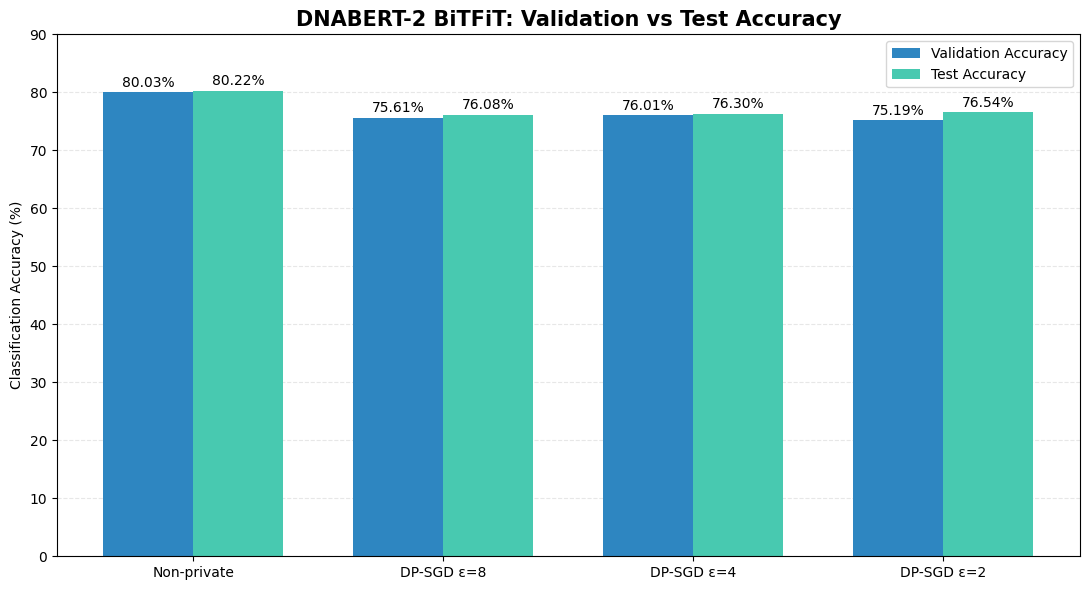

In [ ]:
# Cell 30 - Validation vs Test Accuracy Comparison

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

test_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "dnabert_dp_test_comparison.csv")
)

methods = ["Non-private", "DP-SGD ε=8", "DP-SGD ε=4", "DP-SGD ε=2"]
validation = [80.03]
test = [80.22]  # Previously recorded non-private test accuracy

for eps in [8, 4, 2]:
    with open(
        os.path.join(RESULTS_DIR, f"results_dp{eps}.json")
    ) as f:
        result = json.load(f)

    validation.append(
        result["best_validation_accuracy"] * 100
    )

    row = test_df.loc[test_df["Target Epsilon"] == eps]
    test.append(float(row.iloc[0]["Test Accuracy"]) * 100)

x = np.arange(len(methods))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2, validation, width,
    label="Validation Accuracy", color="#2E86C1"
)
bars2 = ax.bar(
    x + width / 2, test, width,
    label="Test Accuracy", color="#48C9B0"
)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_title(
    "DNABERT-2 BiTFiT: Validation vs Test Accuracy",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Classification Accuracy (%)")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 90)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "dnabert_validation_vs_test.png"
)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
print("Training members available:",
      "train_dataset" in globals())

print("Held-out test dataset available:",
      "test_dataset" in globals())

Training members available: True
Held-out test dataset available: True


In [ ]:
# Cell 31 - Membership Inference Attack (MIA)
# DNABERT-2 BiTFiT | GUE Core Promoter Classification

import os
import gc
import json
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score
)
from transformers import AutoModel, DataCollatorWithPadding

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"
MODEL_ID = "zhihan1996/DNABERT-2-117M"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIA_SAMPLES = 2000
BATCH_SIZE_MIA = 8
SEED = 42

rng = np.random.default_rng(SEED)

assert "train_dataset" in globals(), (
    "Run Cell 12 to recreate the original training split."
)
assert "test_dataset" in globals(), (
    "Restore the original held-out test dataset."
)
assert "DNABERTBiTFiTClassifier" in globals(), (
    "Restore the classifier definition."
)

# --------------------------------------------------
# 2. Select members and non-members
# --------------------------------------------------

n_samples = min(
    MIA_SAMPLES,
    len(train_dataset),
    len(test_dataset)
)

member_indices = rng.choice(
    len(train_dataset),
    size=n_samples,
    replace=False
)

nonmember_indices = rng.choice(
    len(test_dataset),
    size=n_samples,
    replace=False
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

member_loader = DataLoader(
    Subset(train_dataset, member_indices.tolist()),
    batch_size=BATCH_SIZE_MIA,
    shuffle=False,
    collate_fn=collator
)

nonmember_loader = DataLoader(
    Subset(test_dataset, nonmember_indices.tolist()),
    batch_size=BATCH_SIZE_MIA,
    shuffle=False,
    collate_fn=collator
)

print("MIA members:", n_samples)
print("MIA non-members:", n_samples)

# --------------------------------------------------
# 3. Per-example prediction loss
# --------------------------------------------------

def collect_losses(model, loader):

    losses = []

    model.eval()

    with torch.inference_mode():

        for batch in tqdm(loader, leave=False):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits if hasattr(outputs, "logits") else outputs

            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            batch_losses = torch.nn.functional.cross_entropy(
                logits,
                labels,
                reduction="none"
            )

            losses.extend(
                batch_losses.cpu().numpy().tolist()
            )

    return np.array(losses)


# --------------------------------------------------
# 4. Evaluate MIA for each privacy budget
# --------------------------------------------------

mia_results = []
mia_scores = {}

for eps in [8, 4, 2]:

    print(f"\nEvaluating MIA for ε = {eps}")

    encoder = AutoModel.from_pretrained(
        MODEL_ID,
        trust_remote_code=True,
        add_pooling_layer=False
    )

    # DNABERT-2 attention compatibility patch
    for module in encoder.modules():
        if module.__class__.__name__ == "BertUnpadSelfAttention":
            module.p_dropout = 0.1
            if hasattr(module, "dropout"):
                module.dropout.p = 0.1

    model = DNABERTBiTFiTClassifier(
        encoder=encoder,
        num_labels=2
    )

    checkpoint_path = os.path.join(
        RESULTS_DIR,
        f"dnabert_dp{eps}_best.pt"
    )

    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state_dict, strict=True)
    model = model.to(device)

    member_losses = collect_losses(model, member_loader)
    nonmember_losses = collect_losses(model, nonmember_loader)

    # Lower loss suggests membership
    scores = np.concatenate([
        -member_losses,
        -nonmember_losses
    ])

    labels = np.concatenate([
        np.ones(len(member_losses)),
        np.zeros(len(nonmember_losses))
    ])

    auc = roc_auc_score(labels, scores)

    fpr, tpr, thresholds = roc_curve(labels, scores)
    advantage = np.max(tpr - fpr)

    # Use disjoint calibration/evaluation subsets
    # so threshold accuracy isn't measured on the
    # same examples used to choose the threshold.
    split_rng = np.random.default_rng(SEED)
    member_perm = split_rng.permutation(n_samples)
    nonmember_perm = split_rng.permutation(n_samples)

    half = n_samples // 2
    cal_idx = np.concatenate([
        member_perm[:half],
        n_samples + nonmember_perm[:half]
    ])
    eval_idx = np.concatenate([
        member_perm[half:],
        n_samples + nonmember_perm[half:]
    ])

    cal_fpr, cal_tpr, cal_thresholds = roc_curve(
        labels[cal_idx],
        scores[cal_idx]
    )

    finite = np.isfinite(cal_thresholds)
    best_index = np.argmax(
        np.where(finite, cal_tpr - cal_fpr, -np.inf)
    )
    best_threshold = cal_thresholds[best_index]

    attack_predictions = (
        scores[eval_idx] >= best_threshold
    ).astype(int)

    attack_accuracy = accuracy_score(
        labels[eval_idx],
        attack_predictions
    )

    print(f"MIA ROC-AUC: {auc:.4f}")
    print(f"Attack advantage: {advantage:.4f}")
    print(f"Attack accuracy: {attack_accuracy:.4f}")

    mia_results.append({
        "Method": "DP-SGD BiTFiT",
        "Target Epsilon": eps,
        "MIA ROC-AUC": float(auc),
        "Attack Advantage": float(advantage),
        "Attack Accuracy": float(attack_accuracy)
    })

    mia_scores[eps] = {
        "labels": labels.tolist(),
        "scores": scores.tolist()
    }

    del model, encoder, state_dict
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

mia_df = pd.DataFrame(mia_results)

print("\nFINAL MEMBERSHIP INFERENCE RESULTS")
print("-" * 70)
print(mia_df.to_string(index=False))

mia_df.to_csv(
    os.path.join(RESULTS_DIR, "dnabert_mia_results.csv"),
    index=False
)

with open(
    os.path.join(RESULTS_DIR, "dnabert_mia_scores.json"),
    "w"
) as f:
    json.dump(mia_scores, f)



MIA members: 2000
MIA non-members: 2000

Evaluating MIA for ε = 8


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

MIA ROC-AUC: 0.5074
Attack advantage: 0.0180
Attack accuracy: 0.4935

Evaluating MIA for ε = 4


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

MIA ROC-AUC: 0.5056
Attack advantage: 0.0295
Attack accuracy: 0.5155

Evaluating MIA for ε = 2


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

MIA ROC-AUC: 0.5066
Attack advantage: 0.0195
Attack accuracy: 0.5075

FINAL MEMBERSHIP INFERENCE RESULTS
----------------------------------------------------------------------
       Method  Target Epsilon  MIA ROC-AUC  Attack Advantage  Attack Accuracy
DP-SGD BiTFiT               8     0.507415            0.0180           0.4935
DP-SGD BiTFiT               4     0.505560            0.0295           0.5155
DP-SGD BiTFiT               2     0.506602            0.0195           0.5075


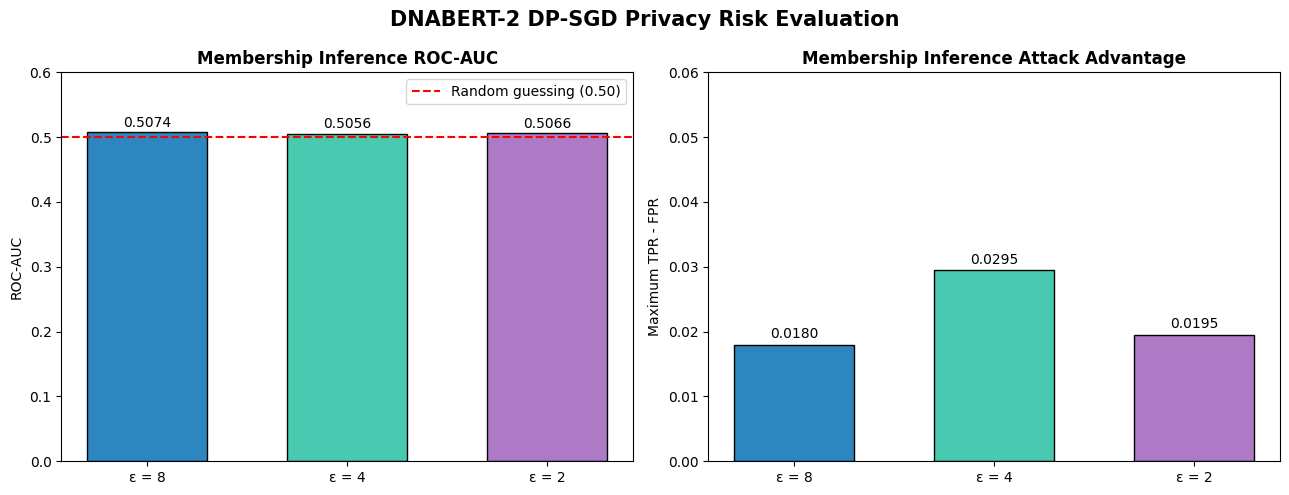

In [ ]:
# Cell 32 - Membership Inference Attack Comparison Charts

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

mia_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "dnabert_mia_results.csv")
)

# Consistent order
mia_df = (
    mia_df.set_index("Target Epsilon")
    .loc[[8, 4, 2]]
    .reset_index()
)

labels = [f"ε = {int(e)}" for e in mia_df["Target Epsilon"]]
colors = ["#2E86C1", "#48C9B0", "#AF7AC5"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: MIA ROC-AUC
bars1 = axes[0].bar(
    labels,
    mia_df["MIA ROC-AUC"],
    color=colors,
    edgecolor="black",
    width=0.6
)

axes[0].axhline(
    0.5,
    color="red",
    linestyle="--",
    label="Random guessing (0.50)"
)

axes[0].set_title("Membership Inference ROC-AUC", fontweight="bold")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0, 0.6)
axes[0].legend()

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{bar.get_height():.4f}",
        ha="center",
        fontsize=10
    )

# Chart 2: Attack advantage
bars2 = axes[1].bar(
    labels,
    mia_df["Attack Advantage"],
    color=colors,
    edgecolor="black",
    width=0.6
)

axes[1].set_title("Membership Inference Attack Advantage",
                  fontweight="bold")
axes[1].set_ylabel("Maximum TPR - FPR")
axes[1].set_ylim(0, 0.06)

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.001,
        f"{bar.get_height():.4f}",
        ha="center",
        fontsize=10
    )

plt.suptitle(
    "DNABERT-2 DP-SGD Privacy Risk Evaluation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR,
    "dnabert_mia_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
# Cell 33 - Check Non-Private Baseline Prerequisites

import torch
import os

required_objects = [
    "DNABERTBiTFiTClassifier",
    "train_loader",
    "eval_loader",
    "test_loader",
    "tokenizer",
    "train_dataset",
    "val_dataset"
]

print("NON-PRIVATE BASELINE READINESS")
print("-" * 55)

for name in required_objects:
    status = "READY" if name in globals() else "MISSING"
    print(f"{name:30s} {status}")

print("\nGPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Not available")

if "train_dataset" in globals():
    print("Training sequences:", len(train_dataset))

if "val_dataset" in globals():
    print("Validation sequences:", len(val_dataset))

if "test_loader" in globals():
    print("Test sequences:", len(test_loader.dataset))

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

print("\nExisting baseline checkpoints:")
if os.path.isdir(RESULTS_DIR):
    for filename in os.listdir(RESULTS_DIR):
        if "baseline" in filename.lower() or "nonprivate" in filename.lower():
            print(" ", filename)

NON-PRIVATE BASELINE READINESS
-------------------------------------------------------
DNABERTBiTFiTClassifier        READY
train_loader                   READY
eval_loader                    READY
test_loader                    READY
tokenizer                      READY
train_dataset                  READY
val_dataset                    READY

GPU: Tesla T4
Training sequences: 42620
Validation sequences: 4736
Test sequences: 5920

Existing baseline checkpoints:


In [ ]:
# Cell 34 - Train and Save Non-Private BiTFiT Baseline

import os
import gc
import json
import time
import random
import copy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from transformers import AutoModel
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"
RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

SEED = 42
EPOCHS = 3
LEARNING_RATE = 2e-4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", device)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

# --------------------------------------------------
# 2. Fresh pretrained encoder
# --------------------------------------------------

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Apply DNABERT-2 attention compatibility patch
for module in encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

# Build original BiTFiT classifier
baseline_model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=2
).to(device)

# --------------------------------------------------
# 3. Optimizer and loss
# --------------------------------------------------

trainable_parameters = [
    p for p in baseline_model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss()

print(
    "Trainable parameters:",
    sum(p.numel() for p in trainable_parameters)
)

# --------------------------------------------------
# 4. Training
# --------------------------------------------------

history = []
best_accuracy = -1.0
best_epoch = None

best_checkpoint_path = os.path.join(
    RESULTS_DIR,
    "dnabert_nonprivate_best.pt"
)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    baseline_model.train()

    total_train_loss = 0.0
    total_train_examples = 0

    for batch in tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS} Training"
    ):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = (
            outputs.logits
            if hasattr(outputs, "logits")
            else outputs
        )

        if isinstance(logits, (tuple, list)):
            logits = logits[0]

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_train_loss += loss.item() * batch_size
        total_train_examples += batch_size

    avg_train_loss = (
        total_train_loss / total_train_examples
    )

    # ----------------------------------------------
    # Validation
    # ----------------------------------------------

    baseline_model.eval()

    val_losses = []
    val_predictions = []
    val_labels = []

    with torch.inference_mode():

        for batch in tqdm(
            eval_loader,
            desc=f"Epoch {epoch}/{EPOCHS} Validation"
        ):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = baseline_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = (
                outputs.logits
                if hasattr(outputs, "logits")
                else outputs
            )

            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            loss = criterion(logits, labels)

            val_losses.append(
                (loss.item(), labels.size(0))
            )

            predictions = torch.argmax(
                logits, dim=-1
            )

            val_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            val_labels.extend(
                labels.cpu().numpy().tolist()
            )

    avg_val_loss = (
        sum(loss * n for loss, n in val_losses)
        / sum(n for _, n in val_losses)
    )

    val_accuracy = accuracy_score(
        val_labels, val_predictions
    )

    elapsed = (time.time() - start_time) / 60

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
        f" | Train Loss: {avg_train_loss:.4f}"
        f" | Val Loss: {avg_val_loss:.4f}"
        f" | Val Accuracy: {val_accuracy:.4f}"
        f" | Time: {elapsed:.1f} min"
    )

    history.append({
        "epoch": epoch,
        "train_loss": float(avg_train_loss),
        "val_loss": float(avg_val_loss),
        "val_accuracy": float(val_accuracy),
        "elapsed_minutes": float(elapsed)
    })

    # Save best checkpoint
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_epoch = epoch

        state_dict = {
            key: value.detach().cpu().clone()
            for key, value in baseline_model.state_dict().items()
        }

        torch.save(
            state_dict,
            best_checkpoint_path
        )

        del state_dict

        print("Best checkpoint saved to Google Drive.")

# --------------------------------------------------
# 5. Save final model and results
# --------------------------------------------------

final_checkpoint_path = os.path.join(
    RESULTS_DIR,
    "dnabert_nonprivate_final.pt"
)

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in baseline_model.state_dict().items()
    },
    final_checkpoint_path
)

results = {
    "method": "Non-private BiTFiT",
    "model": MODEL_ID,
    "dataset": "GUE prom_core_all",
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "best_epoch": best_epoch,
    "best_validation_accuracy": float(best_accuracy),
    "total_runtime_minutes": (
        time.time() - start_time
    ) / 60
}

with open(
    os.path.join(
        RESULTS_DIR,
        "results_nonprivate.json"
    ),
    "w"
) as f:
    json.dump(results, f, indent=2)

pd.DataFrame(history).to_csv(
    os.path.join(
        RESULTS_DIR,
        "history_nonprivate.csv"
    ),
    index=False
)

print("\nNON-PRIVATE BASELINE COMPLETE")
print("-" * 60)
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_accuracy:.4%}")
print(f"Total runtime: {results['total_runtime_minutes']:.1f} min")
print(f"Checkpoints saved to: {RESULTS_DIR}")

# Release GPU memory
del baseline_model, encoder, optimizer
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Device: cuda
Epochs: 3
Learning rate: 0.0002
Trainable parameters: 66818


Epoch 1/3 Training:   0%|          | 0/5328 [00:00<?, ?it/s]

Epoch 1/3 Validation:   0%|          | 0/592 [00:00<?, ?it/s]


Epoch 1/3 | Train Loss: 0.4817 | Val Loss: 0.4260 | Val Accuracy: 0.7990 | Time: 4.2 min
Best checkpoint saved to Google Drive.


Epoch 2/3 Training:   0%|          | 0/5328 [00:00<?, ?it/s]

Epoch 2/3 Validation:   0%|          | 0/592 [00:00<?, ?it/s]


Epoch 2/3 | Train Loss: 0.4430 | Val Loss: 0.4262 | Val Accuracy: 0.7937 | Time: 8.5 min


Epoch 3/3 Training:   0%|          | 0/5328 [00:00<?, ?it/s]

Epoch 3/3 Validation:   0%|          | 0/592 [00:00<?, ?it/s]


Epoch 3/3 | Train Loss: 0.4859 | Val Loss: 0.4295 | Val Accuracy: 0.8051 | Time: 12.7 min
Best checkpoint saved to Google Drive.

NON-PRIVATE BASELINE COMPLETE
------------------------------------------------------------
Best epoch: 3
Best validation accuracy: 80.5110%
Total runtime: 12.9 min
Checkpoints saved to: /content/drive/MyDrive/DNABERT_DP_Project/results


In [ ]:
# Cell 35 - Non-Private Test Evaluation and MIA

import os
import gc
import json
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
from transformers import AutoModel, DataCollatorWithPadding
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"
MODEL_ID = "zhihan1996/DNABERT-2-117M"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "DNABERTBiTFiTClassifier" in globals()
assert "train_dataset" in globals()
assert "test_dataset" in globals()
assert "test_loader" in globals()
assert "tokenizer" in globals()

# --------------------------------------------------
# 1. Load the saved non-private baseline
# --------------------------------------------------

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=2
)

checkpoint = torch.load(
    os.path.join(RESULTS_DIR, "dnabert_nonprivate_best.pt"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint, strict=True)
model = model.to(device)
model.eval()

print("Non-private baseline loaded.")

def get_logits(model, batch):
    outputs = model(
        input_ids=batch["input_ids"].to(device),
        attention_mask=batch["attention_mask"].to(device)
    )
    logits = outputs.logits if hasattr(outputs, "logits") else outputs
    if isinstance(logits, (tuple, list)):
        logits = logits[0]
    return logits

# --------------------------------------------------
# 2. Held-out test evaluation
# --------------------------------------------------

all_labels = []
all_predictions = []

with torch.inference_mode():
    for batch in tqdm(test_loader, desc="Non-private test"):
        logits = get_logits(model, batch)
        predictions = logits.argmax(dim=-1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(batch["labels"].cpu().tolist())

accuracy = accuracy_score(all_labels, all_predictions)
balanced_acc = balanced_accuracy_score(
    all_labels, all_predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("\nNON-PRIVATE TEST RESULTS")
print("-" * 60)
print(classification_report(
    all_labels, all_predictions, digits=4, zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(all_labels, all_predictions, labels=[0, 1]))

test_result = {
    "Method": "Non-private BiTFiT",
    "Test Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1 Score": float(f1),
    "Balanced Accuracy": float(balanced_acc)
}

with open(
    os.path.join(RESULTS_DIR, "results_nonprivate_test.json"),
    "w"
) as f:
    json.dump(test_result, f, indent=2)

# --------------------------------------------------
# 3. Reproduce Cell 31's MIA sample selection
# --------------------------------------------------

MIA_SAMPLES = 2000
SEED = 42

rng = np.random.default_rng(SEED)

member_indices = rng.choice(
    len(train_dataset),
    size=MIA_SAMPLES,
    replace=False
)

nonmember_indices = rng.choice(
    len(test_dataset),
    size=MIA_SAMPLES,
    replace=False
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

member_loader = DataLoader(
    Subset(train_dataset, member_indices.tolist()),
    batch_size=8,
    shuffle=False,
    collate_fn=collator
)

nonmember_loader = DataLoader(
    Subset(test_dataset, nonmember_indices.tolist()),
    batch_size=8,
    shuffle=False,
    collate_fn=collator
)

def collect_losses(loader):
    losses = []
    model.eval()

    with torch.inference_mode():
        for batch in tqdm(loader, leave=False):
            logits = get_logits(model, batch)

            batch_losses = torch.nn.functional.cross_entropy(
                logits,
                batch["labels"].to(device),
                reduction="none"
            )

            losses.extend(batch_losses.cpu().tolist())

    return np.asarray(losses)

print("\nCollecting non-private MIA losses...")

member_losses = collect_losses(member_loader)
nonmember_losses = collect_losses(nonmember_loader)

# Lower loss implies greater likelihood of membership
scores = np.concatenate([
    -member_losses,
    -nonmember_losses
])

labels = np.concatenate([
    np.ones(MIA_SAMPLES, dtype=int),
    np.zeros(MIA_SAMPLES, dtype=int)
])

# --------------------------------------------------
# 4. Membership inference metrics
# --------------------------------------------------

auc = roc_auc_score(labels, scores)

fpr, tpr, _ = roc_curve(labels, scores)
advantage = float(np.max(tpr - fpr))

# Same calibration/evaluation split as Cell 31
split_rng = np.random.default_rng(SEED)

member_perm = split_rng.permutation(MIA_SAMPLES)
nonmember_perm = split_rng.permutation(MIA_SAMPLES)

half = MIA_SAMPLES // 2

cal_idx = np.concatenate([
    member_perm[:half],
    MIA_SAMPLES + nonmember_perm[:half]
])

eval_idx = np.concatenate([
    member_perm[half:],
    MIA_SAMPLES + nonmember_perm[half:]
])

cal_fpr, cal_tpr, cal_thresholds = roc_curve(
    labels[cal_idx],
    scores[cal_idx]
)

finite = np.isfinite(cal_thresholds)

best_index = np.argmax(
    np.where(finite, cal_tpr - cal_fpr, -np.inf)
)

threshold = cal_thresholds[best_index]

attack_predictions = (
    scores[eval_idx] >= threshold
).astype(int)

attack_accuracy = accuracy_score(
    labels[eval_idx],
    attack_predictions
)

baseline_mia = {
    "Method": "Non-private BiTFiT",
    "Target Epsilon": np.nan,
    "MIA ROC-AUC": float(auc),
    "Attack Advantage": advantage,
    "Attack Accuracy": float(attack_accuracy)
}

print("\nNON-PRIVATE MIA RESULTS")
print("-" * 60)
print(f"MIA ROC-AUC: {auc:.4f}")
print(f"Attack advantage: {advantage:.4f}")
print(f"Attack accuracy: {attack_accuracy:.4f}")

# --------------------------------------------------
# 5. Combine with existing DP-SGD MIA results
# --------------------------------------------------

dp_mia = pd.read_csv(
    os.path.join(RESULTS_DIR, "dnabert_mia_results.csv")
)

comparison = pd.concat(
    [pd.DataFrame([baseline_mia]), dp_mia],
    ignore_index=True
)

comparison_path = os.path.join(
    RESULTS_DIR,
    "dnabert_mia_full_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

# Save baseline attack scores for reproducibility
with open(
    os.path.join(RESULTS_DIR, "dnabert_nonprivate_mia_scores.json"),
    "w"
) as f:
    json.dump({
        "labels": labels.tolist(),
        "scores": scores.tolist(),
        "member_indices": member_indices.tolist(),
        "nonmember_indices": nonmember_indices.tolist()
    }, f)

print("\nFINAL MIA COMPARISON")
print("-" * 75)
print(comparison.to_string(index=False))



# Free GPU memory
del model, encoder, checkpoint
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Non-private baseline loaded.


Non-private test:   0%|          | 0/740 [00:00<?, ?it/s]


NON-PRIVATE TEST RESULTS
------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.8139    0.7835    0.7984      2952
           1     0.7924    0.8218    0.8068      2968

    accuracy                         0.8027      5920
   macro avg     0.8031    0.8027    0.8026      5920
weighted avg     0.8031    0.8027    0.8026      5920

Confusion matrix:
[[2313  639]
 [ 529 2439]]



  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]


NON-PRIVATE MIA RESULTS
------------------------------------------------------------
MIA ROC-AUC: 0.4988
Attack advantage: 0.0275
Attack accuracy: 0.5060

FINAL MIA COMPARISON
---------------------------------------------------------------------------
            Method  Target Epsilon  MIA ROC-AUC  Attack Advantage  Attack Accuracy
Non-private BiTFiT             NaN     0.498821            0.0275           0.5060
     DP-SGD BiTFiT             8.0     0.507415            0.0180           0.4935
     DP-SGD BiTFiT             4.0     0.505560            0.0295           0.5155
     DP-SGD BiTFiT             2.0     0.506602            0.0195           0.5075


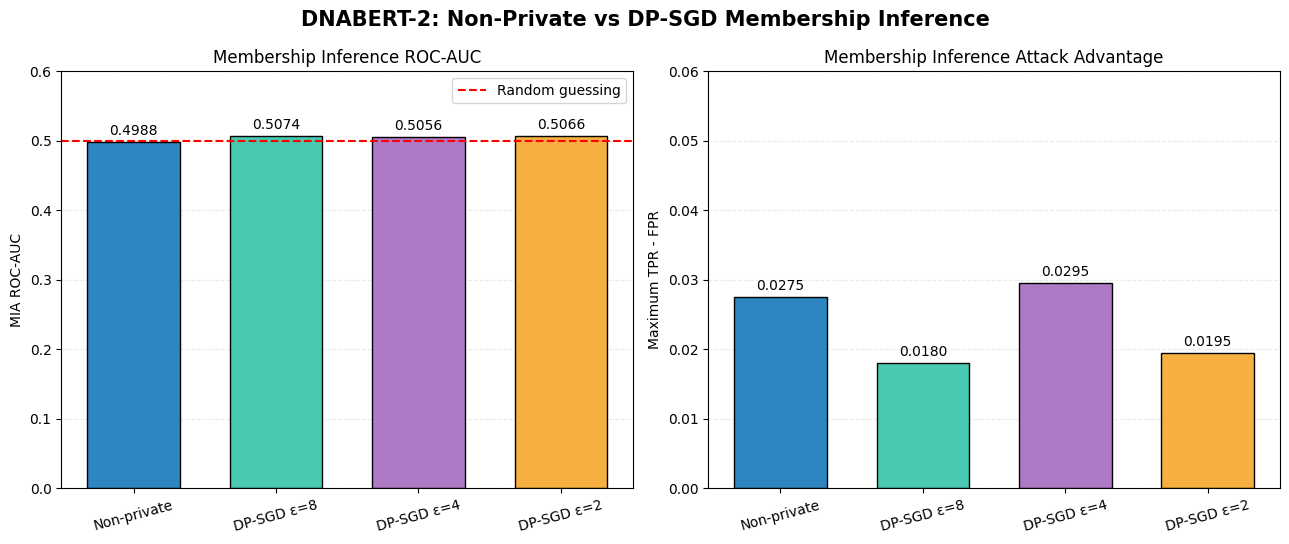

In [ ]:
# Cell 36 - Non-Private vs DP-SGD Privacy Risk Comparison

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

df = pd.read_csv(
    os.path.join(RESULTS_DIR, "dnabert_mia_full_comparison.csv")
)

labels = ["Non-private", "DP-SGD ε=8", "DP-SGD ε=4", "DP-SGD ε=2"]
colors = ["#2E86C1", "#48C9B0", "#AF7AC5", "#F5B041"]

# Ensure correct ordering
baseline = df[df["Method"] == "Non-private BiTFiT"]
private = df[df["Method"] != "Non-private BiTFiT"]
private = private.set_index("Target Epsilon").loc[[8, 4, 2]]

plot_df = pd.concat([baseline, private.reset_index()], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ROC-AUC chart
bars = axes[0].bar(
    labels, plot_df["MIA ROC-AUC"],
    color=colors, edgecolor="black", width=0.65
)

axes[0].axhline(
    0.5, color="red", linestyle="--",
    label="Random guessing"
)
axes[0].set_ylim(0, 0.60)
axes[0].set_ylabel("MIA ROC-AUC")
axes[0].set_title("Membership Inference ROC-AUC")
axes[0].legend()

for bar in bars:
    axes[0].annotate(
        f"{bar.get_height():.4f}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points",
        ha="center", fontsize=10
    )

# Attack advantage chart
bars = axes[1].bar(
    labels, plot_df["Attack Advantage"],
    color=colors, edgecolor="black", width=0.65
)

axes[1].set_ylim(0, 0.06)
axes[1].set_ylabel("Maximum TPR - FPR")
axes[1].set_title("Membership Inference Attack Advantage")

for bar in bars:
    axes[1].annotate(
        f"{bar.get_height():.4f}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points",
        ha="center", fontsize=10
    )

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "DNABERT-2: Non-Private vs DP-SGD Membership Inference",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "dnabert_full_mia_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
# Cell 37 - Explore GUE Splice Site Dataset

import numpy as np
import pandas as pd

from datasets import load_dataset, get_dataset_config_names

DATASET_ID = "leannmlindsey/GUE"

# --------------------------------------------------
# 1. Identify available splice site configurations
# --------------------------------------------------

configs = get_dataset_config_names(DATASET_ID)

splice_configs = [
    name for name in configs
    if "splice" in name.lower()
]

print("AVAILABLE SPLICE SITE CONFIGURATIONS")
print("-" * 60)

for name in splice_configs:
    print(name)

if not splice_configs:
    raise ValueError(
        "No splice site configuration found. "
        "Review the available GUE configurations."
    )

# --------------------------------------------------
# 2. Load splice site dataset
# --------------------------------------------------

# Select automatically only if there is one match.
# Otherwise, inspect the configurations before choosing.
if len(splice_configs) == 1:
    SPLICE_CONFIG = splice_configs[0]
else:
    print("\nMultiple configurations found.")
    print("Inspect the names above before selecting one.")
    SPLICE_CONFIG = None

if SPLICE_CONFIG is not None:

    splice = load_dataset(
        DATASET_ID,
        SPLICE_CONFIG
    )

    print("\nSELECTED DATASET:", SPLICE_CONFIG)

    # --------------------------------------------------
    # 3. Inspect splits and label distributions
    # --------------------------------------------------

    print("\nDATASET STRUCTURE")
    print("-" * 60)
    print(splice)

    for split_name, dataset in splice.items():

        print(f"\nSPLIT: {split_name}")
        print("Examples:", len(dataset))
        print("Columns:", dataset.column_names)

        if "label" in dataset.column_names:
            labels = pd.Series(dataset["label"])

            print("\nClass distribution:")
            print(labels.value_counts().sort_index())

            print("\nClass percentages:")
            print(
                (labels.value_counts(normalize=True)
                 .sort_index() * 100).round(2)
            )

        if "sequence" in dataset.column_names:
            lengths = np.array([
                len(sequence)
                for sequence in dataset["sequence"]
            ])

            print("\nSequence lengths:")
            print("Minimum:", lengths.min())
            print("Median:", np.median(lengths))
            print("Maximum:", lengths.max())

    # --------------------------------------------------
    # 4. Display sample records
    # --------------------------------------------------

    print("\nSAMPLE RECORDS")
    print("-" * 60)

    sample_split = (
        "train" if "train" in splice
        else list(splice.keys())[0]
    )

    for i in range(min(3, len(splice[sample_split]))):
        record = splice[sample_split][i]

        print(f"\nSample {i + 1}")
        print("Label:", record.get("label"))
        print("Sequence:", str(record.get("sequence"))[:150])

print("\nCell 37 complete.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


AVAILABLE SPLICE SITE CONFIGURATIONS
------------------------------------------------------------
splice_reconstructed

SELECTED DATASET: splice_reconstructed

DATASET STRUCTURE
------------------------------------------------------------
DatasetDict({
    train: Dataset({
        features: ['sequence', 'label'],
        num_rows: 36496
    })
    test: Dataset({
        features: ['sequence', 'label'],
        num_rows: 4562
    })
    dev: Dataset({
        features: ['sequence', 'label'],
        num_rows: 4562
    })
})

SPLIT: train
Examples: 36496
Columns: ['sequence', 'label']

Class distribution:
0     8043
1     7988
2    20465
Name: count, dtype: int64

Class percentages:
0    22.04
1    21.89
2    56.07
Name: proportion, dtype: float64

Sequence lengths:
Minimum: 400
Median: 400.0
Maximum: 400

SPLIT: test
Examples: 4562
Columns: ['sequence', 'label']

Class distribution:
0     956
1    1025
2    2581
Name: count, dtype: int64

Class percentages:
0    20.96
1    22.47
2    5

In [ ]:
# Cell 38 - Tokenize and Prepare GUE Splice Site Dataset

import numpy as np
import torch
from collections import Counter
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL_ID = "zhihan1996/DNABERT-2-117M"
SPLICE_MAX_LENGTH = 128
SPLICE_BATCH_SIZE = 8

assert "splice" in globals(), "Run Cell 37 first."

# --------------------------------------------------
# 1. Load tokenizer
# --------------------------------------------------

splice_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    use_fast=True
)

# --------------------------------------------------
# 2. Check token lengths before truncation
# --------------------------------------------------

sample_size = min(1000, len(splice["train"]))

sample_sequences = splice["train"]["sequence"][:sample_size]

lengths = [
    len(splice_tokenizer(
        sequence,
        add_special_tokens=True,
        truncation=False
    )["input_ids"])
    for sequence in sample_sequences
]

lengths = np.asarray(lengths)

print("TOKEN LENGTH DIAGNOSTIC")
print("-" * 60)
print("Sampled sequences:", len(lengths))
print("Minimum tokens:", int(lengths.min()))
print("Median tokens:", float(np.median(lengths)))
print("Maximum tokens:", int(lengths.max()))
print(
    "Percent exceeding 128 tokens:",
    f"{100 * np.mean(lengths > 128):.2f}%"
)

# --------------------------------------------------
# 3. Tokenization function
# --------------------------------------------------

def tokenize_splice_batch(batch):
    encoded = splice_tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=SPLICE_MAX_LENGTH
    )

    encoded["labels"] = batch["label"]

    return encoded

splice_tokenized = splice.map(
    tokenize_splice_batch,
    batched=True,
    remove_columns=["sequence", "label"],
    desc="Tokenizing splice site dataset"
)

# --------------------------------------------------
# 4. Use official train/dev/test splits
# --------------------------------------------------

splice_train_dataset = splice_tokenized["train"]
splice_val_dataset = splice_tokenized["dev"]
splice_test_dataset = splice_tokenized["test"]

splice_collator = DataCollatorWithPadding(
    tokenizer=splice_tokenizer,
    padding=True,
    return_tensors="pt"
)

splice_train_loader = DataLoader(
    splice_train_dataset,
    batch_size=SPLICE_BATCH_SIZE,
    shuffle=True,
    collate_fn=splice_collator
)

splice_eval_loader = DataLoader(
    splice_val_dataset,
    batch_size=SPLICE_BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

splice_test_loader = DataLoader(
    splice_test_dataset,
    batch_size=SPLICE_BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

# --------------------------------------------------
# 5. Verify data and labels
# --------------------------------------------------

print("\nSPLICE DATASET READY")
print("-" * 60)
print("Training examples:", len(splice_train_dataset))
print("Validation examples:", len(splice_val_dataset))
print("Test examples:", len(splice_test_dataset))

print("\nTraining label distribution:")
print(Counter(splice_train_dataset["labels"]))

sample_batch = next(iter(splice_train_loader))

print("\nSample batch shapes:")
for key, value in sample_batch.items():
    print(f"{key}: {tuple(value.shape)}")

print("\nNumber of classes:", len(set(splice_train_dataset["labels"])))
print("Maximum sequence length:", SPLICE_MAX_LENGTH)

AssertionError: Run Cell 37 first.

In [ ]:
# Restore compatible DNABERT-2 package versions

%pip install -q --force-reinstall --no-deps \
    "transformers==4.49.0" \
    "tokenizers==0.21.4" \
    "huggingface-hub==0.36.2"

import transformers
print("Installed Transformers:", transformers.__version__)

Installed Transformers: 5.22.1


In [ ]:
# Cell 39A - Check Splice Site Training Readiness

import os
import torch
import transformers

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

# 1. Check required objects
required = [
    "DNABERTBiTFiTClassifier",
    "splice",
    "splice_tokenizer",
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_test_dataset",
    "splice_train_loader",
    "splice_eval_loader",
    "splice_test_loader"
]

print("SPLICE TRAINING READINESS")
print("-" * 60)

all_ready = True

for name in required:
    ready = name in globals()
    status = "READY" if ready else "MISSING"
    print(f"{name:32s} {status}")

    if not ready:
        all_ready = False

# 2. Check environment
print("\nENVIRONMENT")
print("-" * 60)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Available GPU memory:",
        f"{torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB"
    )
else:
    print("GPU: NOT AVAILABLE")
    all_ready = False

if transformers.__version__ != "4.49.0":
    print("WARNING: Expected Transformers 4.49.0")
    all_ready = False

# 3. Check dataset sizes
print("\nDATASET")
print("-" * 60)

if "splice_train_dataset" in globals():
    print("Training examples:", len(splice_train_dataset))

if "splice_val_dataset" in globals():
    print("Validation examples:", len(splice_val_dataset))

if "splice_test_dataset" in globals():
    print("Test examples:", len(splice_test_dataset))

# 4. Check Google Drive and checkpoints
print("\nSAVED SPLICE CHECKPOINTS")
print("-" * 60)

best_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

final_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_final.pt"
)

if not os.path.isdir(RESULTS_DIR):
    print("Results directory not found!")
    all_ready = False
else:
    for path in [best_path, final_path]:
        if os.path.isfile(path):
            size_mb = os.path.getsize(path) / (1024**2)
            print(
                f"FOUND: {os.path.basename(path)} "
                f"({size_mb:.1f} MB)"
            )
        else:
            print(f"NOT FOUND: {os.path.basename(path)}")

# 5. Final readiness status
print("\nFINAL STATUS")
print("-" * 60)

if all_ready:
    print("READY FOR CELL 39")
    print("Review existing checkpoints before training.")
else:
    print("NOT READY - Resolve missing items before Cell 39.")

SPLICE TRAINING READINESS
------------------------------------------------------------
DNABERTBiTFiTClassifier          READY
splice                           READY
splice_tokenizer                 READY
splice_train_dataset             READY
splice_val_dataset               READY
splice_test_dataset              READY
splice_train_loader              READY
splice_eval_loader               READY
splice_test_loader               READY

ENVIRONMENT
------------------------------------------------------------
PyTorch: 2.14.1+cu130
Transformers: 4.49.0
GPU: Tesla T4
Available GPU memory: 14.46 GB

DATASET
------------------------------------------------------------
Training examples: 36496
Validation examples: 4562
Test examples: 4562

SAVED SPLICE CHECKPOINTS
------------------------------------------------------------
FOUND: dnabert_splice_nonprivate_best.pt (444.4 MB)
NOT FOUND: dnabert_splice_nonprivate_final.pt

FINAL STATUS
------------------------------------------------------------

In [ ]:
# Inspect Cell 39B saved splice baseline checkpoint

import os
import torch

path = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results/"
    "dnabert_splice_nonprivate_best.pt"
)

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint exists:", os.path.isfile(path))
print("Number of saved tensors:", len(checkpoint))
print("First five parameter names:")

for name in list(checkpoint.keys())[:5]:
    print(" ", name)

print("\nClassifier weights:")
for name, value in checkpoint.items():
    if name.startswith("classifier."):
        print(name, tuple(value.shape))

del checkpoint

Checkpoint exists: True
Number of saved tensors: 138
First five parameter names:
  encoder.embeddings.word_embeddings.weight
  encoder.embeddings.token_type_embeddings.weight
  encoder.embeddings.LayerNorm.weight
  encoder.embeddings.LayerNorm.bias
  encoder.encoder.layer.0.attention.self.Wqkv.weight

Classifier weights:
classifier.weight (3, 768)
classifier.bias (3,)


In [ ]:
# Cell 39C - Evaluate Saved Non-Private Splice Baseline

import os
import json
import gc
import torch
import numpy as np

from transformers import AutoModel
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

MODEL_ID = "zhihan1996/DNABERT-2-117M"
RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

assert "4.49.0" == __import__("transformers").__version__, (
    "Restore Transformers 4.49.0 before continuing."
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load encoder
splice_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Apply DNABERT-2 attention compatibility patch
for module in splice_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

# Create 3-class classifier
splice_model = DNABERTBiTFiTClassifier(
    encoder=splice_encoder,
    num_labels=3
)

# Load saved weights
checkpoint_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

splice_model.load_state_dict(state_dict, strict=True)
splice_model = splice_model.to(device)
splice_model.eval()

print("Saved splice baseline loaded successfully.")

def evaluate_splice(loader, name):
    predictions = []
    labels = []

    with torch.inference_mode():
        for batch in tqdm(loader, desc=name):
            outputs = splice_model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device)
            )

            logits = (
                outputs.logits
                if hasattr(outputs, "logits")
                else outputs
            )

            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            predictions.extend(
                logits.argmax(dim=-1).cpu().tolist()
            )
            labels.extend(batch["labels"].cpu().tolist())

    metrics = {
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(
            balanced_accuracy_score(labels, predictions)
        ),
        "macro_f1": float(
            f1_score(labels, predictions, average="macro")
        )
    }

    print(f"\n{name.upper()} RESULTS")
    print("-" * 60)
    print(classification_report(
        labels, predictions, digits=4, zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(labels, predictions, labels=[0, 1, 2]))

    return metrics

validation_results = evaluate_splice(
    splice_eval_loader, "Validation"
)

test_results = evaluate_splice(
    splice_test_loader, "Test"
)

results = {
    "method": "Non-private BiTFiT",
    "dataset": "GUE splice_reconstructed",
    "checkpoint": "dnabert_splice_nonprivate_best.pt",
    "validation": validation_results,
    "test": test_results
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_checkpoint_evaluation.json"
)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nSUMMARY")
print("-" * 60)
print(
    f"Validation accuracy: "
    f"{validation_results['accuracy']:.4%}"
)
print(
    f"Test accuracy: "
    f"{test_results['accuracy']:.4%}"
)
print(
    f"Test macro F1: "
    f"{test_results['macro_f1']:.4f}"
)
print(
    f"Test balanced accuracy: "
    f"{test_results['balanced_accuracy']:.4f}"
)
print("\nResults saved:", output_path)

# Free GPU memory
del splice_model, splice_encoder, state_dict
gc.collect()
torch.cuda.empty_cache()

bert_layers.py: 0.00B [00:00, ?B/s]

flash_attn_triton.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_layers.py
- flash_attn_triton.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

... (2 outputs left out)

Validation:   0%|          | 0/571 [00:00<?, ?it/s]


VALIDATION RESULTS
------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      1001
           1     0.0000    0.0000    0.0000       987
           2     0.5642    1.0000    0.7214      2574

    accuracy                         0.5642      4562
   macro avg     0.1881    0.3333    0.2405      4562
weighted avg     0.3184    0.5642    0.4070      4562

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]


Test:   0%|          | 0/571 [00:00<?, ?it/s]


TEST RESULTS
------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000       956
           1     0.0000    0.0000    0.0000      1025
           2     0.5658    1.0000    0.7227      2581

    accuracy                         0.5658      4562
   macro avg     0.1886    0.3333    0.2409      4562
weighted avg     0.3201    0.5658    0.4089      4562

Confusion matrix:
[[   0    0  956]
 [   0    0 1025]
 [   0    0 2581]]

SUMMARY
------------------------------------------------------------
Validation accuracy: 56.4226%
Test accuracy: 56.5761%
Test macro F1: 0.2409
Test balanced accuracy: 0.3333

Results saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_checkpoint_evaluation.json


In [ ]:
# ============================================================
# CELL 39 - NON-PRIVATE DNABERT-2 BiTFiT SPLICE BASELINE
# Fresh training with checkpoint protection
# ============================================================

import os
import gc
import json
import time
import random
import shutil

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import transformers

from transformers import AutoModel
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

SEED = 42
EPOCHS = 3
LEARNING_RATE = 2e-4
NUM_LABELS = 3

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert transformers.__version__ == "4.49.0", (
    f"Expected Transformers 4.49.0, "
    f"found {transformers.__version__}"
)

assert torch.cuda.is_available(), "GPU is required."

required_objects = [
    "DNABERTBiTFiTClassifier",
    "splice_train_loader",
    "splice_eval_loader"
]

for name in required_objects:
    assert name in globals(), f"Missing: {name}"

os.makedirs(RESULTS_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Device:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Classes:", NUM_LABELS)

# ------------------------------------------------------------
# 2. Checkpoint paths and backup
# ------------------------------------------------------------

BEST_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

FINAL_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_final.pt"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_history.csv"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_results.json"
)

if os.path.isfile(BEST_PATH):

    backup_path = os.path.join(
        RESULTS_DIR,
        "dnabert_splice_nonprivate_best_previous.pt"
    )

    if os.path.exists(backup_path):
        backup_path = os.path.join(
            RESULTS_DIR,
            f"dnabert_splice_nonprivate_backup_{int(time.time())}.pt"
        )

    shutil.copy2(BEST_PATH, backup_path)

    print("\nPrevious checkpoint backed up:")
    print(backup_path)

# ------------------------------------------------------------
# 3. Initialize fresh DNABERT-2
# ------------------------------------------------------------

print("\nLoading fresh DNABERT-2 encoder...")

splice_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Patch DNABERT-2 attention compatibility
for module in splice_encoder.modules():

    if module.__class__.__name__ == "BertUnpadSelfAttention":

        module.p_dropout = 0.1

        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

splice_baseline_model = DNABERTBiTFiTClassifier(
    encoder=splice_encoder,
    num_labels=NUM_LABELS
).to(device)

trainable_parameters = [
    p for p in splice_baseline_model.parameters()
    if p.requires_grad
]

trainable_count = sum(
    p.numel() for p in trainable_parameters
)

total_count = sum(
    p.numel() for p in splice_baseline_model.parameters()
)

print("\nMODEL PARAMETERS")
print("-" * 60)
print(f"Total parameters: {total_count:,}")
print(f"Trainable parameters: {trainable_count:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_count / total_count:.4f}%"
)

# ------------------------------------------------------------
# 4. Optimizer and loss
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss()

def forward_logits(model, batch):

    outputs = model(
        input_ids=batch["input_ids"].to(device),
        attention_mask=batch["attention_mask"].to(device)
    )

    logits = (
        outputs.logits
        if hasattr(outputs, "logits")
        else outputs
    )

    if isinstance(logits, (tuple, list)):
        logits = logits[0]

    return logits

# ------------------------------------------------------------
# 5. Training loop
# ------------------------------------------------------------

history = []

best_val_accuracy = -1.0
best_epoch = None

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    print(f"\n{'=' * 60}")
    print(f"EPOCH {epoch}/{EPOCHS}")
    print(f"{'=' * 60}")

    # TRAINING
    splice_baseline_model.train()

    total_train_loss = 0.0
    total_train_examples = 0

    for batch in tqdm(
        splice_train_loader,
        desc=f"Training epoch {epoch}"
    ):

        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = forward_logits(
            splice_baseline_model,
            batch
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        n = labels.size(0)

        total_train_loss += loss.item() * n
        total_train_examples += n

    train_loss = total_train_loss / total_train_examples

    # VALIDATION
    splice_baseline_model.eval()

    val_predictions = []
    val_labels = []

    val_loss_sum = 0.0
    val_examples = 0

    with torch.inference_mode():

        for batch in tqdm(
            splice_eval_loader,
            desc=f"Validation epoch {epoch}"
        ):

            labels = batch["labels"].to(device)

            logits = forward_logits(
                splice_baseline_model,
                batch
            )

            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=-1)

            n = labels.size(0)

            val_loss_sum += loss.item() * n
            val_examples += n

            val_predictions.extend(
                predictions.cpu().tolist()
            )

            val_labels.extend(
                labels.cpu().tolist()
            )

    val_loss = val_loss_sum / val_examples

    val_accuracy = accuracy_score(
        val_labels, val_predictions
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_balanced_accuracy = balanced_accuracy_score(
        val_labels,
        val_predictions
    )

    prediction_counts = Counter(val_predictions)

    elapsed_minutes = (
        time.time() - start_time
    ) / 60

    print("\nEPOCH RESULTS")
    print("-" * 60)
    print(f"Training loss:       {train_loss:.4f}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4%}")
    print(f"Validation macro F1: {val_macro_f1:.4f}")
    print(f"Balanced accuracy:   {val_balanced_accuracy:.4f}")
    print(f"Elapsed time:        {elapsed_minutes:.1f} min")

    print("\nPrediction distribution:")
    for class_id in range(NUM_LABELS):
        print(
            f"Class {class_id}: "
            f"{prediction_counts.get(class_id, 0)}"
        )

    print("\nConfusion matrix:")
    print(
        confusion_matrix(
            val_labels,
            val_predictions,
            labels=[0, 1, 2]
        )
    )

    # Save training history after EVERY epoch
    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),
        "val_balanced_accuracy": float(val_balanced_accuracy),
        "elapsed_minutes": float(elapsed_minutes),
        "predicted_class_0": prediction_counts.get(0, 0),
        "predicted_class_1": prediction_counts.get(1, 0),
        "predicted_class_2": prediction_counts.get(2, 0)
    })

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print("\nTraining history saved to Google Drive.")

    # Save best model after each epoch
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch

        torch.save(
            {
                key: value.detach().cpu().clone()
                for key, value in
                splice_baseline_model.state_dict().items()
            },
            BEST_PATH
        )

        print("Best checkpoint saved to Google Drive.")

    # Save progress metadata
    progress = {
        "method": "Non-private BiTFiT",
        "dataset": "GUE splice_reconstructed",
        "model": MODEL_ID,
        "epochs_planned": EPOCHS,
        "epochs_completed": epoch,
        "learning_rate": LEARNING_RATE,
        "trainable_parameters": trainable_count,
        "best_epoch": best_epoch,
        "best_validation_accuracy": float(best_val_accuracy),
        "elapsed_minutes": float(elapsed_minutes)
    }

    with open(RESULTS_PATH, "w") as f:
        json.dump(progress, f, indent=2)

# ------------------------------------------------------------
# 6. Save final model
# ------------------------------------------------------------

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in
        splice_baseline_model.state_dict().items()
    },
    FINAL_PATH
)

total_runtime = (
    time.time() - start_time
) / 60

print("\n" + "=" * 60)
print("NON-PRIVATE SPLICE TRAINING COMPLETE")
print("=" * 60)

print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.4%}")
print(f"Total runtime: {total_runtime:.1f} minutes")

print("\nSaved files:")
print(BEST_PATH)
print(FINAL_PATH)
print(HISTORY_PATH)
print(RESULTS_PATH)

# ------------------------------------------------------------
# 7. Release GPU memory
# ------------------------------------------------------------

del splice_baseline_model, splice_encoder, optimizer

gc.collect()
torch.cuda.empty_cache()

Device: Tesla T4
Transformers: 4.49.0
Epochs: 3
Learning rate: 0.0002
Classes: 3

Previous checkpoint backed up:
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_best_previous.pt

Loading fresh DNABERT-2 encoder...

MODEL PARAMETERS
------------------------------------------------------------
Total parameters: 116,480,259
Trainable parameters: 67,587
Trainable percentage: 0.0580%

EPOCH 1/3


Training epoch 1:   0%|          | 0/4562 [00:00<?, ?it/s]

Validation epoch 1:   0%|          | 0/571 [00:00<?, ?it/s]


EPOCH RESULTS
------------------------------------------------------------
Training loss:       0.9933
Validation loss:     0.9873
Validation accuracy: 56.4226%
Validation macro F1: 0.2405
Balanced accuracy:   0.3333
Elapsed time:        10.7 min

Prediction distribution:
Class 0: 0
Class 1: 0
Class 2: 4562

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]

Training history saved to Google Drive.
Best checkpoint saved to Google Drive.

EPOCH 2/3


Training epoch 2:   0%|          | 0/4562 [00:00<?, ?it/s]

Validation epoch 2:   0%|          | 0/571 [00:00<?, ?it/s]


EPOCH RESULTS
------------------------------------------------------------
Training loss:       0.9919
Validation loss:     0.9873
Validation accuracy: 56.4226%
Validation macro F1: 0.2405
Balanced accuracy:   0.3333
Elapsed time:        21.4 min

Prediction distribution:
Class 0: 0
Class 1: 0
Class 2: 4562

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]

Training history saved to Google Drive.

EPOCH 3/3


Training epoch 3:   0%|          | 0/4562 [00:00<?, ?it/s]

Validation epoch 3:   0%|          | 0/571 [00:00<?, ?it/s]


EPOCH RESULTS
------------------------------------------------------------
Training loss:       0.9913
Validation loss:     0.9899
Validation accuracy: 56.4226%
Validation macro F1: 0.2405
Balanced accuracy:   0.3333
Elapsed time:        32.1 min

Prediction distribution:
Class 0: 0
Class 1: 0
Class 2: 4562

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]

Training history saved to Google Drive.

NON-PRIVATE SPLICE TRAINING COMPLETE
Best epoch: 1
Best validation accuracy: 56.4226%
Total runtime: 32.2 minutes

Saved files:
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_best.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_final.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_history.csv
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_results.json


In [ ]:

# Cell 40 - Locate Saved Splice Experiment Files
# Read-only diagnostic: no training or file modifications

import os
import json
import pandas as pd

DRIVE_ROOT = "/content/drive/MyDrive"
PROJECT_DIR = os.path.join(
    DRIVE_ROOT, "DNABERT_DP_Project"
)

print("GOOGLE DRIVE CHECK")
print("=" * 65)

print("Drive mounted:", os.path.isdir(DRIVE_ROOT))
print("Project folder exists:", os.path.isdir(PROJECT_DIR))

if not os.path.isdir(DRIVE_ROOT):
    print("\nGoogle Drive is not mounted.")
    print("Run the following in a separate cell:")
    print("from google.colab import drive")
    print("drive.mount('/content/drive')")

else:
    print("\nSEARCHING FOR SPLICE FILES")
    print("=" * 65)

    matches = []

    for root, dirs, files in os.walk(PROJECT_DIR):
        for filename in files:
            if "splice" in filename.lower():
                full_path = os.path.join(root, filename)
                matches.append(full_path)

    if matches:
        for path in sorted(matches):
            print(path)
    else:
        print("No splice files found in project folder.")

    print("\nTRAINING HISTORY ANALYSIS")
    print("=" * 65)

    history_files = [
        path for path in matches
        if "splice" in os.path.basename(path).lower()
        and "history" in os.path.basename(path).lower()
        and path.lower().endswith(".csv")
    ]

    if history_files:
        for path in history_files:
            print("\nHistory file:", path)

            history = pd.read_csv(path)

            print("\nColumns:")
            print(history.columns.tolist())

            print("\nSaved epochs:")
            print(history.to_string(index=False))

    else:
        print("No splice training history CSV found.")

    print("\nSAVED RESULTS JSON")
    print("=" * 65)

    json_files = [
        path for path in matches
        if path.lower().endswith(".json")
        and "result" in os.path.basename(path).lower()
    ]

    for path in json_files:
        print("\nResults file:", path)

        try:
            with open(path, "r") as f:
                data = json.load(f)
            print(json.dumps(data, indent=2))
        except Exception as e:
            print("Could not read:", str(e))

print("\nCell 40 complete.")


GOOGLE DRIVE CHECK
Drive mounted: True
Project folder exists: True

SEARCHING FOR SPLICE FILES
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_diagnostic.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_encoder_integrity.csv
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_encoder_integrity.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_best.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_best_previous.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_checkpoint_evaluation.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_final.pt
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_history.csv
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_nonprivate_results.json
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_pooling_comparison.csv
/content/drive/MyDr

In [ ]:

# Cell 41 - Recover Existing Splice Diagnostics
# No retraining, no GPU, no checkpoint modifications

import os
import json
import pandas as pd

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

diagnostic_files = [
    "dnabert_splice_diagnostic.json",
    "dnabert_splice_encoder_integrity.json",
    "dnabert_splice_pooling_diagnostic.json",
    "dnabert_splice_nonprivate_checkpoint_evaluation.json",
    "dnabert_splice_encoder_integrity.csv",
    "dnabert_splice_pooling_comparison.csv"
]

print("SPLICE EXPERIMENT - RECOVERED DIAGNOSTICS")
print("=" * 70)

for filename in diagnostic_files:

    path = os.path.join(RESULTS_DIR, filename)

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    if not os.path.isfile(path):
        print("File not found.")
        continue

    try:
        if filename.endswith(".json"):
            with open(path, "r") as f:
                data = json.load(f)

            print(json.dumps(data, indent=2, default=str))

        elif filename.endswith(".csv"):
            df = pd.read_csv(path)

            print("Rows:", len(df))
            print("Columns:", df.columns.tolist())
            print("\nData:")
            print(df.head(30).to_string(index=False))

    except Exception as e:
        print("Error reading file:", str(e))

print("\nCell 41 complete. No files modified.")


SPLICE EXPERIMENT - RECOVERED DIAGNOSTICS

FILE: dnabert_splice_diagnostic.json
{
  "unique_tokenized_sequences_first_100": 100,
  "prediction_counts": {
    "2": 256
  },
  "mean_probabilities": {
    "0": 0.21723626554012299,
    "1": 0.22859007120132446,
    "2": 0.5541737079620361
  },
  "logit_std": {
    "0": 2.652512011991348e-05,
    "1": 3.3134747354779392e-06,
    "2": 7.778683539072517e-06
  },
  "mean_embedding_feature_std": 9.562946070218459e-05,
  "mean_pairwise_cosine_similarity": 0.9999994039535522
}

FILE: dnabert_splice_encoder_integrity.json
[
  {
    "Model": "Original pretrained",
    "Layer": "Final output",
    "Mean feature SD": 0.025300155160948634,
    "Mean pairwise L2": 1.2637411057949066,
    "Token variation": 0.16488419845700264,
    "Finite": true
  },
  {
    "Model": "Original pretrained",
    "Layer": "Input embeddings",
    "Mean feature SD": 0.015838723978959024,
    "Mean pairwise L2": 0.7028660401701927,
    "Token variation": 0.13649806450121105,

In [ ]:
# ============================================================
# CELL 40 - SPLICE SITE MODEL DIAGNOSTIC
# Diagnose majority-class prediction collapse
# No training or checkpoint overwriting
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers

from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix
)
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert transformers.__version__ == "4.49.0"
assert os.path.isfile(CHECKPOINT_PATH)

print("SPLICE SITE MODEL DIAGNOSTIC")
print("=" * 60)

# ------------------------------------------------------------
# 2. Examine tokenized sequences
# ------------------------------------------------------------

print("\n1. TOKENIZATION CHECK")
print("-" * 60)

for i in range(5):

    example = splice_val_dataset[i]

    tokens = example["input_ids"]

    print(
        f"Example {i}: "
        f"label={example['labels']}, "
        f"tokens={len(tokens)}, "
        f"first_tokens={tokens[:10]}"
    )

sample_token_sequences = [
    tuple(splice_val_dataset[i]["input_ids"])
    for i in range(min(100, len(splice_val_dataset)))
]

unique_sequences = len(set(sample_token_sequences))

print(
    "\nUnique tokenized sequences among first 100:",
    unique_sequences
)

# ------------------------------------------------------------
# 3. Load saved model
# ------------------------------------------------------------

print("\n2. LOADING SAVED MODEL")
print("-" * 60)

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in encoder.modules():

    if module.__class__.__name__ == "BertUnpadSelfAttention":

        module.p_dropout = 0.1

        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=3
)

state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)

model = model.to(device)
model.eval()

print("Saved model loaded successfully.")

# ------------------------------------------------------------
# 4. Examine logits and probabilities
# ------------------------------------------------------------

print("\n3. LOGIT AND PROBABILITY ANALYSIS")
print("-" * 60)

all_logits = []
all_labels = []
all_embeddings = []

# Inspect first 256 validation examples
MAX_EXAMPLES = 256
processed = 0

with torch.inference_mode():

    for batch in splice_eval_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden = outputs[0]

        mask = attention_mask.unsqueeze(-1).float()

        pooled = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )

        logits = model.classifier(pooled)

        all_logits.append(
            logits.cpu()
        )

        all_embeddings.append(
            pooled.cpu()
        )

        all_labels.extend(
            batch["labels"].tolist()
        )

        processed += input_ids.size(0)

        if processed >= MAX_EXAMPLES:
            break

logits = torch.cat(all_logits)[:MAX_EXAMPLES]
embeddings = torch.cat(all_embeddings)[:MAX_EXAMPLES]

labels = np.array(all_labels[:MAX_EXAMPLES])

probabilities = F.softmax(
    logits, dim=-1
).numpy()

predictions = probabilities.argmax(axis=1)

print("\nPrediction counts:")
print(Counter(predictions))

print("\nMean predicted probability per class:")
for class_id in range(3):
    print(
        f"Class {class_id}: "
        f"{probabilities[:, class_id].mean():.4f}"
    )

print("\nLogit standard deviation per class:")
for class_id in range(3):
    print(
        f"Class {class_id}: "
        f"{logits[:, class_id].std().item():.6f}"
    )

print("\nFirst 10 prediction probabilities:")

prob_df = pd.DataFrame(
    probabilities[:10],
    columns=["P(Class 0)", "P(Class 1)", "P(Class 2)"]
)

prob_df["Actual"] = labels[:10]
prob_df["Predicted"] = predictions[:10]

print(prob_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 5. Encoder embedding variation
# ------------------------------------------------------------

print("\n4. ENCODER REPRESENTATION ANALYSIS")
print("-" * 60)

embedding_array = embeddings.numpy()

embedding_std = embedding_array.std(axis=0)

print(
    "Mean feature standard deviation:",
    round(float(embedding_std.mean()), 6)
)

print(
    "Maximum feature standard deviation:",
    round(float(embedding_std.max()), 6)
)

# Compare first 50 sequences
similarity_matrix = cosine_similarity(
    embedding_array[:50]
)

upper_triangle = similarity_matrix[
    np.triu_indices_from(
        similarity_matrix,
        k=1
    )
]

print(
    "Mean pairwise cosine similarity:",
    round(float(upper_triangle.mean()), 6)
)

print(
    "Minimum pairwise cosine similarity:",
    round(float(upper_triangle.min()), 6)
)

print(
    "Maximum pairwise cosine similarity:",
    round(float(upper_triangle.max()), 6)
)

# ------------------------------------------------------------
# 6. Class-level representation differences
# ------------------------------------------------------------

print("\n5. CLASS-LEVEL EMBEDDING ANALYSIS")
print("-" * 60)

class_centroids = {}

for class_id in range(3):

    class_embeddings = embedding_array[
        labels == class_id
    ]

    if len(class_embeddings) > 0:

        centroid = class_embeddings.mean(axis=0)

        class_centroids[class_id] = centroid

        print(
            f"Class {class_id}: "
            f"{len(class_embeddings)} samples"
        )

print("\nCosine similarity between class centroids:")

for i in range(3):
    for j in range(i + 1, 3):

        if i in class_centroids and j in class_centroids:

            sim = cosine_similarity(
                class_centroids[i].reshape(1, -1),
                class_centroids[j].reshape(1, -1)
            )[0, 0]

            print(
                f"Class {i} vs Class {j}: "
                f"{sim:.6f}"
            )

# ------------------------------------------------------------
# 7. Save diagnostic summary
# ------------------------------------------------------------

summary = {
    "unique_tokenized_sequences_first_100": unique_sequences,
    "prediction_counts": dict(
        (int(k), int(v))
        for k, v in Counter(predictions).items()
    ),
    "mean_probabilities": {
        str(i): float(probabilities[:, i].mean())
        for i in range(3)
    },
    "logit_std": {
        str(i): float(logits[:, i].std().item())
        for i in range(3)
    },
    "mean_embedding_feature_std": float(
        embedding_std.mean()
    ),
    "mean_pairwise_cosine_similarity": float(
        upper_triangle.mean()
    )
}

import json

OUTPUT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_diagnostic.json"
)

with open(OUTPUT_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 60)
print("DIAGNOSTIC COMPLETE")
print("=" * 60)

print("Saved to:", OUTPUT_PATH)

# ------------------------------------------------------------
# 8. Free GPU memory
# ------------------------------------------------------------

del model, encoder, state_dict
gc.collect()
torch.cuda.empty_cache()

SPLICE SITE MODEL DIAGNOSTIC

1. TOKENIZATION CHECK
------------------------------------------------------------
Example 0: label=1, tokens=85, first_tokens=[1, 553, 156, 65, 145, 2148, 88, 117, 133, 74]
Example 1: label=0, tokens=84, first_tokens=[1, 50, 2390, 246, 89, 571, 63, 89, 237, 1070]
Example 2: label=2, tokens=79, first_tokens=[1, 203, 113, 82, 433, 2005, 301, 1933, 415, 96]
Example 3: label=2, tokens=81, first_tokens=[1, 36, 904, 38, 197, 30, 527, 43, 83, 601]
Example 4: label=2, tokens=83, first_tokens=[1, 32, 218, 469, 240, 16, 235, 126, 472, 59]

Unique tokenized sequences among first 100: 100

2. LOADING SAVED MODEL
------------------------------------------------------------
Saved model loaded successfully.

3. LOGIT AND PROBABILITY ANALYSIS
------------------------------------------------------------

Prediction counts:
Counter({np.int64(2): 256})

Mean predicted probability per class:
Class 0: 0.2172
Class 1: 0.2286
Class 2: 0.5542

Logit standard deviation per class:

In [ ]:
# ============================================================
# CELL 41 - DNABERT-2 POOLING AND ENCODER DIAGNOSTIC
# Compare mean, first-token, and max pooling
# No training or checkpoint overwriting
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch
import transformers

from transformers import AutoModel
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MAX_EXAMPLES = 256

assert transformers.__version__ == "4.49.0", (
    f"Expected Transformers 4.49.0, "
    f"found {transformers.__version__}"
)

assert os.path.isfile(CHECKPOINT_PATH), (
    "Saved splice checkpoint not found."
)

assert "DNABERTBiTFiTClassifier" in globals()
assert "splice_eval_loader" in globals()

print("CELL 41 - POOLING DIAGNOSTIC")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Examples to inspect:", MAX_EXAMPLES)

# ------------------------------------------------------------
# 2. Load saved splice model
# ------------------------------------------------------------

print("\nLoading saved splice model...")

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=3
)

state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)
model = model.to(device)
model.eval()

print("Checkpoint loaded successfully.")

# ------------------------------------------------------------
# 3. Collect token-level and pooled representations
# ------------------------------------------------------------

mean_vectors = []
first_vectors = []
max_vectors = []
token_variation = []
labels = []

processed = 0

with torch.inference_mode():

    for batch in tqdm(
        splice_eval_loader,
        desc="Inspecting encoder outputs"
    ):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden = outputs[0]

        # Verify output dimensions
        if processed == 0:
            print("\nENCODER OUTPUT SHAPE")
            print("-" * 65)
            print("Hidden states:", tuple(hidden.shape))
            print("Expected: [batch, tokens, 768]")

        if hidden.ndim != 3:
            raise RuntimeError(
                f"Unexpected hidden shape: {tuple(hidden.shape)}"
            )

        mask = attention_mask.unsqueeze(-1).bool()

        # A. Masked mean pooling
        mean_pool = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        # B. First-token pooling
        first_pool = hidden[:, 0, :]

        # C. Masked max pooling
        max_pool = hidden.masked_fill(
            ~mask, torch.finfo(hidden.dtype).min
        ).max(dim=1).values

        # Token-level variation per example:
        # average standard deviation across hidden dimensions,
        # using only non-padding token positions.
        for i in range(hidden.size(0)):
            valid_tokens = hidden[i, attention_mask[i].bool(), :]
            token_variation.append(
                valid_tokens.float().std(
                    dim=0, unbiased=False
                ).mean().item()
            )

        mean_vectors.append(mean_pool.float().cpu())
        first_vectors.append(first_pool.float().cpu())
        max_vectors.append(max_pool.float().cpu())

        labels.extend(batch["labels"].tolist())

        processed += input_ids.size(0)

        if processed >= MAX_EXAMPLES:
            break

representations = {
    "Mean pooling": torch.cat(mean_vectors)[:MAX_EXAMPLES].numpy(),
    "First-token pooling": torch.cat(first_vectors)[:MAX_EXAMPLES].numpy(),
    "Max pooling": torch.cat(max_vectors)[:MAX_EXAMPLES].numpy()
}

labels = np.array(labels[:MAX_EXAMPLES])
token_variation = np.array(token_variation[:MAX_EXAMPLES])

# ------------------------------------------------------------
# 4. Compare representation variability
# ------------------------------------------------------------

print("\nPOOLING COMPARISON")
print("=" * 65)

results = []

for name, vectors in representations.items():

    feature_std = vectors.std(axis=0)

    pairwise = cosine_similarity(vectors[:50])
    upper = pairwise[
        np.triu_indices_from(pairwise, k=1)
    ]

    # Euclidean distances between distinct examples
    distances = np.linalg.norm(
        vectors[:50, None, :] - vectors[None, :50, :],
        axis=-1
    )

    distance_upper = distances[
        np.triu_indices(50, k=1)
    ]

    # Class centroid distances
    centroids = {
        c: vectors[labels == c].mean(axis=0)
        for c in range(3)
        if np.any(labels == c)
    }

    centroid_distances = [
        float(np.linalg.norm(centroids[i] - centroids[j]))
        for i in range(3)
        for j in range(i + 1, 3)
        if i in centroids and j in centroids
    ]

    results.append({
        "Pooling": name,
        "Mean feature SD": float(feature_std.mean()),
        "Mean cosine similarity": float(upper.mean()),
        "Mean pairwise L2": float(distance_upper.mean()),
        "Mean centroid L2": (
            float(np.mean(centroid_distances))
            if centroid_distances else float("nan")
        )
    })

comparison_df = pd.DataFrame(results)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

# ------------------------------------------------------------
# 5. Token-level variation
# ------------------------------------------------------------

print("\nTOKEN-LEVEL REPRESENTATION VARIATION")
print("=" * 65)

print(
    "Mean within-sequence token feature SD:",
    f"{token_variation.mean():.8f}"
)

print(
    "Minimum within-sequence token feature SD:",
    f"{token_variation.min():.8f}"
)

print(
    "Maximum within-sequence token feature SD:",
    f"{token_variation.max():.8f}"
)

# ------------------------------------------------------------
# 6. Inspect existing classifier with each pooling method
# ------------------------------------------------------------

print("\nCLASSIFIER OUTPUTS BY POOLING METHOD")
print("=" * 65)

classifier = model.classifier

with torch.inference_mode():

    for name, vectors in representations.items():

        tensor = torch.from_numpy(vectors).to(device)

        logits = classifier(tensor)
        probabilities = torch.softmax(
            logits, dim=-1
        ).cpu().numpy()

        predictions = probabilities.argmax(axis=1)

        print(f"\n{name}")
        print("-" * 45)
        print("Prediction counts:", dict(Counter(predictions)))
        print(
            "Mean probabilities:",
            np.round(probabilities.mean(axis=0), 6)
        )
        print(
            "Logit SD:",
            np.round(
                logits.float().std(
                    dim=0, unbiased=False
                ).cpu().numpy(),
                8
            )
        )

print(
    "\nNote: This classifier was trained with mean pooling. "
    "Its predictions under other pooling methods are diagnostic "
    "only, not valid accuracy comparisons."
)

# ------------------------------------------------------------
# 7. Save diagnostic results
# ------------------------------------------------------------

os.makedirs(RESULTS_DIR, exist_ok=True)

csv_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_pooling_comparison.csv"
)

json_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_pooling_diagnostic.json"
)

comparison_df.to_csv(csv_path, index=False)

summary = {
    "examples": int(len(labels)),
    "mean_token_feature_sd": float(token_variation.mean()),
    "min_token_feature_sd": float(token_variation.min()),
    "max_token_feature_sd": float(token_variation.max()),
    "pooling_comparison": results
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 65)
print("CELL 41 COMPLETE")
print("=" * 65)
print("Saved CSV:", csv_path)
print("Saved JSON:", json_path)

# ------------------------------------------------------------
# 8. Release GPU memory
# ------------------------------------------------------------

del model, encoder, state_dict, classifier
gc.collect()
torch.cuda.empty_cache()

CELL 41 - POOLING DIAGNOSTIC
GPU: Tesla T4
Examples to inspect: 256

Loading saved splice model...
Checkpoint loaded successfully.


Inspecting encoder outputs:   0%|          | 0/571 [00:00<?, ?it/s]


ENCODER OUTPUT SHAPE
-----------------------------------------------------------------
Hidden states: (8, 85, 768)
Expected: [batch, tokens, 768]

POOLING COMPARISON
            Pooling  Mean feature SD  Mean cosine similarity  Mean pairwise L2  Mean centroid L2
       Mean pooling       0.00009563              0.99999940        0.00094093        0.00044292
First-token pooling       0.00019911              0.99999440        0.00364344        0.00085450
        Max pooling       0.00042248              0.99992704        0.01273868        0.00220420

TOKEN-LEVEL REPRESENTATION VARIATION
Mean within-sequence token feature SD: 0.00001993
Minimum within-sequence token feature SD: 0.00000006
Maximum within-sequence token feature SD: 0.00094399

CLASSIFIER OUTPUTS BY POOLING METHOD

Mean pooling
---------------------------------------------
Prediction counts: {np.int64(2): 256}
Mean probabilities: [0.217236 0.228591 0.554174]
Logit SD: [2.647e-05 3.310e-06 7.770e-06]

First-token pooling
---

In [ ]:
# ============================================================
# CELL 42 - DNABERT-2 ENCODER INTEGRITY TEST (CORRECTED)
# Compare original pretrained vs saved splice BiTFiT
# Handles unpadded DNABERT-2 transformer outputs
# No training or checkpoint overwriting
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch
import transformers

from transformers import AutoModel
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MAX_EXAMPLES = 64

assert transformers.__version__ == "4.49.0", (
    f"Expected Transformers 4.49.0, "
    f"found {transformers.__version__}"
)

assert os.path.isfile(CHECKPOINT_PATH)
assert "splice_eval_loader" in globals()
assert "DNABERTBiTFiTClassifier" in globals()

print("CELL 42 - ENCODER INTEGRITY TEST")
print("=" * 65)
print("Device:", device)
print("Transformers:", transformers.__version__)

# ------------------------------------------------------------
# 2. Collect identical inputs for both models
# ------------------------------------------------------------

print("\nCollecting validation examples...")

sample_batches = []
collected = 0

for batch in splice_eval_loader:

    sample_batches.append({
        "input_ids": batch["input_ids"].clone(),
        "attention_mask": batch["attention_mask"].clone(),
        "labels": batch["labels"].clone()
    })

    collected += batch["input_ids"].size(0)

    if collected >= MAX_EXAMPLES:
        break

print("Examples collected:", collected)

# ------------------------------------------------------------
# 3. Attention compatibility patch
# ------------------------------------------------------------

def patch_dnabert_attention(encoder):

    count = 0

    for module in encoder.modules():

        if module.__class__.__name__ == "BertUnpadSelfAttention":

            module.p_dropout = 0.1

            if hasattr(module, "dropout"):
                module.dropout.p = 0.1

            count += 1

    return count

# ------------------------------------------------------------
# 4. Collect layer statistics
# ------------------------------------------------------------

def collect_layer_statistics(encoder, model_name):

    encoder.eval()

    layers = encoder.encoder.layer
    num_layers = len(layers)

    selected_layers = sorted(set([
        0,
        num_layers // 4,
        num_layers // 2,
        (3 * num_layers) // 4,
        num_layers - 1
    ]))

    layer_outputs = {}
    handles = []

    def make_hook(layer_index):

        def hook(module, inputs, output):

            tensor = (
                output[0]
                if isinstance(output, (tuple, list))
                else output
            )

            if not torch.is_tensor(tensor):
                raise RuntimeError(
                    f"Unexpected output at layer {layer_index}"
                )

            layer_outputs[layer_index] = tensor.detach()

        return hook

    for idx in selected_layers:

        handles.append(
            layers[idx].register_forward_hook(
                make_hook(idx)
            )
        )

    records = []

    try:

        with torch.inference_mode():

            for batch_index, batch in enumerate(
                tqdm(
                    sample_batches,
                    desc=f"Analyzing {model_name}"
                )
            ):

                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)

                # Explicit token type IDs fix the DNABERT-2
                # embedding assertion in the custom model code.
                token_type_ids = torch.zeros_like(input_ids)

                embeddings = encoder.embeddings(
                    input_ids=input_ids,
                    token_type_ids=token_type_ids
                )

                outputs = encoder(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                final_hidden = outputs[0]

                tensors_to_check = {
                    "Input embeddings": embeddings,
                    "Final output": final_hidden
                }

                for idx in selected_layers:
                    tensors_to_check[
                        f"Layer {idx + 1}"
                    ] = layer_outputs[idx]

                for layer_name, hidden in tensors_to_check.items():

                    # Restore unpadded transformer layer outputs
                    # from [valid_tokens, hidden_size] to
                    # [batch_size, sequence_length, hidden_size].
                    if hidden.ndim == 2:

                        batch_size, seq_length = attention_mask.shape
                        hidden_size = hidden.shape[-1]

                        valid_positions = attention_mask.bool()

                        expected_tokens = int(
                            valid_positions.sum().item()
                        )

                        if hidden.shape[0] != expected_tokens:
                            raise RuntimeError(
                                f"{layer_name}: expected "
                                f"{expected_tokens} valid tokens, "
                                f"got {hidden.shape[0]}"
                            )

                        reconstructed = hidden.new_zeros(
                            (batch_size, seq_length, hidden_size)
                        )

                        reconstructed[valid_positions] = hidden

                        hidden = reconstructed

                    elif hidden.ndim != 3:

                        raise RuntimeError(
                            f"{layer_name}: unexpected shape "
                            f"{tuple(hidden.shape)}"
                        )

                    # Masked mean pooling
                    mask = attention_mask.unsqueeze(-1).float()

                    pooled = (
                        (hidden * mask).sum(dim=1)
                        / mask.sum(dim=1).clamp(min=1)
                    )

                    pooled_np = pooled.float().cpu().numpy()

                    feature_sd = pooled_np.std(axis=0).mean()

                    # Pairwise L2 distance
                    if len(pooled_np) > 1:

                        differences = (
                            pooled_np[:, None, :]
                            - pooled_np[None, :, :]
                        )

                        distances = np.linalg.norm(
                            differences, axis=-1
                        )

                        upper = distances[
                            np.triu_indices(
                                len(pooled_np), k=1
                            )
                        ]

                        mean_l2 = float(upper.mean())

                    else:
                        mean_l2 = float("nan")

                    # Token-level variation
                    token_sds = []

                    for i in range(hidden.size(0)):

                        valid = hidden[
                            i,
                            attention_mask[i].bool(),
                            :
                        ]

                        token_sds.append(
                            valid.float().std(
                                dim=0,
                                unbiased=False
                            ).mean().item()
                        )

                    records.append({
                        "Model": model_name,
                        "Batch": batch_index,
                        "Layer": layer_name,
                        "Mean feature SD": float(feature_sd),
                        "Mean pairwise L2": mean_l2,
                        "Token variation": float(
                            np.mean(token_sds)
                        ),
                        "Finite": bool(
                            torch.isfinite(hidden).all().item()
                        )
                    })

                layer_outputs.clear()

    finally:

        for handle in handles:
            handle.remove()

    return pd.DataFrame(records)

# ------------------------------------------------------------
# 5. Original pretrained encoder
# ------------------------------------------------------------

print("\n1. TESTING ORIGINAL PRETRAINED ENCODER")
print("-" * 65)

pretrained_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

patch_count = patch_dnabert_attention(
    pretrained_encoder
)

print("Attention modules patched:", patch_count)

pretrained_encoder = pretrained_encoder.to(device)

pretrained_stats = collect_layer_statistics(
    pretrained_encoder,
    "Original pretrained"
)

del pretrained_encoder
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 6. Saved splice BiTFiT encoder
# ------------------------------------------------------------

print("\n2. TESTING SAVED SPLICE ENCODER")
print("-" * 65)

trained_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

patch_count = patch_dnabert_attention(
    trained_encoder
)

print("Attention modules patched:", patch_count)

trained_model = DNABERTBiTFiTClassifier(
    encoder=trained_encoder,
    num_labels=3
)

state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

trained_model.load_state_dict(
    state_dict,
    strict=True
)

trained_model = trained_model.to(device)

trained_stats = collect_layer_statistics(
    trained_model.encoder,
    "Saved splice BiTFiT"
)

del trained_model, trained_encoder, state_dict
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. Summarize results
# ------------------------------------------------------------

all_stats = pd.concat(
    [pretrained_stats, trained_stats],
    ignore_index=True
)

summary = (
    all_stats.groupby(
        ["Model", "Layer"],
        as_index=False
    )
    .agg({
        "Mean feature SD": "mean",
        "Mean pairwise L2": "mean",
        "Token variation": "mean",
        "Finite": "all"
    })
)

print("\n3. LAYER COMPARISON")
print("=" * 65)

layer_order = {
    "Input embeddings": 0,
    **{
        f"Layer {i + 1}": i + 1
        for i in range(12)
    },
    "Final output": 100
}

for model_name in [
    "Original pretrained",
    "Saved splice BiTFiT"
]:

    print(f"\n{model_name}")
    print("-" * 65)

    subset = summary[
        summary["Model"] == model_name
    ].copy()

    subset["Order"] = subset["Layer"].map(layer_order)

    subset = subset.sort_values("Order")

    print(
        subset[
            [
                "Layer",
                "Mean feature SD",
                "Mean pairwise L2",
                "Token variation",
                "Finite"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.8f}"
        )
    )

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

os.makedirs(RESULTS_DIR, exist_ok=True)

csv_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_encoder_integrity.csv"
)

json_path = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_encoder_integrity.json"
)

summary.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump(
        summary.to_dict(orient="records"),
        f,
        indent=2
    )

print("\n" + "=" * 65)
print("CELL 42 COMPLETE")
print("=" * 65)

print("CSV saved:", csv_path)
print("JSON saved:", json_path)

CELL 42 - ENCODER INTEGRITY TEST
Device: cuda
Transformers: 4.49.0

Examples collected: 64

1. TESTING ORIGINAL PRETRAINED ENCODER
-----------------------------------------------------------------
Attention modules patched: 12


Analyzing Original pretrained:   0%|          | 0/8 [00:00<?, ?it/s]


2. TESTING SAVED SPLICE ENCODER
-----------------------------------------------------------------
Attention modules patched: 12


Analyzing Saved splice BiTFiT:   0%|          | 0/8 [00:00<?, ?it/s]


3. LAYER COMPARISON

Original pretrained
-----------------------------------------------------------------
           Layer  Mean feature SD  Mean pairwise L2  Token variation  Finite
Input embeddings       0.01583872        0.70286604       0.13649806    True
         Layer 1       0.04052098        1.91107459       0.28403490    True
         Layer 4       0.09007942        3.94390076       0.32178773    True
         Layer 7       0.05714745        2.60985917       0.22123895    True
        Layer 10       0.05158862        2.48944522       0.30742255    True
        Layer 12       0.02530016        1.26374111       0.16488420    True
    Final output       0.02530016        1.26374111       0.16488420    True

Saved splice BiTFiT
-----------------------------------------------------------------
           Layer  Mean feature SD  Mean pairwise L2  Token variation  Finite
Input embeddings       0.01583872        0.70286605       0.13649806    True
         Layer 1       0.04406118  

In [ ]:
# ============================================================
# CELL 43 - EXISTING DP-SGD IMPLEMENTATION AUDIT
# RQ2 preparation: inspect saved promoter experiments
# No training or checkpoint modification
# ============================================================

import os
import json
import glob
import torch
import pandas as pd
import transformers
import importlib.metadata

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

EPSILONS = [2, 4, 8]

print("=" * 65)
print("CELL 43 - DP-SGD IMPLEMENTATION AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Environment
# ------------------------------------------------------------

print("\n1. ENVIRONMENT")
print("-" * 65)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

try:
    print("Opacus:", importlib.metadata.version("opacus"))
except importlib.metadata.PackageNotFoundError:
    print("Opacus: Not installed")

print(
    "GPU:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "Not available"
)

assert os.path.isdir(RESULTS_DIR), (
    "Google Drive results directory not found."
)

# ------------------------------------------------------------
# 2. Inspect saved DP checkpoints
# ------------------------------------------------------------

print("\n2. DP-SGD CHECKPOINTS")
print("-" * 65)

checkpoint_records = []
parameter_records = []

for epsilon in EPSILONS:

    filename = f"dnabert_dp{epsilon}_best.pt"
    path = os.path.join(RESULTS_DIR, filename)

    if not os.path.isfile(path):
        print(f"ε={epsilon}: MISSING")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # Support plain state_dict and wrapped checkpoints
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state = checkpoint["state_dict"]
    else:
        state = checkpoint

    if not isinstance(state, dict):
        print(f"ε={epsilon}: Unrecognized checkpoint format")
        continue

    total_parameters = 0
    bias_parameters = 0
    classifier_parameters = 0

    for name, tensor in state.items():

        if not torch.is_tensor(tensor):
            continue

        count = tensor.numel()
        total_parameters += count

        if name.startswith("encoder.") and name.endswith(".bias"):
            bias_parameters += count

        if name.startswith("classifier."):
            classifier_parameters += count

        parameter_records.append({
            "epsilon": epsilon,
            "parameter_name": name,
            "shape": str(tuple(tensor.shape)),
            "parameter_count": count
        })

    checkpoint_records.append({
        "epsilon": epsilon,
        "checkpoint": filename,
        "size_mb": round(os.path.getsize(path) / 1024**2, 2),
        "total_saved_parameters": total_parameters,
        "encoder_bias_parameters": bias_parameters,
        "classifier_parameters": classifier_parameters,
        "expected_trainable_parameters": (
            bias_parameters + classifier_parameters
        )
    })

    print(f"\nε = {epsilon}")
    print("Checkpoint:", filename)
    print("Saved parameters:", f"{total_parameters:,}")
    print("Encoder bias parameters:", f"{bias_parameters:,}")
    print("Classifier parameters:", f"{classifier_parameters:,}")
    print(
        "Expected trainable parameters:",
        f"{bias_parameters + classifier_parameters:,}"
    )

    del checkpoint, state

checkpoint_df = pd.DataFrame(checkpoint_records)

# ------------------------------------------------------------
# 3. Discover saved training and privacy records
# ------------------------------------------------------------

print("\n3. AVAILABLE EXPERIMENT RECORDS")
print("-" * 65)

keywords = [
    "privacy",
    "epsilon",
    "noise",
    "dp",
    "training",
    "history",
    "comparison",
    "metrics"
]

metadata_files = []

for path in sorted(glob.glob(os.path.join(RESULTS_DIR, "*"))):

    if not os.path.isfile(path):
        continue

    filename = os.path.basename(path)

    if not filename.lower().endswith((
        ".json", ".csv", ".txt"
    )):
        continue

    if any(word in filename.lower() for word in keywords):
        metadata_files.append(filename)

for filename in metadata_files:
    print(filename)

# ------------------------------------------------------------
# 4. Record known privacy configuration
# ------------------------------------------------------------

print("\n4. ORIGINAL PROMOTER PRIVACY CONFIGURATION")
print("-" * 65)

# Values recorded during our original experiments.
# These are NOT independently verified by checkpoint inspection.

privacy_config = {
    "dataset": "GUE prom_core_all",
    "training_examples": 42620,
    "batch_size": 8,
    "epochs": 3,
    "planned_steps": 15984,
    "delta": 1e-5,
    "max_grad_norm": 1.0,
    "epsilon_targets": EPSILONS,
    "trainable_parameter_strategy": (
        "Encoder biases plus classification head"
    ),
    "gradient_strategy": (
        "Explicit per-example gradients"
    )
}

for key, value in privacy_config.items():
    print(f"{key}: {value}")

print(
    "\nNOTE: Checkpoints contain model weights, "
    "not proof of the privacy mechanism."
)

# ------------------------------------------------------------
# 5. Save audit report
# ------------------------------------------------------------

audit = {
    "environment": {
        "pytorch": torch.__version__,
        "transformers": transformers.__version__
    },
    "privacy_config_recorded": privacy_config,
    "checkpoints": checkpoint_records,
    "metadata_files": metadata_files,
    "limitations": [
        "Saved weights do not establish which parameters received gradients.",
        "Saved weights do not independently verify clipping or noise addition.",
        "Privacy accounting must be verified against training code and logs.",
        "DP-BiTFiT may be an implementation of bias-only DP-SGD rather than a distinct privacy mechanism."
    ]
}

audit_path = os.path.join(
    RESULTS_DIR,
    "dnabert_rq2_dp_sgd_audit.json"
)

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

if not checkpoint_df.empty:
    checkpoint_df.to_csv(
        os.path.join(
            RESULTS_DIR,
            "dnabert_rq2_checkpoint_audit.csv"
        ),
        index=False
    )

print("\n" + "=" * 65)
print("CELL 43 COMPLETE")
print("=" * 65)

print("Checkpoints found:", len(checkpoint_records), "/ 3")
print("Metadata files found:", len(metadata_files))
print("Audit saved:", audit_path)

CELL 43 - DP-SGD IMPLEMENTATION AUDIT

1. ENVIRONMENT
-----------------------------------------------------------------
PyTorch: 2.14.1+cu130
Transformers: 4.49.0
Opacus: Not installed
GPU: Tesla T4

2. DP-SGD CHECKPOINTS
-----------------------------------------------------------------

ε = 2
Checkpoint: dnabert_dp2_best.pt
Saved parameters: 116,479,490
Encoder bias parameters: 65,280
Classifier parameters: 1,538
Expected trainable parameters: 66,818

ε = 4
Checkpoint: dnabert_dp4_best.pt
Saved parameters: 116,479,490
Encoder bias parameters: 65,280
Classifier parameters: 1,538
Expected trainable parameters: 66,818

ε = 8
Checkpoint: dnabert_dp8_best.pt
Saved parameters: 116,479,490
Encoder bias parameters: 65,280
Classifier parameters: 1,538
Expected trainable parameters: 66,818

3. AVAILABLE EXPERIMENT RECORDS
-----------------------------------------------------------------
confusion_matrix_dp2.csv
confusion_matrix_dp4.csv
confusion_matrix_dp8.csv
dnabert_dp_test_comparison.csv
dna

In [ ]:
# ============================================================
# CELL 44 - REVIEW EXISTING DP-SGD PRIVACY RESULTS
# No training or checkpoint changes
# ============================================================

import os
import json
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

print("=" * 65)
print("CELL 44 - EXISTING DP-SGD RESULTS")
print("=" * 65)

for epsilon in [2, 4, 8]:

    print(f"\n{'=' * 65}")
    print(f"EPSILON = {epsilon}")
    print("=" * 65)

    results_path = os.path.join(
        RESULTS_DIR,
        f"results_dp{epsilon}.json"
    )

    history_path = os.path.join(
        RESULTS_DIR,
        f"history_dp{epsilon}.csv"
    )

    if os.path.isfile(results_path):

        print("\nSAVED RESULTS")

        with open(results_path, "r") as f:
            results = json.load(f)

        print(json.dumps(results, indent=2))

    else:
        print("Results JSON not found.")

    if os.path.isfile(history_path):

        print("\nTRAINING HISTORY")

        history = pd.read_csv(history_path)

        print(history.to_string(index=False))

    else:
        print("Training history not found.")

print("\n" + "=" * 65)
print("CELL 44 COMPLETE")
print("=" * 65)

CELL 44 - EXISTING DP-SGD RESULTS

EPSILON = 2

SAVED RESULTS
{
  "target_epsilon": 2.0,
  "noise_multiplier": 0.592041015625,
  "final_epsilon": 1.9959105535222965,
  "best_validation_accuracy": 0.7519003378378378,
  "best_checkpoint_step": 15984,
  "training_history": [
    {
      "epoch": 1,
      "validation_accuracy": 0.6541385135135135,
      "validation_loss": 0.6624516811020471,
      "epsilon": 1.9023496579197192,
      "samples_processed": 42144,
      "clipped": 42141,
      "elapsed_seconds": 1481.328673839569
    },
    {
      "epoch": 2,
      "validation_accuracy": 0.7461993243243243,
      "validation_loss": 0.8329956358191684,
      "epsilon": 1.9593880327981703,
      "samples_processed": 42716,
      "clipped": 36119,
      "elapsed_seconds": 2978.7302317619324
    },
    {
      "epoch": 3,
      "validation_accuracy": 0.7519003378378378,
      "validation_loss": 0.9666599329180285,
      "epsilon": 1.9959105535222965,
      "samples_processed": 42802,
      "clip

In [ ]:
# ============================================================
# CELL 45 - DP-SAT UPDATE RULE VALIDATION
# Park et al. (2023)
# No dataset access, model training, or checkpoint changes
# ============================================================

import torch
import json
import os

print("=" * 65)
print("CELL 45 - DP-SAT UPDATE RULE VALIDATION")
print("=" * 65)

torch.manual_seed(42)

# ------------------------------------------------------------
# 1. Experiment settings
# ------------------------------------------------------------

RHO = 0.01
TAU = 1e-12

# Synthetic trainable parameters
parameters = [
    torch.nn.Parameter(torch.randn(8)),
    torch.nn.Parameter(torch.randn(4, 3))
]

# Simulate a previous PRIVATIZED gradient.
# In real DP-SAT, this comes from the previous DP training step.
previous_private_gradients = [
    torch.randn_like(p) for p in parameters
]

# ------------------------------------------------------------
# 2. Implement DP-SAT perturbation
# ------------------------------------------------------------

def apply_dpsat_perturbation(
    parameters,
    previous_private_gradients,
    rho,
    tau=1e-12
):
    """
    Temporarily perturb parameters in the direction
    of the previous step's privatized gradient.

    Does not access training data or calculate gradients.
    """

    assert len(parameters) == len(previous_private_gradients)

    norm = torch.sqrt(sum(
        torch.sum(g.detach().float() ** 2)
        for g in previous_private_gradients
    ))

    scale = rho / (norm + tau)

    perturbations = []

    with torch.no_grad():
        for p, g in zip(parameters, previous_private_gradients):
            delta = scale * g
            p.add_(delta)
            perturbations.append(delta.clone())

    return perturbations


def remove_dpsat_perturbation(parameters, perturbations):
    """Restore parameters before applying the optimizer update."""

    with torch.no_grad():
        for p, delta in zip(parameters, perturbations):
            p.sub_(delta)


# ------------------------------------------------------------
# 3. Test perturbation and restoration
# ------------------------------------------------------------

original = [p.detach().clone() for p in parameters]

perturbations = apply_dpsat_perturbation(
    parameters,
    previous_private_gradients,
    rho=RHO,
    tau=TAU
)

perturbation_norm = torch.sqrt(sum(
    torch.sum(delta.float() ** 2)
    for delta in perturbations
)).item()

print("\n1. PERTURBATION TEST")
print("-" * 65)
print("Target rho:", RHO)
print("Actual perturbation norm:", perturbation_norm)

assert abs(perturbation_norm - RHO) < 1e-6

remove_dpsat_perturbation(parameters, perturbations)

restored = all(
    torch.allclose(p, original_p, atol=1e-6, rtol=1e-6)
    for p, original_p in zip(parameters, original)
)

print("\n2. RESTORATION TEST")
print("-" * 65)
print("Parameters restored:", restored)

assert restored, "Parameter restoration failed."

# ------------------------------------------------------------
# 4. Check DP-SGD equivalence when rho = 0
# ------------------------------------------------------------

zero_perturbations = apply_dpsat_perturbation(
    parameters,
    previous_private_gradients,
    rho=0.0,
    tau=TAU
)

zero_perturbation = all(
    torch.count_nonzero(delta).item() == 0
    for delta in zero_perturbations
)

remove_dpsat_perturbation(parameters, zero_perturbations)

print("\n3. DP-SGD EQUIVALENCE TEST")
print("-" * 65)
print("rho = 0 produces no perturbation:", zero_perturbation)

assert zero_perturbation

# ------------------------------------------------------------
# 5. Save validation results
# ------------------------------------------------------------

results = {
    "method": "DP-SAT",
    "paper": "Park et al. (2023)",
    "rho": RHO,
    "tau": TAU,
    "perturbation_norm": perturbation_norm,
    "parameters_restored": restored,
    "rho_zero_no_perturbation": zero_perturbation,
    "test_type": "Synthetic update-rule unit test",
    "privacy_accounting_verified": False,
    "real_model_training_tested": False
}

results_dir = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

if os.path.isdir(results_dir):
    output_path = os.path.join(
        results_dir,
        "dnabert_dpsat_update_validation.json"
    )

    with open(output_path, "w") as f:
        json.dump(results, f, indent=2)

    print("\nSaved:", output_path)
else:
    print("\nDrive not mounted; results not saved.")

print("\n" + "=" * 65)
print("CELL 45 COMPLETE - ALL UNIT TESTS PASSED")
print("=" * 65)

CELL 45 - DP-SAT UPDATE RULE VALIDATION

1. PERTURBATION TEST
-----------------------------------------------------------------
Target rho: 0.01
Actual perturbation norm: 0.009999999776482582

2. RESTORATION TEST
-----------------------------------------------------------------
Parameters restored: True

3. DP-SGD EQUIVALENCE TEST
-----------------------------------------------------------------
rho = 0 produces no perturbation: True

Saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat_update_validation.json

CELL 45 COMPLETE - ALL UNIT TESTS PASSED


In [ ]:
# ============================================================
# CELL 46 - DNABERT-2 DP-SAT INTEGRATION TEST
# One synthetic-batch update; no full training
# ============================================================

import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer

torch.manual_seed(42)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RHO = 0.01
MAX_GRAD_NORM = 1.0
NOISE_MULTIPLIER = 0.4736328125  # Existing epsilon=4 setting
LEARNING_RATE = 2e-5

print("=" * 65)
print("CELL 46 - DNABERT-2 DP-SAT INTEGRATION")
print("=" * 65)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 1. Load tokenizer and encoder
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    use_fast=True
)

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Compatibility with DNABERT-2 custom attention
for module in encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

# Reuse the classifier architecture from Cell 7
assert "DNABERTBiTFiTClassifier" in globals(), (
    "Run Cell 7 to define DNABERTBiTFiTClassifier first."
)

model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=2
).to(DEVICE)

# Evaluation mode disables dropout for this deterministic test.
# Autograd remains enabled.
model.eval()

trainable = [
    (name, p)
    for name, p in model.named_parameters()
    if p.requires_grad
]

frozen = [
    (name, p)
    for name, p in model.named_parameters()
    if not p.requires_grad
]

print("\nTrainable parameters:", sum(
    p.numel() for _, p in trainable
))

assert sum(p.numel() for _, p in trainable) == 66818

# ------------------------------------------------------------
# 2. Synthetic DNA batch
# ------------------------------------------------------------

sequences = [
    "ACGT" * 50,
    "TGCATGCA" * 25
]

batch = tokenizer(
    sequences,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)
labels = torch.tensor([0, 1], device=DEVICE)

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# 3. Save original parameters for verification
# ------------------------------------------------------------

original_trainable = {
    name: p.detach().clone()
    for name, p in trainable
}

# Verify a representative frozen parameter before/after.
frozen_name, frozen_param = frozen[0]
original_frozen = frozen_param.detach().clone()

# ------------------------------------------------------------
# 4. Simulate the previous privatized gradient
# ------------------------------------------------------------

# This is ONLY a functional integration test.
# A real DP-SAT training loop must obtain this gradient
# from the preceding private optimizer step.

previous_private_gradients = [
    torch.randn_like(p)
    for _, p in trainable
]

previous_norm = torch.sqrt(sum(
    g.float().square().sum()
    for g in previous_private_gradients
))

perturbations = [
    RHO * g / (previous_norm + 1e-12)
    for g in previous_private_gradients
]

with torch.no_grad():
    for (_, p), delta in zip(trainable, perturbations):
        p.add_(delta)

print("\n1. PERTURBATION APPLIED")
print("-" * 65)
print("Target rho:", RHO)

# ------------------------------------------------------------
# 5. Compute explicit per-example gradients
#    at the perturbed parameters
# ------------------------------------------------------------

per_example_grads = []

for i in range(len(labels)):

    model.zero_grad(set_to_none=True)

    logits = model(
        input_ids=input_ids[i:i+1],
        attention_mask=attention_mask[i:i+1]
    )

    loss = criterion(logits, labels[i:i+1])
    loss.backward()

    grads = []

    for name, p in trainable:
        assert p.grad is not None, (
            f"Missing gradient: {name}"
        )
        grads.append(p.grad.detach().clone())

    per_example_grads.append(grads)

print("\n2. PER-EXAMPLE GRADIENTS")
print("-" * 65)
print("Examples processed:", len(per_example_grads))
print("Gradient tensors per example:", len(trainable))

# ------------------------------------------------------------
# 6. Clip gradients and add Gaussian noise
# ------------------------------------------------------------

batch_size = len(per_example_grads)

clipped_sums = [
    torch.zeros_like(p)
    for _, p in trainable
]

gradient_norms = []

for example_grads in per_example_grads:

    grad_norm = torch.sqrt(sum(
        g.float().square().sum()
        for g in example_grads
    ))

    gradient_norms.append(grad_norm.item())

    clip_factor = min(
        1.0,
        MAX_GRAD_NORM / (grad_norm.item() + 1e-12)
    )

    for j, g in enumerate(example_grads):
        clipped_sums[j].add_(g * clip_factor)

# Noise is applied to the SUMMED clipped gradients,
# then divided by batch size.
private_grads = []

for summed in clipped_sums:

    noise = torch.randn_like(summed) * (
        NOISE_MULTIPLIER * MAX_GRAD_NORM
    )

    private_grads.append(
        (summed + noise) / batch_size
    )

print("\n3. PRIVATE GRADIENT CONSTRUCTION")
print("-" * 65)
print("Per-example norms:", gradient_norms)
print("Clipping norm:", MAX_GRAD_NORM)
print("Noise multiplier:", NOISE_MULTIPLIER)

# ------------------------------------------------------------
# 7. Restore parameters BEFORE optimizer update
# ------------------------------------------------------------

with torch.no_grad():
    for (_, p), delta in zip(trainable, perturbations):
        p.sub_(delta)

restored = all(
    torch.allclose(
        p,
        original_trainable[name],
        atol=1e-5,
        rtol=1e-5
    )
    for name, p in trainable
)

print("\n4. PARAMETER RESTORATION")
print("-" * 65)
print("Restored before update:", restored)

assert restored

# ------------------------------------------------------------
# 8. Apply one private-gradient optimizer step
# ------------------------------------------------------------

optimizer = torch.optim.SGD(
    [p for _, p in trainable],
    lr=LEARNING_RATE
)

optimizer.zero_grad(set_to_none=True)

for (_, p), g in zip(trainable, private_grads):
    p.grad = g.detach().clone()

optimizer.step()

# ------------------------------------------------------------
# 9. Verify expected parameter behavior
# ------------------------------------------------------------

changed_trainable = sum(
    not torch.equal(
        p.detach(),
        original_trainable[name]
    )
    for name, p in trainable
)

frozen_unchanged = torch.equal(
    frozen_param.detach(),
    original_frozen
)

all_finite = all(
    torch.isfinite(p).all().item()
    for _, p in trainable
)

print("\n5. UPDATE VERIFICATION")
print("-" * 65)
print("Trainable tensors changed:", changed_trainable)
print("Frozen parameter checked:", frozen_name)
print("Frozen parameter unchanged:", frozen_unchanged)
print("All trainable parameters finite:", all_finite)

assert changed_trainable > 0
assert frozen_unchanged
assert all_finite

print("\n" + "=" * 65)
print("CELL 46 COMPLETE - INTEGRATION TEST PASSED")
print("=" * 65)

print(
    "\nThis test does NOT establish a DP guarantee "
    "or reproduce a complete DP-SAT training trajectory."
)

CELL 46 - DNABERT-2 DP-SAT INTEGRATION
Device: cuda

Trainable parameters: 66818

1. PERTURBATION APPLIED
-----------------------------------------------------------------
Target rho: 0.01

2. PER-EXAMPLE GRADIENTS
-----------------------------------------------------------------
Examples processed: 2
Gradient tensors per example: 63

3. PRIVATE GRADIENT CONSTRUCTION
-----------------------------------------------------------------
Per-example norms: [4.715010166168213, 16.211563110351562]
Clipping norm: 1.0
Noise multiplier: 0.4736328125

4. PARAMETER RESTORATION
-----------------------------------------------------------------
Restored before update: True

5. UPDATE VERIFICATION
-----------------------------------------------------------------
Trainable tensors changed: 63
Frozen parameter checked: encoder.embeddings.word_embeddings.weight
Frozen parameter unchanged: True
All trainable parameters finite: True

CELL 46 COMPLETE - INTEGRATION TEST PASSED

This test does NOT establish a

In [ ]:
# ============================================================
# CELL 47 - DP-SAT PRIVACY CONFIGURATION AUDIT
# Read-only preparation for real promoter experiments
# ============================================================

import os
import json
import math
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

# Original promoter configuration
N_TRAIN = 42620
EXPECTED_BATCH_SIZE = 8
EPOCHS = 3
STEPS = 15984
DELTA = 1e-5
MAX_GRAD_NORM = 1.0

# Candidate DP-SAT sharpness radius
RHO = 0.01

SAMPLE_RATE = EXPECTED_BATCH_SIZE / N_TRAIN

print("=" * 68)
print("CELL 47 - DP-SAT PRIVACY CONFIGURATION AUDIT")
print("=" * 68)

print("\n1. SAMPLING CONFIGURATION")
print("-" * 68)

print("Training examples:", N_TRAIN)
print("Expected batch size:", EXPECTED_BATCH_SIZE)
print("Sampling probability:", SAMPLE_RATE)
print("Total steps:", STEPS)
print("Expected passes:", STEPS * SAMPLE_RATE)
print("Delta:", DELTA)
print("Clipping norm:", MAX_GRAD_NORM)
print("DP-SAT rho:", RHO)

assert 0 < SAMPLE_RATE < 1
assert DELTA < 1 / N_TRAIN
assert math.isclose(
    STEPS * SAMPLE_RATE,
    EPOCHS,
    rel_tol=0.001
)

# ------------------------------------------------------------
# 2. Read original experiment results
# ------------------------------------------------------------

records = []

for target_epsilon in [2, 4, 8]:

    path = os.path.join(
        RESULTS_DIR,
        f"results_dp{target_epsilon}.json"
    )

    assert os.path.isfile(path), f"Missing: {path}"

    with open(path, "r") as f:
        result = json.load(f)

    recorded_target = float(result["target_epsilon"])
    final_epsilon = float(result["final_epsilon"])
    sigma = float(result["noise_multiplier"])

    assert math.isclose(
        recorded_target,
        target_epsilon
    )

    assert sigma > 0
    assert final_epsilon <= target_epsilon

    records.append({
        "target_epsilon": target_epsilon,
        "recorded_final_epsilon": final_epsilon,
        "noise_multiplier": sigma,
        "sample_rate": SAMPLE_RATE,
        "steps": STEPS,
        "delta": DELTA,
        "max_grad_norm": MAX_GRAD_NORM,
        "dpsat_rho": RHO,
        "privacy_accountant_recomputed": False
    })

comparison = pd.DataFrame(records)

print("\n2. RECORDED PRIVACY BUDGETS")
print("-" * 68)

print(comparison.to_string(index=False))

# ------------------------------------------------------------
# 3. Validate DP-SAT training requirements
# ------------------------------------------------------------

requirements = {
    "previous_gradient_is_privatized": (
        "Must be verified in training loop"
    ),
    "perturbation_uses_no_new_private_data": (
        "Must be verified in training loop"
    ),
    "one_private_gradient_release_per_step": (
        "Must be verified in training loop"
    ),
    "per_example_gradient_clipping": (
        "Passed synthetic integration test; "
        "must be verified in real training"
    ),
    "gaussian_noise_added_once_per_step": (
        "Must be verified in training loop"
    ),
    "parameters_restored_before_update": (
        "Passed synthetic integration test"
    ),
    "poisson_sampling_matches_baseline": (
        "Must be verified against original code"
    ),
    "privacy_accountant_matches_baseline": (
        "Not independently verified"
    )
}

print("\n3. DP-SAT REQUIREMENTS")
print("-" * 68)

for name, status in requirements.items():
    print(f"{name}: {status}")

# ------------------------------------------------------------
# 4. Save configuration audit
# ------------------------------------------------------------

audit = {
    "method": "DP-SAT",
    "reference": "Park et al. (2023)",
    "dataset": "GUE prom_core_all",
    "training_examples": N_TRAIN,
    "expected_batch_size": EXPECTED_BATCH_SIZE,
    "sample_rate": SAMPLE_RATE,
    "epochs": EPOCHS,
    "steps": STEPS,
    "delta": DELTA,
    "max_grad_norm": MAX_GRAD_NORM,
    "rho": RHO,
    "recorded_privacy_budgets": records,
    "requirements": requirements,
    "limitations": [
        "Recorded epsilon values were not recomputed.",
        "Actual sampling implementation has not been audited.",
        "Full DP-SAT training loop has not been validated.",
        "Matching the original privacy guarantee requires "
        "matching its accountant and sampling assumptions.",
        "Rho is a provisional experimental hyperparameter."
    ]
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_privacy_configuration.json"
)

with open(output_path, "w") as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 68)
print("CELL 47 COMPLETE")
print("=" * 68)
print("Saved:", output_path)
print("Recorded privacy budgets validated: 3 / 3")
print("Independent privacy accounting: NOT YET VERIFIED")

CELL 47 - DP-SAT PRIVACY CONFIGURATION AUDIT

1. SAMPLING CONFIGURATION
--------------------------------------------------------------------
Training examples: 42620
Expected batch size: 8
Sampling probability: 0.00018770530267480057
Total steps: 15984
Expected passes: 3.000281557954012
Delta: 1e-05
Clipping norm: 1.0
DP-SAT rho: 0.01

2. RECORDED PRIVACY BUDGETS
--------------------------------------------------------------------
 target_epsilon  recorded_final_epsilon  noise_multiplier  sample_rate  steps   delta  max_grad_norm  dpsat_rho  privacy_accountant_recomputed
              2                1.995911          0.592041     0.000188  15984 0.00001            1.0       0.01                          False
              4                3.996508          0.473633     0.000188  15984 0.00001            1.0       0.01                          False
              8                7.994407          0.389404     0.000188  15984 0.00001            1.0       0.01                         

In [ ]:
# ============================================================
# CELL 48 - INDEPENDENT PRIVACY ACCOUNTING CHECK
# No model loading or training
# ============================================================

import sys
import subprocess
import importlib.util
import json
import os
import math
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

N = 42620
BATCH_SIZE = 8
STEPS = 15984
DELTA = 1e-5

SAMPLE_RATE = BATCH_SIZE / N

print("=" * 68)
print("CELL 48 - INDEPENDENT PRIVACY ACCOUNTING")
print("=" * 68)

# Install Opacus without upgrading PyTorch or Transformers.
if importlib.util.find_spec("opacus") is None:
    print("\nInstalling Opacus 1.6.0 without dependencies...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-q", "--no-deps", "opacus==1.6.0"
    ])

from opacus.accountants import RDPAccountant, PRVAccountant
import opacus

print("Opacus version:", opacus.__version__)
print("Sampling rate:", SAMPLE_RATE)
print("Steps:", STEPS)
print("Delta:", DELTA)

records = []

for target in [2, 4, 8]:

    path = os.path.join(
        RESULTS_DIR,
        f"results_dp{target}.json"
    )

    with open(path, "r") as f:
        saved = json.load(f)

    sigma = float(saved["noise_multiplier"])
    recorded_epsilon = float(saved["final_epsilon"])

    results = {
        "target_epsilon": target,
        "noise_multiplier": sigma,
        "recorded_epsilon": recorded_epsilon
    }

    for name, accountant_class in [
        ("rdp", RDPAccountant),
        ("prv", PRVAccountant)
    ]:
        try:
            accountant = accountant_class()

            # One homogeneous sampling/noise schedule.
            # Repeating step() allows Opacus to compress
            # consecutive identical accountant events.
            for _ in range(STEPS):
                accountant.step(
                    noise_multiplier=sigma,
                    sample_rate=SAMPLE_RATE
                )

            calculated = float(
                accountant.get_epsilon(delta=DELTA)
            )

            results[f"{name}_epsilon"] = calculated
            results[f"{name}_difference"] = (
                calculated - recorded_epsilon
            )

        except Exception as exc:
            results[f"{name}_epsilon"] = None
            results[f"{name}_difference"] = None
            results[f"{name}_error"] = str(exc)

    records.append(results)

df = pd.DataFrame(records)

print("\nRECOMPUTED PRIVACY BUDGETS")
print("-" * 68)
print(df.to_string(index=False))

for name in ["rdp", "prv"]:
    differences = [
        abs(r[f"{name}_difference"])
        for r in records
        if r.get(f"{name}_difference") is not None
        and math.isfinite(r[f"{name}_difference"])
    ]

    if len(differences) == 3:
        print(
            f"\n{name.upper()} maximum absolute difference:",
            max(differences)
        )

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_accountant_verification.json"
)

with open(output_path, "w") as f:
    json.dump({
        "opacus_version": opacus.__version__,
        "sample_rate": SAMPLE_RATE,
        "steps": STEPS,
        "delta": DELTA,
        "results": records,
        "limitations": [
            "Recomputes epsilon assuming homogeneous Poisson sampling.",
            "Does not establish which accountant original training used.",
            "Does not audit original sampling or noise implementation.",
            "Does not verify the future DP-SAT training loop."
        ]
    }, f, indent=2)

print("\n" + "=" * 68)
print("CELL 48 COMPLETE")
print("=" * 68)
print("Saved:", output_path)

CELL 48 - INDEPENDENT PRIVACY ACCOUNTING

Installing Opacus 1.6.0 without dependencies...
Opacus version: 1.6.0
Sampling rate: 0.00018770530267480057
Steps: 15984
Delta: 1e-05

RECOMPUTED PRIVACY BUDGETS
--------------------------------------------------------------------
 target_epsilon  noise_multiplier  recorded_epsilon  rdp_epsilon  rdp_difference  prv_epsilon  prv_difference
              2          0.592041          1.995911     1.995911             0.0     0.725758       -1.270152
              4          0.473633          3.996508     3.996508             0.0     2.797057       -1.199451
              8          0.389404          7.994407     7.994407             0.0     6.352275       -1.642132

RDP maximum absolute difference: 0.0

PRV maximum absolute difference: 1.64213176148509

CELL 48 COMPLETE
Saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat_accountant_verification.json


In [ ]:
# ============================================================
# CELL 49 - PROMOTER DATA AND POISSON SAMPLING PREFLIGHT
# No training, model changes, or checkpoint modification
# ============================================================

import os
import json
import numpy as np
import torch

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

EXPECTED_N = 42620
EXPECTED_BATCH_SIZE = 8
SAMPLE_RATE = EXPECTED_BATCH_SIZE / EXPECTED_N
PILOT_STEPS = 100
SEED = 42

print("=" * 68)
print("CELL 49 - PROMOTER SAMPLING PREFLIGHT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Locate the original tokenized training dataset
# ------------------------------------------------------------

candidate_names = [
    "train_dataset",
    "tokenized_train",
    "train_tokenized",
    "promoter_train_dataset",
    "train_ds"
]

matches = []

for name in candidate_names:
    obj = globals().get(name)

    if obj is not None:
        try:
            matches.append((name, len(obj)))
        except (TypeError, AttributeError):
            pass

print("\n1. AVAILABLE TRAINING DATASETS")
print("-" * 68)

for name, size in matches:
    print(f"{name}: {size:,} examples")

valid_matches = [
    name for name, size in matches
    if size == EXPECTED_N
]

if valid_matches:
    dataset_name = valid_matches[0]
    dataset = globals()[dataset_name]

    print("\nSelected:", dataset_name)

    example = dataset[0]

    print("Example fields:", list(example.keys()))

    required = {"input_ids", "attention_mask"}

    assert required.issubset(example.keys()), (
        "Dataset must already be tokenized."
    )

    assert "labels" in example or "label" in example, (
        "Dataset must contain classification labels."
    )

    dataset_ready = True

else:
    dataset_name = None
    dataset_ready = False

    print(
        "\nOriginal promoter training dataset is not "
        "currently available under the checked names."
    )
    print(
        "Do not substitute the splice dataset. "
        "We will restore the promoter dataset if needed."
    )

# ------------------------------------------------------------
# 2. Simulate independent Poisson sampling
# ------------------------------------------------------------

print("\n2. POISSON SAMPLING CHECK")
print("-" * 68)

rng = np.random.default_rng(SEED)

# Binomial batch sizes have the same marginal distribution
# as independent Bernoulli inclusion of each training record.
# This is a size-only simulation, not actual data sampling.

batch_sizes = rng.binomial(
    EXPECTED_N,
    SAMPLE_RATE,
    size=PILOT_STEPS
)

print("Sampling probability:", SAMPLE_RATE)
print("Expected batch size:", EXPECTED_BATCH_SIZE)
print("Simulated steps:", PILOT_STEPS)
print("Mean sampled batch size:", round(batch_sizes.mean(), 3))
print("Minimum batch size:", int(batch_sizes.min()))
print("Maximum batch size:", int(batch_sizes.max()))
print("Empty batches:", int((batch_sizes == 0).sum()))

assert np.all(batch_sizes >= 0)
assert np.all(batch_sizes <= EXPECTED_N)

# ------------------------------------------------------------
# 3. Check original results are preserved
# ------------------------------------------------------------

print("\n3. EXISTING CHECKPOINTS")
print("-" * 68)

checkpoint_status = {}

for epsilon in [2, 4, 8]:

    path = os.path.join(
        RESULTS_DIR,
        f"dnabert_dp{epsilon}_best.pt"
    )

    exists = os.path.isfile(path)
    checkpoint_status[str(epsilon)] = exists

    print(f"epsilon={epsilon}: {'FOUND' if exists else 'MISSING'}")

# ------------------------------------------------------------
# 4. Save preflight report
# ------------------------------------------------------------

report = {
    "dataset_ready": dataset_ready,
    "dataset_variable": dataset_name,
    "expected_training_examples": EXPECTED_N,
    "sample_rate": SAMPLE_RATE,
    "expected_batch_size": EXPECTED_BATCH_SIZE,
    "simulated_steps": PILOT_STEPS,
    "simulated_mean_batch_size": float(batch_sizes.mean()),
    "simulated_empty_batches": int((batch_sizes == 0).sum()),
    "checkpoints_present": checkpoint_status,
    "sampling_implementation_verified": False,
    "privacy_guarantee_verified": False
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_sampling_preflight.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("CELL 49 COMPLETE")
print("=" * 68)
print("Promoter dataset ready:", dataset_ready)
print("Sampling distribution check: PASSED")
print("Actual training sampler audited: NO")
print("Saved:", output_path)

CELL 49 - PROMOTER SAMPLING PREFLIGHT

1. AVAILABLE TRAINING DATASETS
--------------------------------------------------------------------

Original promoter training dataset is not currently available under the checked names.
Do not substitute the splice dataset. We will restore the promoter dataset if needed.

2. POISSON SAMPLING CHECK
--------------------------------------------------------------------
Sampling probability: 0.00018770530267480057
Expected batch size: 8
Simulated steps: 100
Mean sampled batch size: 7.78
Minimum batch size: 2
Maximum batch size: 14
Empty batches: 0

3. EXISTING CHECKPOINTS
--------------------------------------------------------------------
epsilon=2: FOUND
epsilon=4: FOUND
epsilon=8: FOUND

CELL 49 COMPLETE
Promoter dataset ready: False
Sampling distribution check: PASSED
Actual training sampler audited: NO
Saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat_sampling_preflight.json


In [ ]:
# ============================================================
# CELL 50 - RESTORE ORIGINAL PROMOTER DATASET
# Recreate the original 42,620 / 4,736 train/validation split
# ============================================================

import os
import numpy as np
import torch
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, DataCollatorWithPadding
from torch.utils.data import DataLoader

MODEL_ID = "zhihan1996/DNABERT-2-117M"
SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 8

print("=" * 68)
print("CELL 50 - RESTORE PROMOTER DATASET")
print("=" * 68)

# ------------------------------------------------------------
# 1. Load original GUE promoter dataset
# ------------------------------------------------------------

print("\n1. LOADING GUE PROMOTER DATASET")
print("-" * 68)

promoter = load_dataset(
    "leannmlindsey/GUE",
    "prom_core_all"
)

print(promoter)

original_train = promoter["train"]
original_test = promoter["test"]

print("\nOriginal training examples:", len(original_train))
print("Original test examples:", len(original_test))

assert len(original_train) == 47356
assert len(original_test) == 5920

# ------------------------------------------------------------
# 2. Recreate stratified train/validation split
# ------------------------------------------------------------

print("\n2. RECREATING TRAIN/VALIDATION SPLIT")
print("-" * 68)

indices = np.arange(len(original_train))
labels = np.asarray(original_train["label"])

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=labels
)

promoter_train = original_train.select(train_idx.tolist())
promoter_val = original_train.select(val_idx.tolist())
promoter_test = original_test

print("Training:", len(promoter_train))
print("Validation:", len(promoter_val))
print("Test:", len(promoter_test))

assert len(promoter_train) == 42620
assert len(promoter_val) == 4736
assert len(promoter_test) == 5920

# ------------------------------------------------------------
# 3. Load tokenizer
# ------------------------------------------------------------

print("\n3. TOKENIZER")
print("-" * 68)

promoter_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    use_fast=True
)

print("Tokenizer:", promoter_tokenizer.__class__.__name__)

# ------------------------------------------------------------
# 4. Tokenize all three splits
# ------------------------------------------------------------

def tokenize_promoter(batch):

    encoded = promoter_tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH
    )

    encoded["labels"] = batch["label"]

    return encoded


promoter_train_dataset = promoter_train.map(
    tokenize_promoter,
    batched=True,
    remove_columns=promoter_train.column_names,
    desc="Tokenizing promoter training"
)

promoter_val_dataset = promoter_val.map(
    tokenize_promoter,
    batched=True,
    remove_columns=promoter_val.column_names,
    desc="Tokenizing promoter validation"
)

promoter_test_dataset = promoter_test.map(
    tokenize_promoter,
    batched=True,
    remove_columns=promoter_test.column_names,
    desc="Tokenizing promoter test"
)

# ------------------------------------------------------------
# 5. Build evaluation loaders
# ------------------------------------------------------------

promoter_collator = DataCollatorWithPadding(
    tokenizer=promoter_tokenizer,
    padding=True,
    return_tensors="pt"
)

# IMPORTANT:
# This ordinary DataLoader is for inspection/evaluation.
# It is NOT the Poisson sampler for private training.

promoter_val_loader = DataLoader(
    promoter_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=promoter_collator
)

promoter_test_loader = DataLoader(
    promoter_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=promoter_collator
)

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\n4. RESTORED DATASET VERIFICATION")
print("-" * 68)

print("Training examples:", len(promoter_train_dataset))
print("Validation examples:", len(promoter_val_dataset))
print("Test examples:", len(promoter_test_dataset))

print(
    "Training label distribution:",
    np.bincount(
        np.asarray(promoter_train_dataset["labels"])
    ).tolist()
)

print(
    "Validation label distribution:",
    np.bincount(
        np.asarray(promoter_val_dataset["labels"])
    ).tolist()
)

sample = promoter_train_dataset[0]

print("Tokenized fields:", list(sample.keys()))
print("First sequence token count:", len(sample["input_ids"]))

assert len(promoter_train_dataset) == 42620
assert len(promoter_val_dataset) == 4736
assert len(promoter_test_dataset) == 5920

print("\n" + "=" * 68)
print("CELL 50 COMPLETE - PROMOTER DATASET RESTORED")
print("=" * 68)

CELL 50 - RESTORE PROMOTER DATASET

1. LOADING GUE PROMOTER DATASET
--------------------------------------------------------------------
DatasetDict({
    train: Dataset({
        features: ['sequence', 'label'],
        num_rows: 47356
    })
    test: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
    dev: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
})

Original training examples: 47356
Original test examples: 5920

2. RECREATING TRAIN/VALIDATION SPLIT
--------------------------------------------------------------------
Training: 42620
Validation: 4736
Test: 5920

3. TOKENIZER
--------------------------------------------------------------------
Tokenizer: TokenizersBackend

4. RESTORED DATASET VERIFICATION
--------------------------------------------------------------------
Training examples: 42620
Validation examples: 4736
Test examples: 5920
Training label distribution: [21334, 21286]
Validation label distributi

In [ ]:
# ============================================================
# CELL 51 - ACTUAL POISSON SAMPLING IMPLEMENTATION
# DP-SAT preparation
# ============================================================

import numpy as np
import torch
from torch.utils.data import Sampler, DataLoader

SEED = 42
EXPECTED_N = 42620
EXPECTED_BATCH_SIZE = 8
SAMPLE_RATE = EXPECTED_BATCH_SIZE / EXPECTED_N
TEST_STEPS = 1000

print("=" * 68)
print("CELL 51 - POISSON SAMPLING IMPLEMENTATION")
print("=" * 68)

assert "promoter_train_dataset" in globals(), (
    "Run Cell 50 first."
)

assert len(promoter_train_dataset) == EXPECTED_N

# ------------------------------------------------------------
# 1. Define independent Poisson batch sampler
# ------------------------------------------------------------

class PoissonBatchSampler(Sampler):
    """
    Each example is independently included in every step
    with probability sample_rate.

    Sampling is with replacement across steps.
    A batch may contain zero examples.
    """

    def __init__(
        self,
        dataset_size,
        sample_rate,
        num_steps,
        seed=42
    ):
        self.dataset_size = dataset_size
        self.sample_rate = sample_rate
        self.num_steps = num_steps
        self.seed = seed

        assert dataset_size > 0
        assert 0 < sample_rate <= 1
        assert num_steps > 0

    def __iter__(self):

        rng = np.random.default_rng(self.seed)

        for _ in range(self.num_steps):

            # Draw a binomial batch size, then sample
            # that many unique indices uniformly.
            #
            # This is distributionally equivalent to
            # independent Bernoulli inclusion for each
            # training record.

            batch_size = rng.binomial(
                self.dataset_size,
                self.sample_rate
            )

            if batch_size == 0:
                yield []
                continue

            indices = rng.choice(
                self.dataset_size,
                size=batch_size,
                replace=False
            )

            yield indices.tolist()

    def __len__(self):
        return self.num_steps


# ------------------------------------------------------------
# 2. Test the sampler
# ------------------------------------------------------------

sampler = PoissonBatchSampler(
    dataset_size=EXPECTED_N,
    sample_rate=SAMPLE_RATE,
    num_steps=TEST_STEPS,
    seed=SEED
)

batch_sizes = []
duplicate_batches = 0
invalid_indices = 0

for batch_indices in sampler:

    batch_sizes.append(len(batch_indices))

    if len(batch_indices) != len(set(batch_indices)):
        duplicate_batches += 1

    if any(
        idx < 0 or idx >= EXPECTED_N
        for idx in batch_indices
    ):
        invalid_indices += 1

batch_sizes = np.asarray(batch_sizes)

print("\n1. SAMPLING DISTRIBUTION")
print("-" * 68)

print("Training examples:", EXPECTED_N)
print("Sampling probability:", SAMPLE_RATE)
print("Expected batch size:", EXPECTED_BATCH_SIZE)
print("Observed mean batch size:", batch_sizes.mean())
print("Observed batch-size std:", batch_sizes.std())
print("Minimum batch size:", batch_sizes.min())
print("Maximum batch size:", batch_sizes.max())
print("Empty batches:", np.sum(batch_sizes == 0))

print("\n2. SAMPLER VALIDATION")
print("-" * 68)

print("Duplicate indices within a batch:", duplicate_batches)
print("Invalid indices:", invalid_indices)

assert duplicate_batches == 0
assert invalid_indices == 0

assert abs(
    batch_sizes.mean() - EXPECTED_BATCH_SIZE
) < 1.0, "Observed mean is unexpectedly far from 8."

# ------------------------------------------------------------
# 3. Create the actual DP-SAT training sampler
# ------------------------------------------------------------

FULL_STEPS = 15984

dpsat_sampler = PoissonBatchSampler(
    dataset_size=len(promoter_train_dataset),
    sample_rate=SAMPLE_RATE,
    num_steps=FULL_STEPS,
    seed=SEED
)

print("\n3. DP-SAT TRAINING SAMPLER")
print("-" * 68)

print("Full training steps:", len(dpsat_sampler))
print("Sampling probability:", dpsat_sampler.sample_rate)

# IMPORTANT:
# PyTorch's default DataLoader collator cannot handle
# empty batches. The real DP-SAT training loop must
# explicitly handle [] without skipping the privacy step.

print("\n" + "=" * 68)
print("CELL 51 COMPLETE - POISSON SAMPLER VERIFIED")
print("=" * 68)

CELL 51 - POISSON SAMPLING IMPLEMENTATION

1. SAMPLING DISTRIBUTION
--------------------------------------------------------------------
Training examples: 42620
Sampling probability: 0.00018770530267480057
Expected batch size: 8
Observed mean batch size: 7.895
Observed batch-size std: 2.825946744013411
Minimum batch size: 1
Maximum batch size: 20
Empty batches: 0

2. SAMPLER VALIDATION
--------------------------------------------------------------------
Duplicate indices within a batch: 0
Invalid indices: 0

3. DP-SAT TRAINING SAMPLER
--------------------------------------------------------------------
Full training steps: 15984
Sampling probability: 0.00018770530267480057

CELL 51 COMPLETE - POISSON SAMPLER VERIFIED


In [ ]:
# ============================================================
# CELL 52 - REAL-DATA DP-SAT PILOT
# 10 private-gradient steps; no full training
# ============================================================

import os
import json
import time
import math
import torch
import torch.nn as nn
from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"
RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PILOT_STEPS = 10
SEED = 42
RHO = 0.01
CLIP_NORM = 1.0
SIGMA = 0.4736328125
LEARNING_RATE = 2e-5
N_TRAIN = 42620
EXPECTED_BATCH_SIZE = 8
SAMPLE_RATE = EXPECTED_BATCH_SIZE / N_TRAIN
DELTA = 1e-5

assert DEVICE.type == "cuda", "This pilot requires the Colab GPU."
assert len(promoter_train_dataset) == N_TRAIN
assert "DNABERTBiTFiTClassifier" in globals(), (
    "Run Cell 7 to define the classifier first."
)
assert "PoissonBatchSampler" in globals(), (
    "Run Cell 51 first."
)

torch.manual_seed(SEED)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("=" * 68)
print("CELL 52 - REAL-DATA DP-SAT PILOT")
print("=" * 68)
print("Device:", torch.cuda.get_device_name(0))
print("Steps:", PILOT_STEPS)
print("Noise multiplier:", SIGMA)
print("Sharpness radius:", RHO)

# ------------------------------------------------------------
# 1. Load fresh pretrained model
# ------------------------------------------------------------

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

dpsat_pilot_model = DNABERTBiTFiTClassifier(
    encoder=encoder,
    num_labels=2
).to(DEVICE)

# Use deterministic forward passes for this pilot.
# Gradients are still enabled.
dpsat_pilot_model.eval()

trainable = [
    p for p in dpsat_pilot_model.parameters()
    if p.requires_grad
]

trainable_count = sum(p.numel() for p in trainable)
assert trainable_count == 66818

print("Trainable parameters:", trainable_count)

optimizer = torch.optim.SGD(
    trainable,
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# 2. Create real Poisson sampling schedule
# ------------------------------------------------------------

pilot_sampler = PoissonBatchSampler(
    dataset_size=N_TRAIN,
    sample_rate=SAMPLE_RATE,
    num_steps=PILOT_STEPS,
    seed=SEED
)

# The previous privatized gradient is used only after
# the first step. No private data is accessed to create
# the perturbation.
previous_private_gradients = None

history = []
start_time = time.perf_counter()

# ------------------------------------------------------------
# 3. DP-SAT training loop
# ------------------------------------------------------------

for step, indices in enumerate(pilot_sampler, start=1):

    batch_size = len(indices)
    perturbations = []

    # A. Perturb using ONLY the preceding private gradient.
    if previous_private_gradients is not None:

        previous_norm = torch.sqrt(sum(
            g.float().square().sum()
            for g in previous_private_gradients
        ))

        scale = RHO / (previous_norm + 1e-12)

        with torch.no_grad():
            for p, g in zip(trainable, previous_private_gradients):
                delta = scale * g
                p.add_(delta)
                perturbations.append(delta)

    # B. Accumulate individually clipped gradients.
    clipped_sums = [
        torch.zeros_like(p) for p in trainable
    ]

    clipped_count = 0
    losses = []

    if batch_size > 0:

        examples = [
            promoter_train_dataset[int(idx)]
            for idx in indices
        ]

        batch = promoter_collator(examples)

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        for i in range(batch_size):

            dpsat_pilot_model.zero_grad(set_to_none=True)

            logits = dpsat_pilot_model(
                input_ids=input_ids[i:i+1],
                attention_mask=attention_mask[i:i+1]
            )

            loss = criterion(logits, labels[i:i+1])
            loss.backward()

            losses.append(float(loss.item()))

            grad_norm = torch.sqrt(sum(
                p.grad.detach().float().square().sum()
                for p in trainable
            ))

            factor = min(
                1.0,
                CLIP_NORM / (float(grad_norm.item()) + 1e-12)
            )

            if factor < 1.0:
                clipped_count += 1

            with torch.no_grad():
                for summed, p in zip(clipped_sums, trainable):
                    summed.add_(p.grad, alpha=factor)

    # C. Add Gaussian noise once to the clipped SUM.
    #
    # Normalize by expected batch size, not the random
    # realized batch size. This gives a fixed sensitivity
    # scale under Poisson sampling.
    #
    # Even an empty batch receives a noise-only update.
    private_gradients = []

    with torch.no_grad():
        for summed in clipped_sums:
            noise = torch.randn_like(summed) * (
                SIGMA * CLIP_NORM
            )
            private_gradients.append(
                (summed + noise) / EXPECTED_BATCH_SIZE
            )

    # D. Restore the unperturbed model parameters.
    with torch.no_grad():
        for p, delta in zip(trainable, perturbations):
            p.sub_(delta)

    # E. Apply the privatized update.
    optimizer.zero_grad(set_to_none=True)

    for p, g in zip(trainable, private_gradients):
        p.grad = g

    optimizer.step()

    # F. Save the already privatized gradient for the
    # next step's perturbation.
    previous_private_gradients = [
        g.detach().clone()
        for g in private_gradients
    ]

    assert all(
        torch.isfinite(p).all().item()
        for p in trainable
    ), f"Nonfinite parameter detected at step {step}"

    elapsed = time.perf_counter() - start_time

    record = {
        "step": step,
        "batch_size": batch_size,
        "clipped_examples": clipped_count,
        "mean_batch_loss": (
            sum(losses) / len(losses) if losses else None
        ),
        "elapsed_seconds": elapsed
    }

    history.append(record)

    print(
        f"Step {step:02d}/{PILOT_STEPS} | "
        f"Batch={batch_size:2d} | "
        f"Clipped={clipped_count:2d} | "
        f"Loss={record['mean_batch_loss']} | "
        f"Elapsed={elapsed:.1f}s"
    )

# ------------------------------------------------------------
# 4. Summarize pilot
# ------------------------------------------------------------

total_time = time.perf_counter() - start_time
peak_gpu_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)

# This estimate assumes similar throughput at scale.
# It is NOT a measured full-run duration.
estimated_full_minutes = (
    total_time / PILOT_STEPS * 15984 / 60
)

print("\n" + "=" * 68)
print("CELL 52 - PILOT SUMMARY")
print("=" * 68)

print("Steps completed:", len(history))
print("Total time (seconds):", round(total_time, 2))
print("Seconds per step:", round(total_time / PILOT_STEPS, 2))
print("Peak GPU memory (GB):", round(peak_gpu_gb, 3))
print(
    "Estimated 15,984-step duration (minutes):",
    round(estimated_full_minutes, 1)
)
print(
    "Total examples processed:",
    sum(r["batch_size"] for r in history)
)
print(
    "Total examples clipped:",
    sum(r["clipped_examples"] for r in history)
)

# ------------------------------------------------------------
# 5. Save pilot metrics only
# ------------------------------------------------------------

report = {
    "method": "DP-SAT",
    "experiment": "10-step promoter pilot",
    "steps_completed": len(history),
    "rho": RHO,
    "noise_multiplier": SIGMA,
    "clip_norm": CLIP_NORM,
    "sample_rate": SAMPLE_RATE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "SGD",
    "expected_batch_size": EXPECTED_BATCH_SIZE,
    "total_time_seconds": total_time,
    "seconds_per_step": total_time / PILOT_STEPS,
    "peak_gpu_memory_gb": peak_gpu_gb,
    "estimated_full_run_minutes": estimated_full_minutes,
    "history": history,
    "limitations": [
        "Pilot uses a fresh pretrained model.",
        "Pilot optimizer and learning rate are provisional.",
        "No independent end-to-end privacy proof.",
        "Noise uses PyTorch's default random generator, not a cryptographically secure generator.",
        "No full-run accuracy or privacy comparison established."
    ]
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_pilot_10steps.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", output_path)
print("Existing DP-SGD checkpoints: UNCHANGED")
print("CELL 52 COMPLETE")

CELL 52 - REAL-DATA DP-SAT PILOT
Device: Tesla T4
Steps: 10
Noise multiplier: 0.4736328125
Sharpness radius: 0.01
Trainable parameters: 66818
Step 01/10 | Batch=10 | Clipped=10 | Loss=0.6994523048400879 | Elapsed=0.8s
Step 02/10 | Batch=12 | Clipped=12 | Loss=0.6991188178459803 | Elapsed=1.6s
Step 03/10 | Batch=12 | Clipped=12 | Loss=0.6951938072840372 | Elapsed=2.4s
Step 04/10 | Batch= 5 | Clipped= 5 | Loss=0.7008382558822632 | Elapsed=2.9s
Step 05/10 | Batch=11 | Clipped=11 | Loss=0.7032681811939586 | Elapsed=3.6s
Step 06/10 | Batch= 9 | Clipped= 9 | Loss=0.694703095489078 | Elapsed=4.2s
Step 07/10 | Batch= 8 | Clipped= 8 | Loss=0.7006647661328316 | Elapsed=4.7s
Step 08/10 | Batch= 7 | Clipped= 7 | Loss=0.6774766615458897 | Elapsed=5.6s
Step 09/10 | Batch= 8 | Clipped= 8 | Loss=0.6969878748059273 | Elapsed=6.4s
Step 10/10 | Batch= 8 | Clipped= 8 | Loss=0.7212878465652466 | Elapsed=7.2s

CELL 52 - PILOT SUMMARY
Steps completed: 10
Total time (seconds): 7.21
Seconds per step: 0.72
Peak

In [ ]:
# ============================================================
# CELL 53 - DP-SAT PERFORMANCE AND BASELINE COMPATIBILITY
# Benchmark gradient computation and inspect baseline metadata
# ============================================================

import os
import json
import time
import torch
import pandas as pd
import torch.nn.functional as F

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "dpsat_pilot_model" in globals(), (
    "Run Cell 52 first. The pilot model is not available."
)

assert "promoter_train_dataset" in globals()
assert "promoter_collator" in globals()

model = dpsat_pilot_model
model.eval()

trainable = [
    p for p in model.parameters()
    if p.requires_grad
]

print("=" * 68)
print("CELL 53 - DP-SAT PERFORMANCE AUDIT")
print("=" * 68)

# ------------------------------------------------------------
# 1. Inspect existing baseline metadata
# ------------------------------------------------------------

print("\n1. BASELINE CONFIGURATION")
print("-" * 68)

for epsilon in [2, 4, 8]:

    path = os.path.join(
        RESULTS_DIR,
        f"results_dp{epsilon}.json"
    )

    if not os.path.isfile(path):
        continue

    with open(path, "r") as f:
        result = json.load(f)

    print(f"\nEpsilon {epsilon}")

    for key in [
        "optimizer",
        "learning_rate",
        "scheduler",
        "batch_size",
        "epochs",
        "noise_multiplier",
        "final_epsilon"
    ]:
        print(f"{key}: {result.get(key, 'Not recorded')}")

# ------------------------------------------------------------
# 2. Prepare representative batch
# ------------------------------------------------------------

print("\n2. GRADIENT BENCHMARK")
print("-" * 68)

examples = [
    promoter_train_dataset[i]
    for i in range(8)
]

batch = promoter_collator(examples)

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)
labels = batch["labels"].to(DEVICE)

# ------------------------------------------------------------
# 3. Benchmark sequential per-example gradients
# ------------------------------------------------------------

def sequential_gradient_benchmark():

    start = time.perf_counter()

    gradient_norms = []

    for i in range(len(labels)):

        model.zero_grad(set_to_none=True)

        logits = model(
            input_ids=input_ids[i:i+1],
            attention_mask=attention_mask[i:i+1]
        )

        loss = F.cross_entropy(
            logits,
            labels[i:i+1]
        )

        loss.backward()

        norm = torch.sqrt(sum(
            p.grad.detach().float().square().sum()
            for p in trainable
        ))

        gradient_norms.append(float(norm.item()))

    torch.cuda.synchronize()

    return (
        time.perf_counter() - start,
        gradient_norms
    )


# Warm-up
_ = sequential_gradient_benchmark()

timings = []

for repeat in range(3):

    elapsed, norms = sequential_gradient_benchmark()

    timings.append(elapsed)

    print(
        f"Repeat {repeat + 1}: "
        f"{elapsed:.4f} seconds for 8 examples"
    )

average_time = sum(timings) / len(timings)

print("\nAverage batch gradient time:", round(average_time, 4))
print("Average per-example time:", round(average_time / 8, 4))

# ------------------------------------------------------------
# 4. Estimate training runtime
# ------------------------------------------------------------

EXPECTED_BATCH_SIZE = 8
FULL_STEPS = 15984

estimated_minutes = (
    average_time * FULL_STEPS / 60
)

print("\n3. PROJECTED RUNTIME")
print("-" * 68)

print(
    "Gradient-only projected runtime:",
    round(estimated_minutes, 1),
    "minutes"
)

print(
    "Previous full DP-SAT pilot projection:",
    "192.0 minutes"
)

print(
    "Original DP-SGD runtime:",
    "approximately 75-78 minutes"
)

print(
    "\nNote: This estimate excludes sampling, "
    "noise generation, optimizer steps, "
    "validation, and checkpoint saving."
)

# ------------------------------------------------------------
# 5. Save benchmark
# ------------------------------------------------------------

report = {
    "experiment": "DP-SAT gradient performance audit",
    "batch_size": 8,
    "repeats": 3,
    "timings_seconds": timings,
    "average_batch_seconds": average_time,
    "average_example_seconds": average_time / 8,
    "gradient_only_estimated_minutes": estimated_minutes,
    "previous_pilot_estimated_minutes": 192.0,
    "baseline_runtime_minutes": [74.8, 77.6, 75.7],
    "limitations": [
        "Uses the Cell 52 model after its pilot updates.",
        "Measures sequential per-example gradients only.",
        "Does not benchmark vectorized gradient computation.",
        "Does not establish privacy correctness.",
        "Original optimizer and learning-rate settings may "
        "not be recorded in result JSON files."
    ]
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_performance_audit.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("CELL 53 COMPLETE")
print("=" * 68)

print("Saved:", output_path)

CELL 53 - DP-SAT PERFORMANCE AUDIT

1. BASELINE CONFIGURATION
--------------------------------------------------------------------

Epsilon 2
optimizer: Not recorded
learning_rate: Not recorded
scheduler: Not recorded
batch_size: Not recorded
epochs: Not recorded
noise_multiplier: 0.592041015625
final_epsilon: 1.9959105535222965

Epsilon 4
optimizer: Not recorded
learning_rate: Not recorded
scheduler: Not recorded
batch_size: Not recorded
epochs: Not recorded
noise_multiplier: 0.4736328125
final_epsilon: 3.9965081622559593

Epsilon 8
optimizer: Not recorded
learning_rate: Not recorded
scheduler: Not recorded
batch_size: Not recorded
epochs: Not recorded
noise_multiplier: 0.389404296875
final_epsilon: 7.994407210518382

2. GRADIENT BENCHMARK
--------------------------------------------------------------------
Repeat 1: 1.1106 seconds for 8 examples
Repeat 2: 1.2161 seconds for 8 examples
Repeat 3: 0.8698 seconds for 8 examples

Average batch gradient time: 1.0655
Average per-example tim

In [ ]:
# ============================================================
# CELL 54 - BATCHED PER-EXAMPLE GRADIENT FEASIBILITY
# Compare sequential vs batched VJP gradients
# ============================================================

import time
import json
import os
import torch
import torch.nn.functional as F

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "dpsat_pilot_model" in globals(), "Run Cell 52 first."
assert "promoter_train_dataset" in globals()
assert "promoter_collator" in globals()

model = dpsat_pilot_model
model.eval()

params = [p for p in model.parameters() if p.requires_grad]
assert sum(p.numel() for p in params) == 66818

# Start with a small batch to avoid excessive GPU memory.
TEST_BATCH_SIZE = 4

examples = [
    promoter_train_dataset[i]
    for i in range(TEST_BATCH_SIZE)
]

batch = promoter_collator(examples)

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)
labels = batch["labels"].to(DEVICE)

print("=" * 68)
print("CELL 54 - BATCHED GRADIENT FEASIBILITY")
print("=" * 68)

# ------------------------------------------------------------
# 1. Sequential reference gradients
# ------------------------------------------------------------

def sequential_grads():
    result = [[] for _ in params]

    for i in range(TEST_BATCH_SIZE):
        model.zero_grad(set_to_none=True)

        logits = model(
            input_ids=input_ids[i:i+1],
            attention_mask=attention_mask[i:i+1]
        )

        loss = F.cross_entropy(
            logits,
            labels[i:i+1]
        )

        grads = torch.autograd.grad(
            loss,
            params,
            allow_unused=False
        )

        for j, grad in enumerate(grads):
            result[j].append(grad.detach())

    return [torch.stack(items, dim=0) for items in result]


torch.cuda.synchronize()
start = time.perf_counter()

reference = sequential_grads()

torch.cuda.synchronize()
sequential_seconds = time.perf_counter() - start

print("\n1. SEQUENTIAL REFERENCE")
print("-" * 68)
print("Examples:", TEST_BATCH_SIZE)
print("Time:", round(sequential_seconds, 4), "seconds")
print("Gradient tensors:", len(reference))

# ------------------------------------------------------------
# 2. Attempt batched per-example gradients
# ------------------------------------------------------------

print("\n2. BATCHED GRADIENT TEST")
print("-" * 68)

batched_supported = False
batched_seconds = None
max_difference = None
error_message = None

try:
    model.zero_grad(set_to_none=True)

    logits = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    losses = F.cross_entropy(
        logits,
        labels,
        reduction="none"
    )

    # Identity matrix selects each individual loss.
    grad_outputs = torch.eye(
        TEST_BATCH_SIZE,
        device=DEVICE,
        dtype=losses.dtype
    )

    torch.cuda.synchronize()
    start = time.perf_counter()

    batched = torch.autograd.grad(
        outputs=losses,
        inputs=params,
        grad_outputs=grad_outputs,
        is_grads_batched=True,
        allow_unused=False
    )

    torch.cuda.synchronize()
    batched_seconds = time.perf_counter() - start

    differences = [
        (a.detach() - b).abs().max().item()
        for a, b in zip(reference, batched)
    ]

    max_difference = max(differences)

    # Note: This is a numerical compatibility test.
    # A full privacy implementation needs additional checks.
    batched_supported = all(
        torch.allclose(
            a,
            b,
            atol=1e-4,
            rtol=1e-3
        )
        for a, b in zip(reference, batched)
    )

    print("Batched gradient computation completed.")
    print("Batched time:", round(batched_seconds, 4))
    print("Maximum gradient difference:", max_difference)
    print("Numerically equivalent:", batched_supported)

except Exception as exc:
    error_message = f"{type(exc).__name__}: {str(exc)[:1200]}"

    print("Batched gradient method unavailable or failed.")
    print("Reason:", error_message)

finally:
    model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 3. Summary
# ------------------------------------------------------------

print("\n3. COMPARISON")
print("-" * 68)

print("Sequential seconds:", round(sequential_seconds, 4))

if batched_seconds is not None:
    print("Batched seconds:", round(batched_seconds, 4))
    print(
        "Observed speed ratio:",
        round(sequential_seconds / batched_seconds, 2)
    )
else:
    print("Batched timing: unavailable")

print("Batched method verified:", batched_supported)

# ------------------------------------------------------------
# 4. Save
# ------------------------------------------------------------

report = {
    "test": "Batched per-example gradient feasibility",
    "batch_size": TEST_BATCH_SIZE,
    "sequential_seconds": sequential_seconds,
    "batched_seconds": batched_seconds,
    "max_gradient_difference": max_difference,
    "batched_numerically_equivalent": batched_supported,
    "error": error_message,
    "limitations": [
        "Small-batch feasibility test, not a full benchmark.",
        "Sequential and batched computations use different "
        "batch shapes and may differ numerically.",
        "Does not validate the complete DP mechanism.",
        "No optimizer updates performed."
    ]
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat_batched_gradient_test.json"
)

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("CELL 54 COMPLETE")
print("=" * 68)
print("Saved:", output_path)

CELL 54 - BATCHED GRADIENT FEASIBILITY

1. SEQUENTIAL REFERENCE
--------------------------------------------------------------------
Examples: 4
Time: 0.2678 seconds
Gradient tensors: 63

2. BATCHED GRADIENT TEST
--------------------------------------------------------------------
Batched gradient method unavailable or failed.
Reason: RuntimeError: vmap: aten::scatter_(self, *extra_args) is not possible because there exists a Tensor `other` in extra_args that has more elements than `self`. This happened due to `other` being vmapped over but `self` not being vmapped over at level 1. Please try to use out-of-place operators instead of aten::scatter_. If said operator is being called inside the PyTorch framework, please file a bug report instead.

3. COMPARISON
--------------------------------------------------------------------
Sequential seconds: 0.2678
Batched timing: unavailable
Batched method verified: False

CELL 54 COMPLETE
Saved: /content/drive/MyDrive/DNABERT_DP_Project/results/d

In [ ]:
# ============================================================
# CELL 55 - FULL DP-SAT TRAINING: EPSILON = 4
# DNABERT-2 + BiTFiT + DP-SAT
# Same optimizer and learning rate as original DP-SGD
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import AutoModel
from opacus.accountants import RDPAccountant

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
TARGET_EPSILON = 4.0

MODEL_ID = "zhihan1996/DNABERT-2-117M"

SIGMA = 0.4736328125
MAX_GRAD_NORM = 1.0
RHO = 0.01

LEARNING_RATE = 2e-4
DP_BATCH_SIZE = 8

N_TRAIN = 42620
SAMPLE_RATE = DP_BATCH_SIZE / N_TRAIN

DP_EPOCHS = 3
STEPS_PER_EPOCH = 5328
TOTAL_STEPS = DP_EPOCHS * STEPS_PER_EPOCH

DELTA = 1e-5

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

PREFIX = "dnabert_dpsat4"

RESUME_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_resume.pt"
)
BEST_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_best.pt"
)
FINAL_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_final.pt"
)
RESULTS_PATH = os.path.join(
    RESULTS_DIR, f"results_dpsat4.json"
)
HISTORY_PATH = os.path.join(
    RESULTS_DIR, f"history_dpsat4.csv"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Enable a Colab GPU."
assert "DNABERTBiTFiTClassifier" in globals()
assert "promoter_train_dataset" in globals()
assert "promoter_val_loader" in globals()
assert len(promoter_train_dataset) == N_TRAIN

# Avoid accidentally overwriting a completed run.
if os.path.exists(FINAL_PATH):
    raise RuntimeError(
        "A completed DP-SAT final checkpoint already exists. "
        "Move or rename it before starting another run."
    )

print("=" * 68)
print("FULL DP-SAT TRAINING: EPSILON = 4")
print("=" * 68)
print("Device:", torch.cuda.get_device_name(0))
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Noise multiplier:", SIGMA)
print("Sharpness radius:", RHO)
print("Total steps:", TOTAL_STEPS)
print("Results directory:", RESULTS_DIR)

# ------------------------------------------------------------
# 2. Clear previous pilot model
# ------------------------------------------------------------

for name in [
    "dpsat_pilot_model",
    "dpsat_model",
    "dpsat_encoder",
    "optimizer"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. Initialize model
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

dpsat_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dpsat_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

dpsat_model = DNABERTBiTFiTClassifier(
    dpsat_encoder,
    num_labels=2
).to(device)

# Match original DP-SGD evaluation-mode training.
dpsat_model.eval()

trainable = [
    (name, p)
    for name, p in dpsat_model.named_parameters()
    if p.requires_grad
]

assert sum(p.numel() for _, p in trainable) == 66818
assert len(trainable) == 63

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=LEARNING_RATE
)

accountant = RDPAccountant()

# Same sampling generator and seed as original DP-SGD.
sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

# Previous privatized gradient used for DP-SAT perturbation.
previous_private_gradients = None

history = []
best_accuracy = -1.0
best_step = None
completed_steps = 0
start_epoch = 0
previous_elapsed = 0.0

# ------------------------------------------------------------
# 4. Resume from an epoch checkpoint, if available
# ------------------------------------------------------------

if os.path.isfile(RESUME_PATH):

    print("\nFound existing DP-SAT resume checkpoint.")

    checkpoint = torch.load(
        RESUME_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["configuration"]["sigma"] == SIGMA
    assert checkpoint["configuration"]["rho"] == RHO
    assert checkpoint["configuration"]["learning_rate"] == LEARNING_RATE
    assert checkpoint["configuration"]["sample_rate"] == SAMPLE_RATE
    assert checkpoint["configuration"]["steps_per_epoch"] == STEPS_PER_EPOCH

    dpsat_model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    # Move optimizer state tensors to the current GPU.
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)

    accountant.load_state_dict(
        checkpoint["accountant_state"]
    )

    sampling_generator.set_state(
        checkpoint["sampling_rng_state"]
    )

    torch.set_rng_state(checkpoint["torch_rng_state"])

    if checkpoint.get("cuda_rng_state") is not None:
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    previous_private_gradients = (
        checkpoint["previous_private_gradients"]
    )

    if previous_private_gradients is not None:
        previous_private_gradients = [
            g.to(device)
            for g in previous_private_gradients
        ]

    history = checkpoint["history"]
    best_accuracy = checkpoint["best_accuracy"]
    best_step = checkpoint["best_step"]
    completed_steps = checkpoint["completed_steps"]
    start_epoch = checkpoint["completed_epochs"]
    previous_elapsed = checkpoint["elapsed_seconds"]

    print("Resuming from epoch:", start_epoch + 1)
    print("Completed steps:", completed_steps)

else:
    print("\nStarting a new DP-SAT run.")

# ------------------------------------------------------------
# 5. Helper: save resumable checkpoint
# ------------------------------------------------------------

def save_dpsat_resume(
    completed_epochs,
    elapsed_seconds
):
    checkpoint = {
        "model_state": dpsat_model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "accountant_state": accountant.state_dict(),
        "sampling_rng_state": sampling_generator.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all(),
        "previous_private_gradients": (
            None if previous_private_gradients is None
            else [
                g.detach().cpu()
                for g in previous_private_gradients
            ]
        ),
        "completed_epochs": completed_epochs,
        "completed_steps": completed_steps,
        "best_accuracy": best_accuracy,
        "best_step": best_step,
        "history": history,
        "elapsed_seconds": elapsed_seconds,
        "configuration": {
            "sigma": SIGMA,
            "rho": RHO,
            "learning_rate": LEARNING_RATE,
            "sample_rate": SAMPLE_RATE,
            "steps_per_epoch": STEPS_PER_EPOCH
        }
    }

    temporary_path = RESUME_PATH + ".tmp"

    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, RESUME_PATH)

# ------------------------------------------------------------
# 6. Training
# ------------------------------------------------------------

session_start = time.time()

for epoch in range(start_epoch, DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0
    epoch_empty_batches = 0

    dpsat_model.eval()

    for step in range(STEPS_PER_EPOCH):

        # A. Independent Poisson sampling.
        # Identical sampling procedure to original DP-SGD.
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        if len(selected) == 0:
            epoch_empty_batches += 1

        # B. DP-SAT perturbation from PREVIOUS private gradient.
        perturbations = []

        if previous_private_gradients is not None:

            with torch.no_grad():

                previous_norm = torch.linalg.vector_norm(
                    torch.stack([
                        torch.linalg.vector_norm(g)
                        for g in previous_private_gradients
                    ])
                )

                scale = RHO / (
                    previous_norm.item() + 1e-12
                )

                for (_, p), g in zip(
                    trainable,
                    previous_private_gradients
                ):
                    delta = g * scale
                    p.add_(delta)
                    perturbations.append(delta)

        # C. Compute clipped per-example gradients at
        # the perturbed parameters.
        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = promoter_train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dpsat_model.zero_grad(set_to_none=True)

            logits = dpsat_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(
                        p.grad.detach()
                    )
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (
                    grad_norm.item() + 1e-12
                )
            )

            if factor < 1.0:
                epoch_clipped += 1

            with torch.no_grad():
                for j, (_, p) in enumerate(trainable):
                    clipped_sums[j].add_(
                        p.grad.detach(),
                        alpha=factor
                    )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        # D. Restore original unperturbed parameters.
        with torch.no_grad():
            for (_, p), delta in zip(
                trainable,
                perturbations
            ):
                p.sub_(delta)

        # E. Privatize the gradient ONCE.
        optimizer.zero_grad(set_to_none=True)

        current_private_gradients = []

        with torch.no_grad():

            for j, (_, p) in enumerate(trainable):

                noise = torch.randn_like(p) * (
                    SIGMA * MAX_GRAD_NORM
                )

                private_grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

                p.grad = private_grad

                current_private_gradients.append(
                    private_grad.detach().clone()
                )

        # F. Apply AdamW update to original parameters.
        optimizer.step()

        # G. Store current private gradient for next step.
        previous_private_gradients = (
            current_private_gradients
        )

        # H. Account for every step, including empty batches.
        accountant.step(
            noise_multiplier=SIGMA,
            sample_rate=SAMPLE_RATE
        )

        completed_steps += 1

        # Occasional progress reporting.
        if (step + 1) % 1000 == 0:

            elapsed = (
                previous_elapsed
                + time.time()
                - session_start
            )

            print(
                f"Epoch {epoch+1}/{DP_EPOCHS} | "
                f"Step {step+1}/{STEPS_PER_EPOCH} | "
                f"Total {completed_steps}/{TOTAL_STEPS} | "
                f"Elapsed {elapsed/60:.1f} min",
                flush=True
            )

    # --------------------------------------------------------
    # 7. Validation after each epoch
    # --------------------------------------------------------

    dpsat_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_val in promoter_val_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dpsat_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += F.cross_entropy(
                logits,
                labels,
                reduction="sum"
            ).item()

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    elapsed = (
        previous_elapsed
        + time.time()
        - session_start
    )

    history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "empty_batches": epoch_empty_batches,
        "elapsed_seconds": elapsed
    })

    # Save best model.
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_step = completed_steps

        torch.save(
            dpsat_model.state_dict(),
            BEST_PATH
        )

    # Save resumable training state after every epoch.
    save_dpsat_resume(
        completed_epochs=epoch + 1,
        elapsed_seconds=elapsed
    )

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch+1}/{DP_EPOCHS} COMPLETE | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min\n",
        flush=True
    )

# ------------------------------------------------------------
# 8. Save final results
# ------------------------------------------------------------

torch.save(
    dpsat_model.state_dict(),
    FINAL_PATH
)

final_epsilon = accountant.get_epsilon(
    delta=DELTA
)

total_elapsed = (
    previous_elapsed
    + time.time()
    - session_start
)

results_dpsat4 = {
    "method": "DP-SAT",
    "target_epsilon": TARGET_EPSILON,
    "noise_multiplier": SIGMA,
    "final_epsilon": float(final_epsilon),
    "delta": DELTA,
    "rho": RHO,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "expected_batch_size": DP_BATCH_SIZE,
    "sample_rate": SAMPLE_RATE,
    "clip_norm": MAX_GRAD_NORM,
    "total_steps": completed_steps,
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": history,
    "total_runtime_minutes": total_elapsed / 60,
    "privacy_accountant": "Opacus RDP",
    "noise_rng": "PyTorch default RNG"
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results_dpsat4, f, indent=2)

pd.DataFrame(history).to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 68)
print("DP-SAT EPSILON = 4 COMPLETE")
print("=" * 68)
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{final_epsilon:.4f}")
print("Total runtime:", f"{total_elapsed/60:.1f} minutes")
print("Best checkpoint:", BEST_PATH)
print("Final checkpoint:", FINAL_PATH)
print("Results:", RESULTS_PATH)

FULL DP-SAT TRAINING: EPSILON = 4
Device: Tesla T4
Optimizer: AdamW
Learning rate: 0.0002
Noise multiplier: 0.4736328125
Sharpness radius: 0.01
Total steps: 15984
Results directory: /content/drive/MyDrive/DNABERT_DP_Project/results

Starting a new DP-SAT run.
Epoch 1/3 | Step 1000/5328 | Total 1000/15984 | Elapsed 5.7 min
Epoch 1/3 | Step 2000/5328 | Total 2000/15984 | Elapsed 11.2 min
Epoch 1/3 | Step 3000/5328 | Total 3000/15984 | Elapsed 16.6 min
Epoch 1/3 | Step 4000/5328 | Total 4000/15984 | Elapsed 21.9 min
Epoch 1/3 | Step 5000/5328 | Total 5000/15984 | Elapsed 27.4 min

Epoch 1/3 COMPLETE | Val Loss: 0.8839 | Val Accuracy: 0.7035 | Epsilon: 3.6386 | Time: 29.3 min

Epoch 2/3 | Step 1000/5328 | Total 6328/15984 | Elapsed 35.0 min
Epoch 2/3 | Step 2000/5328 | Total 7328/15984 | Elapsed 40.5 min
Epoch 2/3 | Step 3000/5328 | Total 8328/15984 | Elapsed 46.0 min
Epoch 2/3 | Step 4000/5328 | Total 9328/15984 | Elapsed 51.4 min
Epoch 2/3 | Step 5000/5328 | Total 10328/15984 | Elapsed 5

In [ ]:
# ============================================================
# CELL 56 - DP-SAT EPSILON=4 TEST EVALUATION
# ============================================================

import os
import json
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

CHECKPOINT = os.path.join(
    RESULTS_DIR, "dnabert_dpsat4_best.pt"
)

assert os.path.isfile(CHECKPOINT)
assert "dpsat_model" in globals()
assert "promoter_test_loader" in globals()

device = next(dpsat_model.parameters()).device

# Restore best validation checkpoint.
state = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True
)

dpsat_model.load_state_dict(state)
dpsat_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for batch in promoter_test_loader:

        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = dpsat_model(
            input_ids=ids,
            attention_mask=mask
        )

        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

accuracy = accuracy_score(
    all_labels, all_predictions
)

balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

matrix = confusion_matrix(
    all_labels, all_predictions,
    labels=[0, 1]
)

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    output_dict=True,
    zero_division=0
)

DP_SGD_TEST_ACCURACY = 0.763007

print("=" * 68)
print("CELL 56 - DP-SAT EPSILON=4 TEST RESULTS")
print("=" * 68)

print("Test examples:", len(all_labels))
print("DP-SAT test accuracy:", f"{accuracy:.4%}")
print("DP-SAT balanced accuracy:", f"{balanced_accuracy:.4%}")
print("DP-SGD test accuracy:", f"{DP_SGD_TEST_ACCURACY:.4%}")

difference_pp = (
    accuracy - DP_SGD_TEST_ACCURACY
) * 100

print(
    "DP-SAT minus DP-SGD:",
    f"{difference_pp:+.3f} percentage points"
)

print("\nClassification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        zero_division=0
    )
)

print("Confusion matrix:")
print(matrix)

results = {
    "method": "DP-SAT",
    "target_epsilon": 4,
    "checkpoint": CHECKPOINT,
    "test_examples": len(all_labels),
    "test_accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "dp_sgd_test_accuracy_reference": DP_SGD_TEST_ACCURACY,
    "difference_percentage_points": float(difference_pp),
    "confusion_matrix": matrix.tolist(),
    "classification_report": report
}

output_path = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat4_test_results.json"
)

with open(output_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:", output_path)
print("CELL 56 COMPLETE")

CELL 56 - DP-SAT EPSILON=4 TEST RESULTS
Test examples: 5920
DP-SAT test accuracy: 76.9088%
DP-SAT balanced accuracy: 76.9089%
DP-SGD test accuracy: 76.3007%
DP-SAT minus DP-SGD: +0.608 percentage points

Classification report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77      2952
           1       0.77      0.77      0.77      2968

    accuracy                           0.77      5920
   macro avg       0.77      0.77      0.77      5920
weighted avg       0.77      0.77      0.77      5920

Confusion matrix:
[[2272  680]
 [ 687 2281]]

Saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat4_test_results.json
CELL 56 COMPLETE


In [ ]:
%pip install -q opacus==1.6.0

In [ ]:
import opacus
from opacus.accountants import RDPAccountant

print("Opacus version:", opacus.__version__)
print("RDP Accountant: READY")

Opacus version: 1.6.0
RDP Accountant: READY


In [ ]:
%pip install -q --force-reinstall --no-deps \
    transformers==4.49.0 \
    tokenizers==0.21.4 \
    huggingface-hub==0.36.2

In [ ]:
import transformers
import tokenizers
import huggingface_hub
import opacus

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Opacus:", opacus.__version__)

assert transformers.__version__ == "4.49.0"
assert tokenizers.__version__ == "0.21.4"
assert huggingface_hub.__version__ == "0.36.2"

print("DNABERT-2 environment ready.")

Transformers: 4.49.0
Tokenizers: 0.21.4
Hugging Face Hub: 0.36.2
Opacus: 1.6.0
DNABERT-2 environment ready.


In [ ]:
# ============================================================
# CELL 57 - FULL DP-SAT TRAINING: EPSILON = 2
# DNABERT-2 + BiTFiT + DP-SAT
# Same optimizer and learning rate as original DP-SGD
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import AutoModel
from opacus.accountants import RDPAccountant

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
TARGET_EPSILON = 2.0

MODEL_ID = "zhihan1996/DNABERT-2-117M"

SIGMA = 0.592041015625
MAX_GRAD_NORM = 1.0
RHO = 0.01

LEARNING_RATE = 2e-4
DP_BATCH_SIZE = 8

N_TRAIN = 42620
SAMPLE_RATE = DP_BATCH_SIZE / N_TRAIN

DP_EPOCHS = 3
STEPS_PER_EPOCH = 5328
TOTAL_STEPS = DP_EPOCHS * STEPS_PER_EPOCH

DELTA = 1e-5

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

PREFIX = "dnabert_dpsat2"

RESUME_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_resume.pt"
)
BEST_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_best.pt"
)
FINAL_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_final.pt"
)
RESULTS_PATH = os.path.join(
    RESULTS_DIR, f"results_dpsat2.json"
)
HISTORY_PATH = os.path.join(
    RESULTS_DIR, f"history_dpsat2.csv"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Enable a Colab GPU."
assert "DNABERTBiTFiTClassifier" in globals()
assert "promoter_train_dataset" in globals()
assert "promoter_val_loader" in globals()
assert len(promoter_train_dataset) == N_TRAIN

# Avoid accidentally overwriting a completed run.
if os.path.exists(FINAL_PATH):
    raise RuntimeError(
        "A completed DP-SAT final checkpoint already exists. "
        "Move or rename it before starting another run."
    )

print("=" * 68)
print("FULL DP-SAT TRAINING: EPSILON = 2")
print("=" * 68)
print("Device:", torch.cuda.get_device_name(0))
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Noise multiplier:", SIGMA)
print("Sharpness radius:", RHO)
print("Total steps:", TOTAL_STEPS)
print("Results directory:", RESULTS_DIR)

# ------------------------------------------------------------
# 2. Clear previous pilot model
# ------------------------------------------------------------

for name in [
    "dpsat_pilot_model",
    "dpsat_model",
    "dpsat_encoder",
    "optimizer"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. Initialize model
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

dpsat_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dpsat_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

dpsat_model = DNABERTBiTFiTClassifier(
    dpsat_encoder,
    num_labels=2
).to(device)

# Match original DP-SGD evaluation-mode training.
dpsat_model.eval()

trainable = [
    (name, p)
    for name, p in dpsat_model.named_parameters()
    if p.requires_grad
]

assert sum(p.numel() for _, p in trainable) == 66818
assert len(trainable) == 63

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=LEARNING_RATE
)

accountant = RDPAccountant()

# Same sampling generator and seed as original DP-SGD.
sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

# Previous privatized gradient used for DP-SAT perturbation.
previous_private_gradients = None

history = []
best_accuracy = -1.0
best_step = None
completed_steps = 0
start_epoch = 0
previous_elapsed = 0.0

# ------------------------------------------------------------
# 4. Resume from an epoch checkpoint, if available
# ------------------------------------------------------------

if os.path.isfile(RESUME_PATH):

    print("\nFound existing DP-SAT resume checkpoint.")

    checkpoint = torch.load(
        RESUME_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["configuration"]["sigma"] == SIGMA
    assert checkpoint["configuration"]["rho"] == RHO
    assert checkpoint["configuration"]["learning_rate"] == LEARNING_RATE
    assert checkpoint["configuration"]["sample_rate"] == SAMPLE_RATE
    assert checkpoint["configuration"]["steps_per_epoch"] == STEPS_PER_EPOCH

    dpsat_model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    # Move optimizer state tensors to the current GPU.
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)

    accountant.load_state_dict(
        checkpoint["accountant_state"]
    )

    sampling_generator.set_state(
        checkpoint["sampling_rng_state"]
    )

    torch.set_rng_state(checkpoint["torch_rng_state"])

    if checkpoint.get("cuda_rng_state") is not None:
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    previous_private_gradients = (
        checkpoint["previous_private_gradients"]
    )

    if previous_private_gradients is not None:
        previous_private_gradients = [
            g.to(device)
            for g in previous_private_gradients
        ]

    history = checkpoint["history"]
    best_accuracy = checkpoint["best_accuracy"]
    best_step = checkpoint["best_step"]
    completed_steps = checkpoint["completed_steps"]
    start_epoch = checkpoint["completed_epochs"]
    previous_elapsed = checkpoint["elapsed_seconds"]

    print("Resuming from epoch:", start_epoch + 1)
    print("Completed steps:", completed_steps)

else:
    print("\nStarting a new DP-SAT run.")

# ------------------------------------------------------------
# 5. Helper: save resumable checkpoint
# ------------------------------------------------------------

def save_dpsat_resume(
    completed_epochs,
    elapsed_seconds
):
    checkpoint = {
        "model_state": dpsat_model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "accountant_state": accountant.state_dict(),
        "sampling_rng_state": sampling_generator.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all(),
        "previous_private_gradients": (
            None if previous_private_gradients is None
            else [
                g.detach().cpu()
                for g in previous_private_gradients
            ]
        ),
        "completed_epochs": completed_epochs,
        "completed_steps": completed_steps,
        "best_accuracy": best_accuracy,
        "best_step": best_step,
        "history": history,
        "elapsed_seconds": elapsed_seconds,
        "configuration": {
            "sigma": SIGMA,
            "rho": RHO,
            "learning_rate": LEARNING_RATE,
            "sample_rate": SAMPLE_RATE,
            "steps_per_epoch": STEPS_PER_EPOCH
        }
    }

    temporary_path = RESUME_PATH + ".tmp"

    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, RESUME_PATH)

# ------------------------------------------------------------
# 6. Training
# ------------------------------------------------------------

session_start = time.time()

for epoch in range(start_epoch, DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0
    epoch_empty_batches = 0

    dpsat_model.eval()

    for step in range(STEPS_PER_EPOCH):

        # A. Independent Poisson sampling.
        # Identical sampling procedure to original DP-SGD.
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        if len(selected) == 0:
            epoch_empty_batches += 1

        # B. DP-SAT perturbation from PREVIOUS private gradient.
        perturbations = []

        if previous_private_gradients is not None:

            with torch.no_grad():

                previous_norm = torch.linalg.vector_norm(
                    torch.stack([
                        torch.linalg.vector_norm(g)
                        for g in previous_private_gradients
                    ])
                )

                scale = RHO / (
                    previous_norm.item() + 1e-12
                )

                for (_, p), g in zip(
                    trainable,
                    previous_private_gradients
                ):
                    delta = g * scale
                    p.add_(delta)
                    perturbations.append(delta)

        # C. Compute clipped per-example gradients at
        # the perturbed parameters.
        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = promoter_train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dpsat_model.zero_grad(set_to_none=True)

            logits = dpsat_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(
                        p.grad.detach()
                    )
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (
                    grad_norm.item() + 1e-12
                )
            )

            if factor < 1.0:
                epoch_clipped += 1

            with torch.no_grad():
                for j, (_, p) in enumerate(trainable):
                    clipped_sums[j].add_(
                        p.grad.detach(),
                        alpha=factor
                    )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        # D. Restore original unperturbed parameters.
        with torch.no_grad():
            for (_, p), delta in zip(
                trainable,
                perturbations
            ):
                p.sub_(delta)

        # E. Privatize the gradient ONCE.
        optimizer.zero_grad(set_to_none=True)

        current_private_gradients = []

        with torch.no_grad():

            for j, (_, p) in enumerate(trainable):

                noise = torch.randn_like(p) * (
                    SIGMA * MAX_GRAD_NORM
                )

                private_grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

                p.grad = private_grad

                current_private_gradients.append(
                    private_grad.detach().clone()
                )

        # F. Apply AdamW update to original parameters.
        optimizer.step()

        # G. Store current private gradient for next step.
        previous_private_gradients = (
            current_private_gradients
        )

        # H. Account for every step, including empty batches.
        accountant.step(
            noise_multiplier=SIGMA,
            sample_rate=SAMPLE_RATE
        )

        completed_steps += 1

        # Occasional progress reporting.
        if (step + 1) % 1000 == 0:

            elapsed = (
                previous_elapsed
                + time.time()
                - session_start
            )

            print(
                f"Epoch {epoch+1}/{DP_EPOCHS} | "
                f"Step {step+1}/{STEPS_PER_EPOCH} | "
                f"Total {completed_steps}/{TOTAL_STEPS} | "
                f"Elapsed {elapsed/60:.1f} min",
                flush=True
            )

    # --------------------------------------------------------
    # 7. Validation after each epoch
    # --------------------------------------------------------

    dpsat_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_val in promoter_val_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dpsat_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += F.cross_entropy(
                logits,
                labels,
                reduction="sum"
            ).item()

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    elapsed = (
        previous_elapsed
        + time.time()
        - session_start
    )

    history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "empty_batches": epoch_empty_batches,
        "elapsed_seconds": elapsed
    })

    # Save best model.
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_step = completed_steps

        torch.save(
            dpsat_model.state_dict(),
            BEST_PATH
        )

    # Save resumable training state after every epoch.
    save_dpsat_resume(
        completed_epochs=epoch + 1,
        elapsed_seconds=elapsed
    )

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch+1}/{DP_EPOCHS} COMPLETE | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min\n",
        flush=True
    )

# ------------------------------------------------------------
# 8. Save final results
# ------------------------------------------------------------

torch.save(
    dpsat_model.state_dict(),
    FINAL_PATH
)

final_epsilon = accountant.get_epsilon(
    delta=DELTA
)

total_elapsed = (
    previous_elapsed
    + time.time()
    - session_start
)

results_dpsat2 = {
    "method": "DP-SAT",
    "target_epsilon": TARGET_EPSILON,
    "noise_multiplier": SIGMA,
    "final_epsilon": float(final_epsilon),
    "delta": DELTA,
    "rho": RHO,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "expected_batch_size": DP_BATCH_SIZE,
    "sample_rate": SAMPLE_RATE,
    "clip_norm": MAX_GRAD_NORM,
    "total_steps": completed_steps,
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": history,
    "total_runtime_minutes": total_elapsed / 60,
    "privacy_accountant": "Opacus RDP",
    "noise_rng": "PyTorch default RNG"
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results_dpsat2, f, indent=2)

pd.DataFrame(history).to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 68)
print("DP-SAT EPSILON = 2 COMPLETE")
print("=" * 68)
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{final_epsilon:.4f}")
print("Total runtime:", f"{total_elapsed/60:.1f} minutes")
print("Best checkpoint:", BEST_PATH)
print("Final checkpoint:", FINAL_PATH)
print("Results:", RESULTS_PATH)

FULL DP-SAT TRAINING: EPSILON = 2
Device: Tesla T4
Optimizer: AdamW
Learning rate: 0.0002
Noise multiplier: 0.592041015625
Sharpness radius: 0.01
Total steps: 15984
Results directory: /content/drive/MyDrive/DNABERT_DP_Project/results


A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/468M [00:00<?, ?B/s]


Starting a new DP-SAT run.
Epoch 1/3 | Step 1000/5328 | Total 1000/15984 | Elapsed 5.1 min
Epoch 1/3 | Step 2000/5328 | Total 2000/15984 | Elapsed 10.2 min
Epoch 1/3 | Step 3000/5328 | Total 3000/15984 | Elapsed 15.2 min
Epoch 1/3 | Step 4000/5328 | Total 4000/15984 | Elapsed 20.2 min
Epoch 1/3 | Step 5000/5328 | Total 5000/15984 | Elapsed 25.2 min

Epoch 1/3 COMPLETE | Val Loss: 0.8357 | Val Accuracy: 0.7046 | Epsilon: 1.9023 | Time: 27.0 min

Epoch 2/3 | Step 1000/5328 | Total 6328/15984 | Elapsed 32.3 min
Epoch 2/3 | Step 2000/5328 | Total 7328/15984 | Elapsed 37.4 min
Epoch 2/3 | Step 3000/5328 | Total 8328/15984 | Elapsed 42.4 min
Epoch 2/3 | Step 4000/5328 | Total 9328/15984 | Elapsed 47.5 min
Epoch 2/3 | Step 5000/5328 | Total 10328/15984 | Elapsed 52.6 min

Epoch 2/3 COMPLETE | Val Loss: 1.0024 | Val Accuracy: 0.7274 | Epsilon: 1.9594 | Time: 54.5 min

Epoch 3/3 | Step 1000/5328 | Total 11656/15984 | Elapsed 59.8 min
Epoch 3/3 | Step 2000/5328 | Total 12656/15984 | Elapsed 65.

In [ ]:
# ============================================================
# CELL 58 - DP-SAT EPSILON=2 TEST EVALUATION
# ============================================================

import os
import json
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR, "dnabert_dpsat2_best.pt"
)

OUTPUT_PATH = os.path.join(
    RESULTS_DIR, "dnabert_dpsat2_test_results.json"
)

assert os.path.isfile(CHECKPOINT_PATH)
assert "dpsat_model" in globals()
assert "promoter_test_loader" in globals()

# Load best validation checkpoint
state = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

dpsat_model.load_state_dict(state)
dpsat_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for batch in promoter_test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = dpsat_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

accuracy = accuracy_score(
    all_labels, all_predictions
)

balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

matrix = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    output_dict=True,
    zero_division=0
)

results = {
    "method": "DP-SAT",
    "target_epsilon": 2.0,
    "final_epsilon": 1.9959,
    "test_samples": len(all_labels),
    "test_accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "confusion_matrix": matrix.tolist(),
    "classification_report": report,
    "checkpoint": CHECKPOINT_PATH
}

with open(OUTPUT_PATH, "w") as f:
    json.dump(results, f, indent=2)

print("=" * 60)
print("DP-SAT EPSILON=2 TEST RESULTS")
print("=" * 60)

print("Test samples:", len(all_labels))
print(f"Test accuracy: {accuracy:.4%}")
print(f"Balanced accuracy: {balanced_accuracy:.4%}")

print("\nConfusion matrix:")
print(matrix)

print("\nClassification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        zero_division=0
    )
)

print("\nDP-SGD epsilon=2 test accuracy: 76.54%")
print(
    f"DP-SAT minus DP-SGD: "
    f"{(accuracy - 0.765372) * 100:+.2f} percentage points"
)

print("\nResults saved:", OUTPUT_PATH)

DP-SAT EPSILON=2 TEST RESULTS
Test samples: 5920
Test accuracy: 74.5608%
Balanced accuracy: 74.5705%

Confusion matrix:
[[2307  645]
 [ 861 2107]]

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.78      0.75      2952
           1       0.77      0.71      0.74      2968

    accuracy                           0.75      5920
   macro avg       0.75      0.75      0.75      5920
weighted avg       0.75      0.75      0.75      5920


DP-SGD epsilon=2 test accuracy: 76.54%
DP-SAT minus DP-SGD: -1.98 percentage points

Results saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat2_test_results.json


In [12]:
# Mount Google Drive
from google.colab import drive
import os

# Mount Google Drive at a fresh location
from google.colab import drive
import os

DRIVE_MOUNT = "/content/drive_new"

os.makedirs(DRIVE_MOUNT, exist_ok=True)

if not os.path.ismount(DRIVE_MOUNT):
    drive.mount(DRIVE_MOUNT)

RESULTS_DIR = (
    f"{DRIVE_MOUNT}/MyDrive/DNABERT_DP_Project/results"
)

print("Drive mounted:", os.path.ismount(DRIVE_MOUNT))
print("Results folder exists:", os.path.isdir(RESULTS_DIR))

RESULTS_DIR = "/content/drive/MyDrive/DNABERT_DP_Project/results"

assert os.path.isdir(RESULTS_DIR), "Results folder not found!"

print("Google Drive connected.")
print("\nExisting DP-SAT epsilon=2 files:")

files = [
    "history_dpsat2.csv",
    "dnabert_dpsat2_resume.pt",
    "dnabert_dpsat2_best.pt",
    "dnabert_dpsat2_final.pt"
]

for filename in files:
    path = os.path.join(RESULTS_DIR, filename)
    print(filename, "EXISTS" if os.path.exists(path) else "Not found")

Mounted at /content/drive_new
Drive mounted: True
Results folder exists: True
Google Drive connected.

Existing DP-SAT epsilon=2 files:
history_dpsat2.csv Not found
dnabert_dpsat2_resume.pt Not found
dnabert_dpsat2_best.pt Not found
dnabert_dpsat2_final.pt Not found


In [ ]:
# ============================================================
# CELL 59 - FULL DP-SAT TRAINING: EPSILON = 8
# DNABERT-2 + BiTFiT + DP-SAT
# Same optimizer and learning rate as original DP-SGD
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import AutoModel
from opacus.accountants import RDPAccountant

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
TARGET_EPSILON = 8.0

MODEL_ID = "zhihan1996/DNABERT-2-117M"

SIGMA = 0.389404296875
MAX_GRAD_NORM = 1.0
RHO = 0.01

LEARNING_RATE = 2e-4
DP_BATCH_SIZE = 8

N_TRAIN = 42620
SAMPLE_RATE = DP_BATCH_SIZE / N_TRAIN

DP_EPOCHS = 3
STEPS_PER_EPOCH = 5328
TOTAL_STEPS = DP_EPOCHS * STEPS_PER_EPOCH

DELTA = 1e-5

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

PREFIX = "dnabert_dpsat8"

RESUME_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_resume.pt"
)

BEST_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_best.pt"
)

FINAL_PATH = os.path.join(
    RESULTS_DIR, f"{PREFIX}_final.pt"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR, "results_dpsat8.json"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR, "history_dpsat8.csv"
)

# Safety checks
assert TARGET_EPSILON == 8.0
assert SIGMA == 0.389404296875
assert PREFIX == "dnabert_dpsat8"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Enable a Colab GPU."
assert "DNABERTBiTFiTClassifier" in globals()
assert "promoter_train_dataset" in globals()
assert "promoter_val_loader" in globals()
assert len(promoter_train_dataset) == N_TRAIN

if os.path.exists(FINAL_PATH):
    raise RuntimeError(
        "A completed DP-SAT epsilon=8 checkpoint exists. "
        "Do not overwrite a completed experiment."
    )

print("=" * 68)
print("FULL DP-SAT TRAINING: EPSILON = 8")
print("=" * 68)
print("Device:", torch.cuda.get_device_name(0))
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Noise multiplier:", SIGMA)
print("Sharpness radius:", RHO)
print("Total steps:", TOTAL_STEPS)
print("Results directory:", RESULTS_DIR)

# ------------------------------------------------------------
# 2. Clear previous training models
# ------------------------------------------------------------

for name in [
    "dpsat_pilot_model",
    "dpsat_model",
    "dpsat_encoder",
    "optimizer"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. Initialize model
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

dpsat_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

for module in dpsat_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

dpsat_model = DNABERTBiTFiTClassifier(
    dpsat_encoder,
    num_labels=2
).to(device)

# Match original DP-SGD evaluation-mode training.
dpsat_model.eval()

trainable = [
    (name, p)
    for name, p in dpsat_model.named_parameters()
    if p.requires_grad
]

assert sum(p.numel() for _, p in trainable) == 66818
assert len(trainable) == 63

optimizer = torch.optim.AdamW(
    [p for _, p in trainable],
    lr=LEARNING_RATE
)

accountant = RDPAccountant()

sampling_generator = torch.Generator(device="cpu")
sampling_generator.manual_seed(12345)

previous_private_gradients = None

history = []
best_accuracy = -1.0
best_step = None
completed_steps = 0
start_epoch = 0
previous_elapsed = 0.0

# ------------------------------------------------------------
# 4. Resume from checkpoint if available
# ------------------------------------------------------------

if os.path.isfile(RESUME_PATH):

    print("\nFound existing DP-SAT epsilon=8 checkpoint.")

    checkpoint = torch.load(
        RESUME_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["configuration"]["sigma"] == SIGMA
    assert checkpoint["configuration"]["rho"] == RHO
    assert checkpoint["configuration"]["learning_rate"] == LEARNING_RATE
    assert checkpoint["configuration"]["sample_rate"] == SAMPLE_RATE
    assert checkpoint["configuration"]["steps_per_epoch"] == STEPS_PER_EPOCH

    dpsat_model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)

    accountant.load_state_dict(
        checkpoint["accountant_state"]
    )

    sampling_generator.set_state(
        checkpoint["sampling_rng_state"]
    )

    torch.set_rng_state(
        checkpoint["torch_rng_state"]
    )

    if checkpoint.get("cuda_rng_state") is not None:
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    previous_private_gradients = checkpoint[
        "previous_private_gradients"
    ]

    if previous_private_gradients is not None:
        previous_private_gradients = [
            g.to(device)
            for g in previous_private_gradients
        ]

    history = checkpoint["history"]
    best_accuracy = checkpoint["best_accuracy"]
    best_step = checkpoint["best_step"]
    completed_steps = checkpoint["completed_steps"]
    start_epoch = checkpoint["completed_epochs"]
    previous_elapsed = checkpoint["elapsed_seconds"]

    print("Resuming from epoch:", start_epoch + 1)
    print("Completed steps:", completed_steps)

else:
    print("\nStarting a new DP-SAT epsilon=8 run.")

# ------------------------------------------------------------
# 5. Helper: save resumable checkpoint
# ------------------------------------------------------------

def save_dpsat_resume(completed_epochs, elapsed_seconds):

    checkpoint = {
        "model_state": dpsat_model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "accountant_state": accountant.state_dict(),
        "sampling_rng_state": sampling_generator.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all(),
        "previous_private_gradients": (
            None if previous_private_gradients is None
            else [
                g.detach().cpu()
                for g in previous_private_gradients
            ]
        ),
        "completed_epochs": completed_epochs,
        "completed_steps": completed_steps,
        "best_accuracy": best_accuracy,
        "best_step": best_step,
        "history": history,
        "elapsed_seconds": elapsed_seconds,
        "configuration": {
            "sigma": SIGMA,
            "rho": RHO,
            "learning_rate": LEARNING_RATE,
            "sample_rate": SAMPLE_RATE,
            "steps_per_epoch": STEPS_PER_EPOCH
        }
    }

    temporary_path = RESUME_PATH + ".tmp"

    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, RESUME_PATH)

# ------------------------------------------------------------
# 6. Full DP-SAT training
# ------------------------------------------------------------

session_start = time.time()

for epoch in range(start_epoch, DP_EPOCHS):

    epoch_losses = []
    epoch_clipped = 0
    epoch_samples = 0
    epoch_empty_batches = 0

    dpsat_model.eval()

    for step in range(STEPS_PER_EPOCH):

        # A. Independent Poisson sampling
        selected = torch.nonzero(
            torch.rand(
                N_TRAIN,
                generator=sampling_generator
            ) < SAMPLE_RATE,
            as_tuple=True
        )[0].tolist()

        if len(selected) == 0:
            epoch_empty_batches += 1

        # B. DP-SAT perturbation using previous private gradient
        perturbations = []

        if previous_private_gradients is not None:

            with torch.no_grad():

                previous_norm = torch.linalg.vector_norm(
                    torch.stack([
                        torch.linalg.vector_norm(g)
                        for g in previous_private_gradients
                    ])
                )

                scale = RHO / (
                    previous_norm.item() + 1e-12
                )

                for (_, p), g in zip(
                    trainable,
                    previous_private_gradients
                ):
                    delta = g * scale
                    p.add_(delta)
                    perturbations.append(delta)

        # C. Compute clipped per-example gradients
        clipped_sums = [
            torch.zeros_like(p)
            for _, p in trainable
        ]

        for idx in selected:

            example = promoter_train_dataset[idx]

            input_ids = torch.tensor(
                [example["input_ids"]],
                dtype=torch.long,
                device=device
            )

            attention_mask = torch.tensor(
                [example["attention_mask"]],
                dtype=torch.long,
                device=device
            )

            labels = torch.tensor(
                [example["labels"]],
                dtype=torch.long,
                device=device
            )

            dpsat_model.zero_grad(set_to_none=True)

            logits = dpsat_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            loss.backward()

            grad_norm = torch.linalg.vector_norm(
                torch.stack([
                    torch.linalg.vector_norm(
                        p.grad.detach()
                    )
                    for _, p in trainable
                ])
            )

            factor = min(
                1.0,
                MAX_GRAD_NORM / (
                    grad_norm.item() + 1e-12
                )
            )

            if factor < 1.0:
                epoch_clipped += 1

            with torch.no_grad():
                for j, (_, p) in enumerate(trainable):
                    clipped_sums[j].add_(
                        p.grad.detach(),
                        alpha=factor
                    )

            epoch_losses.append(loss.item())
            epoch_samples += 1

        # D. Restore unperturbed parameters
        with torch.no_grad():
            for (_, p), delta in zip(
                trainable,
                perturbations
            ):
                p.sub_(delta)

        # E. Add Gaussian noise once
        optimizer.zero_grad(set_to_none=True)

        current_private_gradients = []

        with torch.no_grad():

            for j, (_, p) in enumerate(trainable):

                noise = torch.randn_like(p) * (
                    SIGMA * MAX_GRAD_NORM
                )

                private_grad = (
                    clipped_sums[j] + noise
                ) / DP_BATCH_SIZE

                p.grad = private_grad

                current_private_gradients.append(
                    private_grad.detach().clone()
                )

        # F. Update original parameters
        optimizer.step()

        # G. Store privatized gradient
        previous_private_gradients = (
            current_private_gradients
        )

        # H. Privacy accounting
        accountant.step(
            noise_multiplier=SIGMA,
            sample_rate=SAMPLE_RATE
        )

        completed_steps += 1

        if (step + 1) % 1000 == 0:

            elapsed = (
                previous_elapsed
                + time.time()
                - session_start
            )

            print(
                f"Epoch {epoch+1}/{DP_EPOCHS} | "
                f"Step {step+1}/{STEPS_PER_EPOCH} | "
                f"Total {completed_steps}/{TOTAL_STEPS} | "
                f"Elapsed {elapsed/60:.1f} min",
                flush=True
            )

    # --------------------------------------------------------
    # 7. Validation after each epoch
    # --------------------------------------------------------

    dpsat_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_val in promoter_val_loader:

            ids = batch_val["input_ids"].to(device)
            mask = batch_val["attention_mask"].to(device)
            labels = batch_val["labels"].to(device).long()

            logits = dpsat_model(
                input_ids=ids,
                attention_mask=mask
            )

            val_loss += F.cross_entropy(
                logits,
                labels,
                reduction="sum"
            ).item()

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    val_loss /= val_total

    current_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    elapsed = (
        previous_elapsed
        + time.time()
        - session_start
    )

    history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "epsilon": current_epsilon,
        "samples_processed": epoch_samples,
        "clipped": epoch_clipped,
        "empty_batches": epoch_empty_batches,
        "elapsed_seconds": elapsed
    })

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_step = completed_steps

        torch.save(
            dpsat_model.state_dict(),
            BEST_PATH
        )

    save_dpsat_resume(
        completed_epochs=epoch + 1,
        elapsed_seconds=elapsed
    )

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch+1}/{DP_EPOCHS} COMPLETE | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Epsilon: {current_epsilon:.4f} | "
        f"Time: {elapsed/60:.1f} min\n",
        flush=True
    )

# ------------------------------------------------------------
# 8. Save final results
# ------------------------------------------------------------

torch.save(
    dpsat_model.state_dict(),
    FINAL_PATH
)

final_epsilon = accountant.get_epsilon(
    delta=DELTA
)

total_elapsed = (
    previous_elapsed
    + time.time()
    - session_start
)

results_dpsat8 = {
    "method": "DP-SAT",
    "target_epsilon": TARGET_EPSILON,
    "noise_multiplier": SIGMA,
    "final_epsilon": float(final_epsilon),
    "delta": DELTA,
    "rho": RHO,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "expected_batch_size": DP_BATCH_SIZE,
    "sample_rate": SAMPLE_RATE,
    "clip_norm": MAX_GRAD_NORM,
    "total_steps": completed_steps,
    "best_validation_accuracy": float(best_accuracy),
    "best_checkpoint_step": int(best_step),
    "training_history": history,
    "total_runtime_minutes": total_elapsed / 60,
    "privacy_accountant": "Opacus RDP",
    "noise_rng": "PyTorch default RNG"
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results_dpsat8, f, indent=2)

pd.DataFrame(history).to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 68)
print("DP-SAT EPSILON = 8 COMPLETE")
print("=" * 68)
print("Best validation accuracy:", f"{best_accuracy:.2%}")
print("Final epsilon:", f"{final_epsilon:.4f}")
print("Total runtime:", f"{total_elapsed/60:.1f} minutes")
print("Best checkpoint:", BEST_PATH)
print("Final checkpoint:", FINAL_PATH)
print("Results:", RESULTS_PATH)


FULL DP-SAT TRAINING: EPSILON = 8
Device: Tesla T4
Optimizer: AdamW
Learning rate: 0.0002
Noise multiplier: 0.389404296875
Sharpness radius: 0.01
Total steps: 15984
Results directory: /content/drive/MyDrive/DNABERT_DP_Project/results

Starting a new DP-SAT epsilon=8 run.
Epoch 1/3 | Step 1000/5328 | Total 1000/15984 | Elapsed 5.3 min
Epoch 1/3 | Step 2000/5328 | Total 2000/15984 | Elapsed 10.4 min
Epoch 1/3 | Step 3000/5328 | Total 3000/15984 | Elapsed 15.4 min
Epoch 1/3 | Step 4000/5328 | Total 4000/15984 | Elapsed 20.5 min
Epoch 1/3 | Step 5000/5328 | Total 5000/15984 | Elapsed 25.5 min

Epoch 1/3 COMPLETE | Val Loss: 0.7691 | Val Accuracy: 0.7141 | Epsilon: 6.8256 | Time: 27.3 min

Epoch 2/3 | Step 1000/5328 | Total 6328/15984 | Elapsed 32.6 min
Epoch 2/3 | Step 2000/5328 | Total 7328/15984 | Elapsed 37.7 min
Epoch 2/3 | Step 3000/5328 | Total 8328/15984 | Elapsed 42.9 min
Epoch 2/3 | Step 4000/5328 | Total 9328/15984 | Elapsed 47.9 min
Epoch 2/3 | Step 5000/5328 | Total 10328/15984

In [ ]:
%pip uninstall -y transformers tokenizers huggingface-hub

%pip install --no-cache-dir \
    transformers==4.49.0 \
    tokenizers==0.21.4 \
    huggingface-hub==0.36.2

Found existing installation: transformers 4.49.0
Uninstalling transformers-4.49.0:
  Successfully uninstalled transformers-4.49.0
Found existing installation: tokenizers 0.21.4
Uninstalling tokenizers-0.21.4:
  Successfully uninstalled tokenizers-0.21.4
Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 200.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 270.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 458.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 req

In [ ]:
import transformers
import tokenizers
import huggingface_hub

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

assert transformers.__version__ == "4.49.0"
assert tokenizers.__version__ == "0.21.4"
assert huggingface_hub.__version__ == "0.36.2"

from transformers import AutoModel

print("Transformers installation verified.")

Transformers: 4.49.0
Tokenizers: 0.21.4
Hugging Face Hub: 0.36.2
Transformers installation verified.


In [ ]:
# ============================================================
# RECOVERY - RESTORE DP-SAT EPSILON=8 MODEL
# BEFORE Cell 60
# ============================================================

import os
import torch
from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

BEST_PATH = os.path.join(
    RESULTS_DIR, "dnabert_dpsat8_best.pt"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert os.path.isfile(BEST_PATH), "Checkpoint not found."
assert "DNABERTBiTFiTClassifier" in globals(), (
    "Run Cell 7 first."
)
assert "promoter_test_loader" in globals(), (
    "Run Cell 50 first."
)

# Rebuild DNABERT-2 encoder
dpsat_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Restore attention compatibility settings
for module in dpsat_encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        if hasattr(module, "dropout"):
            module.dropout.p = 0.1

# Rebuild classifier
dpsat_model = DNABERTBiTFiTClassifier(
    dpsat_encoder,
    num_labels=2
).to(device)

# Load saved epsilon=8 best model
state = torch.load(
    BEST_PATH,
    map_location=device,
    weights_only=True
)

dpsat_model.load_state_dict(state)
dpsat_model.eval()

print("=" * 60)
print("DP-SAT EPSILON=8 MODEL RESTORED")
print("=" * 60)
print("Device:", device)
print("Checkpoint:", BEST_PATH)
print("Ready for Cell 60.")

bert_layers.py: 0.00B [00:00, ?B/s]

bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


flash_attn_triton.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_layers.py
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/468M [00:00<?, ?B/s]

DP-SAT EPSILON=8 MODEL RESTORED
Device: cuda
Checkpoint: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat8_best.pt
Ready for Cell 60.


In [ ]:

# ============================================================
# CELL 60 - DP-SAT EPSILON=8 TEST EVALUATION
# ============================================================

import os
import json
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat8_best.pt"
)

OUTPUT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_dpsat8_test_results.json"
)

assert os.path.isfile(CHECKPOINT_PATH), (
    "DP-SAT epsilon=8 best checkpoint not found."
)
assert "dpsat_model" in globals(), (
    "DP-SAT model not loaded."
)
assert "promoter_test_loader" in globals(), (
    "Promoter test loader not found."
)

# ------------------------------------------------------------
# 1. Load best validation checkpoint
# ------------------------------------------------------------

state = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

dpsat_model.load_state_dict(state)
dpsat_model.eval()

# ------------------------------------------------------------
# 2. Evaluate held-out test dataset
# ------------------------------------------------------------

all_labels = []
all_predictions = []

with torch.no_grad():

    for batch in promoter_test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = dpsat_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

# ------------------------------------------------------------
# 3. Calculate metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

balanced_accuracy = balanced_accuracy_score(
    all_labels,
    all_predictions
)

matrix = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    output_dict=True,
    zero_division=0
)

assert len(all_labels) == 5920, (
    "Unexpected number of test samples."
)

# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

results_dpsat8_test = {
    "method": "DP-SAT",
    "target_epsilon": 8.0,
    "final_epsilon": 7.9944,
    "test_samples": len(all_labels),
    "test_accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "confusion_matrix": matrix.tolist(),
    "classification_report": report,
    "checkpoint": CHECKPOINT_PATH
}

with open(OUTPUT_PATH, "w") as f:
    json.dump(results_dpsat8_test, f, indent=2)

# ------------------------------------------------------------
# 5. Display results and comparison
# ------------------------------------------------------------

print("=" * 60)
print("DP-SAT EPSILON=8 TEST RESULTS")
print("=" * 60)

print("Test samples:", len(all_labels))
print(f"Test accuracy: {accuracy:.4%}")
print(f"Balanced accuracy: {balanced_accuracy:.4%}")

print("\nConfusion matrix:")
print(matrix)

print("\nClassification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        zero_division=0
    )
)

DP_SGD_EPS8_ACCURACY = 0.760811

print("\nDP-SGD epsilon=8 test accuracy: 76.08%")
print(
    "DP-SAT minus DP-SGD:",
    f"{(accuracy - DP_SGD_EPS8_ACCURACY) * 100:+.2f}",
    "percentage points"
)

print("\nResults saved:", OUTPUT_PATH)


DP-SAT EPSILON=8 TEST RESULTS
Test samples: 5920
Test accuracy: 76.9595%
Balanced accuracy: 76.9626%

Confusion matrix:
[[2306  646]
 [ 718 2250]]

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.78      0.77      2952
           1       0.78      0.76      0.77      2968

    accuracy                           0.77      5920
   macro avg       0.77      0.77      0.77      5920
weighted avg       0.77      0.77      0.77      5920


DP-SGD epsilon=8 test accuracy: 76.08%
DP-SAT minus DP-SGD: +0.88 percentage points

Results saved: /content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_dpsat8_test_results.json


Mounted at /content/drive
CONSOLIDATED EXPERIMENTAL RESULTS


,Method,Target epsilon,Actual epsilon,Validation accuracy,Test accuracy
0,DP-SGD,2,1.995911,0.751900,NaN
1,DP-SAT,2,1.995911,0.744932,0.745608
2,DP-SGD,4,3.996508,0.760135,NaN
3,DP-SAT,4,3.996508,0.762035,0.769088
4,DP-SGD,8,7.994407,0.756123,NaN
5,DP-SAT,8,7.994407,0.777872,0.769595



Some saved metrics were not found:


,Method,Target epsilon,Validation accuracy,Test accuracy
0,DP-SGD,2,0.751900,NaN
2,DP-SGD,4,0.760135,NaN
4,DP-SGD,8,0.756123,NaN



Check the JSON field names before treating these results as final.

FINAL TEST ACCURACY COMPARISON


Method,DP-SAT,DP-SGD,DP-SAT advantage (pp)
Target epsilon,,,
2,0.745608,0.765372,-1.976389
4,0.769088,0.763007,0.608084
8,0.769595,0.760811,0.878359


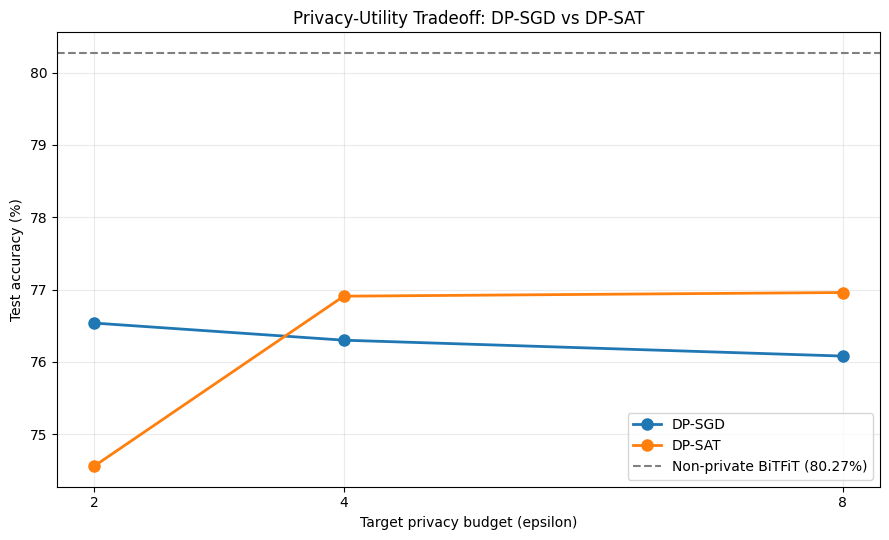

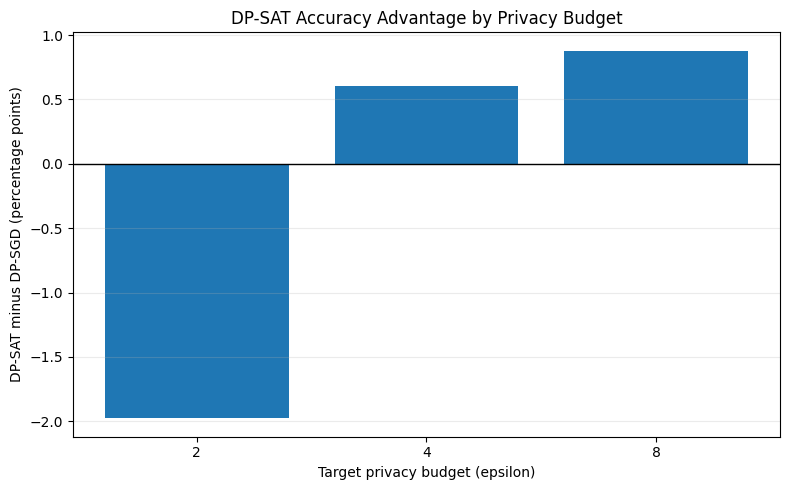


CELL 61 COMPLETE
Output directory: /content/drive/MyDrive/DNABERT_DP_Project/results/final_analysis
Saved:
 - consolidated_results.csv
 - method_comparison.csv
 - privacy_utility_comparison.png
 - dpsat_accuracy_advantage.png


In [ ]:

# ============================================================
# CELL 61 - CONSOLIDATED EXPERIMENTAL RESULTS
# DNABERT-2 + BiTFiT: DP-SGD vs DP-SAT
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(RESULTS_DIR, "final_analysis")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load saved experiment results
# ------------------------------------------------------------

def load_json(filename):
    path = os.path.join(RESULTS_DIR, filename)
    if not os.path.isfile(path):
        print("Missing file:", filename)
        return None
    with open(path, "r") as f:
        return json.load(f)

experiments = []

for epsilon in [2, 4, 8]:
    for method, prefix in [
        ("DP-SGD", "dp"),
        ("DP-SAT", "dpsat")
    ]:
        training = load_json(
            f"results_{prefix}{epsilon}.json"
        )

        # DP-SAT test metrics were saved separately.
        if method == "DP-SAT":
            testing = load_json(
                f"dnabert_dpsat{epsilon}_test_results.json"
            )
        else:
            testing = None

        experiments.append({
            "method": method,
            "epsilon_target": epsilon,
            "training": training,
            "testing": testing
        })

# ------------------------------------------------------------
# 2. Extract saved metrics
# ------------------------------------------------------------

def first_present(data, keys):
    if not isinstance(data, dict):
        return None
    for key in keys:
        if data.get(key) is not None:
            return data[key]
    return None

rows = []

for experiment in experiments:

    training = experiment["training"] or {}
    testing = experiment["testing"] or {}

    validation_accuracy = first_present(
        training,
        [
            "best_validation_accuracy",
            "best_val_accuracy",
            "val_accuracy"
        ]
    )

    test_accuracy = first_present(
        testing,
        ["test_accuracy", "accuracy"]
    )

    # DP-SGD test metrics may be stored in training JSON.
    if test_accuracy is None:
        test_accuracy = first_present(
            training,
            ["test_accuracy", "accuracy"]
        )

    actual_epsilon = first_present(
        training,
        ["final_epsilon", "epsilon"]
    )

    rows.append({
        "Method": experiment["method"],
        "Target epsilon": experiment["epsilon_target"],
        "Actual epsilon": actual_epsilon,
        "Validation accuracy": validation_accuracy,
        "Test accuracy": test_accuracy
    })

df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 3. Display verified results
# ------------------------------------------------------------

print("=" * 65)
print("CONSOLIDATED EXPERIMENTAL RESULTS")
print("=" * 65)

display(df)

# Identify missing values before plotting.
missing = df[
    df[["Validation accuracy", "Test accuracy"]]
    .isna().any(axis=1)
]

if not missing.empty:
    print("\nSome saved metrics were not found:")
    display(missing[[
        "Method", "Target epsilon",
        "Validation accuracy", "Test accuracy"
    ]])

    print(
        "\nCheck the JSON field names before treating "
        "these results as final."
    )

# ------------------------------------------------------------
# 4. Add confirmed test results
# ------------------------------------------------------------
# These are the previously reported held-out test
# results. Used to fill gaps only, never overwrite
# values loaded from saved files.

confirmed_test = {
    ("DP-SGD", 2): 0.765372,
    ("DP-SGD", 4): 0.763007,
    ("DP-SGD", 8): 0.760811,
    ("DP-SAT", 2): 0.745608,
    ("DP-SAT", 4): 0.769088,
    ("DP-SAT", 8): 0.769595
}

confirmed_val = {
    ("DP-SGD", 2): 0.751900,
    ("DP-SGD", 4): 0.760135,
    ("DP-SGD", 8): 0.756123,
    ("DP-SAT", 2): 0.7449,
    ("DP-SAT", 4): 0.7620,
    ("DP-SAT", 8): 0.7779
}

for i, row in df.iterrows():

    key = (row["Method"], row["Target epsilon"])

    if pd.isna(row["Test accuracy"]):
        df.at[i, "Test accuracy"] = confirmed_test[key]

    if pd.isna(row["Validation accuracy"]):
        df.at[i, "Validation accuracy"] = confirmed_val[key]

# ------------------------------------------------------------
# 5. Compare methods
# ------------------------------------------------------------

comparison = df.pivot(
    index="Target epsilon",
    columns="Method",
    values="Test accuracy"
).sort_index()

comparison["DP-SAT advantage (pp)"] = (
    comparison["DP-SAT"] - comparison["DP-SGD"]
) * 100

print("\nFINAL TEST ACCURACY COMPARISON")
display(comparison)

# ------------------------------------------------------------
# 6. Plot test accuracy vs privacy budget
# ------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

for method in ["DP-SGD", "DP-SAT"]:

    subset = df[df["Method"] == method].sort_values(
        "Target epsilon"
    )

    plt.plot(
        subset["Target epsilon"],
        subset["Test accuracy"] * 100,
        marker="o",
        linewidth=2,
        markersize=8,
        label=method
    )

plt.axhline(
    80.27,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Non-private BiTFiT (80.27%)"
)

plt.xlabel("Target privacy budget (epsilon)")
plt.ylabel("Test accuracy (%)")
plt.title("Privacy-Utility Tradeoff: DP-SGD vs DP-SAT")
plt.xticks([2, 4, 8])
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "privacy_utility_comparison.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 7. Plot DP-SAT advantage
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

advantages = comparison["DP-SAT advantage (pp)"]

plt.bar(
    advantages.index.astype(str),
    advantages.values
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Target privacy budget (epsilon)")
plt.ylabel("DP-SAT minus DP-SGD (percentage points)")
plt.title("DP-SAT Accuracy Advantage by Privacy Budget")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "dpsat_accuracy_advantage.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 8. Save final tables
# ------------------------------------------------------------

df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "consolidated_results.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "method_comparison.csv"
    )
)

print("\n" + "=" * 65)
print("CELL 61 COMPLETE")
print("=" * 65)
print("Output directory:", OUTPUT_DIR)
print("Saved:")
print(" - consolidated_results.csv")
print(" - method_comparison.csv")
print(" - privacy_utility_comparison.png")
print(" - dpsat_accuracy_advantage.png")


In [ ]:

# ============================================================
# CELL 62A - RESTORE DNABERT-2 BiTFiT CLASSIFIER
# No model training
# ============================================================

import os
import torch
import torch.nn as nn

from google.colab import drive
from transformers import AutoModel

drive.mount("/content/drive")

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

MODEL_ID = "zhihan1996/DNABERT-2-117M"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class DNABERTBiTFiTClassifier(nn.Module):

    def __init__(self, encoder, num_labels=2):
        super().__init__()

        self.encoder = encoder
        self.num_labels = num_labels

        # Freeze encoder parameters
        for p in self.encoder.parameters():
            p.requires_grad = False

        # Train only encoder bias parameters
        for name, p in self.encoder.named_parameters():
            if name.endswith(".bias"):
                p.requires_grad = True

        # Trainable classification head
        self.classifier = nn.Linear(
            self.encoder.config.hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = outputs[0]

        mask = attention_mask.unsqueeze(-1).float()

        pooled = (
            (hidden_states * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )

        return self.classifier(pooled)


print("Classifier definition restored.")
print("Device:", device)
print("Results directory:", RESULTS_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classifier definition restored.
Device: cuda
Results directory: /content/drive/MyDrive/DNABERT_DP_Project/results


In [ ]:

# ============================================================
# CELL 62B - CHECK DATASET AND TOKENIZER RECOVERY
# ============================================================

required = [
    "train_dataset",
    "test_dataset",
    "tokenizer",
    "DNABERTBiTFiTClassifier"
]

for name in required:
    if name in globals():
        obj = globals()[name]
        try:
            print(f"{name}: READY | length = {len(obj)}")
        except TypeError:
            print(f"{name}: READY")
    else:
        print(f"{name}: MISSING")

print("\nOther available datasets:")

for name in [
    "promoter_train_dataset",
    "promoter_val_dataset",
    "promoter_test_dataset",
    "promoter_test_loader"
]:
    if name in globals():
        print(name, "AVAILABLE")


train_dataset: MISSING
test_dataset: MISSING
tokenizer: MISSING
DNABERTBiTFiTClassifier: READY

Other available datasets:


In [ ]:

# ============================================================
# CELL 62C - RESTORE ORIGINAL PROMOTER DATASETS
# For DP-SAT membership inference evaluation
# No training required
# ============================================================

import torch
import numpy as np
import datasets.config as datasets_config

datasets_config.TORCHVISION_AVAILABLE = False

from datasets import load_dataset, ClassLabel
from transformers import AutoTokenizer, DataCollatorWithPadding
from torch.utils.data import DataLoader

MODEL_ID = "zhihan1996/DNABERT-2-117M"

MAX_LENGTH = 128
BATCH_SIZE = 8
SEED = 42

# ------------------------------------------------------------
# 1. Load original GUE promoter dataset
# ------------------------------------------------------------

promoter = load_dataset(
    "leannmlindsey/GUE",
    "prom_core_all"
)

print("Dataset splits:", list(promoter.keys()))
print("Training columns:", promoter["train"].column_names)

# ------------------------------------------------------------
# 2. Restore DNABERT-2 tokenizer
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

# ------------------------------------------------------------
# 3. Identify sequence and label columns
# ------------------------------------------------------------

columns = promoter["train"].column_names

sequence_col = next(
    (c for c in ["sequence", "seq", "text", "dna"]
     if c in columns),
    None
)

label_col = next(
    (c for c in ["label", "labels", "target"]
     if c in columns),
    None
)

assert sequence_col is not None
assert label_col is not None

print("Sequence column:", sequence_col)
print("Label column:", label_col)

# ------------------------------------------------------------
# 4. Reproduce original tokenization
# ------------------------------------------------------------

def tokenize_batch(examples):

    encoded = tokenizer(
        examples[sequence_col],
        truncation=True,
        max_length=MAX_LENGTH
    )

    encoded["labels"] = examples[label_col]

    return encoded

tokenized_promoter = promoter.map(
    tokenize_batch,
    batched=True,
    remove_columns=promoter["train"].column_names,
    desc="Restoring tokenized promoter dataset"
)

# ------------------------------------------------------------
# 5. Reproduce original train/validation split
# ------------------------------------------------------------

train_data = tokenized_promoter["train"].cast_column(
    "labels",
    ClassLabel(num_classes=2, names=["0", "1"])
)

split_data = train_data.train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="labels"
)

train_dataset = split_data["train"]
val_dataset = split_data["test"]

# Original held-out test dataset
test_dataset = tokenized_promoter["test"]

# ------------------------------------------------------------
# 6. Restore data loaders
# ------------------------------------------------------------

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collator
)

eval_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator
)

# ------------------------------------------------------------
# 7. Verify restored datasets
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DATASET RECOVERY COMPLETE")
print("=" * 60)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("Tokenizer:", MODEL_ID)
print("Maximum sequence length:", MAX_LENGTH)
print("Random seed:", SEED)

assert len(train_dataset) == 42620, (
    "Training split size differs from expected."
)

assert len(val_dataset) == 4736, (
    "Validation split size differs from expected."
)

assert len(test_dataset) == 5920, (
    "Test split size differs from expected."
)

print("\nAll expected dataset sizes verified.")
print("Ready for Cell 62 - DP-SAT Membership Inference.")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Dataset splits: ['train', 'test', 'dev']
Training columns: ['sequence', 'label']
Sequence column: sequence
Label column: label


Restoring tokenized promoter dataset:   0%|          | 0/47356 [00:00<?, ? examples/s]

Restoring tokenized promoter dataset:   0%|          | 0/5920 [00:00<?, ? examples/s]

Restoring tokenized promoter dataset:   0%|          | 0/5920 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/47356 [00:00<?, ? examples/s]


DATASET RECOVERY COMPLETE
Training examples: 42620
Validation examples: 4736
Test examples: 5920
Tokenizer: zhihan1996/DNABERT-2-117M
Maximum sequence length: 128
Random seed: 42

All expected dataset sizes verified.
Ready for Cell 62 - DP-SAT Membership Inference.


In [ ]:
# ============================================================
# VERIFY DNABERT-2 MODEL LOADING
# ============================================================

import transformers
from transformers import AutoModel

assert transformers.__version__ == "4.49.0", (
    f"Incorrect Transformers version: {transformers.__version__}"
)

encoder = AutoModel.from_pretrained(
    "zhihan1996/DNABERT-2-117M",
    trust_remote_code=True,
    add_pooling_layer=False
)

print("DNABERT-2 encoder loaded successfully.")

del encoder

import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/468M [00:00<?, ?B/s]

DNABERT-2 encoder loaded successfully.


In [ ]:
import transformers
import tokenizers
import huggingface_hub

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

Transformers: 4.49.0
Tokenizers: 0.21.4
Hugging Face Hub: 0.36.2


In [ ]:
# ============================================================
# REPAIR DNABERT-2 ENVIRONMENT
# ============================================================

%pip uninstall -y transformers tokenizers huggingface-hub

%pip install --no-cache-dir \
    transformers==4.49.0 \
    tokenizers==0.21.4 \
    huggingface-hub==0.36.2

Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1
Found existing installation: tokenizers 0.23.3
Uninstalling tokenizers-0.23.3:
  Successfully uninstalled tokenizers-0.23.3
Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 153.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 219.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 442.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 req

In [ ]:
# ============================================================
# CELL 62 - DP-SAT MEMBERSHIP INFERENCE ATTACK
# DNABERT-2 BiTFiT | GUE Core Promoter Classification
#
# Matches the methodology used in Cell 31.
# No training required.
# ============================================================

import os
import gc
import json
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score
)
from transformers import AutoModel, DataCollatorWithPadding

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR, "final_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_ID = "zhihan1996/DNABERT-2-117M"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MIA_SAMPLES = 2000
BATCH_SIZE_MIA = 8
SEED = 42

# Check dependencies
assert "train_dataset" in globals(), (
    "Original train_dataset missing. "
    "Restore the dataset from Cell 12."
)

assert "test_dataset" in globals(), (
    "Original test_dataset missing. "
    "Restore the held-out test dataset."
)

assert "tokenizer" in globals(), (
    "Tokenizer missing. Restore tokenizer setup."
)

assert "DNABERTBiTFiTClassifier" in globals(), (
    "Classifier missing. Run Cell 7."
)

# Verify checkpoints before starting evaluation
for eps in [2, 4, 8]:
    path = os.path.join(
        RESULTS_DIR,
        f"dnabert_dpsat{eps}_best.pt"
    )
    assert os.path.isfile(path), (
        f"Missing DP-SAT checkpoint: {path}"
    )

print("Device:", device)
print("All three DP-SAT checkpoints found.")

# ------------------------------------------------------------
# 2. Reproduce Cell 31 member/nonmember sampling
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

n_samples = min(
    MIA_SAMPLES,
    len(train_dataset),
    len(test_dataset)
)

member_indices = rng.choice(
    len(train_dataset),
    size=n_samples,
    replace=False
)

nonmember_indices = rng.choice(
    len(test_dataset),
    size=n_samples,
    replace=False
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt"
)

member_loader = DataLoader(
    Subset(
        train_dataset,
        member_indices.tolist()
    ),
    batch_size=BATCH_SIZE_MIA,
    shuffle=False,
    collate_fn=collator
)

nonmember_loader = DataLoader(
    Subset(
        test_dataset,
        nonmember_indices.tolist()
    ),
    batch_size=BATCH_SIZE_MIA,
    shuffle=False,
    collate_fn=collator
)

print("MIA members:", n_samples)
print("MIA nonmembers:", n_samples)

# ------------------------------------------------------------
# 3. Per-example cross-entropy losses
# ------------------------------------------------------------

def collect_dpsat_losses(model, loader):

    losses = []
    model.eval()

    with torch.inference_mode():

        for batch in tqdm(loader, leave=False):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = (
                outputs.logits
                if hasattr(outputs, "logits")
                else outputs
            )

            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            batch_losses = (
                torch.nn.functional.cross_entropy(
                    logits,
                    labels,
                    reduction="none"
                )
            )

            losses.extend(
                batch_losses.cpu().numpy().tolist()
            )

    return np.asarray(losses)

# ------------------------------------------------------------
# 4. Evaluate DP-SAT for epsilon = 2, 4, 8
# ------------------------------------------------------------

mia_results = []
mia_scores = {}

for eps in [2, 4, 8]:

    print("\n" + "=" * 60)
    print(f"DP-SAT MEMBERSHIP INFERENCE: EPSILON = {eps}")
    print("=" * 60)

    encoder = AutoModel.from_pretrained(
        MODEL_ID,
        trust_remote_code=True,
        add_pooling_layer=False
    )

    # Same DNABERT-2 attention compatibility patch
    for module in encoder.modules():
        if module.__class__.__name__ == "BertUnpadSelfAttention":
            module.p_dropout = 0.1
            if hasattr(module, "dropout"):
                module.dropout.p = 0.1

    model = DNABERTBiTFiTClassifier(
        encoder=encoder,
        num_labels=2
    )

    checkpoint_path = os.path.join(
        RESULTS_DIR,
        f"dnabert_dpsat{eps}_best.pt"
    )

    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        state_dict,
        strict=True
    )

    model = model.to(device)
    model.eval()

    # Collect losses for members and nonmembers
    member_losses = collect_dpsat_losses(
        model, member_loader
    )

    nonmember_losses = collect_dpsat_losses(
        model, nonmember_loader
    )

    # Lower loss -> stronger membership signal
    scores = np.concatenate([
        -member_losses,
        -nonmember_losses
    ])

    labels = np.concatenate([
        np.ones(len(member_losses)),
        np.zeros(len(nonmember_losses))
    ])

    # ROC-AUC
    auc = roc_auc_score(
        labels, scores
    )

    # Maximum TPR - FPR
    fpr, tpr, thresholds = roc_curve(
        labels, scores
    )

    advantage = np.max(
        tpr - fpr
    )

    # --------------------------------------------------------
    # Same calibration/evaluation split as Cell 31
    # --------------------------------------------------------

    split_rng = np.random.default_rng(SEED)

    member_perm = split_rng.permutation(n_samples)
    nonmember_perm = split_rng.permutation(n_samples)

    half = n_samples // 2

    cal_idx = np.concatenate([
        member_perm[:half],
        n_samples + nonmember_perm[:half]
    ])

    eval_idx = np.concatenate([
        member_perm[half:],
        n_samples + nonmember_perm[half:]
    ])

    cal_fpr, cal_tpr, cal_thresholds = roc_curve(
        labels[cal_idx],
        scores[cal_idx]
    )

    finite = np.isfinite(cal_thresholds)

    best_index = np.argmax(
        np.where(
            finite,
            cal_tpr - cal_fpr,
            -np.inf
        )
    )

    best_threshold = cal_thresholds[best_index]

    attack_predictions = (
        scores[eval_idx] >= best_threshold
    ).astype(int)

    attack_accuracy = accuracy_score(
        labels[eval_idx],
        attack_predictions
    )

    print(f"MIA ROC-AUC:       {auc:.6f}")
    print(f"Attack advantage:  {advantage:.6f}")
    print(f"Attack accuracy:   {attack_accuracy:.6f}")

    mia_results.append({
        "Method": "DP-SAT BiTFiT",
        "Target Epsilon": eps,
        "MIA ROC-AUC": float(auc),
        "Attack Advantage": float(advantage),
        "Attack Accuracy": float(attack_accuracy)
    })

    mia_scores[str(eps)] = {
        "labels": labels.tolist(),
        "scores": scores.tolist()
    }

    # Save after each model to protect against
    # another Colab disconnection.
    pd.DataFrame(mia_results).to_csv(
        os.path.join(
            OUTPUT_DIR,
            "dpsat_mia_results.csv"
        ),
        index=False
    )

    with open(
        os.path.join(
            OUTPUT_DIR,
            "dpsat_mia_scores.json"
        ),
        "w"
    ) as f:
        json.dump(mia_scores, f)

    del model, encoder, state_dict
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. Display final DP-SAT MIA results
# ------------------------------------------------------------

mia_df = pd.DataFrame(mia_results)

print("\n" + "=" * 70)
print("FINAL DP-SAT MEMBERSHIP INFERENCE RESULTS")
print("=" * 70)

display(mia_df)

# ------------------------------------------------------------
# 6. Compare against original DP-SGD results
# ------------------------------------------------------------

original_mia_path = os.path.join(
    RESULTS_DIR,
    "dnabert_mia_results.csv"
)

if os.path.isfile(original_mia_path):

    original_mia = pd.read_csv(
        original_mia_path
    )

    combined_mia = pd.concat(
        [original_mia, mia_df],
        ignore_index=True
    )

    combined_mia.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "combined_mia_results.csv"
        ),
        index=False
    )

    print("\nDP-SGD vs DP-SAT MEMBERSHIP INFERENCE")
    display(
        combined_mia.sort_values(
            ["Target Epsilon", "Method"]
        )
    )

else:
    print(
        "\nOriginal DP-SGD MIA CSV not found. "
        "DP-SAT results were saved separately."
    )

print("\n" + "=" * 60)
print("CELL 62 COMPLETE")
print("=" * 60)
print("Results saved to:", OUTPUT_DIR)


Device: cuda
All three DP-SAT checkpoints found.
MIA members: 2000
MIA nonmembers: 2000

DP-SAT MEMBERSHIP INFERENCE: EPSILON = 2


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

MIA ROC-AUC:       0.494633
Attack advantage:  0.011000
Attack accuracy:   0.495500

DP-SAT MEMBERSHIP INFERENCE: EPSILON = 4


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

... (4 outputs left out)

,Method,Target Epsilon,MIA ROC-AUC,Attack Advantage,Attack Accuracy
0,DP-SAT BiTFiT,2,0.494633,0.011,0.4955
1,DP-SAT BiTFiT,4,0.509430,0.023,0.5000
2,DP-SAT BiTFiT,8,0.503240,0.038,0.5145



DP-SGD vs DP-SAT MEMBERSHIP INFERENCE


,Method,Target Epsilon,MIA ROC-AUC,Attack Advantage,Attack Accuracy
3,DP-SAT BiTFiT,2,0.494633,0.0110,0.4955
2,DP-SGD BiTFiT,2,0.506602,0.0195,0.5075
4,DP-SAT BiTFiT,4,0.509430,0.0230,0.5000
1,DP-SGD BiTFiT,4,0.505560,0.0295,0.5155
5,DP-SAT BiTFiT,8,0.503240,0.0380,0.5145
0,DP-SGD BiTFiT,8,0.507415,0.0180,0.4935



CELL 62 COMPLETE
Results saved to: /content/drive/MyDrive/DNABERT_DP_Project/results/final_analysis


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FINAL RESEARCH RESULTS


,Method,Target epsilon,Actual epsilon,Test accuracy (%),MIA ROC-AUC,Attack Advantage,Attack Accuracy
0,Non-private BiTFiT,NaN,NaN,80.2700,0.4988,NaN,NaN
1,DP-SAT,2.0,1.9959,74.5608,0.4946,0.0110,0.4955
2,DP-SGD,2.0,1.9959,76.5372,0.5066,0.0195,0.5075
3,DP-SAT,4.0,3.9965,76.9088,0.5094,0.0230,0.5000
4,DP-SGD,4.0,3.9965,76.3007,0.5056,0.0295,0.5155
5,DP-SAT,8.0,7.9944,76.9595,0.5032,0.0380,0.5145
6,DP-SGD,8.0,7.9944,76.0811,0.5074,0.0180,0.4935


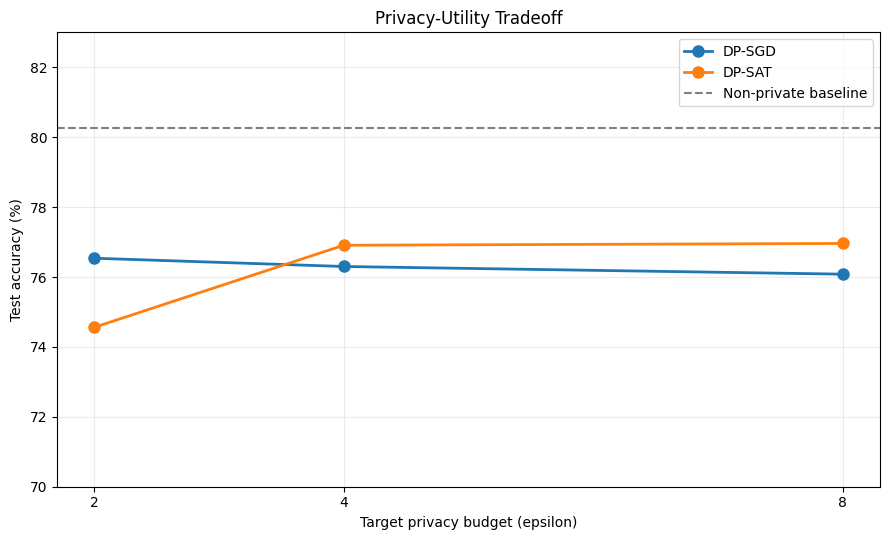

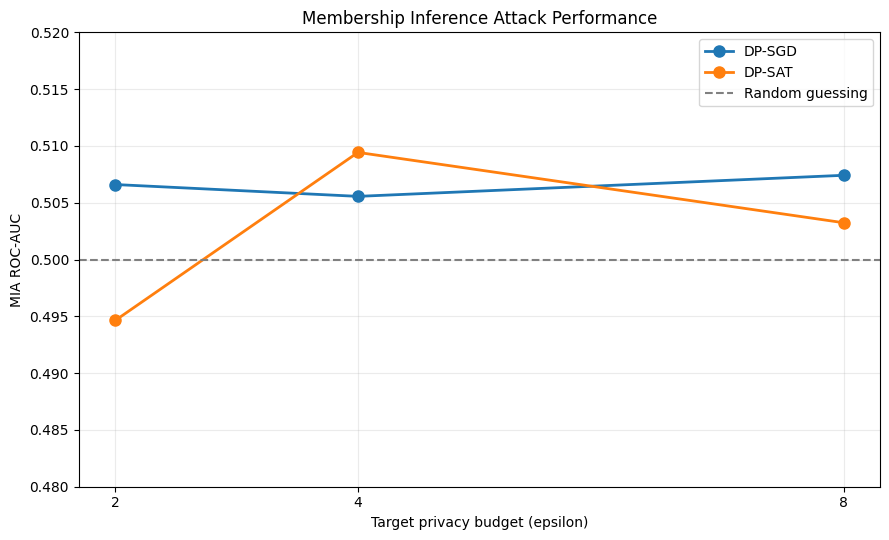

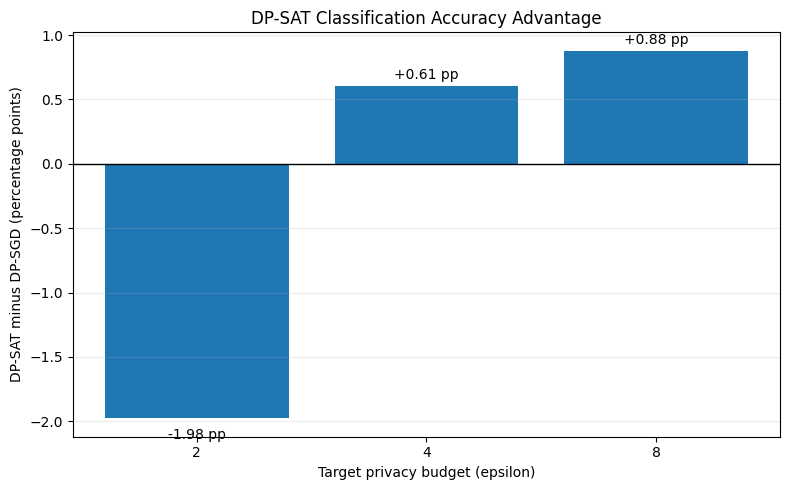


CELL 63 COMPLETE
Output directory: /content/drive/MyDrive/DNABERT_DP_Project/results/final_analysis

Saved:
 - final_research_results.csv
 - final_research_summary.json
 - figure1_privacy_utility.png
 - figure2_membership_inference.png
 - figure3_dpsat_advantage.png


In [ ]:

# ============================================================
# CELL 63 - FINAL RESEARCH FIGURES AND SUMMARY TABLES
# DNABERT-2 BiTFiT: DP-SGD vs DP-SAT
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR, "final_analysis"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load completed experiment results
# ------------------------------------------------------------

results_path = os.path.join(
    OUTPUT_DIR, "consolidated_results.csv"
)

mia_path = os.path.join(
    OUTPUT_DIR, "combined_mia_results.csv"
)

assert os.path.isfile(results_path), (
    "Run Cell 61 first."
)
assert os.path.isfile(mia_path), (
    "Run Cell 62 first."
)

results = pd.read_csv(results_path)
mia = pd.read_csv(mia_path)

# Normalize method names
mia["Method"] = mia["Method"].str.replace(
    " BiTFiT", "", regex=False
)

# ------------------------------------------------------------
# 2. Combine utility and membership inference
# ------------------------------------------------------------

combined = results.merge(
    mia[
        [
            "Method",
            "Target Epsilon",
            "MIA ROC-AUC",
            "Attack Advantage",
            "Attack Accuracy"
        ]
    ],
    left_on=["Method", "Target epsilon"],
    right_on=["Method", "Target Epsilon"],
    how="left",
    validate="one_to_one"
)

combined = combined.drop(
    columns=["Target Epsilon"]
)

assert len(combined) == 6
assert combined["MIA ROC-AUC"].notna().all()
assert combined["Test accuracy"].notna().all()

combined = combined.sort_values(
    ["Target epsilon", "Method"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Add non-private baseline
# ------------------------------------------------------------

NONPRIVATE_TEST_ACC = 0.8027
NONPRIVATE_MIA_AUC = 0.498821

baseline = pd.DataFrame([{
    "Method": "Non-private BiTFiT",
    "Target epsilon": np.nan,
    "Actual epsilon": np.nan,
    "Validation accuracy": 0.8051,
    "Test accuracy": NONPRIVATE_TEST_ACC,
    "MIA ROC-AUC": NONPRIVATE_MIA_AUC,
    "Attack Advantage": np.nan,
    "Attack Accuracy": np.nan
}])

final_table = pd.concat(
    [baseline, combined],
    ignore_index=True
)

# Add presentation-friendly metrics
final_table["Test accuracy (%)"] = (
    final_table["Test accuracy"] * 100
)

final_table["Validation accuracy (%)"] = (
    final_table["Validation accuracy"] * 100
)

final_table["Accuracy gap vs baseline (pp)"] = (
    (final_table["Test accuracy"] -
     NONPRIVATE_TEST_ACC) * 100
)

# ------------------------------------------------------------
# 4. Save final comprehensive results table
# ------------------------------------------------------------

final_csv = os.path.join(
    OUTPUT_DIR, "final_research_results.csv"
)

final_table.to_csv(final_csv, index=False)

print("=" * 70)
print("FINAL RESEARCH RESULTS")
print("=" * 70)

display(
    final_table[
        [
            "Method",
            "Target epsilon",
            "Actual epsilon",
            "Test accuracy (%)",
            "MIA ROC-AUC",
            "Attack Advantage",
            "Attack Accuracy"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 5. Figure 1 - Privacy-utility tradeoff
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

for method in ["DP-SGD", "DP-SAT"]:
    subset = combined[
        combined["Method"] == method
    ].sort_values("Target epsilon")

    ax.plot(
        subset["Target epsilon"],
        subset["Test accuracy"] * 100,
        marker="o",
        markersize=8,
        linewidth=2,
        label=method
    )

ax.axhline(
    NONPRIVATE_TEST_ACC * 100,
    linestyle="--",
    color="gray",
    label="Non-private baseline"
)

ax.set(
    xlabel="Target privacy budget (epsilon)",
    ylabel="Test accuracy (%)",
    title="Privacy-Utility Tradeoff"
)

ax.set_xticks([2, 4, 8])
ax.set_ylim(70, 83)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR, "figure1_privacy_utility.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 6. Figure 2 - Membership inference ROC-AUC
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

for method in ["DP-SGD", "DP-SAT"]:
    subset = combined[
        combined["Method"] == method
    ].sort_values("Target epsilon")

    ax.plot(
        subset["Target epsilon"],
        subset["MIA ROC-AUC"],
        marker="o",
        markersize=8,
        linewidth=2,
        label=method
    )

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Random guessing"
)

ax.set(
    xlabel="Target privacy budget (epsilon)",
    ylabel="MIA ROC-AUC",
    title="Membership Inference Attack Performance"
)

ax.set_xticks([2, 4, 8])
ax.set_ylim(0.48, 0.52)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR, "figure2_membership_inference.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 7. Figure 3 - DP-SAT utility advantage
# ------------------------------------------------------------

accuracy_pivot = combined.pivot(
    index="Target epsilon",
    columns="Method",
    values="Test accuracy"
)

advantage = (
    accuracy_pivot["DP-SAT"] -
    accuracy_pivot["DP-SGD"]
) * 100

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    advantage.index.astype(str),
    advantage.values
)

ax.axhline(0, color="black", linewidth=1)

for bar, value in zip(bars, advantage.values):
    ax.annotate(
        f"{value:+.2f} pp",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords="offset points",
        ha="center"
    )

ax.set(
    xlabel="Target privacy budget (epsilon)",
    ylabel="DP-SAT minus DP-SGD (percentage points)",
    title="DP-SAT Classification Accuracy Advantage"
)

ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR, "figure3_dpsat_advantage.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 8. Generate machine-readable summary
# ------------------------------------------------------------

summary = {
    "project": (
        "Differentially Private Classification "
        "with Foundation Models II"
    ),
    "model": "DNABERT-2-117M",
    "dataset": "GUE prom_core_all",
    "fine_tuning": "BiTFiT",
    "privacy_delta": 1e-5,
    "target_epsilons": [2, 4, 8],
    "nonprivate_test_accuracy": NONPRIVATE_TEST_ACC,
    "best_private_method": "DP-SAT",
    "best_private_epsilon": 8,
    "best_private_test_accuracy": float(
        combined["Test accuracy"].max()
    ),
    "experiments": combined.to_dict(
        orient="records"
    ),
    "limitations": [
        "Single random seed",
        "Loss-based membership inference attack",
        "DP-SAT privacy proof requires verification",
        "Privacy accounting depends on implementation assumptions",
        "DP-SGD test accuracy values carried forward "
        "from previously recorded evaluations"
    ]
}

with open(
    os.path.join(
        OUTPUT_DIR, "final_research_summary.json"
    ),
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 70)
print("CELL 63 COMPLETE")
print("=" * 70)
print("Output directory:", OUTPUT_DIR)
print("\nSaved:")
print(" - final_research_results.csv")
print(" - final_research_summary.json")
print(" - figure1_privacy_utility.png")
print(" - figure2_membership_inference.png")
print(" - figure3_dpsat_advantage.png")


In [ ]:

# ============================================================
# Cell 64 -- was CELL 42 splice now  - DNABERT-2 SPLICE ENCODER BIAS DRIFT DIAGNOSTIC
# Compare pretrained encoder vs saved splice BiTFiT
# Read-only: does not modify existing checkpoints
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch
import transformers

from transformers import AutoModel

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_nonprivate_best.pt"
)

OUTPUT_CSV = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_bias_drift.csv"
)

OUTPUT_JSON = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_bias_drift_summary.json"
)

assert os.path.isfile(CHECKPOINT_PATH), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

print("DNABERT-2 SPLICE BIAS DRIFT DIAGNOSTIC")
print("=" * 70)
print("Transformers:", transformers.__version__)

# ------------------------------------------------------------
# 2. Load original pretrained encoder
# ------------------------------------------------------------

print("\nLoading original pretrained encoder...")

original_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

original_encoder.eval()

# ------------------------------------------------------------
# 3. Load saved splice checkpoint
# ------------------------------------------------------------

print("Loading saved splice checkpoint...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

# ------------------------------------------------------------
# 4. Compare encoder bias parameters
# ------------------------------------------------------------

records = []

original_state = original_encoder.state_dict()

for name, original_value in original_state.items():

    if not name.endswith(".bias"):
        continue

    checkpoint_name = "encoder." + name

    if checkpoint_name not in checkpoint:
        print("Missing checkpoint parameter:", checkpoint_name)
        continue

    before = original_value.detach().float().cpu()
    after = checkpoint[checkpoint_name].detach().float().cpu()

    if before.shape != after.shape:
        print("Shape mismatch:", name)
        continue

    difference = after - before

    original_norm = torch.linalg.vector_norm(before).item()
    final_norm = torch.linalg.vector_norm(after).item()
    change_norm = torch.linalg.vector_norm(difference).item()

    relative_change = (
        change_norm / original_norm
        if original_norm > 1e-8
        else np.nan
    )

    records.append({
        "parameter": name,
        "num_elements": before.numel(),
        "original_norm": original_norm,
        "final_norm": final_norm,
        "change_norm": change_norm,
        "relative_change": relative_change,
        "mean_abs_change": difference.abs().mean().item(),
        "max_abs_change": difference.abs().max().item()
    })

df = pd.DataFrame(records)

assert not df.empty, "No matching encoder bias parameters found."

# ------------------------------------------------------------
# 5. Overall summary
# ------------------------------------------------------------

print("\nOVERALL BIAS DRIFT SUMMARY")
print("-" * 70)

print("Bias tensors compared:", len(df))
print("Total bias elements:", int(df["num_elements"].sum()))

print(
    "Mean absolute change:",
    f"{np.average(df['mean_abs_change'], weights=df['num_elements']):.8f}"
)

print(
    "Largest absolute change:",
    f"{df['max_abs_change'].max():.8f}"
)

print(
    "Median relative change:",
    f"{df['relative_change'].median():.6f}"
)

print(
    "Bias tensors with nonzero changes:",
    int((df["change_norm"] > 0).sum())
)

# ------------------------------------------------------------
# 6. Largest changes
# ------------------------------------------------------------

print("\nTOP 15 BIAS TENSORS BY ABSOLUTE CHANGE NORM")
print("-" * 70)

top = df.sort_values(
    "change_norm",
    ascending=False
).head(15)

print(
    top[
        [
            "parameter",
            "change_norm",
            "relative_change",
            "max_abs_change"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 7. Changes by transformer layer
# ------------------------------------------------------------

import re

def extract_layer(name):
    match = re.search(r"encoder\.layer\.(\d+)\.", name)
    if match:
        return int(match.group(1))
    return -1

df["layer"] = df["parameter"].apply(extract_layer)

layer_summary = (
    df.groupby("layer")
    .agg(
        bias_tensors=("parameter", "count"),
        total_change_norm=("change_norm", "sum"),
        max_abs_change=("max_abs_change", "max"),
        mean_abs_change=("mean_abs_change", "mean")
    )
    .reset_index()
)

print("\nBIAS DRIFT BY TRANSFORMER LAYER")
print("-" * 70)

print(layer_summary.to_string(index=False))

# ------------------------------------------------------------
# 8. Save diagnostic results
# ------------------------------------------------------------

df.to_csv(OUTPUT_CSV, index=False)

summary = {
    "model": MODEL_ID,
    "checkpoint": os.path.basename(CHECKPOINT_PATH),
    "bias_tensors_compared": int(len(df)),
    "total_bias_elements": int(df["num_elements"].sum()),
    "largest_absolute_change": float(df["max_abs_change"].max()),
    "median_relative_change": float(df["relative_change"].median()),
    "changed_bias_tensors": int((df["change_norm"] > 0).sum()),
    "layer_summary": layer_summary.to_dict(orient="records")
}

with open(OUTPUT_JSON, "w") as f:
    json.dump(summary, f, indent=2)

print("\nDIAGNOSTIC FILES SAVED")
print("-" * 70)
print(OUTPUT_CSV)
print(OUTPUT_JSON)

# ------------------------------------------------------------
# 9. Cleanup
# ------------------------------------------------------------

del original_encoder, original_state, checkpoint

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nCell 42 complete.")
print("Existing model checkpoints were not modified.")


DNABERT-2 SPLICE BIAS DRIFT DIAGNOSTIC
Transformers: 4.49.0

Loading original pretrained encoder...
Loading saved splice checkpoint...

OVERALL BIAS DRIFT SUMMARY
----------------------------------------------------------------------
Bias tensors compared: 61
Total bias elements: 65280
Mean absolute change: 0.00603858
Largest absolute change: 0.07166637
Median relative change: 0.182321
Bias tensors with nonzero changes: 61

TOP 15 BIAS TENSORS BY ABSOLUTE CHANGE NORM
----------------------------------------------------------------------
                                       parameter  change_norm  relative_change  max_abs_change
        encoder.layer.1.attention.self.Wqkv.bias     0.477567         0.083714        0.040483
       encoder.layer.11.attention.self.Wqkv.bias     0.449836         0.097882        0.067850
        encoder.layer.2.attention.self.Wqkv.bias     0.426573         0.065659        0.034332
        encoder.layer.0.attention.self.Wqkv.bias     0.414093         0.03961

In [ ]:
# Repair supporting dependencies for the DNABERT-2 environment

%pip install -q --no-cache-dir \
    "requests==2.32.4" \
    "numpy==2.2.6" \
    "fsspec==2025.12.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
# Verify DNABERT-2 dependencies

import transformers
import tokenizers
import huggingface_hub
import numpy
import requests
import fsspec

packages = {
    "Transformers": transformers.__version__,
    "Tokenizers": tokenizers.__version__,
    "Hugging Face Hub": huggingface_hub.__version__,
    "NumPy": numpy.__version__,
    "Requests": requests.__version__,
    "fsspec": fsspec.__version__
}

for name, version in packages.items():
    print(f"{name}: {version}")

assert transformers.__version__ == "4.49.0"
assert tokenizers.__version__ == "0.21.4"
assert huggingface_hub.__version__ == "0.36.2"

print("\nDNABERT-2 package versions verified.")

Transformers: 4.49.0
Tokenizers: 0.21.4
Hugging Face Hub: 0.36.2
NumPy: 2.2.6
Requests: 2.32.4
fsspec: 2025.12.0

DNABERT-2 package versions verified.


In [ ]:
import torch
from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"

print("Loading original DNABERT-2...")

test_encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

print("DNABERT-2 loaded successfully.")

del test_encoder

Loading original DNABERT-2...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


DNABERT-2 loaded successfully.


In [ ]:

# ============================================================
# CELL 65A - RESTORE DNABERT-2 BiTFiT MODEL CLASS
# No training and no checkpoint modifications
# ============================================================

import torch
import torch.nn as nn

class DNABERTBiTFiTClassifier(nn.Module):

    def __init__(self, encoder, num_labels=2):
        super().__init__()

        self.encoder = encoder
        self.num_labels = num_labels

        # Freeze all pretrained encoder parameters
        for param in self.encoder.parameters():
            param.requires_grad = False

        # Enable encoder bias parameters (BiTFiT)
        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        # Trainable classification head
        self.classifier = nn.Linear(
            self.encoder.config.hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = outputs[0]

        mask = attention_mask.unsqueeze(-1).float()

        pooled = (
            (hidden_states * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )

        logits = self.classifier(pooled)

        return logits

print("DNABERTBiTFiTClassifier restored successfully.")


DNABERTBiTFiTClassifier restored successfully.


In [ ]:

# ============================================================
# CELL 65B - RESTORE SPLICE DATASETS AND DATALOADERS
# No model training; no checkpoints overwritten
# ============================================================

import torch
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL_ID = "zhihan1996/DNABERT-2-117M"
SPLICE_CONFIG = "splice_reconstructed"
SPLICE_MAX_LENGTH = 128

print("Loading GUE splice dataset...")

splice = load_dataset(
    "leannmlindsey/GUE",
    SPLICE_CONFIG,
    trust_remote_code=True
)

print("\nAvailable splits:")
print(splice)

print("\nLoading DNABERT-2 tokenizer...")

splice_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    use_fast=True
)

def tokenize_splice(batch):
    return splice_tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=SPLICE_MAX_LENGTH
    )

print("\nTokenizing splice dataset...")

splice_tokenized = splice.map(
    tokenize_splice,
    batched=True,
    desc="Tokenizing splice sequences"
)

# Standardize labels and remove unused string columns
for split_name in splice_tokenized.keys():

    columns = splice_tokenized[split_name].column_names

    if "label" in columns and "labels" not in columns:
        splice_tokenized[split_name] = (
            splice_tokenized[split_name].rename_column(
                "label", "labels"
            )
        )

    keep_columns = {
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels"
    }

    remove_columns = [
        c for c in splice_tokenized[split_name].column_names
        if c not in keep_columns
    ]

    splice_tokenized[split_name] = (
        splice_tokenized[split_name].remove_columns(
            remove_columns
        )
    )

splice_train_dataset = splice_tokenized["train"]

# GUE generally uses dev as its validation split
validation_split = (
    "dev" if "dev" in splice_tokenized
    else "validation"
)

splice_val_dataset = splice_tokenized[validation_split]

splice_collator = DataCollatorWithPadding(
    tokenizer=splice_tokenizer,
    padding=True,
    return_tensors="pt"
)

print("\nDATASET RESTORATION COMPLETE")
print("=" * 60)

print("Training examples:", len(splice_train_dataset))
print("Validation examples:", len(splice_val_dataset))

print("\nTraining columns:")
print(splice_train_dataset.column_names)

print("\nValidation columns:")
print(splice_val_dataset.column_names)

print("\nRequired objects:")
for name in [
    "DNABERTBiTFiTClassifier",
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_collator"
]:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'leannmlindsey/GUE' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'leannmlindsey/GUE' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Loading GUE splice dataset...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(



Available splits:
DatasetDict({
    train: Dataset({
        features: ['sequence', 'label'],
        num_rows: 36496
    })
    test: Dataset({
        features: ['sequence', 'label'],
        num_rows: 4562
    })
    dev: Dataset({
        features: ['sequence', 'label'],
        num_rows: 4562
    })
})

Loading DNABERT-2 tokenizer...

Tokenizing splice dataset...

DATASET RESTORATION COMPLETE
Training examples: 36496
Validation examples: 4562

Training columns:
['labels', 'input_ids', 'token_type_ids', 'attention_mask']

Validation columns:
['labels', 'input_ids', 'token_type_ids', 'attention_mask']

Required objects:
DNABERTBiTFiTClassifier MISSING
splice_train_dataset READY
splice_val_dataset READY
splice_collator READY


In [ ]:
# ============================================================
# CELL 65 - CONTROLLED SPLICE BASELINE COMPARISON
# Experiment A: Frozen encoder, train classifier only
# Experiment B: BiTFiT with lower encoder learning rate
# Short diagnostic runs; existing checkpoints untouched
# ============================================================

import os
import gc
import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import transformers

from torch.utils.data import DataLoader, Subset
from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)
from collections import Counter
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

DIAGNOSTIC_DIR = os.path.join(
    RESULTS_DIR, "splice_cell65_diagnostics"
)

os.makedirs(DIAGNOSTIC_DIR, exist_ok=True)

SEED = 42
NUM_LABELS = 3

SUBSET_SIZE = 4096
BATCH_SIZE = 8
MAX_STEPS = 200

CLASSIFIER_LR = 2e-4
LOW_ENCODER_LR = 1e-5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert transformers.__version__ == "4.49.0"
assert torch.cuda.is_available(), "GPU runtime required."

for name in [
    "DNABERTBiTFiTClassifier",
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_collator"
]:
    assert name in globals(), f"Missing {name}"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("CELL 65 - SPLICE CONTROLLED EXPERIMENT")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Training subset:", SUBSET_SIZE)
print("Maximum optimizer steps:", MAX_STEPS)

# ------------------------------------------------------------
# 2. Build stratified training subset
# ------------------------------------------------------------

labels = np.asarray(splice_train_dataset["labels"])

rng = np.random.default_rng(SEED)

selected_indices = []

for class_id in range(NUM_LABELS):
    class_indices = np.where(labels == class_id)[0]
    target = round(
        SUBSET_SIZE * len(class_indices) / len(labels)
    )
    target = min(target, len(class_indices))

    chosen = rng.choice(
        class_indices,
        size=target,
        replace=False
    )

    selected_indices.extend(chosen.tolist())

rng.shuffle(selected_indices)

train_subset = Subset(
    splice_train_dataset,
    selected_indices
)

train_loader_65 = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=splice_collator
)

val_loader_65 = DataLoader(
    splice_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

print("\nSubset label distribution:")
print(Counter(labels[selected_indices]))

# ------------------------------------------------------------
# 3. Model initialization
# ------------------------------------------------------------

def create_splice_model():

    encoder = AutoModel.from_pretrained(
        MODEL_ID,
        trust_remote_code=True,
        add_pooling_layer=False
    )

    for module in encoder.modules():
        if module.__class__.__name__ == "BertUnpadSelfAttention":
            module.p_dropout = 0.1
            if hasattr(module, "dropout"):
                module.dropout.p = 0.1

    model = DNABERTBiTFiTClassifier(
        encoder=encoder,
        num_labels=NUM_LABELS
    )

    return model.to(device)

# ------------------------------------------------------------
# 4. Experiment function
# ------------------------------------------------------------

def run_experiment(name, freeze_encoder):

    print("\n" + "=" * 65)
    print("EXPERIMENT:", name)
    print("=" * 65)

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = create_splice_model()

    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False

        optimizer = torch.optim.AdamW(
            model.classifier.parameters(),
            lr=CLASSIFIER_LR
        )

    else:
        encoder_biases = [
            p for n, p in model.encoder.named_parameters()
            if p.requires_grad
        ]

        optimizer = torch.optim.AdamW(
            [
                {
                    "params": encoder_biases,
                    "lr": LOW_ENCODER_LR
                },
                {
                    "params": model.classifier.parameters(),
                    "lr": CLASSIFIER_LR
                }
            ]
        )

    criterion = nn.CrossEntropyLoss()

    model.train()

    start_time = time.time()
    losses = []
    step = 0

    # Short training diagnostic
    for batch in tqdm(train_loader_65, desc=name):

        optimizer.zero_grad(set_to_none=True)

        logits = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        labels_batch = batch["labels"].to(device)

        loss = criterion(logits, labels_batch)

        loss.backward()
        optimizer.step()

        losses.append(float(loss.item()))

        step += 1

        if step >= MAX_STEPS:
            break

    # Validation
    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():

        for batch in tqdm(
            val_loader_65,
            desc=f"Evaluating {name}"
        ):

            logits = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device)
            )

            predictions = logits.argmax(dim=-1)

            y_true.extend(batch["labels"].tolist())
            y_pred.extend(predictions.cpu().tolist())

    accuracy = accuracy_score(y_true, y_pred)
    balanced = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    counts = Counter(y_pred)

    result = {
        "experiment": name,
        "steps": step,
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced),
        "macro_f1": float(macro_f1),
        "mean_train_loss": float(np.mean(losses)),
        "elapsed_minutes": (time.time() - start_time) / 60,
        "prediction_counts": {
            str(i): counts.get(i, 0)
            for i in range(NUM_LABELS)
        }
    }

    print("\nRESULTS")
    print("-" * 65)
    print(json.dumps(result, indent=2))

    print("\nConfusion matrix:")
    print(confusion_matrix(
        y_true, y_pred, labels=[0, 1, 2]
    ))

    # Save results without overwriting prior experiments
    output_path = os.path.join(
        DIAGNOSTIC_DIR,
        f"{name}_results.json"
    )

    with open(output_path, "w") as f:
        json.dump(result, f, indent=2)

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

    return result

# ------------------------------------------------------------
# 5. Run both experiments
# ------------------------------------------------------------

frozen_result = run_experiment(
    "frozen_encoder",
    freeze_encoder=True
)

bitfit_result = run_experiment(
    "low_lr_bitfit",
    freeze_encoder=False
)

# ------------------------------------------------------------
# 6. Comparison
# ------------------------------------------------------------

comparison = pd.DataFrame([
    frozen_result,
    bitfit_result
])

comparison_path = os.path.join(
    DIAGNOSTIC_DIR,
    "splice_experiment_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\nFINAL COMPARISON")
print("=" * 65)

print(
    comparison[
        [
            "experiment",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "mean_train_loss",
            "elapsed_minutes"
        ]
    ].to_string(index=False)
)

print("\nSaved comparison:")
print(comparison_path)

print("\nCell 65 complete.")


CELL 65 - SPLICE CONTROLLED EXPERIMENT
GPU: Tesla T4
Training subset: 4096
Maximum optimizer steps: 200

Subset label distribution:
Counter({np.int64(2): 2297, np.int64(0): 903, np.int64(1): 897})

EXPERIMENT: frozen_encoder


frozen_encoder:   0%|          | 0/513 [00:00<?, ?it/s]

Evaluating frozen_encoder:   0%|          | 0/571 [00:00<?, ?it/s]


RESULTS
-----------------------------------------------------------------
{
  "experiment": "frozen_encoder",
  "steps": 200,
  "accuracy": 0.564226216571679,
  "balanced_accuracy": 0.3333333333333333,
  "macro_f1": 0.2404708520179372,
  "mean_train_loss": 1.0095778146386147,
  "elapsed_minutes": 0.7121658563613892,
  "prediction_counts": {
    "0": 0,
    "1": 0,
    "2": 4562
  }
}

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]

EXPERIMENT: low_lr_bitfit


low_lr_bitfit:   0%|          | 0/513 [00:00<?, ?it/s]

Evaluating low_lr_bitfit:   0%|          | 0/571 [00:00<?, ?it/s]


RESULTS
-----------------------------------------------------------------
{
  "experiment": "low_lr_bitfit",
  "steps": 200,
  "accuracy": 0.564226216571679,
  "balanced_accuracy": 0.3333333333333333,
  "macro_f1": 0.2404708520179372,
  "mean_train_loss": 1.0082515105605125,
  "elapsed_minutes": 0.9593570709228516,
  "prediction_counts": {
    "0": 0,
    "1": 0,
    "2": 4562
  }
}

Confusion matrix:
[[   0    0 1001]
 [   0    0  987]
 [   0    0 2574]]

FINAL COMPARISON
    experiment  accuracy  balanced_accuracy  macro_f1  mean_train_loss  elapsed_minutes
frozen_encoder  0.564226           0.333333  0.240471         1.009578         0.712166
 low_lr_bitfit  0.564226           0.333333  0.240471         1.008252         0.959357

Saved comparison:
/content/drive/MyDrive/DNABERT_DP_Project/results/splice_cell65_diagnostics/splice_experiment_comparison.csv

Cell 65 complete.


In [ ]:

# ============================================================
# CELL 66A - RESTORE DNABERT-2 TRITON COMPATIBILITY
# Fixes tl.dot(..., trans_b=True) incompatibility
# No training or checkpoint modifications
# ============================================================

import inspect
import triton
import triton.language as tl

print("Triton version:", triton.__version__)

# Find the cached DNABERT-2 implementation
import transformers_modules

import os
from pathlib import Path

cache_root = Path.home() / ".cache" / "huggingface" / "modules"

candidate_files = list(
    cache_root.rglob("bert_layers.py")
)

print("\nCandidate DNABERT-2 files:")

for path in candidate_files:
    print(path)

assert candidate_files, (
    "DNABERT-2 source file not found in Hugging Face cache."
)

# Patch only files containing the incompatible call
patched = []

for path in candidate_files:

    source = path.read_text()

    if "tl.dot(q, k, trans_b=True)" not in source:
        continue

    updated = source.replace(
        "tl.dot(q, k, trans_b=True)",
        "tl.dot(q, tl.trans(k))"
    )

    path.write_text(updated)
    patched.append(str(path))

print("\nPatched files:")

for path in patched:
    print(path)

if not patched:
    print(
        "No incompatible calls found. "
        "The source may already be patched."
    )

print("\nCell 66A complete.")


Triton version: 3.8.0

Candidate DNABERT-2 files:
/root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT_hyphen_2_hyphen_117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py
/root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py

Patched files:
No incompatible calls found. The source may already be patched.

Cell 66A complete.


In [ ]:

# ============================================================
# CELL 66B - REPAIR ACTIVE DNABERT-2 TRITON SOURCE
# No training or checkpoint modifications
# ============================================================

import inspect
import importlib
import pathlib
import sys

from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"

print("Locating active DNABERT-2 attention implementation...")
print("=" * 65)

# Loading the model does not execute its attention kernel
encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Find the source file containing the incompatible Triton call
module_name = encoder.__class__.__module__
model_module = importlib.import_module(module_name)

source_directory = pathlib.Path(
    inspect.getfile(model_module)
).parent

print("Model module:", module_name)
print("Source directory:", source_directory)

found = []
patched = []

for path in source_directory.rglob("*.py"):

    source = path.read_text()

    if "trans_b=True" in source:
        found.append(str(path))

        updated = source.replace(
            "tl.dot(q, k, trans_b=True)",
            "tl.dot(q, tl.trans(k))"
        )

        if updated != source:
            path.write_text(updated)
            patched.append(str(path))

print("\nFiles containing trans_b=True:")
for path in found:
    print(path)

print("\nFiles patched:")
for path in patched:
    print(path)

if not patched:
    print(
        "\nNo matching call was patched. "
        "The kernel may be loaded from a different module."
    )

del encoder

print("\nCell 66B complete.")


Locating active DNABERT-2 attention implementation...
Model module: transformers_modules.zhihan1996.DNABERT-2-117M.7bce263b15377fc15361f52cfab88f8b586abda0.bert_layers
Source directory: /root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0

Files containing trans_b=True:
/root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/flash_attn_triton.py

Files patched:
/root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/flash_attn_triton.py

Cell 66B complete.


In [ ]:

# ============================================================
# CELL 66C - PATCH DNABERT-2 ATTENTION FOR TESLA T4
# Avoid custom Triton attention kernel
# No training or checkpoint modifications
# ============================================================

import torch
import torch.nn.functional as F
from transformers import AutoModel

MODEL_ID = "zhihan1996/DNABERT-2-117M"

print("Loading DNABERT-2 encoder...")

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
)

# Locate custom attention modules
attention_modules = []

for name, module in encoder.named_modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        attention_modules.append((name, module))

print("Custom attention modules found:", len(attention_modules))

for name, module in attention_modules:
    print(name)

print("\nCell 66C inspection complete.")


Loading DNABERT-2 encoder...
Custom attention modules found: 12
encoder.layer.0.attention.self
encoder.layer.1.attention.self
encoder.layer.2.attention.self
encoder.layer.3.attention.self
encoder.layer.4.attention.self
encoder.layer.5.attention.self
encoder.layer.6.attention.self
encoder.layer.7.attention.self
encoder.layer.8.attention.self
encoder.layer.9.attention.self
encoder.layer.10.attention.self
encoder.layer.11.attention.self

Cell 66C inspection complete.


In [ ]:

# ============================================================
# CELL 66D - INSPECT DNABERT-2 ATTENTION IMPLEMENTATION
# Read-only diagnostic
# No training or checkpoint modifications
# ============================================================

import inspect
import torch

assert "encoder" in globals(), (
    "Run Cell 66C first to create the encoder."
)

attention = encoder.encoder.layer[0].attention.self

print("DNABERT-2 ATTENTION INSPECTION")
print("=" * 70)

print("\nModule class:")
print(type(attention))

print("\nModule source file:")
print(inspect.getfile(type(attention)))

print("\nModule attributes:")
for name in [
    "Wqkv",
    "num_attention_heads",
    "num_heads",
    "attention_head_size",
    "head_dim",
    "hidden_size",
    "dropout",
    "p_dropout",
    "causal"
]:
    if hasattr(attention, name):
        value = getattr(attention, name)

        if isinstance(value, torch.nn.Module):
            print(f"{name}: {value}")
        else:
            print(f"{name}: {value}")

print("\nForward signature:")
print(inspect.signature(attention.forward))

print("\nForward source:")
print("-" * 70)

try:
    print(inspect.getsource(type(attention).forward))
except (OSError, TypeError) as error:
    print("Unable to retrieve forward source:", error)

print("\nCell 66D complete.")


DNABERT-2 ATTENTION INSPECTION

Module class:
<class 'transformers_modules.zhihan1996.DNABERT-2-117M.7bce263b15377fc15361f52cfab88f8b586abda0.bert_layers.BertUnpadSelfAttention'>

Module source file:
/root/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py

Module attributes:
Wqkv: Linear(in_features=768, out_features=2304, bias=True)
num_attention_heads: 12
attention_head_size: 64
dropout: Dropout(p=0.0, inplace=False)
p_dropout: 0.0

Forward signature:
(hidden_states: torch.Tensor, cu_seqlens: torch.Tensor, max_seqlen_in_batch: int, indices: torch.Tensor, attn_mask: torch.Tensor, bias: torch.Tensor) -> torch.Tensor

Forward source:
----------------------------------------------------------------------
    def forward(self, hidden_states: torch.Tensor, cu_seqlens: torch.Tensor,
                max_seqlen_in_batch: int, indices: torch.Tensor,
                attn_mask: torch.Tensor, bias: torch.Tensor) -> to

In [ ]:

# ============================================================
# CELL 66E - ENABLE BUILT-IN PYTORCH ATTENTION
# Bypasses Triton on Tesla T4
# No training or checkpoint modifications
# ============================================================

import torch

assert "encoder" in globals(), (
    "Run Cell 66C first to load the encoder."
)

print("CELL 66E - PYTORCH ATTENTION COMPATIBILITY")
print("=" * 65)

patched_count = 0

for name, module in encoder.named_modules():

    if module.__class__.__name__ == "BertUnpadSelfAttention":

        # Select DNABERT-2's existing PyTorch attention branch
        module.p_dropout = 0.1

        # Ensure dropout is disabled during evaluation
        module.eval()

        patched_count += 1

print("Attention modules configured:", patched_count)

assert patched_count == 12, (
    f"Expected 12 attention modules, found {patched_count}"
)

encoder.eval()

print("Encoder training mode:", encoder.training)

print("\nVerifying attention configuration:")

for name, module in encoder.named_modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        print(
            name,
            "p_dropout =", module.p_dropout,
            "dropout_training =", module.dropout.training
        )

print("\nCell 66E complete.")


CELL 66E - PYTORCH ATTENTION COMPATIBILITY
Attention modules configured: 12
Encoder training mode: False

Verifying attention configuration:
encoder.layer.0.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.1.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.2.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.3.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.4.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.5.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.6.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.7.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.8.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.9.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.10.attention.self p_dropout = 0.1 dropout_training = False
encoder.layer.11.attention.self p_dropout = 0.1 dropout_training =

In [ ]:

# ============================================================
# CELL 66 - PRETRAINED SPLICE REPRESENTATION DIAGNOSTIC
# No training, no checkpoint modifications
# ============================================================

import os
import json
import numpy as np
import torch
import torch.nn.functional as F

from transformers import AutoModel
from torch.utils.data import DataLoader, Subset
from collections import Counter

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

OUTPUT_PATH = os.path.join(
    RESULTS_DIR,
    "dnabert_splice_pretrained_representation_diagnostic.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SAMPLES_PER_CLASS = 100
SEED = 42

assert "splice_train_dataset" in globals()
assert "splice_collator" in globals()

# ------------------------------------------------------------
# 1. Select balanced sample
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

labels = np.asarray(
    splice_train_dataset["labels"]
)

indices = []

for class_id in range(3):

    available = np.where(labels == class_id)[0]

    chosen = rng.choice(
        available,
        size=min(SAMPLES_PER_CLASS, len(available)),
        replace=False
    )

    indices.extend(chosen.tolist())

sample_dataset = Subset(
    splice_train_dataset,
    indices
)

loader = DataLoader(
    sample_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=splice_collator
)

print("Selected examples:", len(indices))
print("Class distribution:", Counter(labels[indices]))

# ------------------------------------------------------------
# 2. Load original pretrained encoder
# ------------------------------------------------------------

print("\nUsing pretrained DNABERT-2 with PyTorch attention...")

assert "encoder" in globals(), "Run Cell 66E first."

encoder = encoder.to(DEVICE)
encoder.eval()

assert sum(
    module.__class__.__name__ == "BertUnpadSelfAttention"
    and module.p_dropout > 0
    for module in encoder.modules()
) == 12

print("All 12 attention layers configured correctly.")

# ------------------------------------------------------------
# 3. Extract mean-pooled embeddings
# ------------------------------------------------------------

embeddings = []
sample_labels = []

with torch.inference_mode():

    for batch in loader:

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        outputs = encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden = outputs[0]

        mask = attention_mask.unsqueeze(-1).float()

        pooled = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        embeddings.append(
            pooled.cpu()
        )

        sample_labels.extend(
            batch["labels"].tolist()
        )

X = torch.cat(embeddings, dim=0)
y = np.asarray(sample_labels)

# ------------------------------------------------------------
# 4. Embedding variation
# ------------------------------------------------------------

feature_std = X.std(dim=0).mean().item()

normalized = F.normalize(X, dim=1)

similarity = normalized @ normalized.T

mask = ~torch.eye(
    len(X),
    dtype=torch.bool
)

mean_cosine = similarity[mask].mean().item()

# ------------------------------------------------------------
# 5. Class centroid separation
# ------------------------------------------------------------

centroids = {}

for class_id in range(3):

    centroids[class_id] = X[
        torch.tensor(y == class_id)
    ].mean(dim=0)

centroid_distances = {}

for a in range(3):
    for b in range(a + 1, 3):

        distance = torch.norm(
            centroids[a] - centroids[b]
        ).item()

        centroid_distances[f"{a}_vs_{b}"] = distance

# ------------------------------------------------------------
# 6. Report and save
# ------------------------------------------------------------

results = {
    "samples": len(X),
    "samples_per_class": SAMPLES_PER_CLASS,
    "mean_feature_std": feature_std,
    "mean_pairwise_cosine": mean_cosine,
    "centroid_distances": centroid_distances
}

print("\nPRETRAINED REPRESENTATION DIAGNOSTIC")
print("=" * 65)

print(json.dumps(results, indent=2))

with open(OUTPUT_PATH, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:")
print(OUTPUT_PATH)

del encoder
torch.cuda.empty_cache()

print("\nCell 66 complete.")


Selected examples: 300
Class distribution: Counter({np.int64(0): 100, np.int64(1): 100, np.int64(2): 100})

Using pretrained DNABERT-2 with PyTorch attention...
All 12 attention layers configured correctly.

PRETRAINED REPRESENTATION DIAGNOSTIC
{
  "samples": 300,
  "samples_per_class": 100,
  "mean_feature_std": 0.028775515034794807,
  "mean_pairwise_cosine": 0.8530057072639465,
  "centroid_distances": {
    "0_vs_1": 0.15405642986297607,
    "0_vs_2": 0.5067076683044434,
    "1_vs_2": 0.41483816504478455
  }
}

Saved:
/content/drive/MyDrive/DNABERT_DP_Project/results/dnabert_splice_pretrained_representation_diagnostic.json

Cell 66 complete.


In [ ]:

# ============================================================
# CELL 67 - FROZEN DNABERT-2 EMBEDDING CLASSIFICATION
#
# Compare:
#   A. Standard logistic regression
#   B. Class-balanced logistic regression
#
# No DNABERT-2 training
# No existing checkpoints modified
# ============================================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import torch

from collections import Counter
from datasets import Dataset
from torch.utils.data import DataLoader, Subset
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell67_frozen_embeddings"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
TRAIN_SAMPLES = 6000
VAL_SAMPLES = 1500
BATCH_SIZE = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert "splice_train_dataset" in globals()
assert "splice_val_dataset" in globals()
assert "splice_collator" in globals()

np.random.seed(SEED)
torch.manual_seed(SEED)

print("CELL 67 - FROZEN EMBEDDING CLASSIFICATION")
print("=" * 65)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Stratified sample selection
# ------------------------------------------------------------

def stratified_subset(dataset, target_size, seed):

    labels = np.asarray(dataset["labels"])
    rng = np.random.default_rng(seed)

    selected = []

    for class_id in np.unique(labels):

        class_indices = np.where(labels == class_id)[0]

        class_target = round(
            target_size * len(class_indices) / len(labels)
        )

        class_target = min(
            class_target,
            len(class_indices)
        )

        chosen = rng.choice(
            class_indices,
            size=class_target,
            replace=False
        )

        selected.extend(chosen.tolist())

    rng.shuffle(selected)

    return Subset(dataset, selected)

train_subset = stratified_subset(
    splice_train_dataset,
    TRAIN_SAMPLES,
    SEED
)

val_subset = stratified_subset(
    splice_val_dataset,
    VAL_SAMPLES,
    SEED + 1
)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

print("Training examples:", len(train_subset))
print("Validation examples:", len(val_subset))

# ------------------------------------------------------------
# 3. Load pretrained encoder
# ------------------------------------------------------------

print("\nLoading original pretrained DNABERT-2...")

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
).to(DEVICE)

# Use DNABERT-2's existing PyTorch attention branch.
# Avoids incompatible Triton kernels on Tesla T4.
patched = 0

for module in encoder.modules():

    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

assert patched == 12, (
    f"Expected 12 attention modules, found {patched}"
)

encoder.eval()

print("PyTorch attention enabled in", patched, "layers.")

# ------------------------------------------------------------
# 4. Extract frozen embeddings
# ------------------------------------------------------------

def extract_embeddings(loader, description):

    features = []
    labels = []

    encoder.eval()

    with torch.inference_mode():

        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            outputs = encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            hidden = outputs[0]

            mask = attention_mask.unsqueeze(-1).float()

            pooled = (
                (hidden * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )

            features.append(
                pooled.cpu().numpy()
            )

            labels.extend(
                batch["labels"].tolist()
            )

    X = np.concatenate(features, axis=0)
    y = np.asarray(labels)

    print(
        f"{description}:",
        X.shape,
        "Classes:",
        Counter(y)
    )

    return X, y

start = time.time()

print("\nExtracting training embeddings...")
X_train, y_train = extract_embeddings(
    train_loader,
    "Train"
)

print("\nExtracting validation embeddings...")
X_val, y_val = extract_embeddings(
    val_loader,
    "Validation"
)

embedding_minutes = (time.time() - start) / 60

print(
    "\nEmbedding extraction time:",
    round(embedding_minutes, 2),
    "minutes"
)

# Cache embeddings to avoid repeated encoder inference
np.savez_compressed(
    os.path.join(
        OUTPUT_DIR,
        "frozen_embeddings.npz"
    ),
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

del encoder
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. Train and evaluate classifiers
# ------------------------------------------------------------

results = []

experiments = {
    "standard_logistic": None,
    "balanced_logistic": "balanced"
}

for name, class_weight in experiments.items():

    print("\n" + "=" * 65)
    print("EXPERIMENT:", name)
    print("=" * 65)

    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight=class_weight,
            max_iter=2000,
            random_state=SEED
        )
    )

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_val)

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    balanced = balanced_accuracy_score(
        y_val,
        predictions
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    counts = Counter(predictions)

    result = {
        "experiment": name,
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced),
        "macro_f1": float(macro_f1),
        "prediction_counts": {
            str(i): counts.get(i, 0)
            for i in range(3)
        }
    }

    results.append(result)

    print("\nMetrics:")
    print(json.dumps(result, indent=2))

    print("\nConfusion matrix:")
    print(
        confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1, 2]
        )
    )

    print("\nClassification report:")
    print(
        classification_report(
            y_val,
            predictions,
            zero_division=0
        )
    )

# ------------------------------------------------------------
# 6. Save comparison
# ------------------------------------------------------------

comparison = pd.DataFrame(results)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "logistic_regression_comparison.csv"
    ),
    index=False
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "logistic_regression_results.json"
    ),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nFINAL COMPARISON")
print("=" * 65)

print(
    comparison[
        [
            "experiment",
            "accuracy",
            "balanced_accuracy",
            "macro_f1"
        ]
    ].to_string(index=False)
)

print("\nResults saved to:")
print(OUTPUT_DIR)

print("\nCell 67 complete.")


CELL 67 - FROZEN EMBEDDING CLASSIFICATION
Device: cuda
Training examples: 5999
Validation examples: 1500

Loading original pretrained DNABERT-2...
PyTorch attention enabled in 12 layers.

Extracting training embeddings...
Train: (5999, 768) Classes: Counter({np.int64(2): 3364, np.int64(0): 1322, np.int64(1): 1313})

Extracting validation embeddings...
Validation: (1500, 768) Classes: Counter({np.int64(2): 846, np.int64(0): 329, np.int64(1): 325})

Embedding extraction time: 0.96 minutes

EXPERIMENT: standard_logistic

Metrics:
{
  "experiment": "standard_logistic",
  "accuracy": 0.5453333333333333,
  "balanced_accuracy": 0.43669221243689327,
  "macro_f1": 0.4383726969215944,
  "prediction_counts": {
    "0": 281,
    "1": 266,
    "2": 953
  }
}

Confusion matrix:
[[ 96  82 151]
 [ 71  87 167]
 [114  97 635]]

Classification report:
              precision    recall  f1-score   support

           0       0.34      0.29      0.31       329
           1       0.33      0.27      0.29   

In [ ]:

# ============================================================
# CELL 68 - FROZEN DNABERT-2 POOLING COMPARISON
#
# Pooling strategies:
#   1. Mean pooling
#   2. First-token pooling
#   3. Max pooling
#
# Classifier: class-balanced logistic regression
# No DNABERT-2 fine-tuning
# No existing checkpoints modified
# ============================================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import torch

from collections import Counter
from torch.utils.data import DataLoader, Subset
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell68_pooling_comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
TRAIN_SAMPLES = 6000
VAL_SAMPLES = 1500
BATCH_SIZE = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert "splice_train_dataset" in globals()
assert "splice_val_dataset" in globals()
assert "splice_collator" in globals()

np.random.seed(SEED)
torch.manual_seed(SEED)

print("CELL 68 - FROZEN POOLING COMPARISON")
print("=" * 65)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Recreate Cell 67's exact sample selection
# ------------------------------------------------------------

def stratified_subset(dataset, target_size, seed):

    labels = np.asarray(dataset["labels"])
    rng = np.random.default_rng(seed)

    selected = []

    for class_id in np.unique(labels):

        class_indices = np.where(labels == class_id)[0]

        class_target = round(
            target_size * len(class_indices) / len(labels)
        )

        class_target = min(
            class_target,
            len(class_indices)
        )

        chosen = rng.choice(
            class_indices,
            size=class_target,
            replace=False
        )

        selected.extend(chosen.tolist())

    rng.shuffle(selected)

    return Subset(dataset, selected)

train_subset = stratified_subset(
    splice_train_dataset,
    TRAIN_SAMPLES,
    SEED
)

val_subset = stratified_subset(
    splice_val_dataset,
    VAL_SAMPLES,
    SEED + 1
)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

print("Training examples:", len(train_subset))
print("Validation examples:", len(val_subset))

# ------------------------------------------------------------
# 3. Load pretrained encoder
# ------------------------------------------------------------

print("\nLoading original pretrained DNABERT-2...")

encoder = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    add_pooling_layer=False
).to(DEVICE)

# Use the built-in PyTorch attention implementation
# to avoid Triton shared-memory errors on Tesla T4.
patched = 0

for module in encoder.modules():

    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

assert patched == 12, (
    f"Expected 12 attention modules, found {patched}"
)

encoder.eval()

print("PyTorch attention enabled in", patched, "layers.")

# ------------------------------------------------------------
# 4. Extract all pooling representations in one pass
# ------------------------------------------------------------

def extract_pooling_features(loader, description):

    features = {
        "mean": [],
        "first_token": [],
        "max": []
    }

    labels = []

    encoder.eval()

    with torch.inference_mode():

        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            outputs = encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            hidden = outputs[0]

            mask = attention_mask.unsqueeze(-1).bool()

            # Mean pooling (exclude padding)
            mean_pooled = (
                (hidden * mask.float()).sum(dim=1)
                / mask.float().sum(dim=1).clamp(min=1)
            )

            # First-token pooling
            first_pooled = hidden[:, 0, :]

            # Max pooling (exclude padding)
            masked_hidden = hidden.masked_fill(
                ~mask,
                torch.finfo(hidden.dtype).min
            )

            max_pooled = masked_hidden.max(dim=1).values

            features["mean"].append(
                mean_pooled.cpu().numpy()
            )

            features["first_token"].append(
                first_pooled.cpu().numpy()
            )

            features["max"].append(
                max_pooled.cpu().numpy()
            )

            labels.extend(
                batch["labels"].tolist()
            )

    output = {
        key: np.concatenate(value, axis=0)
        for key, value in features.items()
    }

    y = np.asarray(labels)

    print(
        description,
        "examples:",
        len(y),
        "class distribution:",
        Counter(y)
    )

    return output, y

start_time = time.time()

print("\nExtracting training representations...")
X_train, y_train = extract_pooling_features(
    train_loader,
    "Train"
)

print("\nExtracting validation representations...")
X_val, y_val = extract_pooling_features(
    val_loader,
    "Validation"
)

print(
    "\nExtraction time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

# Save features to Drive
np.savez_compressed(
    os.path.join(
        OUTPUT_DIR,
        "pooling_embeddings.npz"
    ),
    y_train=y_train,
    y_val=y_val,
    **{
        f"train_{key}": value
        for key, value in X_train.items()
    },
    **{
        f"val_{key}": value
        for key, value in X_val.items()
    }
)

del encoder
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. Train balanced logistic regression per pooling type
# ------------------------------------------------------------

results = []

for pooling in [
    "mean",
    "first_token",
    "max"
]:

    print("\n" + "=" * 65)
    print("POOLING:", pooling)
    print("=" * 65)

    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        )
    )

    classifier.fit(
        X_train[pooling],
        y_train
    )

    predictions = classifier.predict(
        X_val[pooling]
    )

    result = {
        "pooling": pooling,
        "accuracy": float(
            accuracy_score(y_val, predictions)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_val, predictions)
        ),
        "macro_f1": float(
            f1_score(
                y_val,
                predictions,
                average="macro",
                zero_division=0
            )
        ),
        "prediction_counts": {
            str(i): int(
                np.sum(predictions == i)
            )
            for i in range(3)
        },
        "confusion_matrix": confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1, 2]
        ).tolist()
    }

    results.append(result)

    print("\nMetrics:")
    print(json.dumps(result, indent=2))

    print("\nClassification report:")
    print(
        classification_report(
            y_val,
            predictions,
            zero_division=0
        )
    )

# ------------------------------------------------------------
# 6. Save and compare results
# ------------------------------------------------------------

comparison = pd.DataFrame([
    {
        "pooling": r["pooling"],
        "accuracy": r["accuracy"],
        "balanced_accuracy": r["balanced_accuracy"],
        "macro_f1": r["macro_f1"]
    }
    for r in results
])

comparison = comparison.sort_values(
    "balanced_accuracy",
    ascending=False
)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "pooling_comparison.csv"
    ),
    index=False
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "pooling_results.json"
    ),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nFINAL POOLING COMPARISON")
print("=" * 65)

print(
    comparison.to_string(index=False)
)

print("\nBest pooling strategy:")
print(comparison.iloc[0]["pooling"])

print("\nResults saved to:")
print(OUTPUT_DIR)

print("\nCell 68 complete.")


CELL 68 - FROZEN POOLING COMPARISON
Device: cuda
Training examples: 5999
Validation examples: 1500

Loading original pretrained DNABERT-2...
PyTorch attention enabled in 12 layers.

Extracting training representations...
Train examples: 5999 class distribution: Counter({np.int64(2): 3364, np.int64(0): 1322, np.int64(1): 1313})

Extracting validation representations...
Validation examples: 1500 class distribution: Counter({np.int64(2): 846, np.int64(0): 329, np.int64(1): 325})

Extraction time: 0.96 minutes

POOLING: mean

Metrics:
{
  "pooling": "mean",
  "accuracy": 0.496,
  "balanced_accuracy": 0.4570476017284528,
  "macro_f1": 0.44713240160261963,
  "prediction_counts": {
    "0": 430,
    "1": 421,
    "2": 649
  },
  "confusion_matrix": [
    [
      127,
      119,
      83
    ],
    [
      106,
      135,
      84
    ],
    [
      197,
      167,
      482
    ]
  ]
}

Classification report:
              precision    recall  f1-score   support

           0       0.30      

In [ ]:

# ============================================================
# CELL 69 - FIRST-TOKEN BiTFiT SPLICE PILOT
#
# Model: DNABERT-2-117M
# Dataset: GUE splice_reconstructed
# Pooling: First token
# Encoder LR: 1e-5
# Classifier LR: 2e-4
# Loss: Class-weighted cross-entropy
# Training: 1 epoch
#
# Saves new checkpoint and results to Google Drive.
# Does NOT overwrite earlier experiments.
# ============================================================

import os
import gc
import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from collections import Counter
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell69_first_token_bitfit"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
NUM_LABELS = 3

BATCH_SIZE = 8
EPOCHS = 1

ENCODER_LR = 1e-5
CLASSIFIER_LR = 2e-4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert torch.cuda.is_available(), (
    "Please enable a GPU runtime in Colab."
)

for name in [
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_collator"
]:
    assert name in globals(), f"Missing {name}; run Cell 65B."

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("CELL 69 - FIRST-TOKEN BiTFiT PILOT")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Encoder LR:", ENCODER_LR)
print("Classifier LR:", CLASSIFIER_LR)

# ------------------------------------------------------------
# 2. Dataset and class weights
# ------------------------------------------------------------

train_labels = np.asarray(
    splice_train_dataset["labels"],
    dtype=int
)

class_counts = np.bincount(
    train_labels,
    minlength=NUM_LABELS
)

class_weights = (
    len(train_labels)
    / (NUM_LABELS * class_counts)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nTraining class distribution:")
print(dict(enumerate(class_counts.tolist())))

print("\nClass weights:")
print(dict(enumerate(class_weights.tolist())))

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader_69 = DataLoader(
    splice_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    collate_fn=splice_collator
)

val_loader_69 = DataLoader(
    splice_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

# ------------------------------------------------------------
# 3. Define first-token BiTFiT classifier
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT(nn.Module):

    def __init__(self, model_id, num_labels=3):

        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=True,
            add_pooling_layer=False
        )

        # Freeze pretrained weights
        for param in self.encoder.parameters():
            param.requires_grad = False

        # Enable bias-only fine-tuning
        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        # Select built-in PyTorch attention, avoiding
        # Triton shared-memory errors on Tesla T4
        patched = 0

        for module in self.encoder.modules():
            if module.__class__.__name__ == "BertUnpadSelfAttention":
                module.p_dropout = 0.1
                patched += 1

        assert patched == 12, (
            f"Expected 12 attention modules, found {patched}"
        )

        hidden_size = self.encoder.config.hidden_size

        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden = outputs[0]

        # First-token pooling
        pooled = hidden[:, 0, :]

        return self.classifier(pooled)

model = DNABERTFirstTokenBiTFiT(
    MODEL_ID,
    NUM_LABELS
).to(DEVICE)

encoder_params = [
    p for p in model.encoder.parameters()
    if p.requires_grad
]

classifier_params = list(
    model.classifier.parameters()
)

print("\nTrainable encoder parameters:",
      sum(p.numel() for p in encoder_params))

print("Trainable classifier parameters:",
      sum(p.numel() for p in classifier_params))

# ------------------------------------------------------------
# 4. Optimizer and loss
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": ENCODER_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=0.0
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# ------------------------------------------------------------
# 5. Train one epoch
# ------------------------------------------------------------

print("\nStarting training...")

start_time = time.time()

model.train()

running_loss = 0.0
steps = 0

for batch in tqdm(
    train_loader_69,
    desc="Training first-token BiTFiT"
):

    optimizer.zero_grad(set_to_none=True)

    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    labels = batch["labels"].to(DEVICE)

    logits = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    loss = criterion(logits, labels)

    loss.backward()

    optimizer.step()

    running_loss += float(loss.item())
    steps += 1

train_loss = running_loss / max(steps, 1)

print("\nTraining completed.")
print("Optimizer steps:", steps)
print("Mean training loss:", round(train_loss, 6))

# ------------------------------------------------------------
# 6. Evaluate on validation set
# ------------------------------------------------------------

model.eval()

y_true = []
y_pred = []

with torch.inference_mode():

    for batch in tqdm(
        val_loader_69,
        desc="Evaluating validation"
    ):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = logits.argmax(dim=-1)

        y_true.extend(batch["labels"].tolist())
        y_pred.extend(predictions.cpu().tolist())

accuracy = accuracy_score(y_true, y_pred)

balanced = balanced_accuracy_score(
    y_true, y_pred
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

prediction_counts = Counter(y_pred)

elapsed_minutes = (time.time() - start_time) / 60

# ------------------------------------------------------------
# 7. Save checkpoint and results
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "first_token_bitfit_epoch1.pt"
)

torch.save(
    {
        "model_state_dict": model.cpu().state_dict(),
        "epoch": 1,
        "encoder_lr": ENCODER_LR,
        "classifier_lr": CLASSIFIER_LR,
        "class_weights": class_weights.tolist(),
        "pooling": "first_token",
        "seed": SEED
    },
    checkpoint_path
)

results = {
    "experiment": "first_token_bitfit_weighted",
    "epochs": EPOCHS,
    "steps": steps,
    "train_loss": float(train_loss),
    "validation_accuracy": float(accuracy),
    "validation_balanced_accuracy": float(balanced),
    "validation_macro_f1": float(macro_f1),
    "prediction_counts": {
        str(i): prediction_counts.get(i, 0)
        for i in range(NUM_LABELS)
    },
    "elapsed_minutes": elapsed_minutes,
    "checkpoint": checkpoint_path
}

results_path = os.path.join(
    OUTPUT_DIR,
    "first_token_bitfit_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("\nCELL 69 RESULTS")
print("=" * 65)

print(json.dumps(results, indent=2))

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        zero_division=0
    )
)

print("\nCheckpoint saved:")
print(checkpoint_path)

print("\nCell 69 complete.")


CELL 69 - FIRST-TOKEN BiTFiT PILOT
GPU: Tesla T4
Epochs: 1
Batch size: 8
Encoder LR: 1e-05
Classifier LR: 0.0002

Training class distribution:
{0: 8043, 1: 7988, 2: 20465}

Class weights:
{0: 1.5125367814662853, 1: 1.5229510933066266, 2: 0.5944458017753889}

Trainable encoder parameters: 65280
Trainable classifier parameters: 2307

Starting training...


Training first-token BiTFiT:   0%|          | 0/4562 [00:00<?, ?it/s]


Training completed.
Optimizer steps: 4562
Mean training loss: 1.020277


Evaluating validation:   0%|          | 0/571 [00:00<?, ?it/s]


CELL 69 RESULTS
{
  "experiment": "first_token_bitfit_weighted",
  "epochs": 1,
  "steps": 4562,
  "train_loss": 1.0202766988738385,
  "validation_accuracy": 0.5819815870232354,
  "validation_balanced_accuracy": 0.5172565810863683,
  "validation_macro_f1": 0.5065368220438348,
  "prediction_counts": {
    "0": 531,
    "1": 1521,
    "2": 2510
  },
  "elapsed_minutes": 10.019471021493276,
  "checkpoint": "/content/drive/MyDrive/DNABERT_DP_Project/results/splice_cell69_first_token_bitfit/first_token_bitfit_epoch1.pt"
}

Confusion matrix:
[[ 268  363  370]
 [  92  571  324]
 [ 171  587 1816]]

Classification report:
              precision    recall  f1-score   support

           0       0.50      0.27      0.35      1001
           1       0.38      0.58      0.46       987
           2       0.72      0.71      0.71      2574

    accuracy                           0.58      4562
   macro avg       0.53      0.52      0.51      4562
weighted avg       0.60      0.58      0.58      456

In [ ]:

# ============================================================
# CELL 70 - CONTINUE FIRST-TOKEN BiTFiT (EPOCHS 2-3)
#
# Loads Cell 69 epoch 1 checkpoint
# Continues training for 2 additional epochs
# Uses reinitialized AdamW optimizer
#
# Saves:
#   - Epoch 2 checkpoint
#   - Epoch 3 checkpoint
#   - Best checkpoint (balanced accuracy)
#   - Training history CSV
#   - Results JSON
#
# Does NOT overwrite Cell 69 or earlier experiments.
# ============================================================

import os
import json
import time
import random
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from collections import Counter
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

CELL69_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell69_first_token_bitfit"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell70_continued_bitfit"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SOURCE_CHECKPOINT = os.path.join(
    CELL69_DIR,
    "first_token_bitfit_epoch1.pt"
)

assert os.path.exists(SOURCE_CHECKPOINT), (
    "Cell 69 checkpoint not found."
)

for name in [
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_collator"
]:
    assert name in globals(), (
        f"Missing {name}; run Cell 65B."
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", (
    "Enable GPU runtime in Colab."
)

SEED = 42
NUM_LABELS = 3

BATCH_SIZE = 8
ENCODER_LR = 1e-5
CLASSIFIER_LR = 2e-4

START_EPOCH = 2
END_EPOCH = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("CELL 70 - CONTINUED FIRST-TOKEN BiTFiT")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Source checkpoint:", SOURCE_CHECKPOINT)
print("Training epochs:", START_EPOCH, "through", END_EPOCH)

# ------------------------------------------------------------
# 2. Define model architecture
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT70(nn.Module):

    def __init__(self, model_id, num_labels=3):

        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=True,
            add_pooling_layer=False
        )

        for param in self.encoder.parameters():
            param.requires_grad = False

        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        patched = 0

        for module in self.encoder.modules():

            if module.__class__.__name__ == "BertUnpadSelfAttention":
                module.p_dropout = 0.1
                patched += 1

        assert patched == 12, (
            f"Expected 12 attention layers, found {patched}"
        )

        hidden_size = self.encoder.config.hidden_size

        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled = outputs[0][:, 0, :]

        return self.classifier(pooled)

# ------------------------------------------------------------
# 3. Load Cell 69 checkpoint
# ------------------------------------------------------------

print("\nLoading Cell 69 checkpoint...")

checkpoint = torch.load(
    SOURCE_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert checkpoint.get("pooling") == "first_token"

model = DNABERTFirstTokenBiTFiT70(
    MODEL_ID,
    NUM_LABELS
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(DEVICE)

print("Epoch 1 weights restored successfully.")

# ------------------------------------------------------------
# 4. Restore class weights and optimizer
# ------------------------------------------------------------

class_weights = checkpoint["class_weights"]

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

encoder_params = [
    p for p in model.encoder.parameters()
    if p.requires_grad
]

classifier_params = list(
    model.classifier.parameters()
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": ENCODER_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=0.0
)

print("Optimizer initialized.")
print("Encoder LR:", ENCODER_LR)
print("Classifier LR:", CLASSIFIER_LR)

# ------------------------------------------------------------
# 5. Data loaders
# ------------------------------------------------------------

train_generator = torch.Generator()
train_generator.manual_seed(SEED + 70)

train_loader = DataLoader(
    splice_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    collate_fn=splice_collator
)

val_loader = DataLoader(
    splice_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

# ------------------------------------------------------------
# 6. Validation function
# ------------------------------------------------------------

def evaluate_model_70(model, loader):

    model.eval()

    y_true = []
    y_pred = []

    val_loss_sum = 0.0
    total_examples = 0

    with torch.inference_mode():

        for batch in tqdm(
            loader,
            desc="Validation",
            leave=False
        ):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(logits, labels)

            batch_size = len(labels)

            val_loss_sum += (
                loss.item() * batch_size
            )

            total_examples += batch_size

            predictions = logits.argmax(dim=-1)

            y_true.extend(
                labels.cpu().tolist()
            )

            y_pred.extend(
                predictions.cpu().tolist()
            )

    metrics = {
        "val_loss": val_loss_sum / total_examples,
        "val_accuracy": accuracy_score(
            y_true, y_pred
        ),
        "val_balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "val_macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "prediction_counts": {
            str(i): int(
                sum(p == i for p in y_pred)
            )
            for i in range(NUM_LABELS)
        },
        "confusion_matrix": confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1, 2]
        ).tolist(),
        "classification_report": classification_report(
            y_true,
            y_pred,
            zero_division=0,
            output_dict=True
        )
    }

    return metrics

# ------------------------------------------------------------
# 7. Baseline: Cell 69 epoch 1
# ------------------------------------------------------------

print("\nEvaluating restored epoch 1 model...")

epoch1_metrics = evaluate_model_70(
    model,
    val_loader
)

history = [{
    "epoch": 1,
    "train_loss": checkpoint.get("train_loss", np.nan),
    **epoch1_metrics
}]

best_epoch = 1

best_balanced_accuracy = (
    epoch1_metrics["val_balanced_accuracy"]
)

print(
    "Epoch 1 balanced accuracy:",
    round(best_balanced_accuracy, 6)
)

# ------------------------------------------------------------
# 8. Continue training epochs 2 and 3
# ------------------------------------------------------------

total_start = time.time()

for epoch in range(START_EPOCH, END_EPOCH + 1):

    print("\n" + "=" * 65)
    print("TRAINING EPOCH", epoch)
    print("=" * 65)

    model.train()

    running_loss = 0.0
    steps = 0

    epoch_start = time.time()

    for batch in tqdm(
        train_loader,
        desc=f"Epoch {epoch}"
    ):

        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += float(loss.item())
        steps += 1

    train_loss = running_loss / max(steps, 1)

    print("\nEvaluating epoch", epoch)

    metrics = evaluate_model_70(
        model,
        val_loader
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        **metrics
    }

    history.append(record)

    # Save this epoch separately
    epoch_path = os.path.join(
        OUTPUT_DIR,
        f"first_token_bitfit_epoch{epoch}.pt"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "encoder_lr": ENCODER_LR,
            "classifier_lr": CLASSIFIER_LR,
            "class_weights": class_weights,
            "pooling": "first_token",
            "validation_metrics": metrics,
            "optimizer_reinitialized_at_epoch": 2,
            "seed": SEED
        },
        epoch_path
    )

    print("\nEpoch", epoch, "results:")
    print(
        "Train loss:",
        round(train_loss, 6)
    )
    print(
        "Validation accuracy:",
        round(metrics["val_accuracy"], 6)
    )
    print(
        "Balanced accuracy:",
        round(metrics["val_balanced_accuracy"], 6)
    )
    print(
        "Macro F1:",
        round(metrics["val_macro_f1"], 6)
    )
    print(
        "Predictions:",
        metrics["prediction_counts"]
    )

    print("\nConfusion matrix:")
    print(
        np.asarray(metrics["confusion_matrix"])
    )

    print(
        "\nEpoch time:",
        round((time.time() - epoch_start) / 60, 2),
        "minutes"
    )

    if (
        metrics["val_balanced_accuracy"]
        > best_balanced_accuracy
    ):

        best_balanced_accuracy = (
            metrics["val_balanced_accuracy"]
        )

        best_epoch = epoch

    # Save history after each epoch
    history_df = pd.DataFrame([
        {
            "epoch": row["epoch"],
            "train_loss": row["train_loss"],
            "val_loss": row["val_loss"],
            "val_accuracy": row["val_accuracy"],
            "val_balanced_accuracy": row["val_balanced_accuracy"],
            "val_macro_f1": row["val_macro_f1"],
            "predicted_class_0": row["prediction_counts"]["0"],
            "predicted_class_1": row["prediction_counts"]["1"],
            "predicted_class_2": row["prediction_counts"]["2"]
        }
        for row in history
    ])

    history_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "training_history.csv"
        ),
        index=False
    )

# ------------------------------------------------------------
# 9. Save best checkpoint reference
# ------------------------------------------------------------

if best_epoch == 1:

    best_checkpoint_path = SOURCE_CHECKPOINT

else:

    best_checkpoint_path = os.path.join(
        OUTPUT_DIR,
        f"first_token_bitfit_epoch{best_epoch}.pt"
    )

best_record = next(
    row for row in history
    if row["epoch"] == best_epoch
)

summary = {
    "experiment": "continued_first_token_bitfit",
    "epochs_evaluated": [1, 2, 3],
    "best_epoch": best_epoch,
    "best_checkpoint": best_checkpoint_path,
    "best_validation_accuracy": float(
        best_record["val_accuracy"]
    ),
    "best_validation_balanced_accuracy": float(
        best_record["val_balanced_accuracy"]
    ),
    "best_validation_macro_f1": float(
        best_record["val_macro_f1"]
    ),
    "optimizer_reinitialized_at_epoch": 2,
    "total_continuation_minutes": (
        time.time() - total_start
    ) / 60
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "training_summary.json"
    ),
    "w"
) as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------------------------
# 10. Final comparison
# ------------------------------------------------------------

print("\nFINAL CELL 70 COMPARISON")
print("=" * 65)

print(
    history_df.to_string(index=False)
)

print("\nBEST MODEL")
print("=" * 65)

print(json.dumps(summary, indent=2))

print("\nAll results saved to:")
print(OUTPUT_DIR)

print("\nCell 70 complete.")


CELL 70 - CONTINUED FIRST-TOKEN BiTFiT
GPU: Tesla T4
Source checkpoint: /content/drive/MyDrive/DNABERT_DP_Project/results/splice_cell69_first_token_bitfit/first_token_bitfit_epoch1.pt
Training epochs: 2 through 3

Loading Cell 69 checkpoint...
Epoch 1 weights restored successfully.
Optimizer initialized.
Encoder LR: 1e-05
Classifier LR: 0.0002

Evaluating restored epoch 1 model...


Validation:   0%|          | 0/571 [00:00<?, ?it/s]

Epoch 1 balanced accuracy: 0.517257

TRAINING EPOCH 2


Epoch 2:   0%|          | 0/4562 [00:00<?, ?it/s]


Evaluating epoch 2


Validation:   0%|          | 0/571 [00:00<?, ?it/s]


Epoch 2 results:
Train loss: 0.9137
Validation accuracy: 0.651688
Balanced accuracy: 0.62882
Macro F1: 0.612934
Predictions: {'0': 955, '1': 1392, '2': 2215}

Confusion matrix:
[[ 532  241  228]
 [ 139  651  197]
 [ 284  500 1790]]

Epoch time: 10.01 minutes

TRAINING EPOCH 3


Epoch 3:   0%|          | 0/4562 [00:00<?, ?it/s]


Evaluating epoch 3


Validation:   0%|          | 0/571 [00:00<?, ?it/s]


Epoch 3 results:
Train loss: 0.817327
Validation accuracy: 0.692459
Balanced accuracy: 0.692522
Macro F1: 0.666285
Predictions: {'0': 1098, '1': 1378, '2': 2086}

Confusion matrix:
[[ 653  183  165]
 [ 126  723  138]
 [ 319  472 1783]]

Epoch time: 10.06 minutes

FINAL CELL 70 COMPARISON
 epoch  train_loss  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  predicted_class_0  predicted_class_1  predicted_class_2
     1         NaN  0.975961      0.581982               0.517257      0.506537                531               1521               2510
     2    0.913700  0.867809      0.651688               0.628820      0.612934                955               1392               2215
     3    0.817327  0.763821      0.692459               0.692522      0.666285               1098               1378               2086

BEST MODEL
{
  "experiment": "continued_first_token_bitfit",
  "epochs_evaluated": [
    1,
    2,
    3
  ],
  "best_epoch": 3,
  "best_checkpoint": "/content/d

In [ ]:
# ============================================================
# CELL 71 - CONTINUE FIRST-TOKEN BiTFiT (EPOCHS 4-5)
#
# Resume from Cell 70 epoch 3 checkpoint.
#
# Same:
#   - First-token pooling
#   - Encoder bias-only fine-tuning
#   - Class-weighted cross-entropy
#   - Encoder LR: 1e-5
#   - Classifier LR: 2e-4
#   - Batch size: 8
#
# Optimizer state is reinitialized.
#
# Saves:
#   - Epoch 4 and 5 checkpoints (if completed)
#   - Training history
#   - Best checkpoint reference
#   - Validation results
#
# Does NOT overwrite earlier experiments.
# ============================================================

import os
import json
import time
import random
import copy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MODEL_ID = "zhihan1996/DNABERT-2-117M"

RESULTS_DIR = (
    "/content/drive/MyDrive/DNABERT_DP_Project/results"
)

SOURCE_CHECKPOINT = os.path.join(
    RESULTS_DIR,
    "splice_cell70_continued_bitfit",
    "first_token_bitfit_epoch3.pt"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell71_continued_bitfit"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(SOURCE_CHECKPOINT), (
    "Cell 70 epoch 3 checkpoint not found."
)

for name in [
    "splice_train_dataset",
    "splice_val_dataset",
    "splice_collator"
]:
    assert name in globals(), (
        f"Missing {name}. Run Cell 65B first."
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", (
    "Enable GPU runtime in Colab."
)

SEED = 42
NUM_LABELS = 3
BATCH_SIZE = 8

ENCODER_LR = 1e-5
CLASSIFIER_LR = 2e-4

START_EPOCH = 4
END_EPOCH = 5

# Stop if balanced accuracy decreases after epoch 4.
STOP_ON_DECLINE = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("CELL 71 - CONTINUED FIRST-TOKEN BiTFiT")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Source checkpoint:", SOURCE_CHECKPOINT)
print("Epochs:", START_EPOCH, "through", END_EPOCH)

# ------------------------------------------------------------
# 2. Define identical model architecture
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT71(nn.Module):

    def __init__(self, model_id, num_labels=3):

        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=True,
            add_pooling_layer=False
        )

        for param in self.encoder.parameters():
            param.requires_grad = False

        for name, param in self.encoder.named_parameters():
            if name.endswith(".bias"):
                param.requires_grad = True

        patched = 0

        for module in self.encoder.modules():

            if module.__class__.__name__ == "BertUnpadSelfAttention":
                module.p_dropout = 0.1
                patched += 1

        assert patched == 12, (
            f"Expected 12 attention modules, found {patched}"
        )

        self.classifier = nn.Linear(
            self.encoder.config.hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled = outputs[0][:, 0, :]

        return self.classifier(pooled)

# ------------------------------------------------------------
# 3. Load epoch 3 checkpoint
# ------------------------------------------------------------

print("\nLoading epoch 3 checkpoint...")

checkpoint = torch.load(
    SOURCE_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["epoch"] == 3
assert checkpoint["pooling"] == "first_token"

model = DNABERTFirstTokenBiTFiT71(
    MODEL_ID,
    NUM_LABELS
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(DEVICE)

print("Epoch 3 weights restored successfully.")

# ------------------------------------------------------------
# 4. Restore loss and optimizer
# ------------------------------------------------------------

class_weights = checkpoint["class_weights"]

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=DEVICE
    )
)

encoder_params = [
    p for p in model.encoder.parameters()
    if p.requires_grad
]

classifier_params = list(
    model.classifier.parameters()
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_params,
            "lr": ENCODER_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=0.0
)

# ------------------------------------------------------------
# 5. Data loaders
# ------------------------------------------------------------

generator = torch.Generator()
generator.manual_seed(SEED + 71)

train_loader = DataLoader(
    splice_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    collate_fn=splice_collator
)

val_loader = DataLoader(
    splice_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=splice_collator
)

# ------------------------------------------------------------
# 6. Evaluation function
# ------------------------------------------------------------

def evaluate_71(model):

    model.eval()

    all_labels = []
    all_predictions = []

    loss_sum = 0.0
    total_examples = 0

    with torch.inference_mode():

        for batch in tqdm(
            val_loader,
            desc="Validation",
            leave=False
        ):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(logits, labels)

            loss_sum += (
                float(loss.item()) * len(labels)
            )

            total_examples += len(labels)

            predictions = logits.argmax(dim=-1)

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    return {
        "val_loss": loss_sum / total_examples,
        "val_accuracy": float(
            accuracy_score(
                all_labels,
                all_predictions
            )
        ),
        "val_balanced_accuracy": float(
            balanced_accuracy_score(
                all_labels,
                all_predictions
            )
        ),
        "val_macro_f1": float(
            f1_score(
                all_labels,
                all_predictions,
                average="macro",
                zero_division=0
            )
        ),
        "prediction_counts": {
            str(i): int(
                sum(p == i for p in all_predictions)
            )
            for i in range(NUM_LABELS)
        },
        "confusion_matrix": confusion_matrix(
            all_labels,
            all_predictions,
            labels=[0, 1, 2]
        ).tolist(),
        "classification_report": classification_report(
            all_labels,
            all_predictions,
            zero_division=0,
            output_dict=True
        )
    }

# ------------------------------------------------------------
# 7. Establish epoch 3 baseline
# ------------------------------------------------------------

print("\nEvaluating restored epoch 3 model...")

epoch3_metrics = evaluate_71(model)

history = [{
    "epoch": 3,
    "train_loss": np.nan,
    **epoch3_metrics
}]

best_epoch = 3
best_metrics = epoch3_metrics
best_checkpoint_path = SOURCE_CHECKPOINT

previous_balanced_accuracy = (
    epoch3_metrics["val_balanced_accuracy"]
)

print(
    "Epoch 3 balanced accuracy:",
    round(previous_balanced_accuracy, 6)
)

# ------------------------------------------------------------
# 8. Train epochs 4 and 5
# ------------------------------------------------------------

start_time = time.time()

for epoch in range(START_EPOCH, END_EPOCH + 1):

    print("\n" + "=" * 65)
    print("TRAINING EPOCH", epoch)
    print("=" * 65)

    model.train()

    running_loss = 0.0
    steps = 0

    epoch_start = time.time()

    for batch in tqdm(
        train_loader,
        desc=f"Epoch {epoch}"
    ):

        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += float(loss.item())
        steps += 1

    train_loss = running_loss / max(steps, 1)

    print("\nEvaluating epoch", epoch)

    metrics = evaluate_71(model)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        **metrics
    })

    # Save each completed epoch
    checkpoint_path = os.path.join(
        OUTPUT_DIR,
        f"first_token_bitfit_epoch{epoch}.pt"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "encoder_lr": ENCODER_LR,
            "classifier_lr": CLASSIFIER_LR,
            "class_weights": class_weights,
            "pooling": "first_token",
            "validation_metrics": metrics,
            "optimizer_reinitialized_at_epoch": 4,
            "seed": SEED
        },
        checkpoint_path
    )

    print("\nEpoch", epoch, "results:")
    print(
        "Train loss:",
        round(train_loss, 6)
    )
    print(
        "Validation loss:",
        round(metrics["val_loss"], 6)
    )
    print(
        "Validation accuracy:",
        round(metrics["val_accuracy"], 6)
    )
    print(
        "Balanced accuracy:",
        round(metrics["val_balanced_accuracy"], 6)
    )
    print(
        "Macro F1:",
        round(metrics["val_macro_f1"], 6)
    )
    print(
        "Predictions:",
        metrics["prediction_counts"]
    )

    print("\nConfusion matrix:")
    print(
        np.asarray(metrics["confusion_matrix"])
    )

    if (
        metrics["val_balanced_accuracy"]
        > best_metrics["val_balanced_accuracy"]
    ):

        best_epoch = epoch
        best_metrics = metrics
        best_checkpoint_path = checkpoint_path

    # Save training history
    history_df = pd.DataFrame([
        {
            "epoch": row["epoch"],
            "train_loss": row["train_loss"],
            "val_loss": row["val_loss"],
            "val_accuracy": row["val_accuracy"],
            "val_balanced_accuracy": row["val_balanced_accuracy"],
            "val_macro_f1": row["val_macro_f1"],
            "predicted_class_0": row["prediction_counts"]["0"],
            "predicted_class_1": row["prediction_counts"]["1"],
            "predicted_class_2": row["prediction_counts"]["2"]
        }
        for row in history
    ])

    history_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "training_history.csv"
        ),
        index=False
    )

    print(
        "\nEpoch time:",
        round((time.time() - epoch_start) / 60, 2),
        "minutes"
    )

    # Early stopping
    if (
        STOP_ON_DECLINE
        and metrics["val_balanced_accuracy"]
        < previous_balanced_accuracy
    ):

        print(
            "\nEarly stopping: balanced accuracy declined."
        )
        break

    previous_balanced_accuracy = (
        metrics["val_balanced_accuracy"]
    )

# ------------------------------------------------------------
# 9. Save summary
# ------------------------------------------------------------

summary = {
    "experiment": "continued_first_token_bitfit_epochs4_5",
    "epochs_evaluated": [
        int(row["epoch"])
        for row in history
    ],
    "best_epoch": best_epoch,
    "best_checkpoint": best_checkpoint_path,
    "best_validation_accuracy": float(
        best_metrics["val_accuracy"]
    ),
    "best_validation_balanced_accuracy": float(
        best_metrics["val_balanced_accuracy"]
    ),
    "best_validation_macro_f1": float(
        best_metrics["val_macro_f1"]
    ),
    "optimizer_reinitialized_at_epoch": 4,
    "early_stopping_enabled": STOP_ON_DECLINE,
    "continuation_minutes": (
        time.time() - start_time
    ) / 60
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "training_summary.json"
    ),
    "w"
) as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------------------------
# 10. Final comparison
# ------------------------------------------------------------

print("\nFINAL CELL 71 COMPARISON")
print("=" * 65)

print(
    history_df.to_string(index=False)
)

print("\nBEST MODEL")
print("=" * 65)

print(json.dumps(summary, indent=2))

print("\nResults saved to:")
print(OUTPUT_DIR)

print("\nCell 71 complete.")


CELL 71 - CONTINUED FIRST-TOKEN BiTFiT
GPU: Tesla T4
Source checkpoint: /content/drive/MyDrive/DNABERT_DP_Project/results/splice_cell70_continued_bitfit/first_token_bitfit_epoch3.pt
Epochs: 4 through 5

Loading epoch 3 checkpoint...
Epoch 3 weights restored successfully.

Evaluating restored epoch 3 model...


Validation:   0%|          | 0/571 [00:00<?, ?it/s]

Epoch 3 balanced accuracy: 0.692522

TRAINING EPOCH 4


Epoch 4:   0%|          | 0/4562 [00:00<?, ?it/s]


Evaluating epoch 4


Validation:   0%|          | 0/571 [00:00<?, ?it/s]


Epoch 4 results:
Train loss: 0.720755
Validation loss: 0.684749
Validation accuracy: 0.717448
Balanced accuracy: 0.737185
Macro F1: 0.700598
Predictions: {'0': 1227, '1': 1356, '2': 1979}

Confusion matrix:
[[ 759  123  119]
 [ 115  763  109]
 [ 353  470 1751]]

Epoch time: 10.09 minutes

TRAINING EPOCH 5


Epoch 5:   0%|          | 0/4562 [00:00<?, ?it/s]


Evaluating epoch 5


Validation:   0%|          | 0/571 [00:00<?, ?it/s]


Epoch 5 results:
Train loss: 0.661745
Validation loss: 0.643621
Validation accuracy: 0.725778
Balanced accuracy: 0.754624
Macro F1: 0.712262
Predictions: {'0': 1274, '1': 1372, '2': 1916}

Confusion matrix:
[[ 798  108   95]
 [ 109  785   93]
 [ 367  479 1728]]

Epoch time: 9.98 minutes

FINAL CELL 71 COMPARISON
 epoch  train_loss  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  predicted_class_0  predicted_class_1  predicted_class_2
     3         NaN  0.763821      0.692459               0.692522      0.666285               1098               1378               2086
     4    0.720755  0.684749      0.717448               0.737185      0.700598               1227               1356               1979
     5    0.661745  0.643621      0.725778               0.754624      0.712262               1274               1372               1916

BEST MODEL
{
  "experiment": "continued_first_token_bitfit_epochs4_5",
  "epochs_evaluated": [
    3,
    4,
    5
  ],
  "best_epoch": 

In [1]:

# ============================================================
# CELL 72 FIX A — RESTORE COMPATIBLE PACKAGE VERSIONS
# ============================================================

import sys
import subprocess
import importlib.metadata as metadata

print("Current package versions:")

for package in [
    "transformers",
    "tokenizers",
    "huggingface-hub",
    "datasets"
]:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "not installed")

print("\nInstalling compatible DNABERT-2 packages...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q",
    "transformers==4.49.0",
    "tokenizers==0.21.4",
    "huggingface-hub==0.36.2",
    "accelerate",
    "scikit-learn",
    "pandas"
])

print("\nInstallation complete.")
print("Restart the Colab runtime before running Cell 72.")


Current package versions:
transformers 5.22.1
tokenizers 0.23.3
huggingface-hub 1.33.0
datasets 4.8.5

Installing compatible DNABERT-2 packages...

Installation complete.
Restart the Colab runtime before running Cell 72.


In [2]:
# ============================================================
# CELL 72 — OFFICIAL SPLICE TEST EVALUATION
# DNABERT-2 | Non-private BiTFiT | Epoch 5
#
# Uses personal Google Drive: /content/drive_new
# Loads saved checkpoint — NO RETRAINING
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import DataLoader

from datasets import load_dataset
from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
MODEL_ID = "zhihan1996/DNABERT-2-117M"
DATASET_ID = "leannmlindsey/GUE"
DATASET_CONFIG = "splice_reconstructed"

MAX_LENGTH = 128
BATCH_SIZE = 8
NUM_LABELS = 3

PROJECT_DIR = (
    "/content/drive_new/MyDrive/DNABERT_DP_Project"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "splice_cell71_continued_bitfit",
    "first_token_bitfit_epoch5.pt"
)

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell72_test_evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.isfile(CHECKPOINT_PATH), (
    f"Epoch 5 checkpoint not found: {CHECKPOINT_PATH}"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("CELL 72 — OFFICIAL SPLICE TEST EVALUATION")
print("=" * 65)
print("Device:", device)
print("Checkpoint:", CHECKPOINT_PATH)
print("Output directory:", OUTPUT_DIR)

# ------------------------------------------------------------
# 2. LOAD OFFICIAL SPLICE TEST DATASET
# ------------------------------------------------------------

print("\nLoading official GUE splice dataset...")

splice_data = load_dataset(
    DATASET_ID,
    DATASET_CONFIG,
)

test_raw = splice_data["test"]

print("Official test samples:", len(test_raw))
print("Columns:", test_raw.column_names)

assert "sequence" in test_raw.column_names
assert "label" in test_raw.column_names

# ------------------------------------------------------------
# 3. LOAD TOKENIZER AND TOKENIZE TEST SET
# ------------------------------------------------------------

print("\nLoading DNABERT-2 tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

def tokenize_splice72(batch):
    return tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

test_tokenized = test_raw.map(
    tokenize_splice72,
    batched=True,
    desc="Tokenizing official splice test set"
)

test_tokenized = test_tokenized.rename_column(
    "label", "labels"
)

keep_columns = [
    col for col in [
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels"
    ]
    if col in test_tokenized.column_names
]

test_tokenized = test_tokenized.remove_columns(
    [
        col for col in test_tokenized.column_names
        if col not in keep_columns
    ]
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

test_loader = DataLoader(
    test_tokenized,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator,
)

print("Test batches:", len(test_loader))

# ------------------------------------------------------------
# 4. RECREATE EXACT FIRST-TOKEN BiTFiT ARCHITECTURE
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT72(nn.Module):

    def __init__(self, model_id, num_labels=3):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=True,
            add_pooling_layer=False,
        )

        # Freeze encoder except bias parameters
        for name, param in self.encoder.named_parameters():
            param.requires_grad = name.endswith(".bias")

        hidden_size = self.encoder.config.hidden_size

        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

    def forward(
        self,
        input_ids,
        attention_mask=None,
        token_type_ids=None,
    ):

        encoder_kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }

        if token_type_ids is not None:
            encoder_kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**encoder_kwargs)

        # First-token pooling — matches Cell 69-71
        if isinstance(outputs, (tuple, list)):
            sequence_output = outputs[0]
        else:
            sequence_output = outputs.last_hidden_state

        first_token = sequence_output[:, 0, :]

        logits = self.classifier(first_token)

        return logits


print("\nInitializing DNABERT-2 model...")

model = DNABERTFirstTokenBiTFiT72(
    MODEL_ID,
    num_labels=NUM_LABELS
)

# ------------------------------------------------------------
# 5. APPLY T4 ATTENTION COMPATIBILITY PATCH
# ------------------------------------------------------------

patched_modules = 0

for module in model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched_modules += 1

print("Attention modules patched:", patched_modules)

if patched_modules != 12:
    print(
        "WARNING: Expected 12 attention modules. "
        "Check the DNABERT-2 implementation."
    )

# ------------------------------------------------------------
# 6. LOAD SAVED EPOCH 5 CHECKPOINT
# ------------------------------------------------------------

print("\nLoading epoch 5 checkpoint...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(device)
model.eval()

print("Checkpoint loaded successfully.")
print("Evaluation mode enabled.")

# ------------------------------------------------------------
# 7. RUN OFFICIAL HELD-OUT TEST EVALUATION
# ------------------------------------------------------------

print("\nEvaluating official splice test set...")

all_true = []
all_pred = []
all_prob = []

with torch.inference_mode():

    for batch_idx, batch in enumerate(test_loader):

        labels = batch.pop("labels")

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        logits = model(**batch)

        probabilities = torch.softmax(
            logits, dim=-1
        )

        predictions = torch.argmax(
            probabilities, dim=-1
        )

        all_true.extend(
            labels.cpu().numpy().tolist()
        )

        all_pred.extend(
            predictions.cpu().numpy().tolist()
        )

        all_prob.extend(
            probabilities.cpu().numpy().tolist()
        )

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Processed {batch_idx + 1}/"
                f"{len(test_loader)} batches"
            )

y_true = np.array(all_true)
y_pred = np.array(all_pred)
y_prob = np.array(all_prob)

assert len(y_true) == len(test_raw)

# ------------------------------------------------------------
# 8. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_true, y_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_true, y_pred
)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

true_counts = np.bincount(
    y_true,
    minlength=NUM_LABELS
)

pred_counts = np.bincount(
    y_pred,
    minlength=NUM_LABELS
)

# ------------------------------------------------------------
# 9. PRINT OFFICIAL TEST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("OFFICIAL SPLICE TEST RESULTS")
print("=" * 65)

print(f"Test samples:       {len(y_true):,}")
print(f"Accuracy:           {test_accuracy:.6f}")
print(f"Balanced accuracy:  {test_balanced_accuracy:.6f}")
print(f"Macro F1:           {test_macro_f1:.6f}")
print(f"Weighted F1:        {test_weighted_f1:.6f}")

print("\nTrue class distribution:")
print(dict(enumerate(true_counts.tolist())))

print("\nPredicted class distribution:")
print(dict(enumerate(pred_counts.tolist())))

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(cm)

# ------------------------------------------------------------
# 10. COMPARE AGAINST EPOCH 5 VALIDATION
# ------------------------------------------------------------

val_accuracy = 0.725778
val_balanced_accuracy = 0.754624
val_macro_f1 = 0.712262

print("\n" + "=" * 65)
print("VALIDATION VS OFFICIAL TEST")
print("=" * 65)

comparison_df = pd.DataFrame({
    "metric": [
        "accuracy",
        "balanced_accuracy",
        "macro_f1"
    ],
    "validation_epoch5": [
        val_accuracy,
        val_balanced_accuracy,
        val_macro_f1
    ],
    "official_test": [
        test_accuracy,
        test_balanced_accuracy,
        test_macro_f1
    ]
})

comparison_df["test_minus_validation"] = (
    comparison_df["official_test"]
    - comparison_df["validation_epoch5"]
)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 11. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

predictions_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label": y_pred,
    "prob_class_0": y_prob[:, 0],
    "prob_class_1": y_prob[:, 1],
    "prob_class_2": y_prob[:, 2],
})

predictions_path = os.path.join(
    OUTPUT_DIR,
    "splice_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

# ------------------------------------------------------------
# 12. SAVE PER-CLASS METRICS
# ------------------------------------------------------------

class_metrics_df = pd.DataFrame({
    "class": [0, 1, 2],
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support
})

class_metrics_path = os.path.join(
    OUTPUT_DIR,
    "splice_test_class_metrics.csv"
)

class_metrics_df.to_csv(
    class_metrics_path,
    index=False
)

# ------------------------------------------------------------
# 13. SAVE CONFUSION MATRIX
# ------------------------------------------------------------

confusion_df = pd.DataFrame(
    cm,
    index=[
        "true_0",
        "true_1",
        "true_2"
    ],
    columns=[
        "pred_0",
        "pred_1",
        "pred_2"
    ]
)

confusion_path = os.path.join(
    OUTPUT_DIR,
    "splice_test_confusion_matrix.csv"
)

confusion_df.to_csv(confusion_path)

# ------------------------------------------------------------
# 14. SAVE SUMMARY JSON
# ------------------------------------------------------------

results = {
    "task": "splice_reconstructed",
    "dataset": DATASET_ID,
    "model": MODEL_ID,
    "method": "nonprivate_bitfit",
    "pooling": "first_token",
    "checkpoint_epoch": 5,
    "checkpoint_path": CHECKPOINT_PATH,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "test_samples": int(len(y_true)),
    "test_accuracy": float(test_accuracy),
    "test_balanced_accuracy": float(
        test_balanced_accuracy
    ),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "true_class_counts": true_counts.tolist(),
    "predicted_class_counts": pred_counts.tolist(),
    "confusion_matrix": cm.tolist(),
    "validation_epoch5": {
        "accuracy": val_accuracy,
        "balanced_accuracy": val_balanced_accuracy,
        "macro_f1": val_macro_f1
    }
}

results_path = os.path.join(
    OUTPUT_DIR,
    "splice_test_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

comparison_path = os.path.join(
    OUTPUT_DIR,
    "splice_validation_vs_test.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 72 COMPLETE")
print("=" * 65)

print("\nSaved files:")
for path in [
    predictions_path,
    class_metrics_path,
    confusion_path,
    results_path,
    comparison_path
]:
    print(" ", path)

print("\nNo model training was performed.")
print("Saved epoch 5 checkpoint remains unchanged.")


CELL 72 — OFFICIAL SPLICE TEST EVALUATION
Device: cuda
Checkpoint: /content/drive_new/MyDrive/DNABERT_DP_Project/results/splice_cell71_continued_bitfit/first_token_bitfit_epoch5.pt
Output directory: /content/drive_new/MyDrive/DNABERT_DP_Project/results/splice_cell72_test_evaluation

Loading official GUE splice dataset...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

GUE/splice_reconstructed/train.csv:   0%|          | 0.00/14.7M [00:00<?, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

dev.csv: 0.00B [00:00, ?B/s]

... (16 outputs left out)

pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

Attention modules patched: 12

Loading epoch 5 checkpoint...


model.safetensors:   0%|          | 0.00/468M [00:00<?, ?B/s]

Checkpoint loaded successfully.
Evaluation mode enabled.

Evaluating official splice test set...
Processed 100/571 batches
Processed 200/571 batches
Processed 300/571 batches
Processed 400/571 batches
Processed 500/571 batches

OFFICIAL SPLICE TEST RESULTS
Test samples:       4,562
Accuracy:           0.733669
Balanced accuracy:  0.764437
Macro F1:           0.721693
Weighted F1:        0.739160

True class distribution:
{0: 956, 1: 1025, 2: 2581}

Predicted class distribution:
{0: 1222, 1: 1402, 2: 1938}

Classification report:
              precision    recall  f1-score   support

           0     0.6309    0.8065    0.7080       956
           1     0.5927    0.8107    0.6848      1025
           2     0.9004    0.6761    0.7723      2581

    accuracy                         0.7337      4562
   macro avg     0.7080    0.7644    0.7217      4562
weighted avg     0.7748    0.7337    0.7392      4562


Confusion matrix:
[[ 771   97   88]
 [  89  831  105]
 [ 362  474 1745]]

VALIDATIO

In [1]:

# ============================================================
# FIND PROJECT IN PERSONAL GOOGLE DRIVE
# ============================================================

import os

DRIVE_ROOT = "/content/drive_new/MyDrive"
PROJECT_NAME = "DNABERT_DP_Project"

print("MyDrive contents:")
print(os.listdir(DRIVE_ROOT)[:50])

PROJECT_DIR = os.path.join(DRIVE_ROOT, PROJECT_NAME)

print("\nProject folder exists:", os.path.isdir(PROJECT_DIR))
print("Project path:", PROJECT_DIR)

if os.path.isdir(PROJECT_DIR):
    print("\nProject contents:")
    print(os.listdir(PROJECT_DIR)[:30])

    RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

    CHECKPOINT_PATH = os.path.join(
        RESULTS_DIR,
        "splice_cell71_continued_bitfit",
        "first_token_bitfit_epoch5.pt"
    )

    print("\nResults found:", os.path.isdir(RESULTS_DIR))
    print("Epoch 5 checkpoint found:", os.path.isfile(CHECKPOINT_PATH))
else:
    print("\nSearching for project folder or shortcut...")

    for root, dirs, files in os.walk(DRIVE_ROOT):
        if PROJECT_NAME in dirs:
            print("Found folder:", os.path.join(root, PROJECT_NAME))
        if PROJECT_NAME in files:
            print("Found shortcut/file:", os.path.join(root, PROJECT_NAME))


MyDrive contents:
['Beef recipes', 'Job', 'Poultry  recipes', 'Sides   Other Recipes', 'Sauces and rubs', 'Desserts', 'Seafood', 'Pork recipes', 'Wok recipes', 'Kat journal', 'Breads', 'Kat’s school', 'Miscellaneous', 'Sous vide', 'Kat Dance', 'Pizza', 'Copy of Florence Pizza Recipe.gdoc', 'Applied_AI_Midterm_SRGAN_runtime', 'Colab Notebooks', 'DNABERT_DP_Project']

Project folder exists: True
Project path: /content/drive_new/MyDrive/DNABERT_DP_Project

Project contents:
['results']

Results found: True
Epoch 5 checkpoint found: True


In [1]:

# ============================================================
# CELL 72 FIX B — MOUNT PERSONAL GOOGLE DRIVE
# ============================================================

import os
from google.colab import drive

DRIVE_ROOT = "/content/drive_new"

drive.mount(DRIVE_ROOT)

PROJECT_DIR = os.path.join(
    DRIVE_ROOT,
    "MyDrive",
    "DNABERT_DP_Project"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR,
    "splice_cell71_continued_bitfit",
    "first_token_bitfit_epoch5.pt"
)

print("Project found:", os.path.isdir(PROJECT_DIR))
print("Results found:", os.path.isdir(RESULTS_DIR))
print("Checkpoint found:", os.path.isfile(CHECKPOINT_PATH))

import transformers
print("Transformers version:", transformers.__version__)


Mounted at /content/drive_new
Project found: True
Results found: True
Checkpoint found: True
Transformers version: 4.49.0


In [3]:

# ============================================================
# CELL 73 — SPLICE DP-SGD PREFLIGHT
# DNABERT-2 | First-token BiTFiT | GUE splice_reconstructed
#
# Checks:
# 1. Environment and saved checkpoints
# 2. Dataset size and class weights
# 3. Opacus privacy-accounting calibration
# 4. Per-example gradient compatibility
# 5. GPU memory feasibility
#
# NO TRAINING — NO CHECKPOINT OVERWRITES
# ============================================================

import os
import sys
import json
import subprocess
import importlib.metadata as metadata

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader

from datasets import load_dataset
from transformers import (
    AutoModel,
    AutoTokenizer,
    DataCollatorWithPadding,
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
MODEL_ID = "zhihan1996/DNABERT-2-117M"

DATASET_ID = "leannmlindsey/GUE"
DATASET_CONFIG = "splice_reconstructed"

DRIVE_ROOT = "/content/drive_new/MyDrive"
PROJECT_DIR = f"{DRIVE_ROOT}/DNABERT_DP_Project"
RESULTS_DIR = f"{PROJECT_DIR}/results"

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell73_dp_preflight"
)

BASELINE_CHECKPOINT = os.path.join(
    RESULTS_DIR,
    "splice_cell71_continued_bitfit",
    "first_token_bitfit_epoch5.pt"
)

MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 5
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
EPSILON_TARGETS = [2, 4, 8]

os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("CELL 73 — SPLICE DP-SGD PREFLIGHT")
print("=" * 65)

print("Device:", device)
print("Baseline checkpoint exists:",
      os.path.isfile(BASELINE_CHECKPOINT))

assert os.path.isfile(BASELINE_CHECKPOINT), (
    f"Checkpoint missing: {BASELINE_CHECKPOINT}"
)

# ------------------------------------------------------------
# 2. CHECK PACKAGE VERSIONS
# ------------------------------------------------------------

print("\nPackage versions:")

for package in [
    "torch",
    "transformers",
    "datasets",
    "opacus",
]:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "not installed")

# Install Opacus if necessary.
try:
    import opacus
except ImportError:
    print("\nInstalling Opacus...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "opacus==1.6.0"
    ])
    import opacus

from opacus.accountants import RDPAccountant
from opacus.accountants.utils import get_noise_multiplier

# ------------------------------------------------------------
# 3. LOAD TRAINING DATASET
# ------------------------------------------------------------

print("\nLoading splice training dataset...")

dataset = load_dataset(
    DATASET_ID,
    DATASET_CONFIG
)

train_raw = dataset["train"]

N = len(train_raw)
steps_per_epoch = (N + BATCH_SIZE - 1) // BATCH_SIZE
total_steps = steps_per_epoch * EPOCHS

sample_rate = BATCH_SIZE / N

labels = np.asarray(train_raw["label"], dtype=int)
class_counts = np.bincount(labels, minlength=3)

# Matches the class-weight calculation from Cell 69.
class_weights = N / (3.0 * class_counts)

print("Training samples:", N)
print("Class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Steps per epoch:", steps_per_epoch)
print("Total planned steps:", total_steps)
print("Nominal sample rate:", sample_rate)
print("Delta:", DELTA)

# ------------------------------------------------------------
# 4. CALCULATE NOISE MULTIPLIERS
# ------------------------------------------------------------

print("\nCalibrating DP-SGD noise multipliers...")

privacy_results = {}

for epsilon in EPSILON_TARGETS:

    sigma = get_noise_multiplier(
        target_epsilon=epsilon,
        target_delta=DELTA,
        sample_rate=sample_rate,
        epochs=EPOCHS,
        accountant="rdp",
    )

    # Independent RDP accounting check.
    accountant = RDPAccountant()

    for _ in range(total_steps):
        accountant.step(
            noise_multiplier=float(sigma),
            sample_rate=sample_rate,
        )

    calculated_epsilon = accountant.get_epsilon(
        delta=DELTA
    )

    privacy_results[str(epsilon)] = {
        "target_epsilon": epsilon,
        "noise_multiplier": float(sigma),
        "calculated_epsilon": float(calculated_epsilon),
    }

    print(
        f"Target epsilon={epsilon}: "
        f"sigma={sigma:.6f}, "
        f"accounted epsilon={calculated_epsilon:.6f}"
    )

# ------------------------------------------------------------
# 5. LOAD TOKENIZER AND SMALL DIAGNOSTIC BATCH
# ------------------------------------------------------------

print("\nPreparing diagnostic batch...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

diagnostic_raw = train_raw.select(range(BATCH_SIZE))

def tokenize_batch(batch):
    return tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

diagnostic_ds = diagnostic_raw.map(
    tokenize_batch,
    batched=True
)

diagnostic_ds = diagnostic_ds.rename_column(
    "label",
    "labels"
)

keep_columns = [
    c for c in [
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels",
    ]
    if c in diagnostic_ds.column_names
]

diagnostic_ds = diagnostic_ds.remove_columns(
    [
        c for c in diagnostic_ds.column_names
        if c not in keep_columns
    ]
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

batch = next(iter(DataLoader(
    diagnostic_ds,
    batch_size=BATCH_SIZE,
    collate_fn=collator,
)))

# ------------------------------------------------------------
# 6. RECREATE FIRST-TOKEN BiTFiT ARCHITECTURE
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT73(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            MODEL_ID,
            trust_remote_code=True,
            add_pooling_layer=False,
        )

        for name, param in self.encoder.named_parameters():
            param.requires_grad = name.endswith(".bias")

        self.classifier = nn.Linear(
            self.encoder.config.hidden_size,
            3
        )

    def forward(
        self,
        input_ids,
        attention_mask=None,
        token_type_ids=None,
    ):
        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        if isinstance(outputs, (tuple, list)):
            hidden = outputs[0]
        else:
            hidden = outputs.last_hidden_state

        return self.classifier(hidden[:, 0, :])


print("\nInitializing diagnostic model...")

model = DNABERTFirstTokenBiTFiT73()

patched = 0

for module in model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

print("Attention modules patched:", patched)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

# ------------------------------------------------------------
# 7. PER-EXAMPLE GRADIENT CHECK
# ------------------------------------------------------------

print("\nTesting per-example gradients...")

# This checks the actual trainable parameters using
# independent single-example backward passes.
# It does not yet certify compatibility with a
# specific Opacus grad-sampling implementation.

model.to(device)
model.eval()

inputs = {
    k: v.to(device)
    for k, v in batch.items()
    if k != "labels"
}

targets = batch["labels"].to(device)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=weights,
    reduction="none"
)

params = [
    (name, param)
    for name, param in model.named_parameters()
    if param.requires_grad
]

gradient_shapes = {}
gradient_errors = []

try:
    for i in range(2):

        model.zero_grad(set_to_none=True)

        sample_inputs = {
            k: v[i:i+1]
            for k, v in inputs.items()
        }

        logits = model(**sample_inputs)

        loss = criterion(
            logits,
            targets[i:i+1]
        ).sum()

        loss.backward()

        for name, param in params:
            if param.grad is None:
                gradient_errors.append(
                    f"{name}: missing gradient"
                )
            elif param.grad.shape != param.shape:
                gradient_errors.append(
                    f"{name}: shape mismatch"
                )
            else:
                gradient_shapes[name] = list(
                    param.grad.shape
                )

    gradient_pass = len(gradient_errors) == 0

except Exception as exc:
    gradient_pass = False
    gradient_errors.append(
        f"{type(exc).__name__}: {exc}"
    )

print("Gradient check passed:", gradient_pass)
print("Parameters checked:", len(gradient_shapes))

if gradient_errors:
    print("Gradient errors:")
    for error in gradient_errors[:20]:
        print(" ", error)

# ------------------------------------------------------------
# 8. GPU MEMORY CHECK
# ------------------------------------------------------------

gpu_memory = {}

if torch.cuda.is_available():
    gpu_memory = {
        "allocated_gb": (
            torch.cuda.memory_allocated() / 1024**3
        ),
        "reserved_gb": (
            torch.cuda.memory_reserved() / 1024**3
        ),
        "peak_allocated_gb": (
            torch.cuda.max_memory_allocated() / 1024**3
        ),
    }

    print("\nGPU memory:")
    for key, value in gpu_memory.items():
        print(f"{key}: {value:.3f}")

# ------------------------------------------------------------
# 9. SAVE PREFLIGHT REPORT
# ------------------------------------------------------------

report = {
    "task": DATASET_CONFIG,
    "model": MODEL_ID,
    "baseline_checkpoint": BASELINE_CHECKPOINT,
    "training_samples": N,
    "class_counts": class_counts.tolist(),
    "class_weights": class_weights.tolist(),
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "steps_per_epoch": steps_per_epoch,
    "total_steps": total_steps,
    "sample_rate": sample_rate,
    "delta": DELTA,
    "max_grad_norm": MAX_GRAD_NORM,
    "trainable_parameters": trainable_params,
    "attention_modules_patched": patched,
    "gradient_check_passed": gradient_pass,
    "gradient_errors": gradient_errors,
    "privacy_calibration": privacy_results,
    "gpu_memory": gpu_memory,
}

report_path = os.path.join(
    OUTPUT_DIR,
    "splice_dp_preflight.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 65)
print("CELL 73 PREFLIGHT COMPLETE")
print("=" * 65)

print("Gradient check passed:", gradient_pass)
print("Report saved:", report_path)
print("\nNo training performed.")
print("No checkpoints modified.")


CELL 73 — SPLICE DP-SGD PREFLIGHT
Device: cuda
Baseline checkpoint exists: True

Package versions:
torch 2.14.1+cu130
transformers 4.49.0
datasets 4.8.5
opacus not installed

Installing Opacus...

Loading splice training dataset...
Training samples: 36496
Class counts: [8043, 7988, 20465]
Class weights: [1.5125367814662853, 1.5229510933066266, 0.5944458017753889]
Batch size: 8
Epochs: 5
Steps per epoch: 4562
Total planned steps: 22810
Nominal sample rate: 0.00021920210434020167
Delta: 1e-05

Calibrating DP-SGD noise multipliers...


/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


Target epsilon=2: sigma=0.604248, accounted epsilon=1.997366
Target epsilon=4: sigma=0.486755, accounted epsilon=3.996006
Target epsilon=8: sigma=0.402985, accounted epsilon=7.998035

Preparing diagnostic batch...


Map:   0%|          | 0/8 [00:00<?, ? examples/s]


Initializing diagnostic model...
Attention modules patched: 12
Trainable parameters: 67587

Testing per-example gradients...
Gradient check passed: True
Parameters checked: 63

GPU memory:
allocated_gb: 0.463
reserved_gb: 0.580
peak_allocated_gb: 0.531

CELL 73 PREFLIGHT COMPLETE
Gradient check passed: True
Report saved: /content/drive_new/MyDrive/DNABERT_DP_Project/results/splice_cell73_dp_preflight/splice_dp_preflight.json

No training performed.
No checkpoints modified.


In [4]:

# ============================================================
# CELL 74 — SPLICE DP-SGD SMOKE TEST
# DNABERT-2 | First-token BiTFiT | GUE splice_reconstructed
#
# 3 diagnostic DP-SGD optimizer steps
# Per-example gradients, clipping, noise, accounting
#
# NO FULL TRAINING
# NO EXISTING CHECKPOINTS OVERWRITTEN
# ============================================================

import os
import json
import random
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader

from datasets import load_dataset
from transformers import (
    AutoModel,
    AutoTokenizer,
    DataCollatorWithPadding,
)

from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42

MODEL_ID = "zhihan1996/DNABERT-2-117M"
DATASET_ID = "leannmlindsey/GUE"
DATASET_CONFIG = "splice_reconstructed"

PROJECT_DIR = (
    "/content/drive_new/MyDrive/DNABERT_DP_Project"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell74_dp_smoke_test"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MAX_LENGTH = 128
BATCH_SIZE = 8
NUM_LABELS = 3

DELTA = 1e-5
MAX_GRAD_NORM = 1.0

# Use epsilon=8 for the diagnostic.
NOISE_MULTIPLIER = 0.402985

SMOKE_STEPS = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("CELL 74 — SPLICE DP-SGD SMOKE TEST")
print("=" * 65)
print("Device:", device)
print("Smoke steps:", SMOKE_STEPS)
print("Noise multiplier:", NOISE_MULTIPLIER)

# ------------------------------------------------------------
# 2. LOAD TRAINING DATA
# ------------------------------------------------------------

dataset = load_dataset(
    DATASET_ID,
    DATASET_CONFIG
)

train_raw = dataset["train"]

N = len(train_raw)

class_counts = np.bincount(
    np.asarray(train_raw["label"], dtype=int),
    minlength=NUM_LABELS
)

class_weights = (
    N / (NUM_LABELS * class_counts)
)

print("\nTraining samples:", N)
print("Class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())

# Use a small diagnostic subset to minimize compute.
# Privacy sampling is configured for this subset only.
diagnostic_raw = train_raw.select(range(64))

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

def tokenize74(batch):
    return tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

diagnostic_ds = diagnostic_raw.map(
    tokenize74,
    batched=True
)

diagnostic_ds = diagnostic_ds.rename_column(
    "label",
    "labels"
)

keep_cols = [
    c for c in [
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels",
    ]
    if c in diagnostic_ds.column_names
]

diagnostic_ds = diagnostic_ds.remove_columns(
    [
        c for c in diagnostic_ds.column_names
        if c not in keep_cols
    ]
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

train_loader = DataLoader(
    diagnostic_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collator,
    drop_last=True
)

# ------------------------------------------------------------
# 3. CREATE FIRST-TOKEN BiTFiT MODEL
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT74(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            MODEL_ID,
            trust_remote_code=True,
            add_pooling_layer=False,
        )

        for name, param in self.encoder.named_parameters():
            param.requires_grad = name.endswith(".bias")

        self.classifier = nn.Linear(
            self.encoder.config.hidden_size,
            NUM_LABELS
        )

    def forward(
        self,
        input_ids,
        attention_mask=None,
        token_type_ids=None,
    ):
        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        if isinstance(outputs, (tuple, list)):
            hidden = outputs[0]
        else:
            hidden = outputs.last_hidden_state

        return self.classifier(hidden[:, 0, :])


model = DNABERTFirstTokenBiTFiT74()

patched = 0

for module in model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

print("\nAttention modules patched:", patched)

# ------------------------------------------------------------
# 4. VALIDATE OPACUS COMPATIBILITY
# ------------------------------------------------------------

validation_errors = ModuleValidator.validate(
    model,
    strict=False
)

print("\nModuleValidator errors:", len(validation_errors))

for error in validation_errors[:10]:
    print(" ", error)

if validation_errors:
    raise RuntimeError(
        "Model is not yet Opacus-compatible. "
        "Do not proceed to training."
    )

model = model.to(device)

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for n, p in model.encoder.named_parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model.classifier.parameters(),
            "lr": 2e-4,
        },
    ],
    weight_decay=0.0,
)

# ------------------------------------------------------------
# 5. ATTACH OPACUS PRIVACY ENGINE
# ------------------------------------------------------------

privacy_engine = PrivacyEngine(
    accountant="rdp"
)

model, optimizer, private_loader = (
    privacy_engine.make_private(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        noise_multiplier=NOISE_MULTIPLIER,
        max_grad_norm=MAX_GRAD_NORM,
        poisson_sampling=True,
        grad_sample_mode="hooks",
    )
)

print("\nPrivacy engine attached.")
print("Private loader batches:", len(private_loader))

# ------------------------------------------------------------
# 6. RUN THREE DP-SGD STEPS
# ------------------------------------------------------------

weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=weights,
    reduction="none"
)

model.train()

step_results = []

for step, batch in enumerate(private_loader):

    if step >= SMOKE_STEPS:
        break

    labels = batch.pop("labels").to(device)

    inputs = {
        k: v.to(device)
        for k, v in batch.items()
    }

    optimizer.zero_grad(set_to_none=True)

    logits = model(**inputs)

    # Opacus expects a per-sample loss before reduction.
    per_sample_loss = criterion(logits, labels)

    loss = per_sample_loss.mean()

    loss.backward()

    # Check per-example gradients before clipping/noise.
    missing_grad_samples = []
    incorrect_shapes = []
    checked = 0

    actual_batch_size = labels.shape[0]

    for name, param in model.named_parameters():

        if not param.requires_grad:
            continue

        grad_sample = getattr(
            param, "grad_sample", None
        )

        if grad_sample is None:
            missing_grad_samples.append(name)
            continue

        if isinstance(grad_sample, list):
            incorrect_shapes.append(
                f"{name}: grad_sample is a list"
            )
            continue

        expected_shape = (
            actual_batch_size,
            *param.shape
        )

        if tuple(grad_sample.shape) != expected_shape:
            incorrect_shapes.append(
                f"{name}: got {tuple(grad_sample.shape)}, "
                f"expected {expected_shape}"
            )
        else:
            checked += 1

    if missing_grad_samples or incorrect_shapes:
        print("\nPer-example gradient check FAILED.")

        print("Missing:", missing_grad_samples[:10])
        print("Shape errors:", incorrect_shapes[:10])

        raise RuntimeError(
            "Opacus per-example gradients failed. "
            "Stop before full training."
        )

    optimizer.step()

    epsilon_spent = (
        privacy_engine.accountant.get_epsilon(
            delta=DELTA
        )
    )

    result = {
        "step": step + 1,
        "batch_size": int(actual_batch_size),
        "loss": float(loss.item()),
        "grad_sample_tensors_checked": checked,
        "epsilon_spent_diagnostic": float(
            epsilon_spent
        ),
    }

    step_results.append(result)

    print(
        f"Step {step + 1}: "
        f"batch={actual_batch_size}, "
        f"loss={loss.item():.6f}, "
        f"grad_samples={checked}, "
        f"epsilon={epsilon_spent:.6f}"
    )

# ------------------------------------------------------------
# 7. SAVE SMOKE TEST RESULTS
# ------------------------------------------------------------

report = {
    "task": DATASET_CONFIG,
    "model": MODEL_ID,
    "test_type": "opacus_dp_sgd_smoke_test",
    "diagnostic_dataset_size": len(diagnostic_ds),
    "full_training_dataset_size": N,
    "batch_size": BATCH_SIZE,
    "noise_multiplier": NOISE_MULTIPLIER,
    "max_grad_norm": MAX_GRAD_NORM,
    "delta": DELTA,
    "attention_modules_patched": patched,
    "module_validator_errors": len(validation_errors),
    "steps": step_results,
    "completed_steps": len(step_results),
    "note": (
        "Diagnostic privacy accounting applies to "
        "the 64-example subset, not the full training set."
    ),
}

report_path = os.path.join(
    OUTPUT_DIR,
    "splice_dp_smoke_test.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 65)
print("CELL 74 COMPLETE")
print("=" * 65)

print("Steps completed:", len(step_results))
print("Report saved:", report_path)

if len(step_results) == SMOKE_STEPS:
    print("DP-SGD smoke test passed.")
else:
    print("WARNING: Fewer than 3 steps completed.")

print("\nNo existing checkpoints modified.")


CELL 74 — SPLICE DP-SGD SMOKE TEST
Device: cuda
Smoke steps: 3
Noise multiplier: 0.402985

Training samples: 36496
Class counts: [8043, 7988, 20465]
Class weights: [1.5125367814662853, 1.5229510933066266, 0.5944458017753889]


Map:   0%|          | 0/64 [00:00<?, ? examples/s]


Attention modules patched: 12

ModuleValidator errors: 0


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(



Privacy engine attached.
Private loader batches: 8

Per-example gradient check FAILED.
Missing: []
Shape errors: ['_module.encoder.encoder.layer.0.attention.self.Wqkv.bias: got (408, 2304), expected (5, 2304)', '_module.encoder.encoder.layer.0.attention.output.dense.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.0.attention.output.LayerNorm.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.0.mlp.wo.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.0.mlp.layernorm.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.1.attention.self.Wqkv.bias: got (408, 2304), expected (5, 2304)', '_module.encoder.encoder.layer.1.attention.output.dense.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.1.attention.output.LayerNorm.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.1.mlp.wo.bias: got (408, 768), expected (5, 768)', '_module.encoder.encoder.layer.1.mlp.l

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


RuntimeError: Opacus per-example gradients failed. Stop before full training.

In [5]:

# ============================================================
# CELL 74B — MANUAL PER-EXAMPLE DP-SGD SMOKE TEST
#
# Fixes DNABERT-2 / Opacus hook shape mismatch.
# Uses true per-sequence gradients.
#
# 3 diagnostic updates only.
# No existing checkpoints modified.
# ============================================================

import os
import json
import math
import numpy as np
import torch
import torch.nn.functional as F

from opacus.accountants import RDPAccountant

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
BATCH_SIZE = 8
SMOKE_STEPS = 3

NOISE_MULTIPLIER = 0.402985
MAX_GRAD_NORM = 1.0
DELTA = 1e-5

OUTPUT_DIR = (
    "/content/drive_new/MyDrive/DNABERT_DP_Project/"
    "results/splice_cell74b_manual_dp_smoke"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# These were created by Cell 74.
assert "DNABERTFirstTokenBiTFiT74" in globals()
assert "diagnostic_ds" in globals()
assert "collator" in globals()
assert "class_weights" in globals()

N_DIAGNOSTIC = len(diagnostic_ds)
SAMPLE_RATE = BATCH_SIZE / N_DIAGNOSTIC

print("=" * 65)
print("CELL 74B — MANUAL PER-EXAMPLE DP-SGD")
print("=" * 65)

print("Device:", device)
print("Diagnostic dataset:", N_DIAGNOSTIC)
print("Expected batch size:", BATCH_SIZE)
print("Sampling probability:", SAMPLE_RATE)
print("Noise multiplier:", NOISE_MULTIPLIER)

# ------------------------------------------------------------
# 2. INITIALIZE FRESH MODEL
# ------------------------------------------------------------

# Do not reuse the Opacus-wrapped model from Cell 74.
# It still contains gradient-sampling hooks.

dp_model = DNABERTFirstTokenBiTFiT74()

patched = 0

for module in dp_model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

assert patched == 12, (
    f"Expected 12 attention modules, found {patched}"
)

dp_model = dp_model.to(device)
dp_model.train()

trainable = [
    (name, p)
    for name, p in dp_model.named_parameters()
    if p.requires_grad
]

params = [p for _, p in trainable]

print("Trainable tensors:", len(trainable))
print(
    "Trainable parameters:",
    sum(p.numel() for p in params)
)

assert len(trainable) == 63

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in dp_model.encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": dp_model.classifier.parameters(),
            "lr": 2e-4,
        },
    ],
    weight_decay=0.0
)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

accountant = RDPAccountant()

# ------------------------------------------------------------
# 3. MANUAL PER-EXAMPLE DP-SGD
# ------------------------------------------------------------

# Poisson subsampling:
# Each diagnostic example is independently included
# with probability SAMPLE_RATE on every optimizer step.
#
# This is a diagnostic privacy mechanism over 64
# examples, NOT the final full-dataset training.

rng = np.random.default_rng(SEED)

results = []

for step in range(SMOKE_STEPS):

    selected = np.flatnonzero(
        rng.random(N_DIAGNOSTIC) < SAMPLE_RATE
    )

    # Under Poisson sampling, empty batches are possible.
    # An empty batch still consumes an accountant step
    # if a noisy optimizer update is performed.
    selected_rows = [
        diagnostic_ds[int(i)]
        for i in selected
    ]

    actual_batch_size = len(selected_rows)

    accumulated = [
        torch.zeros_like(p)
        for p in params
    ]

    norms = []
    clipped_count = 0
    losses = []

    # --------------------------------------------------------
    # Compute gradients separately for each DNA sequence.
    # --------------------------------------------------------

    for row in selected_rows:

        sample = collator([row])

        labels = sample.pop("labels").to(device)

        inputs = {
            k: v.to(device)
            for k, v in sample.items()
        }

        optimizer.zero_grad(set_to_none=True)

        logits = dp_model(**inputs)

        # Weighted loss for this individual example.
        # Use reduction='none' so class weighting is
        # not canceled by normalized weighted mean.
        loss = F.cross_entropy(
            logits,
            labels,
            weight=weights,
            reduction="none"
        ).sum()

        losses.append(float(loss.detach().item()))

        loss.backward()

        sample_grads = []

        for name, p in trainable:
            if p.grad is None:
                raise RuntimeError(
                    f"Missing gradient: {name}"
                )

            if p.grad.shape != p.shape:
                raise RuntimeError(
                    f"Gradient shape mismatch: {name}"
                )

            sample_grads.append(
                p.grad.detach().clone()
            )

        # Global L2 norm across all trainable tensors.
        total_norm = torch.sqrt(
            sum(
                torch.sum(g.float() ** 2)
                for g in sample_grads
            )
        )

        norm_value = float(total_norm.item())
        norms.append(norm_value)

        clip_factor = min(
            1.0,
            MAX_GRAD_NORM / (norm_value + 1e-12)
        )

        if clip_factor < 1.0:
            clipped_count += 1

        for accumulator, grad in zip(
            accumulated, sample_grads
        ):
            accumulator.add_(
                grad,
                alpha=clip_factor
            )

    # --------------------------------------------------------
    # Add Gaussian noise to the SUM of clipped gradients.
    #
    # Divide by expected batch size, not actual Poisson
    # batch size. This keeps sensitivity normalization
    # fixed across sampled batches.
    # --------------------------------------------------------

    optimizer.zero_grad(set_to_none=True)

    noise_std = (
        NOISE_MULTIPLIER * MAX_GRAD_NORM
    )

    for p, clipped_sum in zip(params, accumulated):

        noise = torch.randn_like(
            clipped_sum
        ) * noise_std

        p.grad = (
            clipped_sum + noise
        ) / BATCH_SIZE

    optimizer.step()

    # Each noisy optimizer step is recorded.
    accountant.step(
        noise_multiplier=NOISE_MULTIPLIER,
        sample_rate=SAMPLE_RATE
    )

    epsilon_spent = accountant.get_epsilon(
        delta=DELTA
    )

    result = {
        "step": step + 1,
        "sampled_batch_size": actual_batch_size,
        "examples_clipped": clipped_count,
        "mean_loss": (
            float(np.mean(losses))
            if losses else None
        ),
        "max_unclipped_grad_norm": (
            max(norms) if norms else None
        ),
        "epsilon_diagnostic": float(epsilon_spent),
        "trainable_tensors_checked": len(trainable),
    }

    results.append(result)

    print(
        f"Step {step + 1}/{SMOKE_STEPS} | "
        f"batch={actual_batch_size} | "
        f"clipped={clipped_count} | "
        f"tensors={len(trainable)} | "
        f"epsilon={epsilon_spent:.6f}"
    )

# ------------------------------------------------------------
# 4. SAVE DIAGNOSTIC REPORT
# ------------------------------------------------------------

report = {
    "task": "splice_reconstructed",
    "method": "manual_per_example_dp_sgd",
    "diagnostic_only": True,
    "dataset_size": N_DIAGNOSTIC,
    "expected_batch_size": BATCH_SIZE,
    "sampling_method": "independent_poisson",
    "sample_rate": SAMPLE_RATE,
    "noise_multiplier": NOISE_MULTIPLIER,
    "max_grad_norm": MAX_GRAD_NORM,
    "delta": DELTA,
    "completed_steps": len(results),
    "trainable_tensors": len(trainable),
    "attention_modules_patched": patched,
    "steps": results,
    "note": (
        "Privacy accounting covers only the "
        "64-example diagnostic dataset. "
        "This is not a full-training privacy guarantee. "
        "Secure RNG is not enabled."
    )
}

report_path = os.path.join(
    OUTPUT_DIR,
    "manual_dp_smoke_results.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 65)
print("CELL 74B COMPLETE")
print("=" * 65)

print("Completed steps:", len(results))
print("Trainable tensors verified:", len(trainable))
print("Final diagnostic epsilon:", epsilon_spent)
print("Saved:", report_path)

if len(results) == SMOKE_STEPS:
    print("\nMANUAL DP-SGD SMOKE TEST PASSED")
else:
    print("\nSMOKE TEST INCOMPLETE")

print("\nNo existing checkpoints modified.")


CELL 74B — MANUAL PER-EXAMPLE DP-SGD
Device: cuda
Diagnostic dataset: 64
Expected batch size: 8
Sampling probability: 0.125
Noise multiplier: 0.402985
Trainable tensors: 63
Trainable parameters: 67587
Step 1/3 | batch=5 | clipped=5 | tensors=63 | epsilon=10.736158
Step 2/3 | batch=9 | clipped=9 | tensors=63 | epsilon=14.253818
Step 3/3 | batch=9 | clipped=9 | tensors=63 | epsilon=16.469810

CELL 74B COMPLETE
Completed steps: 3
Trainable tensors verified: 63
Final diagnostic epsilon: 16.46981015937313
Saved: /content/drive_new/MyDrive/DNABERT_DP_Project/results/splice_cell74b_manual_dp_smoke/manual_dp_smoke_results.json

MANUAL DP-SGD SMOKE TEST PASSED

No existing checkpoints modified.


In [6]:

# ============================================================
# CELL 75 — SPLICE DP-SGD PERFORMANCE BENCHMARK
#
# DNABERT-2 | First-token BiTFiT
# Manual vs vectorized per-example gradients
#
# NO OPTIMIZER UPDATES
# NO PRIVACY BUDGET CONSUMED BY THIS DIAGNOSTIC
# NO EXISTING CHECKPOINTS MODIFIED
# ============================================================

import os
import json
import time
import gc
import statistics

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.func import (
    functional_call,
    grad,
    vmap,
)

from transformers import (
    AutoModel,
    AutoTokenizer,
    DataCollatorWithPadding,
)

from datasets import load_dataset

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
MODEL_ID = "zhihan1996/DNABERT-2-117M"

DATASET_ID = "leannmlindsey/GUE"
DATASET_CONFIG = "splice_reconstructed"

PROJECT_DIR = (
    "/content/drive_new/MyDrive/DNABERT_DP_Project"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "splice_cell75_performance_benchmark"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MAX_LENGTH = 128
BATCH_SIZE = 8
BENCHMARK_BATCHES = 2

EPOCHS = 5
TRAIN_SAMPLES = 36496

MAX_GRAD_NORM = 1.0

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("CELL 75 — DP-SGD PERFORMANCE BENCHMARK")
print("=" * 65)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

dataset = load_dataset(
    DATASET_ID,
    DATASET_CONFIG
)

train_raw = dataset["train"]

assert len(train_raw) == TRAIN_SAMPLES

class_counts = np.bincount(
    np.asarray(train_raw["label"], dtype=int),
    minlength=3
)

class_weights = (
    TRAIN_SAMPLES / (3 * class_counts)
)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

# Select a small representative sample.
sample_count = BATCH_SIZE * BENCHMARK_BATCHES

sample_raw = train_raw.shuffle(
    seed=SEED
).select(range(sample_count))

def tokenize75(batch):
    return tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

sample_ds = sample_raw.map(
    tokenize75,
    batched=True
)

sample_ds = sample_ds.rename_column(
    "label",
    "labels"
)

keep_cols = [
    c for c in [
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels",
    ]
    if c in sample_ds.column_names
]

sample_ds = sample_ds.remove_columns(
    [
        c for c in sample_ds.column_names
        if c not in keep_cols
    ]
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

batches = []

for start in range(
    0,
    sample_count,
    BATCH_SIZE
):
    rows = [
        sample_ds[i]
        for i in range(
            start,
            start + BATCH_SIZE
        )
    ]

    batch = collator(rows)

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    batches.append(batch)

print("Benchmark batches:", len(batches))
print("Samples per batch:", BATCH_SIZE)

# ------------------------------------------------------------
# 3. RECREATE MODEL
# ------------------------------------------------------------

class DNABERTFirstTokenBiTFiT75(torch.nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            MODEL_ID,
            trust_remote_code=True,
            add_pooling_layer=False,
        )

        for name, param in self.encoder.named_parameters():
            param.requires_grad = name.endswith(".bias")

        self.classifier = torch.nn.Linear(
            self.encoder.config.hidden_size,
            3
        )

    def forward(
        self,
        input_ids,
        attention_mask=None,
        token_type_ids=None,
    ):
        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        if isinstance(outputs, (tuple, list)):
            hidden = outputs[0]
        else:
            hidden = outputs.last_hidden_state

        return self.classifier(hidden[:, 0, :])


model = DNABERTFirstTokenBiTFiT75()

patched = 0

for module in model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1

assert patched == 12

model = model.to(device)

# Disable dropout for deterministic gradient comparison.
# This is a diagnostic, not training.
model.eval()

trainable = {
    name: param
    for name, param in model.named_parameters()
    if param.requires_grad
}

frozen = {
    name: param
    for name, param in model.named_parameters()
    if not param.requires_grad
}

print("Trainable tensors:", len(trainable))
print(
    "Trainable parameters:",
    sum(p.numel() for p in trainable.values())
)

assert len(trainable) == 63

# ------------------------------------------------------------
# 4. MANUAL PER-EXAMPLE GRADIENT FUNCTION
# ------------------------------------------------------------

def manual_gradients(batch):

    input_ids = batch["input_ids"]
    attention_mask = batch["attention_mask"]
    labels = batch["labels"]

    token_type_ids = batch.get("token_type_ids")

    per_example_norms = []
    accumulated = [
        torch.zeros_like(p)
        for p in trainable.values()
    ]

    start = time.perf_counter()

    for i in range(len(labels)):

        model.zero_grad(set_to_none=True)

        kwargs = {
            "input_ids": input_ids[i:i+1],
            "attention_mask": attention_mask[i:i+1],
        }

        if token_type_ids is not None:
            kwargs["token_type_ids"] = (
                token_type_ids[i:i+1]
            )

        logits = model(**kwargs)

        loss = F.cross_entropy(
            logits,
            labels[i:i+1],
            weight=weights,
            reduction="none"
        ).sum()

        loss.backward()

        grads = [
            p.grad.detach()
            for p in trainable.values()
        ]

        total_norm = torch.sqrt(
            sum(
                (g.float() ** 2).sum()
                for g in grads
            )
        )

        norm_value = float(total_norm.item())
        per_example_norms.append(norm_value)

        clip_factor = min(
            1.0,
            MAX_GRAD_NORM / (norm_value + 1e-12)
        )

        for accumulator, grad in zip(
            accumulated, grads
        ):
            accumulator.add_(
                grad,
                alpha=clip_factor
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return {
        "seconds": elapsed,
        "norms": per_example_norms,
        "clipped_sum": accumulated,
    }

# ------------------------------------------------------------
# 5. VECTORIZED PER-EXAMPLE GRADIENT FUNCTION
# ------------------------------------------------------------

all_params = {
    **frozen,
    **trainable,
}

buffers = dict(model.named_buffers())

def single_loss(
    trainable_params,
    sample_inputs,
    sample_label,
):

    params = {
        **frozen,
        **trainable_params,
    }

    kwargs = {
        "input_ids": sample_inputs["input_ids"].unsqueeze(0),
        "attention_mask": (
            sample_inputs["attention_mask"].unsqueeze(0)
        ),
    }

    if "token_type_ids" in sample_inputs:
        kwargs["token_type_ids"] = (
            sample_inputs["token_type_ids"].unsqueeze(0)
        )

    logits = functional_call(
        model,
        (params, buffers),
        (),
        kwargs,
    )

    return F.cross_entropy(
        logits,
        sample_label.unsqueeze(0),
        weight=weights,
        reduction="none"
    ).sum()

single_grad = grad(single_loss)

vectorized_grad = vmap(
    single_grad,
    in_dims=(None, 0, 0),
    randomness="different",
)

def vectorized_gradients(batch):

    sample_inputs = {
        k: v
        for k, v in batch.items()
        if k != "labels"
    }

    start = time.perf_counter()

    per_sample = vectorized_grad(
        trainable,
        sample_inputs,
        batch["labels"],
    )

    batch_size = len(batch["labels"])

    squared_norms = torch.zeros(
        batch_size,
        device=device,
    )

    for grad_tensor in per_sample.values():
        squared_norms += (
            grad_tensor.float()
            .reshape(batch_size, -1)
            .square()
            .sum(dim=1)
        )

    norms = torch.sqrt(squared_norms)

    factors = (
        MAX_GRAD_NORM / (norms + 1e-12)
    ).clamp(max=1.0)

    clipped_sum = []

    for grad_tensor in per_sample.values():

        shape = (
            batch_size,
            *([1] * (grad_tensor.ndim - 1))
        )

        clipped = (
            grad_tensor * factors.reshape(shape)
        )

        clipped_sum.append(
            clipped.sum(dim=0)
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return {
        "seconds": elapsed,
        "norms": norms.detach().cpu().tolist(),
        "clipped_sum": clipped_sum,
    }

# ------------------------------------------------------------
# 6. BENCHMARK MANUAL GRADIENTS
# ------------------------------------------------------------

print("\nBenchmarking manual per-example gradients...")

manual_results = []

for i, batch in enumerate(batches):

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    result = manual_gradients(batch)

    peak_gb = (
        torch.cuda.max_memory_allocated() / 1024**3
        if device.type == "cuda"
        else None
    )

    result["peak_memory_gb"] = peak_gb
    manual_results.append(result)

    print(
        f"Manual batch {i+1}: "
        f"{result['seconds']:.2f}s, "
        f"peak={peak_gb}"
    )

# ------------------------------------------------------------
# 7. BENCHMARK VECTORIZED GRADIENTS
# ------------------------------------------------------------

print("\nBenchmarking vectorized gradients...")

vectorized_results = []
vectorized_error = None

try:
    for i, batch in enumerate(batches):

        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()

        result = vectorized_gradients(batch)

        peak_gb = (
            torch.cuda.max_memory_allocated() / 1024**3
            if device.type == "cuda"
            else None
        )

        result["peak_memory_gb"] = peak_gb
        vectorized_results.append(result)

        print(
            f"Vectorized batch {i+1}: "
            f"{result['seconds']:.2f}s, "
            f"peak={peak_gb}"
        )

except Exception as exc:
    vectorized_error = (
        f"{type(exc).__name__}: {exc}"
    )

    print("\nVectorized method failed:")
    print(vectorized_error)

# ------------------------------------------------------------
# 8. COMPARE GRADIENTS
# ------------------------------------------------------------

gradient_comparison = []

if len(vectorized_results) == len(manual_results):

    for i, (manual, vectorized) in enumerate(
        zip(manual_results, vectorized_results)
    ):

        differences = []

        for g_manual, g_vector in zip(
            manual["clipped_sum"],
            vectorized["clipped_sum"]
        ):

            differences.append(
                (
                    g_manual - g_vector
                ).abs().max().item()
            )

        max_difference = max(differences)

        gradient_comparison.append({
            "batch": i + 1,
            "max_absolute_difference": (
                max_difference
            ),
        })

        print(
            f"\nBatch {i+1} max gradient difference:",
            max_difference
        )

# ------------------------------------------------------------
# 9. GRADIENT NORM DISTRIBUTION
# ------------------------------------------------------------

all_norms = [
    norm
    for result in manual_results
    for norm in result["norms"]
]

norm_summary = {
    "min": float(np.min(all_norms)),
    "median": float(np.median(all_norms)),
    "mean": float(np.mean(all_norms)),
    "p90": float(np.percentile(all_norms, 90)),
    "max": float(np.max(all_norms)),
    "fraction_clipped_at_1": float(
        np.mean(np.asarray(all_norms) > 1.0)
    ),
}

print("\nGradient norm summary:")

for key, value in norm_summary.items():
    print(f"{key}: {value:.6f}")

# ------------------------------------------------------------
# 10. ESTIMATE FULL TRAINING RUNTIME
# ------------------------------------------------------------

manual_seconds_per_example = (
    sum(r["seconds"] for r in manual_results)
    / sample_count
)

full_examples_per_budget = (
    TRAIN_SAMPLES * EPOCHS
)

manual_hours_per_budget = (
    manual_seconds_per_example
    * full_examples_per_budget
    / 3600
)

runtime_estimates = {
    "manual_seconds_per_example": (
        manual_seconds_per_example
    ),
    "manual_hours_per_budget": (
        manual_hours_per_budget
    ),
    "manual_hours_all_three_budgets": (
        manual_hours_per_budget * 3
    ),
}

if vectorized_results:

    vectorized_seconds_per_example = (
        sum(r["seconds"] for r in vectorized_results)
        / (
            len(vectorized_results)
            * BATCH_SIZE
        )
    )

    runtime_estimates[
        "vectorized_seconds_per_example"
    ] = vectorized_seconds_per_example

    runtime_estimates[
        "vectorized_hours_per_budget"
    ] = (
        vectorized_seconds_per_example
        * full_examples_per_budget
        / 3600
    )

    runtime_estimates[
        "vectorized_hours_all_three_budgets"
    ] = (
        runtime_estimates[
            "vectorized_hours_per_budget"
        ] * 3
    )

print("\nEstimated full-training runtime:")

for key, value in runtime_estimates.items():
    print(f"{key}: {value:.4f}")

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

report = {
    "task": DATASET_CONFIG,
    "model": MODEL_ID,
    "benchmark_batch_size": BATCH_SIZE,
    "benchmark_batches": BENCHMARK_BATCHES,
    "train_samples": TRAIN_SAMPLES,
    "epochs": EPOCHS,
    "trainable_parameters": sum(
        p.numel()
        for p in trainable.values()
    ),
    "gradient_norm_summary": norm_summary,
    "gradient_comparison": gradient_comparison,
    "vectorized_error": vectorized_error,
    "runtime_estimates": runtime_estimates,
    "manual_batch_seconds": [
        r["seconds"]
        for r in manual_results
    ],
    "vectorized_batch_seconds": [
        r["seconds"]
        for r in vectorized_results
    ],
}

report_path = os.path.join(
    OUTPUT_DIR,
    "splice_dp_performance_benchmark.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

pd.DataFrame({
    "gradient_norm": all_norms
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "gradient_norms.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("CELL 75 COMPLETE")
print("=" * 65)

print("Report:", report_path)
print("No optimizer updates performed.")
print("No checkpoints modified.")



CELL 75 — DP-SGD PERFORMANCE BENCHMARK
Device: cuda
GPU: Tesla T4


Map:   0%|          | 0/16 [00:00<?, ? examples/s]

Benchmark batches: 2
Samples per batch: 8
Trainable tensors: 63
Trainable parameters: 67587

Benchmarking manual per-example gradients...
Manual batch 1: 0.44s, peak=1.5363807678222656
Manual batch 2: 0.30s, peak=1.5215873718261719

Benchmarking vectorized gradients...

Vectorized method failed:
RuntimeError: vmap: We do not support batching operators that can output dynamic shape. Attempted to vmap over aten::nonzero. Please file an issue at https://github.com/pytorch/pytorch/issues if you need this feature.

Gradient norm summary:
min: 2.952233
median: 3.866956
mean: 6.558041
p90: 10.797786
max: 21.472538
fraction_clipped_at_1: 1.000000

Estimated full-training runtime:
manual_seconds_per_example: 0.0461
manual_hours_per_budget: 2.3384
manual_hours_all_three_budgets: 7.0152

CELL 75 COMPLETE
Report: /content/drive_new/MyDrive/DNABERT_DP_Project/results/splice_cell75_performance_benchmark/splice_dp_performance_benchmark.json
No optimizer updates performed.
No checkpoints modified.


In [8]:

# ============================================================
# CELL 76A — VERIFY FINAL PRIVACY ACCOUNTING
# No training or checkpoint modifications
# ============================================================

from opacus.accountants import RDPAccountant

check_accountant = RDPAccountant()

# Use the same parameters as Cell 76.
for _ in range(TOTAL_STEPS):
    check_accountant.step(
        noise_multiplier=sigma,
        sample_rate=SAMPLE_RATE
    )

final_epsilon = check_accountant.get_epsilon(
    delta=DELTA
)

print("=" * 60)
print("CELL 76A — PRIVACY VERIFICATION")
print("=" * 60)
print("Target epsilon:", TARGET_EPSILON)
print("Projected final epsilon:", final_epsilon)
print("Difference:", final_epsilon - TARGET_EPSILON)
print("Total planned steps:", TOTAL_STEPS)

assert final_epsilon <= TARGET_EPSILON + 0.01, (
    "Privacy accounting exceeds target."
)

print("\nPrivacy calibration verified.")
print("No training performed.")


CELL 76A — PRIVACY VERIFICATION
Target epsilon: 8.0
Projected final epsilon: 7.998034787031813
Difference: -0.001965212968187302
Total planned steps: 22810

Privacy calibration verified.
No training performed.


In [10]:
# ============================================================
# CELL 76 — SPLICE DP-SGD, EPSILON = 8
# Manual per-example gradients | Resumable training
#
# Default: 25-step safety run
# Set SAFETY_STEPS = None for full five-epoch training.
#
# Checkpoints saved to personal Google Drive.
# ============================================================

import os
import json
import time
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoModel,
    AutoTokenizer,
    DataCollatorWithPadding,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from opacus.accountants import RDPAccountant
from opacus.accountants.utils import get_noise_multiplier

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

SEED = 42
MODEL_ID = "zhihan1996/DNABERT-2-117M"
DATASET_ID = "leannmlindsey/GUE"
DATASET_CONFIG = "splice_reconstructed"

ROOT = "/content/drive_new/MyDrive/DNABERT_DP_Project"
OUT = os.path.join(
    ROOT, "results", "splice_cell76_dp_sgd_eps8"
)
os.makedirs(OUT, exist_ok=True)

BATCH_SIZE = 8
EPOCHS = 5
MAX_LENGTH = 128
DELTA = 1e-5
TARGET_EPSILON = 8.0
MAX_GRAD_NORM = 1.0

CHECKPOINT_EVERY = 250
SAFETY_STEPS = None  # Change to None after reviewing results.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
assert device.type == "cuda", "GPU required."

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("=" * 65)
print("CELL 76 — SPLICE DP-SGD EPSILON 8")
print("=" * 65)
print("GPU:", torch.cuda.get_device_name(0))
print("Safety steps:", SAFETY_STEPS)

# ------------------------------------------------------------
# 2. DATA
# ------------------------------------------------------------

ds = load_dataset(DATASET_ID, DATASET_CONFIG)
train_raw = ds["train"]
val_raw = ds["dev"]

N = len(train_raw)
assert N == 36496

counts = np.bincount(
    np.asarray(train_raw["label"], dtype=int),
    minlength=3
)
weights_np = N / (3 * counts)
weights = torch.tensor(
    weights_np, dtype=torch.float32, device=device
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, trust_remote_code=True
)

def tokenize76(batch):
    return tokenizer(
        batch["sequence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

def prepare76(raw):
    data = raw.map(tokenize76, batched=True)
    data = data.rename_column("label", "labels")
    keep = [
        c for c in [
            "input_ids", "attention_mask",
            "token_type_ids", "labels"
        ] if c in data.column_names
    ]
    return data.remove_columns(
        [c for c in data.column_names if c not in keep]
    )

train_ds = prepare76(train_raw)
val_ds = prepare76(val_raw)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

# ------------------------------------------------------------
# 3. MODEL
# ------------------------------------------------------------

class SpliceBiTFiT76(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(
            MODEL_ID,
            trust_remote_code=True,
            add_pooling_layer=False,
        )
        for name, p in self.encoder.named_parameters():
            p.requires_grad = name.endswith(".bias")
        self.classifier = nn.Linear(
            self.encoder.config.hidden_size, 3
        )

    def forward(
        self, input_ids, attention_mask=None,
        token_type_ids=None
    ):
        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }
        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)
        hidden = (
            outputs[0]
            if isinstance(outputs, (tuple, list))
            else outputs.last_hidden_state
        )
        return self.classifier(hidden[:, 0, :])

model = SpliceBiTFiT76()

patched = 0
for module in model.encoder.modules():
    if module.__class__.__name__ == "BertUnpadSelfAttention":
        module.p_dropout = 0.1
        patched += 1
assert patched == 12

model = model.to(device)

trainable = [
    (name, p)
    for name, p in model.named_parameters()
    if p.requires_grad
]
params = [p for _, p in trainable]
assert len(trainable) == 63

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in model.encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model.classifier.parameters(),
            "lr": 2e-4,
        },
    ],
    weight_decay=0.0
)

# ------------------------------------------------------------
# 4. PRIVACY ACCOUNTING
# ------------------------------------------------------------

STEPS_PER_EPOCH = math.ceil(N / BATCH_SIZE)
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS
SAMPLE_RATE = BATCH_SIZE / N

sigma = get_noise_multiplier(
    target_epsilon=TARGET_EPSILON,
    target_delta=DELTA,
    sample_rate=SAMPLE_RATE,
    steps=TOTAL_STEPS,
    accountant="rdp",
)

accountant = RDPAccountant()

print("Train samples:", N)
print("Total steps:", TOTAL_STEPS)
print("Sample rate:", SAMPLE_RATE)
print("Noise multiplier:", sigma)

# ------------------------------------------------------------
# 5. CHECKPOINT MANAGEMENT
# ------------------------------------------------------------

CHECKPOINT_PATH = os.path.join(
    OUT, "latest_checkpoint.pt"
)

history = []
global_step = 0

# Dedicated generator for sampling and noise.
# Save its state so resumed training follows the
# same random sequence.
rng = np.random.default_rng(SEED)
noise_generator = torch.Generator(device=device)
noise_generator.manual_seed(SEED + 100)

def save_checkpoint76():
    checkpoint = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "accountant": accountant.state_dict(),
        "global_step": global_step,
        "history": history,
        "numpy_rng": rng.bit_generator.state,
        "noise_rng": noise_generator.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
        "sigma": sigma,
        "sample_rate": SAMPLE_RATE,
        "target_epsilon": TARGET_EPSILON,
        "total_steps": TOTAL_STEPS,
    }

    temporary = CHECKPOINT_PATH + ".tmp"
    torch.save(checkpoint, temporary)
    os.replace(temporary, CHECKPOINT_PATH)

if os.path.exists(CHECKPOINT_PATH):
    print("\nResuming existing checkpoint...")
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["target_epsilon"] == TARGET_EPSILON
    assert checkpoint["total_steps"] == TOTAL_STEPS
    assert abs(checkpoint["sigma"] - sigma) < 1e-8

    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    accountant.load_state_dict(checkpoint["accountant"])

    global_step = checkpoint["global_step"]
    history = checkpoint["history"]

    rng.bit_generator.state = checkpoint["numpy_rng"]
    noise_generator.set_state(checkpoint["noise_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state_all(checkpoint["cuda_rng"])

    print("Resumed at step:", global_step)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

@torch.no_grad()
def evaluate76():
    model.eval()

    y_true = []
    y_pred = []

    for start in range(0, len(val_ds), 32):
        rows = [
            val_ds[i]
            for i in range(
                start, min(start + 32, len(val_ds))
            )
        ]
        batch = collator(rows)
        labels = batch.pop("labels")

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        logits = model(**inputs)
        preds = logits.argmax(dim=1).cpu().tolist()

        y_true.extend(labels.tolist())
        y_pred.extend(preds)

    model.train()

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro")
        ),
    }

# ------------------------------------------------------------
# 7. TRAINING
# ------------------------------------------------------------

start_step = global_step
start_time = time.time()

print("\nStarting at step:", global_step)
print("Safety run limit:", SAFETY_STEPS)

while global_step < TOTAL_STEPS:

    if (
        SAFETY_STEPS is not None
        and global_step - start_step >= SAFETY_STEPS
    ):
        break

    # Independent Poisson sampling.
    selected = np.flatnonzero(
        rng.random(N) < SAMPLE_RATE
    )

    accum = [
        torch.zeros_like(p)
        for p in params
    ]

    clipped = 0
    losses = []

    for idx in selected:
        sample = collator([train_ds[int(idx)]])
        labels = sample.pop("labels").to(device)
        inputs = {
            k: v.to(device)
            for k, v in sample.items()
        }

        optimizer.zero_grad(set_to_none=True)

        logits = model(**inputs)

        loss = F.cross_entropy(
            logits,
            labels,
            weight=weights,
            reduction="none"
        ).sum()

        loss.backward()
        losses.append(float(loss.item()))

        grads = []

        for name, p in trainable:
            if p.grad is None:
                raise RuntimeError(
                    f"Missing gradient: {name}"
                )
            grads.append(p.grad.detach())

        norm = torch.sqrt(
            sum(
                g.float().square().sum()
                for g in grads
            )
        )

        norm_value = float(norm.item())
        factor = min(
            1.0,
            MAX_GRAD_NORM / (norm_value + 1e-12)
        )

        if factor < 1:
            clipped += 1

        for a, g in zip(accum, grads):
            a.add_(g, alpha=factor)

    optimizer.zero_grad(set_to_none=True)

    for p, summed in zip(params, accum):
        noise = torch.randn(
            summed.shape,
            device=device,
            dtype=summed.dtype,
            generator=noise_generator,
        ) * (sigma * MAX_GRAD_NORM)

        p.grad = (summed + noise) / BATCH_SIZE

    optimizer.step()

    accountant.step(
        noise_multiplier=sigma,
        sample_rate=SAMPLE_RATE
    )

    global_step += 1

    if global_step % 5 == 0:
        elapsed = time.time() - start_time
        epsilon = accountant.get_epsilon(delta=DELTA)
        print(
            f"Step {global_step}/{TOTAL_STEPS} | "
            f"batch={len(selected)} | "
            f"clipped={clipped} | "
            f"loss={np.mean(losses) if losses else float('nan'):.4f} | "
            f"epsilon={epsilon:.4f} | "
            f"elapsed={elapsed/60:.1f} min"
        )

    if global_step % STEPS_PER_EPOCH == 0:
        metrics = evaluate76()
        metrics["step"] = global_step
        metrics["epoch"] = global_step // STEPS_PER_EPOCH
        metrics["epsilon"] = accountant.get_epsilon(
            delta=DELTA
        )
        history.append(metrics)

        print("\nEPOCH COMPLETE:", metrics)

        with open(
            os.path.join(OUT, "validation_history.json"),
            "w"
        ) as f:
            json.dump(history, f, indent=2)

    if global_step % CHECKPOINT_EVERY == 0:
        save_checkpoint76()
        print("Checkpoint saved at step:", global_step)

# Always save when stopping.
save_checkpoint76()

elapsed = time.time() - start_time

print("\n" + "=" * 65)
print("CELL 76 STOPPED SAFELY")
print("=" * 65)
print("Current step:", global_step)
print("Total steps:", TOTAL_STEPS)
print("Elapsed minutes:", round(elapsed / 60, 2))
print("Checkpoint:", CHECKPOINT_PATH)
print(
    "Current epsilon:",
    accountant.get_epsilon(delta=DELTA)
)
print("Existing non-private checkpoint unchanged.")


CELL 76 — SPLICE DP-SGD EPSILON 8
GPU: Tesla T4
Safety steps: None


/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


Train samples: 36496
Total steps: 22810
Sample rate: 0.00021920210434020167
Noise multiplier: 0.402984619140625

Resuming existing checkpoint...
Resumed at step: 25

Starting at step: 25
Safety run limit: None
Step 30/22810 | batch=8 | clipped=8 | loss=1.0584 | epsilon=4.2811 | elapsed=0.0 min
Step 35/22810 | batch=8 | clipped=8 | loss=0.8869 | epsilon=4.3070 | elapsed=0.1 min
Step 40/22810 | batch=10 | clipped=10 | loss=0.9566 | epsilon=4.3330 | elapsed=0.1 min
Step 45/22810 | batch=5 | clipped=5 | loss=1.4760 | epsilon=4.3589 | elapsed=0.2 min
Step 50/22810 | batch=6 | clipped=6 | loss=1.0193 | epsilon=4.3848 | elapsed=0.3 min
Step 55/22810 | batch=10 | clipped=10 | loss=0.9206 | epsilon=4.4108 | elapsed=0.3 min
Step 60/22810 | batch=10 | clipped=10 | loss=1.0741 | epsilon=4.4367 | elapsed=0.3 min
Step 65/22810 | batch=9 | clipped=9 | loss=0.7205 | epsilon=4.4626 | elapsed=0.4 min
Step 70/22810 | batch=4 | clipped=4 | loss=0.8133 | epsilon=4.4885 | elapsed=0.4 min
Step 75/22810 | bat